In [63]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))


In [64]:

import torch
import transformers.pytorch_utils

# =======================================================================
# LXT DEPENDENCY SHIM: Inject missing HF functions (v4.57+ compatibility)
# =======================================================================
# (We do NOT mock BERT here. Because we fix the root cause below, 
# transformers.models.bert will import successfully on its own!)

# 1. Recreate find_pruneable_heads_and_indices
def find_pruneable_heads_and_indices(heads, n_heads, head_size, already_pruned_heads):
    mask = torch.ones(n_heads, head_size)
    heads = set(heads) - already_pruned_heads
    for head in heads:
        mask[head] = 0
    mask = mask.view(-1).contiguous().eq(1)
    index = torch.arange(len(mask))[mask].long()
    return heads, index

# 2. Recreate prune_linear_layer
def prune_linear_layer(layer, index, dim=0):
    index = index.to(layer.weight.device)
    W = layer.weight.index_select(dim, index).clone().detach()
    if layer.bias is not None:
        if dim == 1:
            b = layer.bias.clone().detach()
        else:
            b = layer.bias[index].clone().detach()
    new_size = list(layer.weight.size())
    new_size[dim] = len(index)
    new_layer = torch.nn.Linear(new_size[1], new_size[0], bias=layer.bias is not None).to(layer.weight.device)
    new_layer.weight.requires_grad = False
    new_layer.weight.copy_(W.contiguous())
    new_layer.weight.requires_grad = True
    if layer.bias is not None:
        new_layer.bias.requires_grad = False
        new_layer.bias.copy_(b.contiguous())
        new_layer.bias.requires_grad = True
    return new_layer

# 3. Recreate apply_chunking_to_forward
def apply_chunking_to_forward(forward_fn, chunk_size, chunk_dim, *input_tensors):
    return forward_fn(*input_tensors)

# --- THE MAGIC STEP ---
# Inject our recreated functions directly into the transformers module in memory
transformers.pytorch_utils.find_pruneable_heads_and_indices = find_pruneable_heads_and_indices
transformers.pytorch_utils.prune_linear_layer = prune_linear_layer
transformers.pytorch_utils.apply_chunking_to_forward = apply_chunking_to_forward



### Load model

In [65]:
import argparse
import os
import time
import traceback
import json
from typing import Any, Sequence


import numpy as np
import torch
from torch import Tensor
import yaml
from tqdm import tqdm
from PIL import ImageFilter
import pandas as pd
import scipy.stats as stats

# --- ABSTRACTED FACTORIES & UTILS ---
from src.datasets.factory import get_dataloader 
from src.utils.xai_utils import find_ynvqa_token_index, save_to_jsonl
from src.models.factory import load_vlm

# --- EXPLAINERS & METRICS ---
from src.metrics.shap_sii import eval_sii_auc_with_class
from src.metrics import FaithfulnessMetric
from src.utils.faithfulness_utils import (
    _reshape_pixels_back_faithfulness,
    _reshape_pixels_faithfulness,
    get_most_important_tokens_multimodal,
    make_blur_baseline,
    score_output,
    get_text_mask,
)

In [66]:

def load_yaml(file_path):
    with open(file_path, encoding="utf-8") as f:
        return yaml.safe_load(f)

model_name = "qwen3_5_2b"
dataset_name = "mmstar"
gpu_id = 3


model_config = f"../configs/models/{model_name}.yaml"
model_config = load_yaml(model_config)

if dataset_name in ['repope', 'repope_oracle']:
    dataset_config = {
    "name": dataset_name,
    "data_path": "../datasets/repope",
    "pope_json_path": "../datasets/repope/repope_annotations",
    "pope_type": "all",
    "coco_split": "val2014",
    "batch_size": 1,
    }

else:

    dataset_config = f"../configs/datasets/{dataset_name}.yaml"
    dataset_config = load_yaml(dataset_config)



In [67]:
model_wrapper = load_vlm(
    model_config=model_config,
    attn_implementation="eager", 
    gpu_node=gpu_id,
    output_attentions=True
)


[*] Loading model architecture: Qwen/Qwen3.5-2B on GPU 3...


Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

In [68]:
dl = get_dataloader(dataset_config)

[*] Loading Dataset: mmstar


In [69]:
from src.utils.xai_utils import find_mcvqa_token_index, find_ynvqa_token_index

In [70]:
target_category = "logical reasoning"  # Change this to whatever category you want to test!
match_count = 0
max_matches = 50

# Loop through the entire dataset's length
# for idx in range(len(dl.dataset)):
idx = 15
sample = dl.dataset[idx]
category = sample.get("category", None)

# Check if it matches our target
#if category == target_category:
    
img = sample.get("image", None)
# constraint = "\nAnswer directly with only the letter inside parentheses, and nothing else. \nAnswer:"

question = sample.get("question", None)
if dataset_name in ["repope", "repope_oracle"]:
    text = question
else:
    if model_config["name"] == "llava":
        constraint = "\nAnswer"
    else:
        constraint = "\nAnswer directly with only the letter inside parentheses, and nothing else."
    text = constraint + question
label = sample.get("label", None)

keyword=sample.get("object_name", None)
oracle_mask_2d=sample.get("pixel_oracle_mask", None)
mismatched_mask_2d=sample.get("distractor_mask", None)




In [71]:
model_config

{'name': 'qwenvl',
 'vlm_type': 'qwen3_5_2b',
 'model_id': 'Qwen/Qwen3.5-2B',
 'trust_remote_code': False,
 'cam_target_layer': 'layers.7.post_attention_layernorm'}

In [72]:
for var in ['inputs', 'pred_results', 'xai_result', 'img_attrs', 'text_attrs']:
    if var in locals():
        del locals()[var]

In [73]:
import gc

gc.collect()
                        
torch.cuda.empty_cache()

In [74]:
sample

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=512x384>,
 'question': 'What object dominates the image in the foreground?\nOptions: A: A rocky and grassy field, B: Hills in the distance, C: A dirt road leading up a grassy hill to a rocky path, D: A large grey rock',
 'label': 'C',
 'index': 15,
 'metadata': {'source': 'SEEDBench_IMG',
  'split': 'val',
  'image_path': 'images/15.jpg'},
 'category': 'coarse perception'}

In [75]:
model_wrapper.is_mcvqa = True
inputs = model_wrapper.get_inputs(img, question)
pred_results = model_wrapper.predict(inputs, return_logits=True)

[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


In [57]:
print(pred_results["text"])

C



In [58]:
if dataset_name in ["repope", "repope_all"]:
    decision_token = find_ynvqa_token_index(
                        pred_results["new_ids"],
                        text_answer=pred_results["text"],
                        tokenizer=model_wrapper.processor.tokenizer,
                    )
else:
    decision_token, _ = find_mcvqa_token_index(pred_results["new_ids"], model_wrapper.processor.tokenizer,
                                            choices=['a', 'b', 'c', 'd', 'e', 'f'])

if decision_token == -1:
    decision_token = 0

In [59]:
decision_token

0

In [60]:
model_wrapper.model_config = {
    "model_config": model_config,
    "attn_implementation": None,
    "gpu_node": gpu_id,
    "output_attentions": False
}

In [61]:
from src.explainers.factory import get_explainer

exp = "gradxrollout"
explainer_path = f"../configs/explainers/{exp}.yaml"

explainer, explainer_name = get_explainer(
            explainer_path, model_wrapper, model_config
        )

In [62]:
target_indices = None
target_indices = [decision_token]

text_attrs, img_attrs = explainer.attribute(
    img,
    text=question,
    target_indices=target_indices,
    pred_results=pred_results,
    keyword=keyword,
    oracle_mask_2d=oracle_mask_2d,
    mismatched_mask_2d=mismatched_mask_2d,

)

In [49]:
text_attrs.shape

torch.Size([1, 289])

In [50]:
inputs["input_ids"].shape

torch.Size([1, 289])

In [35]:
from src.utils.faithfulness_utils import get_text_mask

model_type = getattr(model_wrapper.model.config, "model_type", "").lower()
semantic_mask = get_text_mask(inputs["input_ids"], model_type, model_wrapper.processor.tokenizer)

In [36]:
semantic_mask.shape

torch.Size([323])

In [37]:
inputs["input_ids"].shape

torch.Size([1, 323])

#### Plausibility

In [ ]:
from src.models import QwenVLWrapper

model_wrapper = QwenVLWrapper(model, processor)


In [ ]:
from src.datasets import COCOGroundingDataset
from torch.utils.data import DataLoader

data_path = "../datasets/coco"
dataset = COCOGroundingDataset(data_path=data_path)

def collate_fn_custom(batch):
    # Standard collate fails on Dictionaries (category_masks) and Lists (all_captions)
    # So we write a simple one that just returns the list of items
    return batch[0] # Assumes batch_size=1

dl = DataLoader(dataset, collate_fn=collate_fn_custom)


In [ ]:
for sample in dl:
    img = sample["image"]
    text = "Write a one sentence caption"
    captions = sample["captions"]
    masks = sample["category_masks"]

    break

In [ ]:
inputs = model_wrapper.get_inputs(img, text)
pred_results = model_wrapper.predict(inputs, return_logits=True)

In [ ]:
from src.explainers import (CaptumExplainer, LXTExplainer, TAMExplainer,
                            LLaVACAMExplainer, RandomExplainer,
                            )

target_layer_name = "layers.7.post_attention_layernorm"

# explainer = LLaVACAMExplainer(model_wrapper=model_wrapper,
#                             target_layer_name=target_layer_name
#                             )

explainer = TAMExplainer(model_wrapper=model_wrapper,
                           # use_zennit=True,
                           )


In [ ]:
from src.metrics import PlausibilityMetric
from src.utils.plausibility_utils import OntologyMapper, ids_to_word_groups

# Setup Ontology Mapper for Plausibility (Assume dl.dataset has id2name)
category_dict = getattr(dl.dataset, "id2name", {})
mapper = OntologyMapper(coco_categories=category_dict, threshold=0.5)

plaus_metrics = PlausibilityMetric(
        ontology_mapper=mapper,
        category_dict=category_dict
    )

In [ ]:
tokens = pred_results["new_ids"].cpu().unsqueeze(0).tolist()
tokens

In [ ]:
words, tokens_id_groups = ids_to_word_groups(tokens, model_wrapper.processor)
words

In [ ]:
valid_words, target_indices = plaus_metrics.get_valid_targets(
                        words, tokens_id_groups, masks
                    )

In [ ]:
valid_words

In [ ]:
text_attrs, img_attrs = explainer.attribute(
                        img,
                        text=text,
                        target_indices=target_indices,
                        pred_results=pred_results,
                    )

In [ ]:
xai_result = {
        "inputs": inputs,
        "target_ids": pred_results["new_ids"].unsqueeze(0),
        "pixel_attribution": img_attrs, 
        "token_attribution": text_attrs,
        "valid_words": valid_words  # Crucial for Plausibility to map rows to words
    }



In [ ]:
from src.metrics import FaithfulnessMetric

# 5. Initialize Metrics
pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
tok = model_wrapper.processor.tokenizer
pad_token_id = tok.pad_token_id if tok.pad_token_id is not None else 0

faith_metrics = FaithfulnessMetric(
    perturbation_steps=pert_steps,
    pad_token_id=pad_token_id,
    special_token_ids=model_wrapper.special_token_ids,
    mask_value=0.0,
    filter_keywords=True,
)

In [ ]:
faith_sample = {"image": img, "text": text}

# 6. Compute Both Metrics Using the Exact Same Data!
faith_scores = faith_metrics.compute(model_wrapper, faith_sample, xai_result)
plaus_scores = plaus_metrics.compute(model_wrapper, sample, xai_result)


In [ ]:
faith_scores

#### Faithfulness

In [25]:
# 4. Metric Hyperparameters
pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
device = model_wrapper.device
tok = model_wrapper.processor.tokenizer
pad_token_id = tok.pad_token_id if tok.pad_token_id is not None else 0
special_token_ids = model_wrapper.special_token_ids
filter_keywords = True

faith_metrics = FaithfulnessMetric(
    perturbation_steps=pert_steps,
    pad_token_id=pad_token_id,
    special_token_ids=model_wrapper.special_token_ids,
    mask_value=0.0,
    filter_keywords=filter_keywords,
)

In [28]:
xai_result = {
    "inputs": inputs,
    "target_ids": pred_results["new_ids"].unsqueeze(0),
    "pixel_attribution": img_attrs[0:1],
    "token_attribution": text_attrs[0:1],
}

faith_sample ={"image": img, "text": sample["question"]}

scores = faith_metrics.compute(model_wrapper, faith_sample, xai_result, 
                               required_metrics=["auc", "curve"])

In [29]:
scores #  Random

{'time_img_pert': 10.794060353189707,
 'img_raw_curve_del': [0.96875,
  0.94140625,
  0.98046875,
  0.98828125,
  0.9765625,
  0.98046875,
  0.97265625,
  0.9296875,
  0.875,
  0.1767578125,
  0.039306640625],
 'img_normalized_curve_del': [1.0,
  0.970580518245697,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  0.9579721689224243,
  0.8991332054138184,
  0.14788547158241272,
  0.0],
 'img_raw_curve_ins': [0.039306640625,
  0.03466796875,
  0.76953125,
  0.6796875,
  0.87890625,
  0.9609375,
  0.984375,
  0.96875,
  0.9609375,
  0.96484375,
  0.96875],
 'img_normalized_curve_ins': [0.0,
  0.0,
  0.7856580018997192,
  0.6889939308166504,
  0.9033359885215759,
  0.9915944337844849,
  1.0,
  1.0,
  0.9915944337844849,
  0.9957972168922424,
  1.0],
 'img_norm_auc_del': 0.8475571408867836,
 'img_norm_auc_ins': 0.7856974005699158,
 'img_auc_del': 0.83253173828125,
 'img_auc_ins': 0.77066650390625,
 'time_tok_pert': 10.68647869117558,
 'tok_raw_del_curve': [0.96875,
  0.55078125,
  0.5546875,
  0.275390

#### Visualization

In [30]:
from src.utils.viz_utils import XAIVisualizer
from src.utils.faithfulness_utils import get_text_mask

viz = XAIVisualizer(model_wrapper.processor)

In [31]:
token_attribution = text_attrs[0:1]
pixel_attribution = img_attrs[0:1]
target_ids = pred_results["new_ids"]

img_attrs = img_attrs.float()
text_attrs = text_attrs.float()

model_type = getattr(model_wrapper.model.config, "model_type", "").lower()
semantic_mask = get_text_mask(inputs["input_ids"],
                            model_type,
                            model_wrapper.processor.tokenizer)

In [32]:
viz.plot_text_attributions(
    text_attr=text_attrs, 
    input_ids=inputs["input_ids"], 
    target_ids=target_ids.unsqueeze(0),
    special_token_ids=model_wrapper.special_token_ids,
    semantic_mask=semantic_mask,
    target_indices=target_indices
)


TEXT ATTRIBUTIONS (Filtered & Normalized)



IMAGE ATTRIBUTIONS

[*] Heatmap for generated token: 'A'


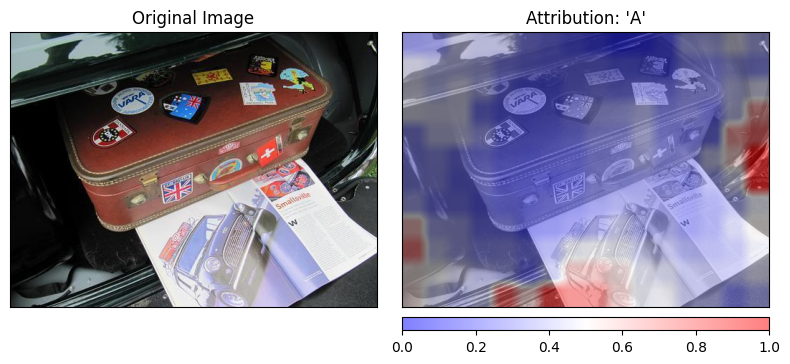

In [33]:
image_grid_thw = inputs.get("image_grid_thw", None)
viz.plot_image_attributions(img_attr=pixel_attribution,
                            original_image=img,
                            target_ids=target_ids.unsqueeze(0), 
                            image_grid_thw=image_grid_thw,
                            target_indices=target_indices
                            )

#### Generate plots

In [ ]:
import os, traceback
import torch
from PIL import Image
import gc
# Import your XAIVisualizer here
from src.utils.viz_utils import XAIVisualizer
from src.explainers.factory import get_explainer

def generate_qualitative_grid_on_the_fly(sample_idx, image,
                                        text, pred_results,
                                        model_wrapper, model_config,
                                        target_indices=0):
    model_name = model_config["name"]
    print(f"\n[==== Generating Heatmaps for Sample {sample_idx} | Model: {model_name} ====]")
    os.makedirs("figs", exist_ok=True)
    
    # ---------------------------------------------------------
    # STEP 1: Load your Model and Visualizer
    # ---------------------------------------------------------

    visualizer = XAIVisualizer(model_wrapper.processor)
    
    # Save the original image for the LaTeX grid
    original_image = image.convert("RGB")
    original_image.save(f"figs/qual_{sample_idx}_{model_name}_{dataset_name}_original.pdf", "PDF", resolution=300)

    # List the explainers exactly as your code expects them
    explainers = [
        "random",
        "llavacam", "rollout",
        "tam", "inputxgradients", "gradxrollout",
        "gradcam", "integratedgradients", "lxt", 
    ]
    
    for exp in explainers:
        print(f"  -> Computing {exp}...")
        
        try:
            # ---------------------------------------------------------
            # STEP 2: Compute the Attribution
            # ---------------------------------------------------------
            # TODO: Initialize your explainer wrapper
            explainer_path = f"../configs/explainers/{exp}.yaml"

            explainer, explainer_name = get_explainer(
                        explainer_path, model_wrapper, model_config
                    )
                        
            # (Make sure to pass the image, prompt, and whatever else your explainer needs)
            text_attr, img_attr = explainer.attribute(
                                            img,
                                            text=text,
                                            target_indices=target_indices,
                                            pred_results=pred_results,
                                            # keyword=keyword,
                                            # oracle_mask_2d=oracle_mask_2d,
                                            # mismatched_mask_2d=mismatched_mask_2d,

                                        )
            
            # ---------------------------------------------------------
            # STEP 3: Save the PDF using our modified Visualizer
            # ---------------------------------------------------------
            
            save_name = explainer_name.lower().replace(" ", "_")
            save_path = f"figs/qual_{sample_idx}_{model_name}_{dataset_name}_{save_name}"
            img_save_path = f"{save_path}_img.pdf"
            target_ids = pred_results["new_ids"].unsqueeze(0)
            
            # visualizer._plot_image_attributions(
            #     img_attr=img_attr.float(),
            #     original_image=original_image,
            #     target_ids=target_ids,
            #     explainer_name=explainer_name,
            #     save_path=img_save_path
            # )

            model_type = getattr(model_wrapper.model.config, "model_type", "").lower()
            semantic_mask = get_text_mask(inputs["input_ids"],
                                        model_type,
                                        model_wrapper.processor.tokenizer)
            
            # # 3. Save the Colored Text Highlights (Bottom)
            # txt_save_path = f"{save_path}_txt.pdf"
            # visualizer.save_text_highlight_pdf( # <--- Calling your new function here
            #     text_attr=text_attr,
            #     input_ids=inputs["input_ids"],
            #     save_path=txt_save_path,
            #     semantic_mask=semantic_mask,
            #     special_token_ids=model_wrapper.special_token_ids

            # )

            visualizer.save_combined_highlight_pdf(
                img_attr=img_attr,
                text_attr=text_attr,
                original_image=original_image,
                input_ids=inputs["input_ids"],       # Pass your tokenized inputs
                target_ids=target_ids,     # Pass your target tokens
                explainer_name=explainer_name,
                save_path=img_save_path,
                semantic_mask=semantic_mask,
                special_token_ids=model_wrapper.special_token_ids
            )

            
            # ---------------------------------------------------------
            # STEP 4: VRAM Management (CRITICAL)
            # ---------------------------------------------------------
            # Gradient-based explainers hold massive computation graphs in memory.
            # You MUST delete them and empty the cache before the next loop iteration.
            del explainer
            del img_attr
            gc.collect()
            torch.cuda.empty_cache()
            
        except Exception as e:
            print(f"[!] Failed to compute {exp} for sample {sample_idx}: {e}")
            traceback.print_exc()

    print(f"[+] All grid images generated successfully for Sample {sample_idx}!")



In [318]:
generate_qualitative_grid_on_the_fly(sample_idx=idx, image=img,
                                     text=text, pred_results=pred_results,
                                     model_wrapper=model_wrapper,
                                     model_config=model_config,
                                     target_indices=[decision_token])


[==== Generating Heatmaps for Sample 0 | Model: llava ====]
  -> Computing random...
  -> Computing llavacam...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/torch/nn/modules/module.py:1864: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)
/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/captum/attr/_utils/visualization.py:51: UserWarning: Attempting to normalize by value approximately 0, visualized resultsmay be misleading. This likely means that attribution values are allclose to 0.
  warnings.warn(


  -> Computing rollout...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/captum/attr/_utils/visualization.py:51: UserWarning: Attempting to normalize by value approximately 0, visualized resultsmay be misleading. This likely means that attribution values are allclose to 0.
  warnings.warn(


  -> Computing tam...
  -> Computing inputxgradients...


...

  -> Computing integratedgradients...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/torch/nn/modules/module.py:1864: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


  -> Computing lxt...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/torch/nn/modules/module.py:1864: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


[+] All grid images generated successfully for Sample 0!


### Qwen 3.5

In [17]:
import importlib
from collections.abc import Callable
from functools import partial
from types import ModuleType
from typing import Any

import torch
import torch.nn as nn
import transformers.models.qwen3_5.modeling_qwen3_5 as modeling_qwen3_5
from lxt.efficient.patches import (
    dropout_forward,
    gated_mlp_forward,
    layer_norm_forward,
    non_linear_forward,
    patch_attention,
    patch_method,
    rms_norm_forward,
)
from transformers.modeling_utils import ALL_ATTENTION_FUNCTIONS

from src.models.base import BaseVLMWrapper


class Qwen3_5Wrapper(BaseVLMWrapper):
    def __init__(self, model: nn.Module, processor: Any):
        super().__init__(model, processor)
        self._get_original_attention_forward()

    def embed_text(self, input_ids: torch.Tensor) -> torch.Tensor:
        return self.model.get_input_embeddings()(input_ids)

    def embed_images(
        self,
        pixel_values: torch.Tensor,
        **kwargs,
    ) -> torch.Tensor:
        image_grid_thw = kwargs.get("image_grid_thw")
        if image_grid_thw is None:
            raise ValueError("QwenVl needs image_grid_thw tensor")

        if pixel_values.dim() == 3:
            batch_size = pixel_values.shape[0]

            # 1. Flatten pixel_values back to 2D for Qwen
            # (Batch, Patches, Dim) -> (Batch*Patches, Dim)
            pixel_values = pixel_values.reshape(-1, pixel_values.shape[-1])

            # 2. Expand image_grid_thw to match the batch size
            # Current grid shape: (1, 3) -> We need (Batch_Size, 3)
            if image_grid_thw.shape[0] == 1 and batch_size > 1:
                image_grid_thw = image_grid_thw.repeat(batch_size, 1)

        image_embeds = self.model.get_image_features(pixel_values,
                                                     image_grid_thw=image_grid_thw).pooler_output
        return image_embeds

    def merge_embeddings(
        self,
        text_embeds: torch.Tensor,
        image_embeds: torch.Tensor,
        input_ids: torch.Tensor,
    ) -> torch.Tensor:

        # image_embeds = image_outputs.pooler_output
        image_embeds = torch.cat(image_embeds, dim=0).to(text_embeds.device, text_embeds.dtype)
        image_mask, _ = self.model.model.get_placeholder_mask(
            input_ids, inputs_embeds=text_embeds, image_features=image_embeds
        )
        inputs_embeds = text_embeds.masked_scatter(image_mask, image_embeds)

        # image_embeds = torch.cat(image_embeds, dim=0).to(text_embeds.device, text_embeds.dtype)
        # image_mask, _ = self.model.model.get_placeholder_mask(
        #     input_ids, inputs_embeds=text_embeds, image_features=image_embeds
        # )
        # inputs_embeds = text_embeds.masked_scatter(image_mask, image_embeds)
        return inputs_embeds

    def get_root_module(self) -> ModuleType:
        return importlib.import_module("transformers.models.qwen3_5.modeling_qwen3_5")

    def get_patch_map(self) -> dict[Any, Any]:
        from src.explainers.lxt_utils.patches import get_smart_attention_patch

        attnLRP = {
            nn.GELU: partial(patch_method, non_linear_forward, keep_original=True),
            # modeling_qwen3_5.Qwen3_5VisionMLP: partial(patch_method, gated_mlp_forward),
            modeling_qwen3_5.Qwen3_5MLP: partial(patch_method, gated_mlp_forward),
            # modeling_qwen3_5.Qwen3_5RMSNorm: partial(patch_method, rms_norm_forward),
            nn.LayerNorm: partial(patch_method, layer_norm_forward),
            # modeling_qwen3_5.Qwen3_5RMSNormGated: partial(patch_method, rms_norm_forward),
            nn.Dropout: partial(patch_method, dropout_forward),
            modeling_qwen3_5: get_smart_attention_patch(),
        }


        return attnLRP


    def get_inputs(self, image,
                   text: str,
                   safe_pixels: int = 313600,
                   is_mcvqa: bool = False) -> dict[str, Any]:
        
        # 1. Base user message structure
        user_content = [
            {"type": "image", "image": image},
        ]

        # 2. Check if we are running MCVQA
        if is_mcvqa:
            # Define the strict system instruction
            system_instruction = (
                "You are a precise multiple-choice question answering assistant. "
                "Analyze the image and question. Output ONLY the single letter corresponding "
                "to the correct answer (e.g., A, B, C, or D). Do NOT include any introduction, "
                "explanation, punctuation, or extra whitespace. Just output the letter."
            )
            
            # Append the "Answer:" trigger to the text
            forced_user_text = f"{text}\nAnswer:"
            user_content.append({"type": "text", "text": forced_user_text})
            
            # Build messages WITH the system role
            messages = [
                {"role": "system", "content": system_instruction},
                {"role": "user", "content": user_content}
            ]
            
        else:
            # Standard behavior: just use the raw text and no system prompt
            user_content.append({"type": "text", "text": text})
            
            # Build messages WITHOUT the system role
            messages = [
                {"role": "user", "content": user_content}
            ]

        # 3. Apply the chat template and process
        templated_text = self.processor.apply_chat_template(
            messages, 
            tokenize=False, 
            add_generation_prompt=True,
            enable_thinking=False
        )
        
        inputs = self.processor(
            text=[templated_text],
            images=[image],
            padding=True,
            max_pixels=safe_pixels,
            return_tensors="pt",
        )

        inputs = inputs.to(self.device)
        
        return inputs

    def get_tam_config(self, inputs: dict[str, Any]) -> dict[str, Any]:
        tok = self.processor.tokenizer

        # 1. Dynamically fetch the shifted special tokens
        # This automatically grabs 248053, 248054, etc., for Qwen 3.5
        vision_start = tok.convert_tokens_to_ids("<|vision_start|>")
        vision_end = tok.convert_tokens_to_ids("<|vision_end|>")
        im_start = tok.convert_tokens_to_ids("<|im_start|>")
        im_end = tok.convert_tokens_to_ids("<|im_end|>")

        # 2. Core text tokens (These remain unchanged in the BPE vocab)
        newline = 198       # \n
        assistant = 77091   # assistant

        special_ids = {
            # Image is strictly bounded by <|vision_start|> and <|vision_end|>
            "img_id": [vision_start, vision_end],
            
            # Prompt starts after the image and ends at the assistant header: 
            # <|im_end|>\n<|im_start|>assistant
            "prompt_id": [vision_end, [im_end, newline, im_start, assistant]],
            
            # Answer starts right after the newline following the assistant header
            "answer_id": [[newline, im_start, assistant, newline], -1],
        }

        # 3. Dynamically calculate the Vision Grid (DO NOT hardcode to 24x24)
        image_grid_thw = inputs.get("image_grid_thw")
        if image_grid_thw is None:
            raise ValueError("TAM requires image_grid_thw for Qwen models")

        # Qwen Vision Transformer applies a 2x2 spatial downsampling.
        vision_shape = (
            image_grid_thw[0, 1].item() // 2, 
            image_grid_thw[0, 2].item() // 2
        )

        return {
            "vision_shape": vision_shape,
            "special_ids": special_ids,
        }
    
    def get_captum_forward(
        self,
        text_embeds,
        pixel_values,
        kwargs_dict,
        return_full_sequence: bool = False,
    ):  # <--- This catches attention_mask, image_grid_thw, etc.

        local_kwargs = kwargs_dict.copy()

        if pixel_values is not None:
            image_embeds = self.embed_images(pixel_values, **local_kwargs)
        else:
            raise ValueError("Need pixel_values tensor")

        input_ids = local_kwargs.get("input_ids", None)
        if input_ids is None:
            raise ValueError("input_ids tensor is required")

        # text_embeds = self.embed_text(input_ids)
        inputs_embeds = self.merge_embeddings(text_embeds, image_embeds, input_ids)

        local_kwargs["input_ids"] = None

        return self.forward(
            inputs_embeds=inputs_embeds,
            return_probs=True,
            return_full_sequence=return_full_sequence,
            **local_kwargs,
        )

    def _get_original_attention_forward(self):
        self._vision_attention_forward = modeling_qwen3_5.Qwen3_5VisionAttention.forward
        self._text_attention_forward = None

    def apply_patch(self):
        modeling_qwen3_5.Qwen3_5VisionAttention.forward = patch_vision_forward

    def remove_patch(self):
        modeling_qwen3_5.Qwen3_5VisionAttention.forward = self._vision_attention_forward

    @property
    def vision_module_name(self) -> str:
        return "Qwen3_5VisionAttention"

    @property
    def llm_module_name(self) -> str:
        return "Qwen3_5Attention"

    @property
    def special_token_ids(self) -> list:
        tok = self.processor.tokenizer
        special_token_ids = [
            tok.convert_tokens_to_ids("<|image_pad|>"),
            tok.convert_tokens_to_ids("<|vision_start|>"),
            tok.convert_tokens_to_ids("<|vision_end|>"),
            tok.convert_tokens_to_ids("<|im_start|>"),
            tok.convert_tokens_to_ids("<|im_end|>"),
        ]
        return special_token_ids

def patch_vision_forward(
    self,
    hidden_states: torch.Tensor,
    cu_seqlens: torch.Tensor,
    rotary_pos_emb: torch.Tensor | None = None,
    position_embeddings: tuple[torch.Tensor, torch.Tensor] | None = None,
    **kwargs,
) -> torch.Tensor:
    seq_length = hidden_states.shape[0]
    query_states, key_states, value_states = (
        self.qkv(hidden_states).reshape(seq_length, 3, self.num_heads, -1).permute(1, 0, 2, 3).unbind(0)
    )
    cos, sin = position_embeddings
    
    # Updated to use modeling_qwen3_5
    query_states, key_states = modeling_qwen3_5.apply_rotary_pos_emb_vision(query_states, key_states, cos, sin)

    query_states = query_states.transpose(0, 1).unsqueeze(0)
    key_states = key_states.transpose(0, 1).unsqueeze(0)
    value_states = value_states.transpose(0, 1).unsqueeze(0)

    # Use get_interface as defined in the newer Transformers library
    attention_interface: Callable = ALL_ATTENTION_FUNCTIONS.get_interface(
        self.config._attn_implementation, modeling_qwen3_5.eager_attention_forward
    )

    if self.config._attn_implementation == "flash_attention_2":
        # Flash Attention: Use cu_seqlens for variable length attention
        max_seqlen = (cu_seqlens[1:] - cu_seqlens[:-1]).max()
        attn_output, attn_weights = attention_interface(
            self,
            query_states,
            key_states,
            value_states,
            attention_mask=None,
            scaling=self.scaling,
            dropout=0.0 if not self.training else self.attention_dropout,
            cu_seq_lens_q=cu_seqlens,
            cu_seq_lens_k=cu_seqlens,
            max_length_q=max_seqlen,
            max_length_k=max_seqlen,
            is_causal=False,
            output_attentions=True,  # Ensure attention weights are returned
            **kwargs,
        )
    else:
        # Other implementations: Process each chunk separately
        lengths = cu_seqlens[1:] - cu_seqlens[:-1]
        splits = [
            torch.split(tensor, lengths.tolist(), dim=2) for tensor in (query_states, key_states, value_states)
        ]

        attn_outputs, attn_weights = map(
            list,
            zip(
                *(
                    attention_interface(
                        self,
                        q,
                        k,
                        v,
                        attention_mask=None,
                        scaling=self.scaling,
                        dropout=0.0 if not self.training else self.attention_dropout,
                        is_causal=False,
                        # output_attentions=True,  # Ensure attention weights are returned
                        **kwargs,
                    )
                    for q, k, v in zip(*splits, strict=False)
                ),
                strict=False,
            ),
        )
        attn_output = torch.cat(attn_outputs, dim=1)

    # Save the visual attention weights
    self.saved_attn_weights = attn_weights

    attn_output = attn_output.reshape(seq_length, -1).contiguous()
    attn_output = self.proj(attn_output)
    return attn_output



In [9]:
from transformers import Qwen3_5ForConditionalGeneration
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3_5ForConditionalGeneration


def load_model(model_id="Qwen/Qwen3.5-2B", attn_implementation=None, gpu_node=0):
    if "FP8" in model_id:
        bnb_config = None
    else:
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_compute_dtype=torch.bfloat16,
        )
    processor = AutoProcessor.from_pretrained(model_id)
    model = Qwen3_5ForConditionalGeneration.from_pretrained(
        model_id,
        quantization_config=bnb_config,
        dtype=torch.bfloat16,
        device_map=f"cuda:{gpu_node}",
        attn_implementation=attn_implementation,
    )
    return model, processor

In [10]:
gpu_node = 0
model_id = "Qwen/Qwen3.5-27B"
model, processor = load_model(model_id=model_id,
                            attn_implementation="eager",
                            gpu_node=gpu_node)

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

In [16]:
model.config

Qwen3_5Config {
  "architectures": [
    "Qwen3_5ForConditionalGeneration"
  ],
  "dtype": "bfloat16",
  "image_token_id": 248056,
  "model_type": "qwen3_5",
  "quantization_config": {
    "_load_in_4bit": true,
    "_load_in_8bit": false,
    "bnb_4bit_compute_dtype": "bfloat16",
    "bnb_4bit_quant_storage": "uint8",
    "bnb_4bit_quant_type": "fp4",
    "bnb_4bit_use_double_quant": false,
    "llm_int8_enable_fp32_cpu_offload": false,
    "llm_int8_has_fp16_weight": false,
    "llm_int8_skip_modules": null,
    "llm_int8_threshold": 6.0,
    "load_in_4bit": true,
    "load_in_8bit": false,
    "quant_method": "bitsandbytes"
  },
  "text_config": {
    "attention_bias": false,
    "attention_dropout": 0.0,
    "attn_output_gate": true,
    "bos_token_id": null,
    "dtype": "bfloat16",
    "eos_token_id": 248044,
    "full_attention_interval": 4,
    "head_dim": 256,
    "hidden_act": "silu",
    "hidden_size": 5120,
    "initializer_range": 0.02,
    "intermediate_size": 17408,
    

In [18]:
# from src.models import Qwen3_5Wrapper

model_wrapper = Qwen3_5Wrapper(model, processor)

In [24]:
sample

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=512x384>,
 'question': 'Which option describe the object relationship in the image correctly?\nOptions: A: The suitcase is on the book., B: The suitcase is beneath the cat., C: The suitcase is beneath the bed., D: The suitcase is beneath the book.',
 'label': 'A',
 'index': 0,
 'metadata': {'source': 'MMBench',
  'split': 'val',
  'image_path': 'images/0.jpg'},
 'category': 'coarse perception'}

In [21]:
inputs = model_wrapper.get_inputs(img, question, is_mcvqa=True)
pred_results = model_wrapper.predict(inputs, return_logits=True)

In [22]:
pred_results["text"]

'A'

In [13]:
from src.explainers.factory import get_explainer

model_config = {
    "name": "qwenvl",
    "vlm_type": "qwen3_5",
    "model_id": "Qwen/Qwen3.5-2B",
    "trust_remote_code": False,
    "cam_target_layer": "layers.7.post_attention_layernorm"
}

model_wrapper.model_config = {
    "model_config": model_config,
    "attn_implementation": None, #"eager",
    "gpu_node": gpu_node,
    "output_attentions": False
}



In [23]:
processor.batch_decode(inputs["input_ids"])

['<|im_start|>system\nYou are a precise multiple-choice question answering assistant. Analyze the image and question. Output ONLY the single letter corresponding to the correct answer (e.g., A, B, C, or D). Do NOT include any introduction, explanation, punctuation, or extra whitespace. Just output the letter.<|im_end|>\n<|im_start|>user\n<|vision_start|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image

In [59]:
exp = "lxt"
explainer_path = f"../configs/explainers/{exp}.yaml"

explainer, explainer_name = get_explainer(
            explainer_path, model_wrapper, model_config
        )

[*] Applying LXT Monkey Patches to <module 'transformers.models.qwen3_5.modeling_qwen3_5' from '/home/jky/xai-vlms-benchmark/.venv/lib/python3.12/site-packages/transformers/models/qwen3_5/modeling_qwen3_5.py'>...
Patched GELU
Patched Qwen3_5MLP
Patched LayerNorm
Patched Dropout
Patched transformers.models.qwen3_5.modeling_qwen3_5
[*] Reloading patched model: Qwen/Qwen3.5-27B
[*] Loading model architecture: Qwen/Qwen3.5-2B on GPU 2...


Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

[!] Exiting Patch Context.
[!] WARNING: Python classes are still modified in memory.
[!] It is highly recommended to restart the kernel/process before running a different XAI method.


In [61]:
# target_indices = None
target_indices = [0]

text_attrs, img_attrs = explainer.attribute(
    img,
    text=text,
    target_indices=target_indices,
    pred_results=pred_results,
    keyword=keyword,
    oracle_mask_2d=oracle_mask_2d,
    mismatched_mask_2d=mismatched_mask_2d,

)

In [ ]:
print(text_attrs.shape)
print(img_attrs.shape)

torch.Size([1, 129])
torch.Size([1, 256])


: 

In [56]:
img_attrs

tensor([[0.0049, 0.0047, 0.0006, 0.0006, 0.0009, 0.0009, 0.0008, 0.0007, 0.0008,
         0.0006, 0.0006, 0.0006, 0.0004, 0.0004, 0.0009, 0.0009, 0.0047, 0.0046,
         0.0006, 0.0006, 0.0009, 0.0009, 0.0007, 0.0007, 0.0006, 0.0008, 0.0006,
         0.0006, 0.0004, 0.0004, 0.0009, 0.0009, 0.0010, 0.0010, 0.0005, 0.0005,
         0.0015, 0.0015, 0.0005, 0.0005, 0.0004, 0.0004, 0.0004, 0.0004, 0.0006,
         0.0006, 0.0010, 0.0010, 0.0010, 0.0010, 0.0005, 0.0005, 0.0015, 0.0015,
         0.0005, 0.0005, 0.0004, 0.0004, 0.0004, 0.0004, 0.0006, 0.0007, 0.0010,
         0.0011, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005,
         0.0003, 0.0004, 0.0004, 0.0004, 0.0006, 0.0006, 0.0003, 0.0003, 0.0005,
         0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0003, 0.0003,
         0.0004, 0.0005, 0.0006, 0.0006, 0.0003, 0.0003, 0.0004, 0.0004, 0.0002,
         0.0002, 0.0007, 0.0007, 0.0002, 0.0002, 0.0007, 0.0007, 0.0011, 0.0011,
         0.0004, 0.0004, 0.0

In [57]:
text_attrs

tensor([[6.7742e-02, 1.1051e-02, 2.4777e-02, 6.6049e-02, 4.5948e-03, 5.6134e-04,
         8.2124e-04, 6.6681e-04, 5.3658e-04, 5.4217e-04, 3.6010e-04, 8.8817e-04,
         9.2198e-04, 4.2651e-04, 1.4219e-03, 4.6050e-04, 4.1523e-04, 4.1233e-04,
         5.8419e-04, 9.5172e-04, 4.6032e-04, 4.6374e-04, 5.0155e-04, 5.0695e-04,
         3.2210e-04, 3.6848e-04, 5.9221e-04, 2.9290e-04, 3.4191e-04, 2.1152e-04,
         6.8879e-04, 2.0341e-04, 6.7640e-04, 1.0593e-03, 4.0151e-04, 2.9493e-04,
         1.2511e-03, 5.7917e-04, 2.8683e-04, 1.1763e-03, 3.3065e-04, 6.7839e-04,
         7.5446e-04, 5.3135e-04, 7.2390e-04, 3.9237e-04, 5.4292e-04, 4.6409e-04,
         2.9924e-04, 6.0741e-04, 2.4542e-04, 2.4712e-04, 5.0748e-04, 4.1290e-04,
         5.6209e-04, 5.9388e-04, 2.1888e-04, 2.4562e-04, 2.4183e-04, 3.0924e-04,
         7.6733e-04, 4.0427e-04, 5.1622e-04, 3.2459e-04, 3.5692e-04, 5.6042e-04,
         5.0384e-04, 1.2282e-03, 1.7126e-02, 1.6157e-02, 1.2382e-02, 4.7673e-03,
         4.6654e-03, 4.0409e

In [47]:
torch.cuda.empty_cache()

### FIxLIP

In [20]:
import copy
import warnings

import numpy as np
from scipy.special import binom

from shapiq.utils.sets import powerset


class CoalitionSampler:
    def __init__(
        self,
        n_players: int,
        sampling_weights: np.ndarray,
        pairing_trick: bool = False,
        enforce_empty_full: bool = False,
        random_state: int | None = None,
    ) -> None:
        self.pairing_trick: bool = pairing_trick

        # set enforce_empty_full
        self.enforce_empty_full = enforce_empty_full
        # set sampling weights
        if not (sampling_weights >= 0).all():  # Check non-negativity of sampling weights
            raise ValueError("All sampling weights must be non-negative")
        self._sampling_weights = sampling_weights / np.sum(sampling_weights)  # make probabilities

        # raise warning if sampling weights are not symmetric but pairing trick is activated
        if self.pairing_trick and not np.allclose(
            self._sampling_weights, self._sampling_weights[::-1]
        ):
            warnings.warn(
                UserWarning(
                    "Pairing trick is activated, but sampling weights are not symmetric. "
                    "This may lead to unexpected results."
                ),
                stacklevel=2,
            )

        # set player numbers
        if n_players + 1 != np.size(sampling_weights):  # shape of sampling weights -> sizes 0,...,n
            raise ValueError(
                f"{n_players} elements must correspond to {n_players + 1} coalition sizes "
                "(including empty subsets)"
            )
        self.n: int = n_players
        self.n_max_coalitions = int(2**self.n)
        self.n_max_coalitions_per_size = np.array([binom(self.n, k) for k in range(self.n + 1)])

        # set random state
        self._rng: np.random.Generator = np.random.default_rng(seed=random_state)

        # set variables for sampling and exclude coalition sizes with zero weight
        self._coalitions_to_exclude: list[int] = []
        for size, weight in enumerate(self._sampling_weights):
            if weight == 0 and 0 < size < self.n:
                self.n_max_coalitions -= int(binom(self.n, size))
                self._coalitions_to_exclude.extend([size])
        self.adjusted_sampling_weights: np.ndarray[float] | None = None

        # set sample size variables (for border trick)
        self._coalitions_to_compute: list[int] | None = None  # coalitions to compute
        self._coalitions_to_sample: list[int] | None = None  # coalitions to sample

        # initialize variables to be computed and stored
        self.sampled_coalitions_dict: dict[tuple[int, ...], int] | None = None  # coal -> count
        self.coalitions_per_size: np.ndarray[int] | None = None  # number of coalitions per size

        # variables accessible through properties
        self._sampled_coalitions_matrix: np.ndarray[bool] | None = None  # coalitions
        self._sampled_coalitions_counter: np.ndarray[int] | None = None  # coalitions_counter
        self._is_coalition_size_sampled: np.ndarray[bool] | None = None  # is_coalition_size_sampled


    @property
    def is_coalition_size_sampled(self) -> np.ndarray:
        return copy.deepcopy(self._is_coalition_size_sampled)


    @property
    def is_coalition_sampled(self) -> np.ndarray:
        coalitions_size = np.sum(self.coalitions_matrix, axis=1)
        return self._is_coalition_size_sampled[coalitions_size]


    @property
    def sampling_adjustment_weights(self) -> np.ndarray:
        coalitions_counter = self.coalitions_counter
        is_coalition_sampled = self.is_coalition_sampled
        # Number of coalitions sampled

        n_total_samples = np.sum(coalitions_counter[is_coalition_sampled])
        # Helper array for computed and sampled coalitions
        total_samples_values = np.array([1, n_total_samples])
        # Create array per coalition and the total samples values, or 1, if computed
        n_coalitions_total_samples = total_samples_values[is_coalition_sampled.astype(int)]
        # Create array with the adjusted weights
        sampling_adjustment_weights = self.coalitions_counter / (
            self.coalitions_probability * n_coalitions_total_samples
        )

        return sampling_adjustment_weights

    @property
    def empirical_occurrences(self) -> np.ndarray:
        coalitions_counter = self.coalitions_counter
        is_coalition_sampled = self.is_coalition_sampled
        # Number of coalitions sampled

        n_total_samples = np.sum(coalitions_counter[is_coalition_sampled])
        # Helper array for computed and sampled coalitions
        total_samples_values = np.array([1, n_total_samples])
        # Create array per coalition and the total samples values, or 1, if computed
        n_coalitions_total_samples = total_samples_values[is_coalition_sampled.astype(int)]
        # Create array with the adjusted weights
        empirical_occurrences = self.coalitions_counter / n_coalitions_total_samples
        return empirical_occurrences


    @property
    def coalitions_matrix(self) -> np.ndarray:
        return copy.deepcopy(self._sampled_coalitions_matrix)


    @property
    def sampling_size_probabilities(self) -> np.ndarray:
        size_probs = np.zeros(self.n + 1)
        size_probs[self._coalitions_to_sample] = self.adjusted_sampling_weights / np.sum(
            self.adjusted_sampling_weights
        )
        return size_probs


    @property
    def coalitions_counter(self) -> np.ndarray:
        return copy.deepcopy(self._sampled_coalitions_counter)


    @property
    def coalitions_probability(self) -> np.ndarray:
        if (
            self._sampled_coalitions_size_prob is not None
            and self._sampled_coalitions_in_size_prob is not None
        ):
            return self._sampled_coalitions_size_prob * self._sampled_coalitions_in_size_prob


    @property
    def coalitions_size(self) -> np.ndarray:
        return np.sum(self.coalitions_matrix, axis=1)


    @property
    def empirical_occurrences(self) -> np.ndarray:
        # Number of coalitions sampled
        n_total_samples = np.sum(self.coalitions_counter[self.is_coalition_sampled])
        # Helper array for computed and sampled coalitions
        total_samples_values = np.array([1, n_total_samples])
        # Create array per coalition and the total samples values, or 1, if computed
        n_coalitions_total_samples = total_samples_values[self.is_coalition_sampled.astype(int)]
        # Create array with the adjusted weights
        empirical_occurrences = self.coalitions_counter / n_coalitions_total_samples
        return copy.deepcopy(empirical_occurrences)


    def execute_border_trick(self, sampling_budget: int) -> int:
        coalitions_per_size = np.array([binom(self.n, k) for k in range(self.n + 1)])
        expected_number_of_coalitions = sampling_budget * self.adjusted_sampling_weights
        sampling_exceeds_expectation = (
            expected_number_of_coalitions >= coalitions_per_size[self._coalitions_to_sample]
        )
        while sampling_exceeds_expectation.any():
            coalitions_to_move = [
                self._coalitions_to_sample[index]
                for index, include in enumerate(sampling_exceeds_expectation)
                if include
            ]
            self._coalitions_to_compute.extend(
                [
                    self._coalitions_to_sample.pop(self._coalitions_to_sample.index(move_this))
                    for move_this in coalitions_to_move
                ]
            )
            sampling_budget -= int(np.sum(coalitions_per_size[coalitions_to_move]))
            self.adjusted_sampling_weights = self.adjusted_sampling_weights[
                ~sampling_exceeds_expectation
            ] / np.sum(self.adjusted_sampling_weights[~sampling_exceeds_expectation])
            expected_number_of_coalitions = sampling_budget * self.adjusted_sampling_weights
            sampling_exceeds_expectation = (
                expected_number_of_coalitions >= coalitions_per_size[self._coalitions_to_sample]
            )
        return sampling_budget


    def execute_pairing_trick(self, sampling_budget: int, coalition_tuple: tuple[int, ...]) -> int:
        coalition_size = len(coalition_tuple)
        paired_coalition_size = self.n - coalition_size
        if paired_coalition_size in self._coalitions_to_sample:
            paired_coalition_indices = list(set(range(self.n)) - set(coalition_tuple))
            paired_coalition_tuple = tuple(sorted(paired_coalition_indices))
            self.coalitions_per_size[paired_coalition_size] += 1
            # adjust coalitions counter using the paired coalition
            try:  # if coalition is not new
                self.sampled_coalitions_dict[paired_coalition_tuple] += 1
            except KeyError:  # if coalition is new
                self.sampled_coalitions_dict[paired_coalition_tuple] = 1
                sampling_budget -= 1
        return sampling_budget


    def _reset_variables(self, sampling_budget: int) -> None:
        self.sampled_coalitions_dict = {}
        self.coalitions_per_size = np.zeros(self.n + 1, dtype=int)
        self._is_coalition_size_sampled = np.zeros(self.n + 1, dtype=bool)
        self._sampled_coalitions_counter = np.zeros(sampling_budget, dtype=int)
        self._sampled_coalitions_matrix = np.zeros((sampling_budget, self.n), dtype=bool)
        self._sampled_coalitions_size_prob = np.zeros(sampling_budget, dtype=float)
        self._sampled_coalitions_in_size_prob = np.zeros(sampling_budget, dtype=float)

        self._coalitions_to_compute = []
        self._coalitions_to_sample = [
            coalition_size
            for coalition_size in range(self.n + 1)
            if coalition_size not in self._coalitions_to_exclude
        ]
        self.adjusted_sampling_weights = copy.deepcopy(
            self._sampling_weights[self._coalitions_to_sample]
        )
        self.adjusted_sampling_weights /= np.sum(self.adjusted_sampling_weights)  # probability


    def execute_empty_grand_coalition(self, sampling_budget):
        empty_grand_coalition_indicator = np.zeros_like(self.adjusted_sampling_weights, dtype=bool)
        empty_grand_coalition_size = [0, self.n]
        empty_grand_coalition_index = [
            self._coalitions_to_sample.index(size) for size in empty_grand_coalition_size
        ]
        empty_grand_coalition_indicator[empty_grand_coalition_index] = True
        coalitions_to_move = [
            self._coalitions_to_sample[index]
            for index, include in enumerate(empty_grand_coalition_indicator)
            if include
        ]
        self._coalitions_to_compute.extend(
            [
                self._coalitions_to_sample.pop(self._coalitions_to_sample.index(move_this))
                for move_this in coalitions_to_move
            ]
        )
        self.adjusted_sampling_weights = self.adjusted_sampling_weights[
            ~empty_grand_coalition_indicator
        ] / np.sum(self.adjusted_sampling_weights[~empty_grand_coalition_indicator])
        sampling_budget -= 2
        return sampling_budget


    def sample(self, sampling_budget: int) -> None:
        if sampling_budget > self.n_max_coalitions:
            warnings.warn("Not all budget is required due to the border-trick.", stacklevel=2)
            sampling_budget = min(sampling_budget, self.n_max_coalitions)  # set budget to max coals

        self._reset_variables(sampling_budget)

        if self.enforce_empty_full:
            # Prioritize empty and grand coalition
            sampling_budget = self.execute_empty_grand_coalition(sampling_budget)

        # Border-Trick: enumerate all coalitions, where the expected number of coalitions exceeds
        # the total number of coalitions of that size (i.e. binom(n_players, coalition_size))
        sampling_budget = self.execute_border_trick(sampling_budget)

        # Sort by size for esthetics
        self._coalitions_to_compute.sort(key=self._sort_coalitions)

        # raise warning if budget is higher than 90% of samples remaining to be sampled
        n_samples_remaining = np.sum([binom(self.n, size) for size in self._coalitions_to_sample])
        if sampling_budget > 0.9 * n_samples_remaining:
            warnings.warn(
                UserWarning(
                    "Sampling might be inefficient (stalls) due to the sampling budget being close "
                    "to the total number of coalitions to be sampled."
                ),
                stacklevel=2,
            )

        # sample coalitions
        if len(self._coalitions_to_sample) > 0:
            iteration_counter = 0  # stores the number of samples drawn (duplicates included)
            while sampling_budget > 0:
                iteration_counter += 1

                # draw coalition
                coalition_size = self._rng.choice(
                    self._coalitions_to_sample, size=1, p=self.adjusted_sampling_weights
                )[0]
                ids = self._rng.choice(self.n, size=coalition_size, replace=False)
                coalition_tuple = tuple(sorted(ids))  # get coalition
                self.coalitions_per_size[coalition_size] += 1

                # add coalition
                try:  # if coalition is not new
                    self.sampled_coalitions_dict[coalition_tuple] += 1
                except KeyError:  # if coalition is new
                    self.sampled_coalitions_dict[coalition_tuple] = 1
                    sampling_budget -= 1

                # execute pairing-trick by including the complement
                if self.pairing_trick and sampling_budget > 0:
                    sampling_budget = self.execute_pairing_trick(sampling_budget, coalition_tuple)

        # convert coalition counts to the output format
        coalition_index = 0
        # add all coalitions that are computed exhaustively
        for coalition_size in self._coalitions_to_compute:
            self.coalitions_per_size[coalition_size] = int(binom(self.n, coalition_size))
            for coalition in powerset(
                range(self.n), min_size=coalition_size, max_size=coalition_size
            ):
                self._sampled_coalitions_matrix[coalition_index, list(coalition)] = 1
                self._sampled_coalitions_counter[coalition_index] = 1
                self._sampled_coalitions_size_prob[coalition_index] = 1  # weight is set to 1
                self._sampled_coalitions_in_size_prob[coalition_index] = 1  # weight is set to 1
                coalition_index += 1
        # add all coalitions that are sampled
        for coalition_tuple, count in self.sampled_coalitions_dict.items():
            self._sampled_coalitions_matrix[coalition_index, list(coalition_tuple)] = 1
            self._sampled_coalitions_counter[coalition_index] = count
            # probability of the sampled coalition, i.e. sampling weight (for size) divided by
            # number of coalitions of that size
            self._sampled_coalitions_size_prob[coalition_index] = self.adjusted_sampling_weights[
                self._coalitions_to_sample.index(len(coalition_tuple))
            ]
            self._sampled_coalitions_in_size_prob[coalition_index] = (
                1 / self.n_max_coalitions_per_size[len(coalition_tuple)]
            )
            coalition_index += 1

        # set the flag to indicate that these sizes are sampled
        for coalition_size in self._coalitions_to_sample:
            self._is_coalition_size_sampled[coalition_size] = True


    def _sort_coalitions(self, value):
        # Sort by distance to center
        return -abs(self.n / 2 - value)


In [21]:
import time
from typing import Dict, Any, List, Tuple, Optional

import shapiq
import numpy as np
import scipy as sp


class FIxLIP:
    """
    Approximates interaction values using the weighted Banzhaf power index (or Shapley).
    """
    def __init__(
            self, 
            n_players: Optional[int]=None, 
            n_players_image: Optional[int]=None,
            n_players_text: Optional[int]=None,
            mode: str ="banzhaf",
            p: float=0.5, 
            max_order: int=2, 
            random_state=None,
            sparse_regression=False
        ):
        self.mode = mode
        self.sparse_regression = sparse_regression
        self.is_crossmodal = False

        if n_players_image and n_players_text:
            if mode.lower() == "shapley":
                raise ValueError("approximate_crossmodal() is not available for mode 'Shapley'")
            self.is_crossmodal = True
            n_players = n_players_image + n_players_text
            self.n_players_image = n_players_image
            self.n_players_text = n_players_text

        if mode.lower() == "banzhaf":
            # Sample using uniform weights
            sampling_weights = np.array([
                    sp.special.binom(n_players, k) * (p ** k) * ((1 - p) ** (n_players - k))\
                          for k in range(n_players + 1)
                ])
            enforce_empty_full = False
        elif mode.lower() == "shapley":
            sampling_weights = np.zeros(n_players + 1)
            # KernelSHAP sampling weights
            for coalition_size in range(1, n_players):
                sampling_weights[coalition_size] = 1 / (coalition_size * (n_players - coalition_size))
            enforce_empty_full = True
        else:
            raise ValueError("`mode` should be either 'Banzhaf' or 'Shapley'.")
        
        if n_players_image and n_players_text:
            self.sampler_image = CoalitionSampler(
                n_players=n_players_image, 
                sampling_weights=np.array([
                    sp.special.binom(n_players_image, k) * (p ** k) * ((1 - p) ** (n_players_image - k))\
                          for k in range(n_players_image + 1)
                ]), 
                enforce_empty_full=enforce_empty_full,
                pairing_trick=False, 
                random_state=random_state
            )
            self.sampler_text = CoalitionSampler(
                n_players=n_players_text, 
                sampling_weights=np.array([
                    sp.special.binom(n_players_text, k) * (p ** k) * ((1 - p) ** (n_players_text - k))\
                          for k in range(n_players_text + 1)
                ]), 
                enforce_empty_full=enforce_empty_full,
                pairing_trick=False, 
                random_state=random_state
            )
        elif n_players is None:
            raise ValueError("Pass either `n_players` for basic usage or "+\
                             "pass `n_players_image` and `n_players_text` for crossmodal usage.")
        
        self.n_players = n_players
        self.p = p
        self.max_order = max_order
        self.random_state = random_state
        self.sampler = CoalitionSampler(
            n_players=n_players,
            sampling_weights=sampling_weights,
            enforce_empty_full=enforce_empty_full,
            pairing_trick=False, 
            random_state=random_state
        )


    def approximate(
            self, 
            game, 
            budget, 
            interaction_lookup=None, 
            time_game=False, 
            approximation_type="original",
            **kwargs
        ):
        if interaction_lookup is not None and approximation_type != "original":
            raise ValueError("`interaction_lookup` is only used for `approximation_type='original'`.")
        # sample coalitions
        self.sampler.sample(budget)
        # evaluate coalition values (un-normalized game call)
        if time_game:
            self.time_game_start = time.time()
        coalition_values = game.value_function(self.sampler.coalitions_matrix)
        if time_game:
            self.time_game_end = time.time()
        coalition_values = coalition_values - game.normalization_value

        if approximation_type == "original":
            if self.mode.lower() == "banzhaf":
                # set kernel weights for weighted banzhaf
                kernel_weights = np.array([self.p ** k * ((1 - self.p) ** (self.n_players - k))\
                                            for k in range(self.n_players + 1)])
            elif self.mode.lower() == "shapley":
                kernel_weights = np.zeros(self.n_players + 1)
                normalization_constant = 0
                for coalition_size in range(1, self.n_players):
                    kernel_weights[coalition_size] = 1 / sp.special.binom(self.n_players - 2, coalition_size - 1)
                    normalization_constant += kernel_weights[coalition_size] * sp.special.binom(self.n_players, coalition_size)
                # Normalize kernel weights to probability distribution
                kernel_weights /= normalization_constant
                big_M = 10e6
                kernel_weights[0] = big_M
                kernel_weights[-1] = big_M
            regression_weights = get_regression_weights(self.sampler, kernel_weights)
            # aggregate coalition values
            interaction_values = self.aggregate(
                coalition_matrix=self.sampler.coalitions_matrix, 
                regression_weights=regression_weights,
                coalition_values=coalition_values,
                interaction_lookup=interaction_lookup
            )
        elif approximation_type == "proxyshap":
            # cf. https://github.com/mmschlk/shapiq/blob/ec73ba9746c367f4407603d32a4d587c7e4548f5/src/shapiq/approximator/proxy/proxyshap.py#L239-L285
            from shapiq.tree.interventional.explainer import InterventionalTreeExplainer
            from xgboost import XGBRegressor
            defaults = {
                "n_estimators": 2000,
                "learning_rate": 0.05,
                "max_depth": 3,
                "reg_lambda": 5,
                "random_state": self.random_state
            }
            defaults.update(kwargs)
            proxy_model = XGBRegressor(**defaults)
            proxy_model.fit(self.sampler.coalitions_matrix, coalition_values)
            explainer = InterventionalTreeExplainer(
                proxy_model,
                data=np.zeros((1, self.n_players)),  # reference data for boolean tree
                class_index=None,
                index="FBII" if self.mode.lower() == "banzhaf" else "FSII",
                max_order=self.max_order,
                bool_tree=True,
            )
            values = explainer.explain_function(np.ones((1, self.n_players)))
            interaction_values = shapiq.InteractionValues(
                values=values.interactions,
                index="FBII" if self.mode.lower() == "banzhaf" else "FSII",
                max_order=self.max_order,
                n_players=self.n_players,
                min_order=0,
                estimated=2 ** self.n_players > budget,
                estimation_budget=budget,
                baseline_value=float(game.normalization_value),
            )
            interaction_values[()] = float(game.normalization_value)  # Ensure empty coalition value is correct
            # Ensure that all values are present and pad with zeros if necessary.
            interaction_values = populate_sparse_iv_with_zeros(interaction_values)

        return interaction_values


    def approximate_crossmodal(
        self, 
        game, 
        budget=None, 
        budget_image=None, 
        budget_text=None, 
        interaction_lookup=None, 
        time_game=False, 
        approximation_type="original",
        **kwargs
    ):
        if not self.is_crossmodal:
            raise ValueError("Crossmodal approximation is not initialized."+\
                             "Pass `n_players_image` and `n_players_text` to FIxLIP().")
        if interaction_lookup is not None and approximation_type != "original":
            raise ValueError("`interaction_lookup` is only used for `approximation_type='original'`.")
        # split budget based on n_players_text and n_players_image
        if budget is not None:
            if budget < 4:
                raise ValueError("`budget` should be at least 4.")
            budget_image, budget_text = self.split_budget(budget)
        elif budget_image is None or budget_text is None:
            raise ValueError("Pass either `budget` or `budget_image` and `budget_text`.")
        else:
            budget = budget_image * budget_text
        # sample coalitions from both modalities
        self.sampler_image.sample(budget_image)
        self.sampler_text.sample(budget_text)
        # evaluate coalition values efficiently with _crossmodal (un-normalized game call)
        if time_game:
            self.time_game_start = time.time()
        coalition_values_crossmodal = game.value_function_crossmodal(
            coalitions_image=self.sampler_image.coalitions_matrix,
            coalitions_text=self.sampler_text.coalitions_matrix
        )
        if time_game:
            self.time_game_end = time.time()
        coalition_values_crossmodal = coalition_values_crossmodal - game.normalization_value
        # reshape inputs to aggregate()
        coalition_values = coalition_values_crossmodal.reshape(-1)
        coalitions_matrix = np.concatenate([
            np.repeat(self.sampler_image.coalitions_matrix, budget_text, axis=0), 
            np.tile(self.sampler_text.coalitions_matrix, (budget_image, 1))
        ], axis=1)
        if approximation_type == "original":
            # set kernel weights for image and text using banzhaf
            kernel_weights_image = np.array([self.p ** k * ((1 - self.p) ** (self.n_players_image - k)) \
                                                for k in range(self.n_players_image + 1)])
            kernel_weights_text = np.array([self.p ** k * ((1 - self.p) ** (self.n_players_text - k)) \
                                                for k in range(self.n_players_text + 1)])
            image_regression_weights = get_regression_weights(self.sampler_image, kernel_weights_image)
            text_regression_weights = get_regression_weights(self.sampler_text, kernel_weights_text)
            regression_weights = np.outer(
                image_regression_weights,
                text_regression_weights
            ).reshape(-1)
            # aggregate coalition values with aggregate()
            interaction_values = self.aggregate(
                coalition_matrix=coalitions_matrix, 
                regression_weights=regression_weights,
                coalition_values=coalition_values,
                interaction_lookup=interaction_lookup
            )
        elif approximation_type == "proxyshap":
            # cf. https://github.com/mmschlk/shapiq/blob/ec73ba9746c367f4407603d32a4d587c7e4548f5/src/shapiq/approximator/proxy/proxyshap.py#L239-L285
            from shapiq.tree.interventional.explainer import InterventionalTreeExplainer
            from xgboost import XGBRegressor
            defaults = {
                "n_estimators": 2000,
                "learning_rate": 0.05,
                "max_depth": 3,
                "reg_lambda": 5,
                "random_state": self.random_state
            }
            defaults.update(kwargs)
            proxy_model = XGBRegressor(**defaults)
            proxy_model.fit(coalitions_matrix, coalition_values)
            explainer = InterventionalTreeExplainer(
                proxy_model,
                data=np.zeros((1, self.n_players)),  # reference data for boolean tree
                class_index=None,
                index="FBII" if self.mode.lower() == "banzhaf" else "FSII",
                max_order=self.max_order,
                bool_tree=True,
            )
            values = explainer.explain_function(np.ones((1, self.n_players)))
            interaction_values = shapiq.InteractionValues(
                values=values.interactions,
                index="FBII" if self.mode.lower() == "banzhaf" else "FSII",
                max_order=self.max_order,
                n_players=self.n_players,
                min_order=0,
                estimated=2**self.n_players > budget,
                estimation_budget=budget,
                baseline_value=float(game.normalization_value),
            )
            interaction_values[()] = float(game.normalization_value)  # Ensure empty coalition value is correct
            # Ensure that all values are present and pad with zeros if necessary.
            interaction_values = populate_sparse_iv_with_zeros(interaction_values)

        return interaction_values


    def aggregate(
        self,
        coalition_matrix,
        regression_weights,
        coalition_values,
        interaction_lookup: dict | None = None
    ) -> shapiq.InteractionValues:
        """Aggregates the coalition values using the weighted Banzhaf power index."""
        n_coalitions, n_players = np.shape(coalition_matrix)
        # populate interactions to use for regression
        if interaction_lookup is None:  # first check if interaction_lookup is passed
            interaction_lookup = shapiq.utils.generate_interaction_lookup(set(range(n_players)), min_order=0, max_order=self.max_order)
        n_interactions = len(interaction_lookup)
        # set response, subtract baseline for better approximation, it will be added later
        regression_response = coalition_values.copy()
        # create regression matrix
        regression_matrix = np.zeros((n_coalitions, n_interactions))
        for i, interaction in enumerate(interaction_lookup.keys()):
            regression_matrix[:, i] = coalition_matrix[:, interaction].prod(axis=1)
        # solve regression
        values = solve_regression(regression_matrix, regression_response, regression_weights, sparse_regression=self.sparse_regression)
        # return interaction values
        interaction_values = shapiq.InteractionValues(
            values=values,
            interaction_lookup=interaction_lookup,
            baseline_value=values[interaction_lookup[()]],
            n_players=n_players,
            index="Moebius",
            max_order=self.max_order,
            min_order=0,
            estimated=2 ** n_players > n_coalitions,
            estimation_budget=n_coalitions,
        )
        interaction_values.index = "FSII" if self.mode.lower() == "shapley" else "FWBII"
        return interaction_values
    

    #:# ---------- utility functions ---------- #:#

    def split_budget(self, budget):
        """
        Heuristic to choose a reasonable budget split.
        """
        if self.n_players_text < self.n_players_image:
            budget_text = np.sqrt(budget) * self.n_players_text / self.n_players_image
            budget_text = int(np.ceil(np.max([4, budget_text])))
            budget_text = int(np.min([2 ** self.n_players_text, budget_text]))
            budget_image = int(budget / budget_text)
        else:
            budget_image = np.sqrt(budget) * self.n_players_image / self.n_players_text
            budget_image = int(np.ceil(np.max([4, budget_image])))
            budget_image = int(np.min([2 ** self.n_players_image, budget_image]))
            budget_text = int(budget / budget_image)    
        return budget_image, budget_text


def solve_regression(X: np.ndarray, y: np.ndarray, kernel_weights: np.ndarray, sparse_regression=False) -> np.ndarray:
    if not sparse_regression:
        try:
            # try solving via solve function
            WX = kernel_weights[:, np.newaxis] * X
            phi = np.linalg.solve(X.T @ WX, WX.T @ y)
        except np.linalg.LinAlgError:
            # solve WLSQ via lstsq function and throw warning
            W_sqrt = np.sqrt(kernel_weights)
            X = W_sqrt[:, np.newaxis] * X
            y = W_sqrt * y
            phi = np.linalg.lstsq(X, y, rcond=None)[0]
    else:
        X_sparse = sp.sparse.csr_matrix(X)
        W_sparse = sp.sparse.diags(kernel_weights)
        WX_sparse = W_sparse @ X_sparse  # Pre-multiply: W * X and W * y
        Wy = kernel_weights * y
        result = sp.sparse.linalg.lsqr(WX_sparse, Wy)  # Solve sparse least squares
        phi = result[0]  # coefficients
        return phi
    return phi


def get_regression_weights(sampler, kernel_weights):
    """ Computes the regression weights, requires that sampling weights are proportional to kernel weights.
    Regression weights are equal to kernel weights for coalitions that are not sampled (using the border-trick).
    Otherwise, the regression weights are set to the empirical averages, i.e. # occurrences / # sampled coalitions.
    """
    regression_weights_not_sampled = kernel_weights[np.sum(sampler.coalitions_matrix, axis=1)]
    regression_weights = sampler.empirical_occurrences
    regression_weights[~sampler.is_coalition_sampled] = regression_weights[~sampler.is_coalition_sampled] * \
                                                        regression_weights_not_sampled[~sampler.is_coalition_sampled]
    return regression_weights


def populate_sparse_iv_with_zeros(iv):
    """Fills in the interaction values object with zeros for missing attributions."""
    new_values = []
    new_interaction_lookup = {}
    for index, interaction in enumerate(shapiq.utils.sets.powerset(range(iv.n_players), min_size=iv.min_order, max_size=iv.max_order)):
        new_interaction_lookup[interaction] = index
        if interaction in iv.interaction_lookup:
            new_values.append(iv[interaction])
        else:
            new_values.append(0.0)
    return shapiq.InteractionValues(
        values=np.array(new_values, dtype=float),
        index=iv.index,
        max_order=iv.max_order,
        n_players=iv.n_players,
        min_order=iv.min_order,
        interaction_lookup=new_interaction_lookup,
        estimated=iv.estimated,
        estimation_budget=iv.estimation_budget,
        baseline_value=iv.baseline_value
    )




In [22]:

import numpy as np
import torch
from typing import Optional

# Ensure these are correctly imported from your codebase!
from src.explainers import BaseExplainer
from src.models import BaseVLMWrapper
from src.utils.faithfulness_utils import pred_probs
# from src.fixlip import FIxLIP # The authors' class

class MockCrossModalGame:
    """
    A fake game that instantly hands FIxLIP our precomputed batched VLM scores.
    This completely bypasses FIxLIP's slow internal forward passes!
    """
    def __init__(self, precomputed_values_2d: np.ndarray, normalization_value: float):
        self.precomputed_values_2d = precomputed_values_2d
        self.normalization_value = normalization_value

    def value_function_crossmodal(self, coalitions_image, coalitions_text):
        # We completely ignore the inputs because we ALREADY evaluated these exact masks!
        return self.precomputed_values_2d


class FIxLIPExplainer(BaseExplainer):
    """
    Implements FIxLIP's Cross-Modal ProxySHAP (XGBoost) approximation.
    Uses Batched Teacher Forcing to evaluate all targets simultaneously.
    """
    def __init__(
        self, 
        model_wrapper: BaseVLMWrapper, 
        budget: int = 1024, # Total cross-modal budget
        approximation_type: str = "proxyshap",
        mode: str = "banzhaf",
        batch_size: int = 8, 
        mask_value: float = 0.0,
        seed: int = 42
    ):
        super().__init__(model_wrapper)
        self.budget = budget
        self.batch_size = batch_size
        self.approximation_type = approximation_type
        self.mode = mode
        self.mask_value = mask_value
        self.seed = seed

    def attribute(
        self,
        image,
        text: str,
        target_indices: int | list[int] | None = None,
        **kwargs,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        
        # 1. Base Forward Pass & Preprocessing
        inputs = self.wrapper.get_inputs(image, text)
        pixel_values = inputs["pixel_values"]
        input_ids = inputs["input_ids"]
        
        pred_results = kwargs.get("pred_results")
        if pred_results is None:
            pred_results = self.wrapper.predict(inputs, return_logits=True, **kwargs)
            
        new_ids = pred_results["new_ids"]
        if new_ids.dim() > 1: new_ids = new_ids[0]
        
        indices_to_compute = target_indices if isinstance(target_indices, list) else [target_indices] if target_indices is not None else list(range(len(new_ids)))
        num_targets = len(indices_to_compute)
        target_tokens = new_ids[indices_to_compute]
        target_ids_expanded = new_ids.unsqueeze(0)

        # 2. Extract Architectural Shapes
        model_type = getattr(self.wrapper.model.config, "model_type", "").lower()
        if "internvl" in model_type:
            if inputs["pixel_values"].ndim == 4: inputs["pixel_values"] = inputs["pixel_values"].unsqueeze(0)
            _, num_features, C, H, W = inputs["pixel_values"].shape
        elif "qwen" in model_type:
            if inputs["pixel_values"].ndim == 2: inputs["pixel_values"] = inputs["pixel_values"].unsqueeze(0)
            _, num_features, patch_dim = inputs["pixel_values"].shape
        else:
            if inputs["pixel_values"].ndim == 3: inputs["pixel_values"] = inputs["pixel_values"].unsqueeze(0)
            _, C, H, W = inputs["pixel_values"].shape
            num_features = H * W

        # 3. Protect Visual & Special Tokens
        valid_mask = torch.ones_like(input_ids[0], dtype=torch.bool)
        if self.wrapper.special_token_ids is not None:
            for skip_id in self.wrapper.special_token_ids:
                valid_mask &= (input_ids[0] != skip_id)
                
        valid_token_indices = torch.where(valid_mask)[0]
        num_valid_tokens = len(valid_token_indices)

        print(num_features, num_valid_tokens)
        # 4. FIxLIP Setup & Sampling
        # Initialize FIxLIP logic (max_order=1 gives us 1D marginals for heatmaps)
        fixlip_approx = FIxLIP(
            n_players_image=num_features, 
            n_players_text=num_valid_tokens, 
            mode=self.mode, 
            max_order=1, 
            random_state=self.seed
        )
        
        # Let FIxLIP compute the budget split and sample the individual modalities
        b_image, b_text = fixlip_approx.split_budget(self.budget)
        fixlip_approx.sampler_image.sample(b_image)
        fixlip_approx.sampler_text.sample(b_text)
        
        c_image = fixlip_approx.sampler_image.coalitions_matrix
        c_text = fixlip_approx.sampler_text.coalitions_matrix

        # 5. Compute Batched Scores (The Speed Trick!)
        # We construct the Cross-Modal Cartesian product ourselves
        combined_p_mask = np.repeat(c_image, b_text, axis=0) # (b_image * b_text, num_features)
        combined_t_mask = np.tile(c_text, (b_image, 1))      # (b_image * b_text, num_valid_tokens)
        
        # Evaluate all masks across ALL target tokens in blazing fast batches
        # Returns shape: (b_image * b_text, num_targets)
        combined_values = self._evaluate_masks(
            combined_p_mask, combined_t_mask, inputs, target_ids_expanded, 
            model_type, indices_to_compute, target_tokens, valid_token_indices
        )

        # We also need the "Normalization Value" (The completely masked image/text)
        empty_p_mask = np.zeros((1, num_features), dtype=np.int32)
        empty_t_mask = np.zeros((1, num_valid_tokens), dtype=np.int32)
        empty_values = self._evaluate_masks(
            empty_p_mask, empty_t_mask, inputs, target_ids_expanded, 
            model_type, indices_to_compute, target_tokens, valid_token_indices
        ) # Shape: (1, num_targets)

        # 6. Execute FIxLIP's ProxySHAP for each target token
        pixel_shap = []
        token_shap = []

        for t_idx in range(num_targets):
            # Reshape the 1D scores into the 2D grid FIxLIP expects
            v_2d = combined_values[:, t_idx].reshape(b_image, b_text)
            
            # Create our Fake Game
            mock_game = MockCrossModalGame(v_2d, empty_values[0, t_idx])
            
            # Hand it to FIxLIP! It will fit the XGBoost model and extract the SHAP values
            ivs = fixlip_approx.approximate_crossmodal(
                game=mock_game, 
                budget_image=b_image, 
                budget_text=b_text, 
                approximation_type=self.approximation_type
            )
            
            # Extract Pixels
            p_s = [ivs[(i,)] for i in range(num_features)]
            pixel_shap.append(p_s)
            
            # Extract Text (Mapping back to the full sequence length)
            t_s = [0.0] * input_ids.shape[1]
            for j, real_seq_idx in enumerate(valid_token_indices.cpu().numpy()):
                t_s[real_seq_idx] = ivs[(num_features + j,)]
            token_shap.append(t_s)

        # 7. Format Outputs
        pixel_attributions = torch.tensor(pixel_shap, device=self.device, dtype=torch.float32)
        token_shap_tensor = torch.tensor(token_shap, device=self.device, dtype=torch.float32)
        # pixel_attributions = self._reshape_to_spatial(pixel_attributions, model_type, inputs)

        return token_shap_tensor, pixel_attributions

    # -------------------------------------------------------------------------
    # BATCHED EVALUATION ENGINE
    # -------------------------------------------------------------------------

    def _evaluate_masks(
        self, p_mask_np, t_mask_np, base_inputs, target_ids, 
        model_type, indices_to_compute, target_tokens, valid_token_indices
    ):
        budget = p_mask_np.shape[0]
        num_targets = len(indices_to_compute)
        game_values = np.zeros((budget, num_targets), dtype=np.float32)

        p_mask_all = torch.tensor(p_mask_np, device=self.device, dtype=torch.int32)
        t_mask_all = torch.tensor(t_mask_np, device=self.device, dtype=torch.int32)

        for batch_start in range(0, budget, self.batch_size):
            current_bs = min(self.batch_size, budget - batch_start)
            batch_end = batch_start + current_bs
            
            p_mask = p_mask_all[batch_start:batch_end]
            t_mask = t_mask_all[batch_start:batch_end]
            
            # Your exact mask application logic
            masked_kwargs, new_input_ids, masked_pixels = self._apply_batched_masks(
                base_inputs, target_ids, p_mask, t_mask, model_type, current_bs, valid_token_indices
            )
            
            with torch.no_grad():
                log_probs = pred_probs(
                    model=self.wrapper,
                    inputs=masked_kwargs,
                    new_input_ids=new_input_ids,
                    pixel_values=masked_pixels,
                    output_ids=target_ids.expand(current_bs, -1)
                )
                probs = torch.exp(log_probs)
            
            # Extract scores
            for t_idx, real_idx in enumerate(indices_to_compute):
                target_tok_id = target_tokens[t_idx]
                game_values[batch_start:batch_end, t_idx] = probs[:, real_idx].float().detach().cpu().numpy()

        return game_values

    def _apply_batched_masks(self, base_inputs, target_ids, p_mask, t_mask, model_type, bs, valid_token_indices):
        # ... (This function remains EXACTLY the same as the one we perfected in ShapIQExplainer) ...
        # (Copy the text masking, image masking, and grid repeat logic here)
        input_ids = base_inputs["input_ids"].expand(bs, -1).clone()
        pad_id = self.wrapper.processor.tokenizer.pad_token_id or 0
        
        idx_expanded = valid_token_indices.unsqueeze(0).expand(bs, -1)
        replace_mask = torch.zeros_like(input_ids, dtype=torch.bool)
        replace_mask.scatter_(1, idx_expanded, t_mask == 0)
        input_ids[replace_mask] = pad_id
        
        target_ids_expanded = target_ids.expand(bs, -1)
        new_input_ids = torch.cat([input_ids, target_ids_expanded], dim=1)

        base_pixels = base_inputs["pixel_values"]
        if "internvl" in model_type and base_pixels.ndim == 4: base_pixels = base_pixels.unsqueeze(0)
        elif "qwen" in model_type and base_pixels.ndim == 2: base_pixels = base_pixels.unsqueeze(0)
        elif "llava" in model_type and base_pixels.ndim == 3: base_pixels = base_pixels.unsqueeze(0)
            
        pixel_values = base_pixels.expand(bs, *base_pixels.shape[1:]).clone()
        
        if "internvl" in model_type:
            expanded_mask = p_mask.view(bs, -1, 1, 1, 1)
            pixel_values = torch.where(expanded_mask == 1, pixel_values, torch.tensor(self.mask_value, device=self.device, dtype=pixel_values.dtype))
        elif "qwen" in model_type:
            expanded_mask = p_mask.view(bs, -1, 1)
            pixel_values = torch.where(expanded_mask == 1, pixel_values, torch.tensor(self.mask_value, device=self.device, dtype=pixel_values.dtype))
        else:
            _, C, H, W = pixel_values.shape
            expanded_mask = p_mask.view(bs, 1, H, W).expand(-1, C, -1, -1)
            pixel_values = torch.where(expanded_mask == 1, pixel_values, torch.tensor(self.mask_value, device=self.device, dtype=pixel_values.dtype))

        masked_kwargs = {
            k: v.repeat(bs, 1) if k == "image_grid_thw" else v 
            for k, v in base_inputs.items() 
            if k not in ["input_ids", "pixel_values", "attention_mask"]
        }

        return masked_kwargs, new_input_ids, pixel_values

    def _reshape_to_spatial(self, pixel_shap, model_type, inputs):
        # ... (This function also remains EXACTLY the same as ShapIQExplainer) ...
        num_targets = pixel_shap.shape[0]
        if "internvl" in model_type:
            _, _, _, H, W = inputs["pixel_values"].shape
            global_tile_shap = pixel_shap[:, -1].view(num_targets, 1, 1)
            return global_tile_shap.expand(-1, H, W)
        elif "qwen" in model_type:
            if "image_grid_thw" in inputs:
                grid_thw = inputs["image_grid_thw"][0].cpu().numpy().tolist()
                H, W = grid_thw[1], grid_thw[2]
                return pixel_shap.view(num_targets, H, W)
            else:
                return pixel_shap 
        else: 
            _, _, H, W = inputs["pixel_values"].shape
            return pixel_shap.view(num_targets, H, W)



In [23]:
import torch
import numpy as np
import shapiq
from typing import Dict, Any, List, Tuple

class GenerativeVLMGame(shapiq.Game):
    """
    An optimized shapiq.Game implementation for modern Generative VLMs 
    (LLaVA, Qwen-VL, InternVL) utilizing GPU-accelerated Embedding-Level Masking.
    
    Bypasses the ViT and tokenizer loops during sampling by masking the 
    interleaved inputs_embeds tensor directly.
    """

    def __init__(
        self,
        wrapper: Any,
        image: Any,
        text: str,
        target_ids: torch.Tensor,
        target_seq_index: int,
        batch_size: int = 32,
        patch_group_size: int = 2,
    ):
        self.wrapper = wrapper
        self.model = wrapper.model
        self.device = wrapper.device
        self.batch_size = batch_size
        self.patch_group_size = patch_group_size

        # 1. Base input tracking
        with torch.no_grad():
            raw_inputs = self.wrapper.get_inputs(image, text)
            self.input_ids = raw_inputs["input_ids"]
            self.base_attention_mask = raw_inputs.get("attention_mask", None)
            
            text_embeds = self.wrapper.embed_text(self.input_ids)
            image_embeds = self.wrapper.embed_images(raw_inputs["pixel_values"])
            
            self.base_embeds = self.wrapper.merge_embeddings(text_embeds, image_embeds, self.input_ids).detach()
            
            # self.image_token_mask = self.model.model.get_placeholder_mask(
            #     self.input_ids, inputs_embeds=text_embeds, image_features=image_embeds
            # ).squeeze(0)
            self.image_token_mask = (self.input_ids == self.wrapper.special_token_ids[0])

        self.seq_len = self.base_embeds.shape[1]
        self.hidden_dim = self.base_embeds.shape[2]
        
        self.target_ids_expanded = target_ids.unsqueeze(0)
        self.target_seq_index = target_seq_index
        self.target_token_id = target_ids[target_seq_index].item()

        self.mask_embedding = torch.zeros((1, 1, self.hidden_dim), device=self.device, dtype=self.base_embeds.dtype)

        # 2. Map coordinates (CRITICAL: Image Players First to align with FIxLIP layout)
        self.token_player_map = torch.full((self.seq_len,), -1, dtype=torch.long, device=self.device)
        self._build_player_mapping()

        super().__init__(
            n_players=self.n_players_image + self.n_players_text, 
            normalize=True, 
            normalization_value=0.0
        )
        
        # Pre-calculate baseline normalization value
        empty_mask = np.zeros((1, self.n_players), dtype=np.int32)
        self.normalization_value = self.value_function(empty_mask)[0]

    def _build_player_mapping(self):
        """
        Maps token sequences tracking IMAGE players first, then TEXT players second.
        Defensively squeezes the multi-modal mask to prevent 2D coordinate traps.
        """
        # 1. Defensively flatten the mask from (1, 595) to a 1D vector of (595,)
        mask_1d = self.image_token_mask.squeeze()
        flat_input_ids = self.input_ids.squeeze() 
        
        # 2. Now [0] will correctly pull the 1D sequence position paths
        image_sequence_indices = torch.where(mask_1d)[0]
        text_sequence_indices = torch.where(~mask_1d)[0]

        # --- A. Map Image Players First (IDs: 0 to n_players_image - 1) ---
        total_image_tokens = len(image_sequence_indices)
        grid_h = grid_w = int(np.sqrt(total_image_tokens))
        
        self.grouped_h = max(1, grid_h // self.patch_group_size)
        self.grouped_w = max(1, grid_w // self.patch_group_size)
        self.n_players_image = self.grouped_h * self.grouped_w

        for local_token_idx, seq_idx in enumerate(image_sequence_indices):
            r = (local_token_idx // grid_w) // self.patch_group_size
            c = (local_token_idx % grid_w) // self.patch_group_size
            player_idx = (r * self.grouped_w) + c
            self.token_player_map[seq_idx] = player_idx

        # --- B. Map Text Players Second (IDs start at self.n_players_image) ---
        valid_text_players = 0
        for seq_idx in text_sequence_indices:
            token_id = flat_input_ids[seq_idx].item()
            
            is_special = False
            if self.wrapper.special_token_ids is not None:
                if token_id in self.wrapper.special_token_ids:
                    is_special = True
            
            if not is_special:
                # Assign player index offset to sit right after image players
                self.token_player_map[seq_idx] = self.n_players_image + valid_text_players
                valid_text_players += 1
                
        self.n_players_text = valid_text_players

    def value_function(self, coalitions: np.ndarray) -> np.ndarray:
        """Evaluates flat joint coalitions matrix [batch_size, n_image + n_text]"""
        budget = coalitions.shape[0]
        game_values = np.zeros(budget, dtype=np.float32)
        coalitions_tensor = torch.tensor(coalitions, device=self.device, dtype=torch.long)

        for batch_start in range(0, budget, self.batch_size):
            current_bs = min(self.batch_size, budget - batch_start)
            batch_end = batch_start + current_bs
            
            batch_coalitions = coalitions_tensor[batch_start:batch_end]
            batch_embeds = self._apply_embedding_mask(batch_coalitions, current_bs)
            
            with torch.no_grad():
                outputs = self.model(
                    inputs_embeds=batch_embeds,
                    attention_mask=self.base_attention_mask.expand(current_bs, -1) if self.base_attention_mask is not None else None
                )
                target_logits = outputs.logits[:, -1, :] # Slices tracking sequence predicting target_seq_index
                log_probs = torch.log_softmax(target_logits, dim=-1)
                probs = torch.exp(log_probs[:, self.target_token_id])
                
            game_values[batch_start:batch_end] = probs.float().cpu().numpy()
            
        return game_values

    def value_function_crossmodal(self, coalitions_image: np.ndarray, coalitions_text: np.ndarray) -> np.ndarray:
        """
        Natively handles 2D tiled layout optimization required by your FIxLIP script,
        processing evaluations efficiently via GPU batch broadcasting blocks.
        """
        n_img_masks = coalitions_image.shape[0]
        n_txt_masks = coalitions_text.shape[0]
        
        # Replicate the cross-modal tile layouts to form a unified flat execution space
        combined_p_mask = np.repeat(coalitions_image, n_txt_masks, axis=0)
        combined_t_mask = np.tile(coalitions_text, (n_img_masks, 1))
        
        # Concat along features dimension matching our Image-First sequence configuration
        flat_coalitions = np.concatenate([combined_p_mask, combined_t_mask], axis=1)
        
        # Forward through our optimized batch execution pipeline
        flat_values = self.value_function(flat_coalitions)
        
        # Reshape back to the 2D layout grid expected by FIxLIP code
        return flat_values.reshape(n_img_masks, n_txt_masks)

    def _apply_embedding_mask(self, batch_coalitions: torch.Tensor, current_bs: int) -> torch.Tensor:
        batch_embeds = self.base_embeds.expand(current_bs, -1, -1).clone()
        expanded_map = self.token_player_map.expand(current_bs, -1)
        
        mask_condition = torch.gather(
            torch.cat([batch_coalitions, torch.ones((current_bs, 1), device=self.device, dtype=torch.long)], dim=1),
            dim=1,
            index=torch.where(expanded_map < 0, batch_coalitions.shape[1], expanded_map)
        )
        
        absent_indices = (mask_condition == 0).unsqueeze(-1)
        batch_embeds = torch.where(absent_indices, self.mask_embedding, batch_embeds)
        return batch_embeds
    


In [28]:
# 3. Initialize the Game
vlm_game = GenerativeVLMGame(
    wrapper=model_wrapper,
    image=img,
    text=text,
    target_ids=pred_results["new_ids"],
    target_seq_index=0,
    batch_size=32,
    patch_group_size=2  # Collapses square token configurations dynamically
)

In [30]:
vlm_game.n_players_image

144

In [23]:
fixlip = FIxLIP(
    n_players_image=vlm_game.n_players_image,
    n_players_text=vlm_game.n_players_text,
    max_order=2,
    p=0.5,  # weight
    mode="banzhaf",
    random_state=0,
)


In [69]:
BUDGET = 10000
a = time.time()
interaction_values = fixlip.approximate_crossmodal(
                                        game=vlm_game,
                                        budget=BUDGET,
                                        # budget_text=BUDGET,
                                        # budget_image=BUDGET,
                                        approximation_type="proxyshap",
                                        )
b = time.time()
print("FIxLIP runtime (s): ", b - a)

FIxLIP runtime (s):  774.8789684772491


In [70]:
mask_1d = vlm_game.image_token_mask.squeeze()
text_sequence_indices = torch.where(~mask_1d)[0]
text_tokens = vlm_game.input_ids[:, text_sequence_indices][0]

text_tokens = text_tokens[1:]
# text_tokens = [token.replace('▁', '') for token in text_tokens]
assert len(text_tokens) == vlm_game.n_players_text
players_text = list(range(vlm_game.n_players_image, vlm_game.n_players))
# assert vlm_game.n_players == interaction_values.n_players == max(players_text) + 1

In [71]:
from src.explainers.fixlip_utils.utils import convert_iv_to_first_order, get_subset

attribution_values = convert_iv_to_first_order(interaction_values)


av_text = get_subset(attribution_values, players=players_text)
av_image = get_subset(attribution_values, players=list(range(vlm_game.n_players_image)))

In [72]:
import numpy as np
import shapiq
import cv2
import torch

def extract_feature_attributions(game, first_order_iv: shapiq.InteractionValues, processor, pixel_values_shape: torch.Size):
    """
    Decodes player IDs back to a 1D/2D text attribution sequence matching input_ids,
    and a 2D spatial image heatmap matching the ViT input tensor shape.
    """
    # 1. Initialize Data Structures
    # Create an array of zeros matching the exact shape of input_ids (e.g., [1, 575])
    text_attributions_seq = np.zeros(game.input_ids.shape, dtype=np.float32)
    
    # Create the base spatial grid for image patches
    heatmap_grid = np.zeros((game.grouped_h, game.grouped_w), dtype=np.float32)
    
    player_map = game.token_player_map.cpu()

    # 2. Map Scores
    for player_tuple, score in first_order_iv.dict_values.items():
        if len(player_tuple) == 0:
            continue 
            
        player_id = player_tuple[0]

        # --- A. Map Image Players ---
        if player_id < game.n_players_image:
            row = player_id // game.grouped_w
            col = player_id % game.grouped_w
            heatmap_grid[row, col] = score

        # --- B. Map Text Players ---
        else:
            # Find the exact sequence index for this text player
            seq_indices = torch.where(player_map == player_id)[0]
            if len(seq_indices) > 0:
                seq_idx = seq_indices[0].item()
                
                # Insert the score at the exact sequence coordinate
                # Handles both 1D (seq_len,) and 2D (1, seq_len) input_ids shapes
                if len(text_attributions_seq.shape) == 2:
                    text_attributions_seq[0, seq_idx] = score
                else:
                    text_attributions_seq[seq_idx] = score

    # --- C. Target ViT Shape Resizing ---
    target_h = pixel_values_shape[-2]
    target_w = pixel_values_shape[-1]
    
    high_res_heatmap = cv2.resize(
        heatmap_grid, 
        (target_w, target_h), 
        interpolation=cv2.INTER_NEAREST 
    )

    return text_attributions_seq, high_res_heatmap

In [73]:
# 1. Get the actual pixel_values tensor shape from your wrapper
vit_tensor_shape = inputs["pixel_values"].shape # e.g., torch.Size([1, 3, 336, 336])

# 2. Extract mapped scores
text_scores, image_scores = extract_feature_attributions(
    game=vlm_game, 
    first_order_iv=attribution_values, 
    processor=model_wrapper.processor,
    pixel_values_shape=vit_tensor_shape
)

text_scores = torch.from_numpy(text_scores)
image_scores = torch.from_numpy(image_scores).unsqueeze(0)

In [74]:
image_scores.shape

torch.Size([1, 336, 336])

In [75]:
# 4. Metric Hyperparameters
pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
device = model_wrapper.device
tok = model_wrapper.processor.tokenizer
pad_token_id = tok.pad_token_id if tok.pad_token_id is not None else 0
special_token_ids = model_wrapper.special_token_ids
filter_keywords = True

faith_metrics = FaithfulnessMetric(
    perturbation_steps=pert_steps,
    pad_token_id=pad_token_id,
    special_token_ids=model_wrapper.special_token_ids,
    mask_value=0.0,
    filter_keywords=filter_keywords,
)

In [76]:
xai_result = {
    "inputs": inputs,
    "target_ids": pred_results["new_ids"].unsqueeze(0),
    "pixel_attribution": image_scores, #[0:1],
    "token_attribution": text_scores, #[0:1],
}

faith_sample ={"image": img, "text": sample["question"]}

scores = faith_metrics.compute(model_wrapper, faith_sample, xai_result, 
                               required_metrics=["auc", "curve"])

In [77]:
inputs["pixel_values"].shape

torch.Size([1, 3, 336, 336])

In [78]:
from src.utils.viz_utils import XAIVisualizer
from src.utils.faithfulness_utils import get_text_mask

viz = XAIVisualizer(model_wrapper.processor)

In [79]:
target_ids = pred_results["new_ids"]

text_scores = text_scores.float()
image_scores = image_scores.float()

model_type = getattr(model_wrapper.model.config, "model_type", "").lower()
semantic_mask = get_text_mask(inputs["input_ids"],
                            model_type,
                            model_wrapper.processor.tokenizer)

In [80]:
viz.plot_text_attributions(
    text_attr=text_scores, 
    input_ids=inputs["input_ids"], 
    target_ids=target_ids.unsqueeze(0),
    special_token_ids=model_wrapper.special_token_ids,
    semantic_mask=semantic_mask,
    target_indices=[decision_token]
)


TEXT ATTRIBUTIONS (Filtered & Normalized)



IMAGE ATTRIBUTIONS

[*] Heatmap for generated token: 'C'


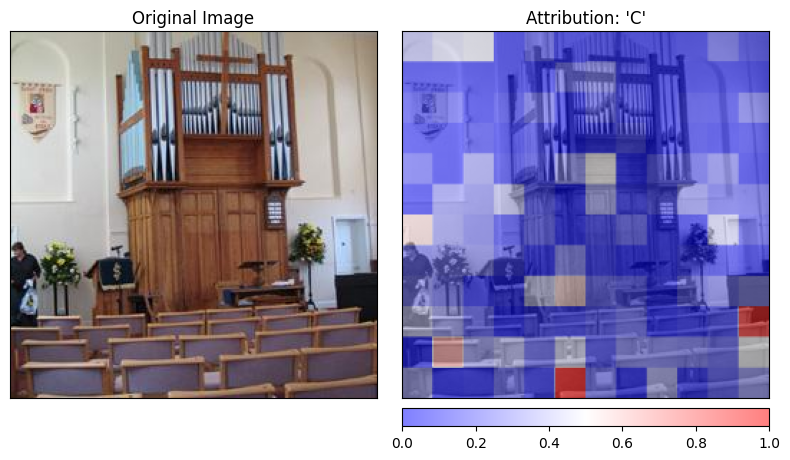

In [81]:
image_grid_thw = inputs.get("image_grid_thw", None)
viz.plot_image_attributions(img_attr=image_scores,
                            original_image=img,
                            target_ids=target_ids.unsqueeze(0), 
                            image_grid_thw=image_grid_thw,
                            target_indices=[decision_token]
                            )

### ShapIQ

In [ ]:
import numpy as np
import torch
import shapiq

from src.explainers import BaseExplainer
from src.models import BaseVLMWrapper
from src.utils.faithfulness_utils import pred_probs # Ensure this is imported!


class VLMTokenGame(shapiq.Game):
    def __init__(self, n_players, explainer, base_inputs, target_ids, real_idx, model_type, num_features, num_valid_tokens, valid_token_indices):
        super().__init__(n_players, normalize=False)
        self.explainer = explainer
        self.base_inputs = base_inputs
        self.target_ids = target_ids
        self.real_idx = real_idx
        self.model_type = model_type
        self.num_features = num_features
        self.num_valid_tokens = num_valid_tokens
        self.valid_token_indices = valid_token_indices

    def value_function(self, coalitions: np.ndarray) -> np.ndarray:
        probs = self.explainer._batched_evaluate_with_cache(
            coalitions, 
            self.base_inputs, 
            self.target_ids,
            self.model_type, 
            self.num_features, 
            self.num_valid_tokens,
            self.valid_token_indices
        )
        values = probs[:, self.real_idx]
        return values.float().detach().cpu().numpy()


class ShapIQExplainer(BaseExplainer):
    def __init__(
        self, 
        model_wrapper: BaseVLMWrapper, 
        budget: int = 256,
        batch_size: int = 8, 
        mask_value: float = 0.0,
        seed: int = 42
    ):
        super().__init__(model_wrapper)
        self.budget = budget
        self.batch_size = batch_size
        self.mask_value = mask_value
        self.seed = seed

    def attribute(
        self,
        image,
        text: str,
        target_indices: int | list[int] | None = None,
        **kwargs,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        
        # 1. Base Forward Pass & Processing
        inputs = self.wrapper.get_inputs(image, text)
        pixel_values = inputs["pixel_values"]
        input_ids = inputs["input_ids"]
        
        pred_results = kwargs.get("pred_results")
        if pred_results is None:
            pred_results = self.wrapper.predict(inputs, return_logits=True, **kwargs)
            
        new_ids = pred_results["new_ids"]
        if new_ids.dim() > 1: new_ids = new_ids[0]
        
        indices_to_compute = target_indices if isinstance(target_indices, list) else [target_indices] if target_indices is not None else list(range(len(new_ids)))
        num_targets = len(indices_to_compute)
        target_tokens = new_ids[indices_to_compute]
        target_ids_expanded = new_ids.unsqueeze(0)

        # 2. Extract Architectural Shapes
        model_type = getattr(self.wrapper.model.config, "model_type", "").lower()
        
        if "internvl" in model_type:
            if inputs["pixel_values"].ndim == 4: inputs["pixel_values"] = inputs["pixel_values"].unsqueeze(0)
            _, num_features, C, H, W = inputs["pixel_values"].shape
        elif "qwen" in model_type:
            if inputs["pixel_values"].ndim == 2: inputs["pixel_values"] = inputs["pixel_values"].unsqueeze(0)
            _, num_features, patch_dim = inputs["pixel_values"].shape
        else:
            if inputs["pixel_values"].ndim == 3: inputs["pixel_values"] = inputs["pixel_values"].unsqueeze(0)
            _, C, H, W = inputs["pixel_values"].shape
            num_features = H * W

        # --- THE FIX: PROTECT VISUAL & SPECIAL TOKENS ---
        valid_mask = torch.ones_like(input_ids[0], dtype=torch.bool)
        if self.wrapper.special_token_ids is not None:
            for skip_id in self.wrapper.special_token_ids:
                valid_mask &= (input_ids[0] != skip_id)
                
        valid_token_indices = torch.where(valid_mask)[0]
        num_valid_tokens = len(valid_token_indices)
        
        # The game now ONLY considers images patches and valid text words!
        n_players = num_features + num_valid_tokens

        # 3. Setup SHAP Accumulators & Initialize Cache
        pixel_shap = []
        token_shap = []
        self.coalition_cache = {}

        # 4. shapiq Execution Loop
        for t_idx, real_idx in enumerate(indices_to_compute):
            game = VLMTokenGame(
                n_players=n_players,
                explainer=self,
                base_inputs=inputs,
                target_ids=target_ids_expanded,
                real_idx=real_idx,
                model_type=model_type,
                num_features=num_features,
                num_valid_tokens=num_valid_tokens,
                valid_token_indices=valid_token_indices
            )
            
            approximator = shapiq.approximator.RegressionFSII(n=n_players, max_order=1, random_state=self.seed)
            ivs = approximator.approximate(self.budget, game)
            
            # Extract values for Pixels
            p_s = [ivs[(i,)] for i in range(num_features)]
            pixel_shap.append(p_s)
            
            # --- THE FIX: MAP TEXT SHAP BACK TO FULL SEQUENCE ---
            # Fill the full seq_len with 0.0s, and only overwrite the valid words with their SHAP score
            t_s = [0.0] * input_ids.shape[1]
            for j, real_seq_idx in enumerate(valid_token_indices.cpu().numpy()):
                t_s[real_seq_idx] = ivs[(num_features + j,)]
            token_shap.append(t_s)

        # 5. Format to Tensors and Standard Spatial Shapes
        pixel_shap_tensor = torch.tensor(pixel_shap, device=self.device, dtype=torch.float32)
        token_shap_tensor = torch.tensor(token_shap, device=self.device, dtype=torch.float32)
        
        print(pixel_shap_tensor.shape)

        pixel_attributions = self._reshape_to_spatial(pixel_shap_tensor, model_type, inputs)

        del self.coalition_cache 

        return token_shap_tensor, pixel_attributions


    # -------------------------------------------------------------------------
    # BATCHING & CACHING LOGIC
    # -------------------------------------------------------------------------

    def _batched_evaluate_with_cache(self, coalitions, base_inputs, target_ids, model_type, num_features, num_valid_tokens, valid_token_indices):
        keys = [tuple(c.tolist()) for c in coalitions]
        missing_indices = [i for i, k in enumerate(keys) if k not in self.coalition_cache]
        
        if missing_indices:
            missing_coalitions = coalitions[missing_indices]
            budget = len(missing_coalitions)
            
            p_mask_all = torch.tensor(missing_coalitions[:, :num_features], device=self.device, dtype=torch.int32)
            t_mask_all = torch.tensor(missing_coalitions[:, num_features:], device=self.device, dtype=torch.int32)
            
            for batch_start in range(0, budget, self.batch_size):
                current_bs = min(self.batch_size, budget - batch_start)
                batch_end = batch_start + current_bs
                
                p_mask = p_mask_all[batch_start:batch_end]
                t_mask = t_mask_all[batch_start:batch_end]
                
                masked_kwargs, new_input_ids, masked_pixels = self._apply_batched_masks(
                    base_inputs, target_ids, p_mask, t_mask, model_type, current_bs, valid_token_indices
                )
                
                with torch.no_grad():
                    log_probs = pred_probs(
                        model=self.wrapper,
                        inputs=masked_kwargs,
                        new_input_ids=new_input_ids,
                        pixel_values=masked_pixels,
                        output_ids=target_ids.expand(current_bs, -1)
                    )
                    probs = torch.exp(log_probs)
                
                for idx_in_batch in range(current_bs):
                    global_idx = missing_indices[batch_start + idx_in_batch]
                    k = keys[global_idx]
                    self.coalition_cache[k] = probs[idx_in_batch]

        ret = torch.stack([self.coalition_cache[k] for k in keys], dim=0)
        return ret


    def _apply_batched_masks(self, base_inputs, target_ids, p_mask, t_mask, model_type, bs, valid_token_indices):
        # 1. Text Masking (THE VECTORIZED FIX)
        input_ids = base_inputs["input_ids"].expand(bs, -1).clone()
        pad_id = self.wrapper.processor.tokenizer.pad_token_id or 0
        
        # t_mask is (bs, num_valid_tokens). We broadcast valid_token_indices to the batch
        idx_expanded = valid_token_indices.unsqueeze(0).expand(bs, -1)
        replace_mask = torch.zeros_like(input_ids, dtype=torch.bool)
        
        # Scatter the 0s (masked tokens) onto the full sequence boolean mask
        replace_mask.scatter_(1, idx_expanded, t_mask == 0)
        input_ids[replace_mask] = pad_id
        
        target_ids_expanded = target_ids.expand(bs, -1)
        new_input_ids = torch.cat([input_ids, target_ids_expanded], dim=1)

        # 2. Image Masking (Ironclad checks included!)
        base_pixels = base_inputs["pixel_values"]
        if "internvl" in model_type and base_pixels.ndim == 4: base_pixels = base_pixels.unsqueeze(0)
        elif "qwen" in model_type and base_pixels.ndim == 2: base_pixels = base_pixels.unsqueeze(0)
        elif "llava" in model_type and base_pixels.ndim == 3: base_pixels = base_pixels.unsqueeze(0)
            
        pixel_values = base_pixels.expand(bs, *base_pixels.shape[1:]).clone()
        
        if "internvl" in model_type:
            expanded_mask = p_mask.view(bs, -1, 1, 1, 1)
            pixel_values = torch.where(expanded_mask == 1, pixel_values, torch.tensor(self.mask_value, device=self.device, dtype=pixel_values.dtype))
        elif "qwen" in model_type:
            expanded_mask = p_mask.view(bs, -1, 1)
            pixel_values = torch.where(expanded_mask == 1, pixel_values, torch.tensor(self.mask_value, device=self.device, dtype=pixel_values.dtype))
        else: # LLaVA
            _, C, H, W = pixel_values.shape
            expanded_mask = p_mask.view(bs, 1, H, W).expand(-1, C, -1, -1)
            pixel_values = torch.where(expanded_mask == 1, pixel_values, torch.tensor(self.mask_value, device=self.device, dtype=pixel_values.dtype))

        # 3. Hardware Grids
        masked_kwargs = {
            k: v.repeat(bs, 1) if k == "image_grid_thw" else v 
            for k, v in base_inputs.items() 
            if k not in ["input_ids", "pixel_values", "attention_mask"]
        }

        return masked_kwargs, new_input_ids, pixel_values

    def _reshape_to_spatial(self, pixel_shap, model_type, inputs):
        num_targets = pixel_shap.shape[0]
        if "internvl" in model_type:
            _, _, _, H, W = inputs["pixel_values"].shape
            global_tile_shap = pixel_shap[:, -1].view(num_targets, 1, 1)
            return global_tile_shap.expand(-1, H, W)
        elif "qwen" in model_type:
            if "image_grid_thw" in inputs:
                grid_thw = inputs["image_grid_thw"][0].cpu().numpy().tolist()
                H, W = grid_thw[1], grid_thw[2]
                return pixel_shap.view(num_targets, H, W)
            else:
                return pixel_shap 
        else: 
            _, _, H, W = inputs["pixel_values"].shape
            return pixel_shap.view(num_targets, H, W)


In [ ]:
from src.models import QwenVLWrapper

model_wrapper = QwenVLWrapper(model, processor)


In [ ]:
import time

from torch.utils.data import DataLoader
from src.datasets import POPEGroundingDataset
from src.utils.plausibility_utils import OntologyMapper, ids_to_word_groups, pool_heatmaps

data_path = "../datasets/repope"
pope_json_path = os.path.join(data_path, "repope_annotations")
pope_type = "random"
coco_split = "val2014"

dataset = POPEGroundingDataset(data_path=data_path,
                               pope_json_path=pope_json_path,
                               pope_type=pope_type,
                               coco_split=coco_split)

def collate_fn_custom(batch):
    # Standard collate fails on Dictionaries (category_masks) and Lists (all_captions)
    # So we write a simple one that just returns the list of items
    return batch[0] # Assumes batch_size=1

dl = DataLoader(dataset, collate_fn=collate_fn_custom)

# category = dataset.id2name
# mapper = OntologyMapper(coco_categories=category, threshold=0.5)



In [ ]:
for sample in dl:
    img = sample["image"]
    core_question = sample["question"]
    # q = "Write a one sentence caption"
    prefix = "Answer strictly this question with yes or no: "
    text = prefix + core_question
    text = core_question
    # captions = sample["captions"]
    # masks = sample["category_masks"]

    break


In [ ]:
torch.cuda.empty_cache()

In [ ]:
inputs = model_wrapper.get_inputs(img, text)
pred_results = model_wrapper.predict(inputs, return_logits=True)


In [ ]:
game = GenerativeVLMGame(
    model_wrapper=model_wrapper, 
    image=img, 
    text=text,
    patch_group_size=4,
    target_ids=pred_results["new_ids"], 
    target_seq_index=0 # Explain the 1st generated token!
)

In [ ]:
approximator = shapiq.ProxySPEX(
    n=game.n_players,
    max_order=2,     
    index="FSII",    # Use "FBII" if you prefer Banzhaf interactions
    random_state=42
)

# 3. Let ProxySPEX handle EVERYTHING!
# It will generate its own Fourier-optimized masks, run our fast batched VLM Game,
# train its internal LightGBM proxy, and instantly extract the 2D interaction matrix.
interaction_values = approximator.approximate(
    budget=5, 
    game=game
)



In [ ]:
print(interaction_values)

In [ ]:
# 2. Initialize FIxLIP (with the exact player counts the Game calculated)
fixlip = FIxLIP(
    n_players_image=game.n_players_image, 
    n_players_text=game.n_players_text, 
    mode="banzhaf", 
    max_order=1
)

In [ ]:
# 3. Call approximate_crossmodal exactly like they do in their docs!
interaction_values = fixlip.approximate_crossmodal(
    game=game, 
    budget=4, 
    approximation_type="proxyshap"
)

In [ ]:
import math


print (math.comb(100, 50))

In [ ]:
77*33*32

In [ ]:
2**12

In [ ]:
print(interaction_values)

In [ ]:
shapiq.network_plot(
    first_order_values=interaction_values.get_n_order_values(1),
    second_order_values=interaction_values.get_n_order_values(2)
)
# or use
interaction_values.plot_network()

In [ ]:
# explainer = ShapIQExplainer(model_wrapper,
#                             budget=5,
#                             )

explainer = FIxLIPExplainer(model_wrapper,
                            budget=1024,
                            approximation_type="original",
                            )

In [ ]:
target_indices = None
# target_indices = 0
target_indices = [0]

text_attrs, img_attrs = explainer.attribute(image=img,
                                    text=text,
                                    target_indices=target_indices,
                                    pred_results=pred_results,
                                    )

In [ ]:
text_attrs.shape

In [ ]:
img_attrs.shape

#### Visualization

In [ ]:
from src.utils.xai_utils import XAIVisualizer

viz = XAIVisualizer(processor)

In [ ]:
token_attribution = text_attrs[0:1]
pixel_attribution = img_attrs[0:1]
target_ids = pred_results["new_ids"]

img_attrs = img_attrs.float()
text_attrs = text_attrs.float()

In [ ]:
viz.plot_text_attributions(
    text_attr=text_attrs, 
    input_ids=inputs["input_ids"], 
    target_ids=target_ids.unsqueeze(0),
    special_token_ids=model_wrapper.special_token_ids,
    semantic_mask=None,
    target_indices=target_indices
)

In [ ]:
image_grid_thw = inputs.get("image_grid_thw", None)
viz.plot_image_attributions(img_attr=img_attrs,
                            original_image=img,
                            target_ids=target_ids.unsqueeze(0), 
                            image_grid_thw=image_grid_thw,
                            target_indices=target_indices
                            )

### EAGLE

In [17]:
import numpy as np
from tqdm import tqdm
import torch
import time
import cv2
from concurrent.futures import ThreadPoolExecutor
from typing import Optional, List, Tuple
from sklearn import metrics

class EfficientMLLMSubModularExplanationVision(object):
    """
    Black-box explanation of multimodal large language 
    model (MLLM) based on submodular subset selection.
    """
    def __init__(self, 
                wrapper,
                lambda1 = 1.0,
                lambda2 = 1.0,
                search_scope = 10,
                pending_samples = 8,
                update_step = 5,
                efficient=False,
                #  batch_size = 4,    # Suggestion: 
                 ):
        """_summary_

        Args:
            detection_model (_type_): Any Multimodal Large Language Models
            preproccessing_function (_type_): _description_
            lambda1 (float, optional): _description_. Defaults to 1.0.
            lambda2 (float, optional): _description_. Defaults to 1.0.
            device (str, optional): _description_. Defaults to "cuda".
        """


        self.wrapper = wrapper
        self.lambda1 = lambda1
        self.lambda2 = lambda2
        # Parameters of the submodular
        self.device = wrapper.device

        self.search_scope = search_scope
        self.update_step = update_step
        
        self.pending_samples = pending_samples

        self.V_set : List[np.ndarray]
        self.refer_baseline : torch.Tensor
        self.efficient = efficient
    
    def save_file_init(self):
        self.saved_json_file = {
            "insertion_score": [],
            "deletion_score": [],
            "smdl_score": [],
            "insertion_word_score": [],
            "deletion_word_score": [],
            "region_area": [],
            "lambda1": self.lambda1,
            "lambda2": self.lambda2,
            "insertion_score_oppose": [],
            "deletion_score_oppose": [],
            "insertion_word_score_oppose": [],
            "deletion_word_score_oppose": [],
            "region_area_oppose": [],
        }
        
    def save_positive_file(self, insertion_score, deletion_score, smdl_score):
        self.saved_json_file["insertion_score"].append(insertion_score.mean().cpu().float().numpy().item())
        self.saved_json_file["insertion_word_score"].append(insertion_score.cpu().float().numpy().tolist())
        
        self.saved_json_file["deletion_score"].append(deletion_score.mean().cpu().float().numpy().item())
        self.saved_json_file["deletion_word_score"].append(deletion_score.cpu().float().numpy().tolist())
        
        self.saved_json_file["smdl_score"].append(smdl_score.cpu().float().item())
        
    def save_negative_file(self, insertion_score, deletion_score):
        self.saved_json_file["insertion_score_oppose"].append(insertion_score.mean().cpu().float().numpy().item())
        self.saved_json_file["insertion_word_score_oppose"].append(insertion_score.cpu().float().numpy().tolist())
        
        self.saved_json_file["deletion_score_oppose"].append(deletion_score.mean().cpu().float().numpy().item())
        self.saved_json_file["deletion_word_score_oppose"].append(deletion_score.cpu().float().numpy().tolist())
    
    def evaluation_maximun_sample_efficient(self, S_set, S_set_opposite):
        V_set_tensor = torch.from_numpy(np.array(self.V_set)).float().to(self.device)
        
        alpha_batch = V_set_tensor + self.refer_baseline.unsqueeze(0)
        alpha_batch = alpha_batch.expand(-1, -1, -1, 3)

        if len(S_set) == 0 or self.update_count % self.update_step == 0:
            # Positive samples search
            source_tensor = self.source_tensor.unsqueeze(0).expand(alpha_batch.shape[0], -1, -1, -1)

        else:
            alpha_batch = alpha_batch[:self.search_scope]
            # Positive samples search with scope
            source_tensor = self.source_tensor.unsqueeze(0).expand(alpha_batch.shape[0], -1, -1, -1)

        batch_input_images = alpha_batch * source_tensor    # torch.Size([51, 1365, 2048, 3])
        batch_input_images_reverse = (1 - alpha_batch) * source_tensor
        
        with torch.no_grad():
            # Insertion
            insertion_scores = self._evaluate_masks(batch_input_images)
            
            # Deletion
            deletion_scores = self._evaluate_masks(batch_input_images_reverse)
            
            #Overall submodular score
            smdl_scores = self.lambda1 * insertion_scores + self.lambda2 * (1-deletion_scores)
            smdl_scores = smdl_scores.mean(-1)
            arg_max_index = smdl_scores.argmax().cpu().item()
            
            if len(S_set) == 0 or self.update_count % self.update_step == 0:
                indices = torch.argsort(smdl_scores, descending=True)
                sorted_V = [self.V_set[i] for i in indices]
                self.V_set = sorted_V
                
                # Update 0 -> Have been sorted
                S_set.append(self.V_set[0])
                self.refer_baseline = self.refer_baseline + torch.from_numpy(self.V_set[0]).float().to(self.device)
                del self.V_set[0]
                
            else:
                # Update 0 -> Have been sorted
                S_set.append(self.V_set[arg_max_index])
                self.refer_baseline = self.refer_baseline + torch.from_numpy(self.V_set[arg_max_index]).float().to(self.device)
                del self.V_set[arg_max_index]
                
            # Save intermediate results
            self.save_positive_file(
                insertion_scores[arg_max_index], 
                deletion_scores[arg_max_index], 
                smdl_scores[arg_max_index])
            
            self.saved_json_file["region_area"].append(
                (self.refer_baseline.sum() / self.region_area).cpu().item()
            )
            
            # Negative samples search
            if len(S_set_opposite) == 0:
                arg_min_index = smdl_scores.argmin().cpu().item()
                
                self.save_negative_file(
                    deletion_scores[arg_min_index], 
                    insertion_scores[arg_min_index])
                
                S_set_opposite.append(self.V_set[-1])
                self.refer_baseline_opposite = self.refer_baseline_opposite - torch.from_numpy(self.V_set[-1]).float().to(self.device)
                del self.V_set[-1]
                
                self.saved_json_file["region_area_oppose"].append(
                    (self.refer_baseline_opposite.sum() / self.region_area).cpu().item()
                )
                
                return S_set, S_set_opposite
            
            elif len(self.V_set) > self.pending_samples:
                oppose_set_condidates = self.V_set[-self.pending_samples:]
                
                oppose_set_tensor = torch.from_numpy(np.array(oppose_set_condidates)).float().to(self.device)
                
                alpha_batch_opposite = self.refer_baseline_opposite.unsqueeze(0) - oppose_set_tensor    # This can be insertion
                alpha_batch_opposite = alpha_batch_opposite.expand(-1, -1, -1, 3)
                
                source_tensor = self.source_tensor.unsqueeze(0).expand(alpha_batch_opposite.shape[0], -1, -1, -1)
                batch_input_images = alpha_batch_opposite * source_tensor    # torch.Size([51, 1365, 2048, 3])
                batch_input_images_reverse = (1 - alpha_batch_opposite) * source_tensor
                
                # Insertion
                insertion_scores = self._evaluate_masks(batch_input_images)
                # Deletion
                deletion_scores = self._evaluate_masks(batch_input_images_reverse)
                
                oppose_smdl_scores = self.lambda1 * insertion_scores + self.lambda2 * (1-deletion_scores)
                
                arg_max_index_oppose = oppose_smdl_scores.mean(-1).argmax().cpu().item()
                
                self.save_negative_file(
                    insertion_scores[arg_max_index_oppose], 
                    deletion_scores[arg_max_index_oppose])
                
                S_set_opposite.append(oppose_set_condidates[arg_max_index_oppose])
                self.refer_baseline_opposite = self.refer_baseline_opposite - torch.from_numpy(oppose_set_condidates[arg_max_index_oppose]).float().to(self.device)
            
                del self.V_set[-self.pending_samples + arg_max_index_oppose]
                
                self.saved_json_file["region_area_oppose"].append(
                    (self.refer_baseline_opposite.sum() / self.region_area).cpu().item()
                )
            
        return S_set, S_set_opposite
    
    def evaluation_maximun_sample(self, S_set):
        # V_set_tem = np.array(self.V_set).astype(np.float32) # (51, 1365, 2048, 1)
        V_set_tensor = torch.from_numpy(np.array(self.V_set)).float().to(self.device)
        
        # alpha_batch = (V_set_tem + self.refer_baseline[np.newaxis,...])#.astype(np.uint8) # (51, 1365, 2048, 1)
        alpha_batch = V_set_tensor + self.refer_baseline.unsqueeze(0)
        alpha_batch = alpha_batch.expand(-1, -1, -1, 3)
        
        # print("Stage 1 time comsume: {}".format(time.time()-timer))
        # timer = time.time()
        
        # batch_input_images = alpha_batch * self.source_image[np.newaxis,...]    # (51, 1365, 2048, 1)
        source_tensor = self.source_tensor.unsqueeze(0).expand(alpha_batch.shape[0], -1, -1, -1)
        batch_input_images = alpha_batch * source_tensor    # torch.Size([51, 1365, 2048, 3])
        batch_input_images_reverse = (1 - alpha_batch) * source_tensor
        
        # print("Stage 2 time comsume: {}".format(time.time()-timer))
        # timer = time.time()
        
        with torch.no_grad():
            # Insertion
            insertion_scores = self._evaluate_masks(batch_input_images)
            
            # Deletion
            deletion_scores = self._evaluate_masks(batch_input_images_reverse)
            
            #Overall submodular score
            smdl_scores = self.lambda1 * insertion_scores + self.lambda2 * (1-deletion_scores)
            smdl_scores = smdl_scores.mean(-1)
            arg_max_index = smdl_scores.argmax().cpu().item()
            
            # Save intermediate results
            insertion_score = insertion_scores[arg_max_index]
            deletion_score = deletion_scores[arg_max_index]
            smdl_score = smdl_scores[arg_max_index]
            self.save_positive_file(insertion_score, deletion_score, smdl_score)

            # self.saved_json_file["insertion_score"].append(insertion_scores[arg_max_index].mean().cpu().numpy().item())
            # self.saved_json_file["insertion_word_score"].append(insertion_scores[arg_max_index].cpu().numpy().tolist())
            
            # self.saved_json_file["deletion_score"].append(deletion_scores[arg_max_index].mean().cpu().numpy().item())
            # self.saved_json_file["deletion_word_score"].append(deletion_scores[arg_max_index].cpu().numpy().tolist())
            
            # self.saved_json_file["smdl_score"].append(smdl_scores[arg_max_index].cpu().item())
            
            # Update
            S_set.append(self.V_set[arg_max_index])
            self.refer_baseline = self.refer_baseline + torch.from_numpy(self.V_set[arg_max_index]).float().to(self.device)
            del self.V_set[arg_max_index]
            
            self.saved_json_file["region_area"].append(
                (self.refer_baseline.sum() / self.region_area).cpu().item()
            )
            
        return S_set
    

    def to_del_evaluate_masks(self,
                        perturbed_tensors: torch.Tensor,
                        # original_image_np: np.ndarray,
                        # masks: torch.Tensor,
                        # text: str,
                        # full_ids: torch.Tensor,
                        # t_start: int,
                        # t_end: int
                        ) -> torch.Tensor:
        """
        Internal forward function. 
        Applies a batch of masks to the image, runs inference, and returns target probabilities.
        """
        # original_tensor = torch.from_numpy(original_image_np).float().to(device=self.device) # [H, W, 3]
        
        # 1. Apply masks to create perturbed images
        # masks shape: [Batch, H, W, 1]
        # perturbed_tensors = masks * original_tensor.unsqueeze(0)
        
        all_probs = []
        
        # 2. Iterate through the perturbed images and run inference
        # (We process iteratively to avoid complex VLM dynamic grid batching issues)
        for i in range(perturbed_tensors.shape[0]):
            # Convert back to PIL for standard Hugging Face processors
            img_np = perturbed_tensors[i].cpu().numpy()
            img_np = np.clip(img_np, 0, 255).astype(np.uint8)
            pil_img = Image.fromarray(img_np)
            
            # Get pristine inputs from your wrapper
            inputs = self.wrapper.get_inputs(pil_img, self.text)
            
            # Inject the generated IDs
            inputs["input_ids"] = full_ids.clone().unsqueeze(0)
            inputs["attention_mask"] = torch.ones_like(inputs["input_ids"])
            for key in ["position_ids", "token_type_ids"]:
                if key in inputs: del inputs[key]
            
            # Forward Pass (No gradients needed for EAGLE!)
            with torch.no_grad():
                outputs = self.wrapper.model(**inputs)
                
                # EAGLE uses Softmax probabilities, NOT raw logits
                logits = outputs.logits[:, self.t_start-1 : self.t_end-1, :]
                probs = F.softmax(logits, dim=-1)
                
                target_ids = self.full_ids[self.t_start:self.t_end].unsqueeze(0).unsqueeze(-1)
                target_probs = probs.gather(dim=-1, index=target_ids).squeeze(-1) # [1, gen_len]
                
                all_probs.append(target_probs)
                
        # Shape: [Batch, gen_len]
        return torch.cat(all_probs, dim=0)

    def _evaluate_masks(self, 
                        perturbed_tensors: torch.Tensor,
                        # target_indices: List[int]
                        ) -> torch.Tensor:
        """
        Evaluates the specific requested tokens.
        target_indices: Offsets from t_start (e.g., [0, 1, 2] for the first 3 generated words, or [2] for just the 3rd).
        """

        
        all_probs = []
        
        # OPTIMIZATION: Truncate the sequence to save compute!
        # To predict token at offset `idx`, we only need the sequence up to `t_start + idx`
        max_idx = max(self.target_indices)
        eval_ids = self.full_ids[: self.t_start + max_idx] # Causal truncation
        
        # We need the word IDs to gather their probabilities
        target_word_ids = self.full_ids[self.t_start : self.t_start + max_idx + 1]

        for i in range(perturbed_tensors.shape[0]):
            img_np = perturbed_tensors[i].cpu().numpy()
            img_np = np.clip(img_np, 0, 255).astype(np.uint8)
            pil_img = Image.fromarray(img_np)
            
            inputs = self.wrapper.get_inputs(pil_img, self.text)
            
            # Inject truncated IDs
            inputs["input_ids"] = eval_ids.clone().unsqueeze(0)
            inputs["attention_mask"] = torch.ones_like(inputs["input_ids"])
            for key in ["position_ids", "token_type_ids"]:
                if key in inputs: del inputs[key]
            
            with torch.no_grad():
                outputs = self.wrapper.model(**inputs)
                
                # outputs.logits shape: [1, seq_len, vocab_size]
                probs = F.softmax(outputs.logits, dim=-1)
                
                # Gather the probabilities for the specific target indices
                batch_probs = []
                for idx in self.target_indices:
                    # Causal shift: logit at (self.t_start - 1 + idx) predicts word at (self.t_start + idx)
                    logit_pos = self.t_start - 1 + idx
                    word_id = target_word_ids[idx].unsqueeze(0).unsqueeze(0) # [1, 1]
                    
                    token_prob = probs[:, logit_pos, :].gather(dim=-1, index=word_id).squeeze(-1)
                    batch_probs.append(token_prob)
                
                # Shape: [1, len(target_indices)]
                all_probs.append(torch.cat(batch_probs, dim=-1).unsqueeze(0))
                
        # Shape: [Batch, len(target_indices)]
        return torch.cat(all_probs, dim=0)

    def _evaluate_text_masks(self, 
                             prompt_masks: torch.Tensor, 
                             inputs: dict, 
                             t_start: int, 
                             target_indices: List[int]) -> torch.Tensor:
        """
        Evaluates text perturbations by masking out prompt tokens in the attention_mask.
        prompt_masks: Shape [Batch, t_start] (1 means keep token, 0 means ignore)
        """
        all_probs = []
        batch_size = prompt_masks.shape[0]
        
        max_idx = max(target_indices)
        eval_ids = self.full_ids[: t_start + max_idx] 
        target_word_ids = self.full_ids[t_start : t_start + max_idx + 1]

        # # Duplicate the pristine inputs for the batch
        # # We don't need to re-process the image because only the text mask changes!
        # batched_inputs = {}
        # for k, v in original_inputs.items():
        #     if isinstance(v, torch.Tensor):
        #         batched_inputs[k] = v.expand(batch_size, *[-1]*(v.ndim - 1)).clone()
        #     else:
        #         batched_inputs[k] = [v[0]] * batch_size # Handle lists like image_grid_thw


        # 1. Inject truncated IDs
        inputs["input_ids"] = eval_ids.unsqueeze(0).expand(batch_size, -1).clone()
        
        # 2. Build the base attention mask (All 1s)
        base_attn_mask = torch.ones_like(inputs["input_ids"])
        
        # 3. APPLY THE TEXT PERTURBATION MASKS!
        # We overwrite the prompt section [:t_start] with our submodular masks
        base_attn_mask[:, :t_start] = prompt_masks
        inputs["attention_mask"] = base_attn_mask


        with torch.no_grad():
            outputs = self.wrapper.model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)
            
            # Gather the probabilities for the specific target indices
            batch_probs = []
            for idx in target_indices:
                logit_pos = t_start - 1 + idx
                # word_id shape needs to match batch size: [Batch, 1]
                word_id = target_word_ids[idx].unsqueeze(0).expand(batch_size, 1) 
                
                token_prob = probs[:, logit_pos, :].gather(dim=-1, index=word_id).squeeze(-1)
                batch_probs.append(token_prob.unsqueeze(1))
            
            # Shape: [Batch, len(target_indices)]
            
            return torch.cat(batch_probs, dim=-1)

    def get_merge_set(self):
        if self.efficient:
                
            # define a subset
            S_set = []
            S_set_opposite = []
                    
            # self.refer_baseline = np.zeros_like(self.V_set[0]).astype(np.float32)
            self.refer_baseline = torch.zeros_like(torch.from_numpy(self.V_set[0]).float(), device=self.device)        
            self.refer_baseline_opposite = 1 - torch.zeros_like(torch.from_numpy(self.V_set[0]).float(), device=self.device)
            
            sub_images = torch.stack([self.source_tensor * self.refer_baseline, self.source_tensor * self.refer_baseline_opposite])
            scores = self._evaluate_masks(sub_images)
            
            self.saved_json_file["org_score"] = scores[1].cpu().float().numpy().tolist()
            self.saved_json_file["baseline_score"] = scores[0].cpu().float().numpy().tolist()
            
            self.update_count = 0
            for _ in tqdm(range(self.saved_json_file["sub-region_number"])):
                if len(self.V_set) == 1:
                    S_set = S_set + self.V_set
                    break
                S_set, S_set_opposite = self.evaluation_maximun_sample_efficient(S_set, S_set_opposite)
                self.update_count += 1
        
            self.saved_json_file["insertion_score"] = self.saved_json_file["insertion_score"] + self.saved_json_file["insertion_score_oppose"][::-1] + [scores[1].cpu().float().mean().item()]
            self.saved_json_file["deletion_score"] = self.saved_json_file["deletion_score"] + self.saved_json_file["deletion_score_oppose"][::-1] + [scores[0].cpu().float().mean().item()]
            self.saved_json_file["insertion_word_score"] = self.saved_json_file["insertion_word_score"] + self.saved_json_file["insertion_word_score_oppose"][::-1] + [scores[1].cpu().float().numpy().tolist()]
            self.saved_json_file["deletion_word_score"] = self.saved_json_file["deletion_word_score"] + self.saved_json_file["deletion_word_score_oppose"][::-1] + [scores[0].cpu().float().numpy().tolist()]
            
            self.saved_json_file["region_area"] = self.saved_json_file["region_area"] + self.saved_json_file["region_area_oppose"][::-1] + [1.]
            S_set = np.concatenate((S_set, S_set_opposite[::-1]))
            
            return S_set
        else:
            # define a subset
            S_set = []
            # self.refer_baseline = np.zeros_like(self.V_set[0]).astype(np.float32)
            self.refer_baseline = torch.zeros_like(torch.from_numpy(self.V_set[0]).float(), device=self.device)
            
            for i in tqdm(range(self.saved_json_file["sub-region_number"])):
                S_set = self.evaluation_maximun_sample(S_set)
            
            self.saved_json_file["org_score"] = self.saved_json_file["insertion_word_score"][-1]
            self.saved_json_file["baseline_score"] = self.saved_json_file["deletion_word_score"][-1]
            
            return S_set

    
    def get_word_saliency(self):
        insertion_word_scores  = [self.saved_json_file["baseline_score"]] + self.saved_json_file["insertion_word_score"]
        insertion_word_scores = np.array(insertion_word_scores).T
        
        regions = np.array([0] + self.saved_json_file["region_area"])
        
        word_heatmap_scores = []
        for insertion_word_score in insertion_word_scores:
            auc = metrics.auc(regions, insertion_word_score)
            word_heatmap_score = auc - insertion_word_score.min()
            word_heatmap_scores.append(word_heatmap_score)
        
        return word_heatmap_scores
    
    def gen_cam(self, image, mask):
        """
        Generate heatmap
            :param image: [H,W,C]
            :param mask: [H,W],range 0-1
            :return: tuple(cam,heatmap)
        """
        # Read image
        w = mask.shape[1]
        h = mask.shape[0]
        # mask->heatmap
        mask = cv2.resize(mask, (int(w/20),int(h/20)))
        mask = cv2.resize(mask, (w,h))
        heatmap = cv2.applyColorMap(np.uint8(mask), cv2.COLORMAP_VIRIDIS)  # cv2.COLORMAP_COOL
        heatmap = np.float32(heatmap)

        # merge heatmap to original image
        cam = 0.5*heatmap + 0.5*np.float32(image)
        return cam.astype(np.uint8), (heatmap).astype(np.uint8)
    
    def add_value(self, S_set, json_file):
        single_mask = np.zeros_like(S_set[0])
        single_mask = single_mask.astype(np.float16)
        
        value_list_1 = np.array(json_file["smdl_score"])
        
        # value_list_2 = np.array(
        #     [1 - np.mean(json_file["org_score"]) + np.mean(json_file["baseline_score"])] + json_file["smdl_score"][:-1]
        # )
        value_list_2 = np.array(
            [np.mean(1 - np.array(json_file["org_score"]) + np.array(json_file["baseline_score"]))] + json_file["smdl_score"][:-1]
        )
        
        # value_list = np.exp((value_list_1 - value_list_2)/1)
        value_list = value_list_1 - value_list_2
        
        values = []
        value = 0
        i = 0
        for smdl_single_mask, smdl_value in zip(S_set, value_list):
            value = value - abs(smdl_value)
            single_mask[smdl_single_mask==1] = value
            values.append(value)
            i+=1
        attribution_map = single_mask - single_mask.min()
        attribution_map = attribution_map / attribution_map.max()
        
        return attribution_map, np.array(values)

    def norm_image(self, image):
        """
        Normalization image
        :param image: [H,W,C]
        :return:
        """
        image = image.copy()
        image -= np.max(np.min(image), 0)
        image /= np.max(image)
        image *= 255.
        return np.uint8(image)

    def __call__(self, image, V_set, text, target_indices, **kwargs,): # text, full_ids, t_start, t_end):
        """_summary_

        Args:
            image (cv2 format): (h, w, 3)
            V_set (_type_): (n, h, w, 1)
            class_id (List [int, ...]): which classes?
            given_box (xyxy): which boxes?
        """
        self.save_file_init()
        
        
        # self.source_image = image
        self.source_tensor = torch.from_numpy(image).float().to(self.device)
        self.h, self.w, _ = image.shape
        self.region_area = image.shape[0] * image.shape[1]

        
        self.V_set = V_set.copy()

        # Set arguments required for the forward pass
        self.text = text # Text prompt
        self.full_ids = kwargs.get("full_ids") # Generated IDS (prompt+answer)
        self.t_start = kwargs.get("t_start") # Start of the answer
        self.t_end = kwargs.get("t_end") # End of the answer

        self.target_indices = target_indices # Indices of the generated tokens

        self.saved_json_file["sub-region_number"] = len(V_set)

        Submodular_Subset = self.get_merge_set()

        # Get image heatmap
        if 'smdl_score' in self.saved_json_file:
            attribution_map, _ = self.add_value(Submodular_Subset, self.saved_json_file)
            attribution_map = self.norm_image(attribution_map[:,:,0])
        else:
            attribution_map = Submodular_Subset
            attribution_map = attribution_map - attribution_map.min()
            attribution_map = attribution_map / (attribution_map.max() + 0.00000001)

            attribution_map = cv2.resize(attribution_map, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_LINEAR)
            
            attribution_map = self.norm_image(attribution_map)
        
        # vis_saliency_map, heatmap = self.gen_cam(image, attribution_map)

        # Add words
        self.saved_json_file["words"] = kwargs.get("ans_text") # Answer text
        token_attribution = self.get_word_saliency()

        # return Submodular_Subset, heatmap, vis_saliency_map, token_attribution
        return attribution_map, token_attribution



In [76]:
import numpy as np
import torch
from tqdm import tqdm

import time
import cv2
from concurrent.futures import ThreadPoolExecutor



class MLLMSubModularExplanationVision(object):
    """
    Black-box explanation of multimodal large language 
    model (MLLM) based on submodular subset selection.
    """
    def __init__(self, 
                 model,
                 preproccessing_function = None,
                 lambda1 = 1.0,
                 lambda2 = 1.0,
                #  batch_size = 4,    # Suggestion: 
                 ):
        """_summary_

        Args:
            detection_model (_type_): Any Multimodal Large Language Models
            preproccessing_function (_type_): _description_
            lambda1 (float, optional): _description_. Defaults to 1.0.
            lambda2 (float, optional): _description_. Defaults to 1.0.
            device (str, optional): _description_. Defaults to "cuda".
        """
        super(MLLMSubModularExplanationVision, self).__init__()
        # Parameters of the submodular
        self.MLLM = model
        self.preproccessing_function = preproccessing_function
        
        self.lambda1 = lambda1
        self.lambda2 = lambda2
        
        self.device = self.MLLM.device
        
        print(self.device)
        
        # self.batch_size = batch_size
        
    def save_file_init(self):
        self.saved_json_file = {}
        self.saved_json_file["insertion_score"] = []
        self.saved_json_file["deletion_score"] = []
        self.saved_json_file["smdl_score"] = []
        self.saved_json_file["insertion_word_score"] = []
        self.saved_json_file["deletion_word_score"] = []
        self.saved_json_file["region_area"] = []
        self.saved_json_file["lambda1"] = self.lambda1
        self.saved_json_file["lambda2"] = self.lambda2
    
    def MLLM_inference_batch_images(self, images):
        """_summary_

        Args:
            images (Tensor): _description_
        """
        results = []
        for image in images:
            output_logits = self.MLLM(image)
            results.append(output_logits)
            
        results = torch.stack(results, dim=0)
        return results
    
    def evaluation_maximun_sample(self, S_set):
        timer = time.time()
        # V_set_tem = np.array(self.V_set).astype(np.float32) # (51, 1365, 2048, 1)
        V_set_tensor = torch.from_numpy(np.array(self.V_set)).float().to(self.device)
        
        # alpha_batch = (V_set_tem + self.refer_baseline[np.newaxis,...])#.astype(np.uint8) # (51, 1365, 2048, 1)
        alpha_batch = V_set_tensor + self.refer_baseline.unsqueeze(0)
        alpha_batch = alpha_batch.expand(-1, -1, -1, 3)
        
        # print("Stage 1 time comsume: {}".format(time.time()-timer))
        # timer = time.time()
        
        # batch_input_images = alpha_batch * self.source_image[np.newaxis,...]    # (51, 1365, 2048, 1)
        source_tensor = self.source_tensor.unsqueeze(0).expand(alpha_batch.shape[0], -1, -1, -1)
        batch_input_images = alpha_batch * source_tensor    # torch.Size([51, 1365, 2048, 3])
        batch_input_images_reverse = (1 - alpha_batch) * source_tensor
        
        # print("Stage 2 time comsume: {}".format(time.time()-timer))
        # timer = time.time()
        
        with torch.no_grad():
            # Insertion
            insertion_scores = self.MLLM_inference_batch_images(batch_input_images).to(torch.float32)
            
            # Deletion
            deletion_scores = self.MLLM_inference_batch_images(batch_input_images_reverse).to(torch.float32)
            
            #Overall submodular score
            smdl_scores = self.lambda1 * insertion_scores + self.lambda2 * (1-deletion_scores)
            smdl_scores = smdl_scores.mean(-1)
            arg_max_index = smdl_scores.argmax().cpu().item()
            
            # Save intermediate results
            self.saved_json_file["insertion_score"].append(insertion_scores[arg_max_index].mean().cpu().numpy().item())
            self.saved_json_file["insertion_word_score"].append(insertion_scores[arg_max_index].cpu().numpy().tolist())
            
            self.saved_json_file["deletion_score"].append(deletion_scores[arg_max_index].mean().cpu().numpy().item())
            self.saved_json_file["deletion_word_score"].append(deletion_scores[arg_max_index].cpu().numpy().tolist())
            
            self.saved_json_file["smdl_score"].append(smdl_scores[arg_max_index].cpu().item())
            
            # Update
            S_set.append(self.V_set[arg_max_index])
            self.refer_baseline = self.refer_baseline + torch.from_numpy(self.V_set[arg_max_index]).float().to(self.device)
            del self.V_set[arg_max_index]
            
            self.saved_json_file["region_area"].append(
                (self.refer_baseline.sum() / self.region_area).cpu().item()
            )
            
        return S_set
    
    def get_merge_set(self):
        # define a subset
        S_set = []
        # self.refer_baseline = np.zeros_like(self.V_set[0]).astype(np.float32)
        self.refer_baseline = torch.zeros_like(torch.from_numpy(self.V_set[0]).float(), device=self.device)
        
        for i in tqdm(range(self.saved_json_file["sub-region_number"])):
            S_set = self.evaluation_maximun_sample(S_set)
        
        self.saved_json_file["org_score"] = self.saved_json_file["insertion_word_score"][-1]
        self.saved_json_file["baseline_score"] = self.saved_json_file["deletion_word_score"][-1]
        
        return S_set
    
    def __call__(self, image, V_set):
        """_summary_

        Args:
            image (cv2 format): (h, w, 3)
            V_set (_type_): (n, h, w, 1)
            class_id (List [int, ...]): which classes?
            given_box (xyxy): which boxes?
        """
        self.save_file_init()
        self.saved_json_file["sub-region_number"] = len(V_set)
        
        self.source_image = image
        self.source_tensor = torch.from_numpy(self.source_image).float().to(self.device)
        self.h, self.w, _ = self.source_image.shape
        self.region_area = image.shape[0] * image.shape[1]
        
        self.V_set = V_set.copy()
        
        Submodular_Subset = self.get_merge_set()
        
        return Submodular_Subset, self.saved_json_file


class EfficientMLLMSubModularExplanationVision(MLLMSubModularExplanationVision):
    """
    Black-box explanation of multimodal large language 
    model (MLLM) based on submodular subset selection.
    """
    def __init__(self, 
                 model,
                 preproccessing_function = None,
                 lambda1 = 1.0,
                 lambda2 = 1.0,
                 search_scope = 10,
                 pending_samples = 8,
                 update_step = 5,
                #  batch_size = 4,    # Suggestion: 
                 ):
        """_summary_

        Args:
            detection_model (_type_): Any Multimodal Large Language Models
            preproccessing_function (_type_): _description_
            lambda1 (float, optional): _description_. Defaults to 1.0.
            lambda2 (float, optional): _description_. Defaults to 1.0.
            device (str, optional): _description_. Defaults to "cuda".
        """
        super(EfficientMLLMSubModularExplanationVision, self).__init__(
            model = model,
            preproccessing_function = preproccessing_function,
            lambda1 = lambda1,
            lambda2 = lambda2,
        )
        # Parameters of the submodular
        self.device = self.MLLM.device

        self.search_scope = search_scope
        self.update_step = update_step
        
        self.pending_samples = pending_samples
    
    def save_file_init(self):
        self.saved_json_file = {
            "insertion_score": [],
            "deletion_score": [],
            "smdl_score": [],
            "insertion_word_score": [],
            "deletion_word_score": [],
            "region_area": [],
            "lambda1": self.lambda1,
            "lambda2": self.lambda2,
            "insertion_score_oppose": [],
            "deletion_score_oppose": [],
            "insertion_word_score_oppose": [],
            "deletion_word_score_oppose": [],
            "region_area_oppose": [],
        }
        
    def save_positive_file(self, insertion_score, deletion_score, smdl_score):
        self.saved_json_file["insertion_score"].append(insertion_score.mean().cpu().numpy().item())
        self.saved_json_file["insertion_word_score"].append(insertion_score.cpu().numpy().tolist())
        
        self.saved_json_file["deletion_score"].append(deletion_score.mean().cpu().numpy().item())
        self.saved_json_file["deletion_word_score"].append(deletion_score.cpu().numpy().tolist())
        
        self.saved_json_file["smdl_score"].append(smdl_score.cpu().item())
        
    def save_negative_file(self, insertion_score, deletion_score):
        self.saved_json_file["insertion_score_oppose"].append(insertion_score.mean().cpu().numpy().item())
        self.saved_json_file["insertion_word_score_oppose"].append(insertion_score.cpu().numpy().tolist())
        
        self.saved_json_file["deletion_score_oppose"].append(deletion_score.mean().cpu().numpy().item())
        self.saved_json_file["deletion_word_score_oppose"].append(deletion_score.cpu().numpy().tolist())
    
    def evaluation_maximun_sample(self, S_set, S_set_opposite):
        V_set_tensor = torch.from_numpy(np.array(self.V_set)).float().to(self.device)
        
        alpha_batch = V_set_tensor + self.refer_baseline.unsqueeze(0)
        alpha_batch = alpha_batch.expand(-1, -1, -1, 3)

        if len(S_set) == 0 or self.update_count % self.update_step == 0:
            # Positive samples search
            source_tensor = self.source_tensor.unsqueeze(0).expand(alpha_batch.shape[0], -1, -1, -1)

        else:
            alpha_batch = alpha_batch[:self.search_scope]
            # Positive samples search with scope
            source_tensor = self.source_tensor.unsqueeze(0).expand(alpha_batch.shape[0], -1, -1, -1)

        batch_input_images = alpha_batch * source_tensor    # torch.Size([51, 1365, 2048, 3])
        batch_input_images_reverse = (1 - alpha_batch) * source_tensor
        
        with torch.no_grad():
            # Insertion
            insertion_scores = self.MLLM_inference_batch_images(batch_input_images).to(torch.float32)
            
            # Deletion
            deletion_scores = self.MLLM_inference_batch_images(batch_input_images_reverse).to(torch.float32)
            
            #Overall submodular score
            smdl_scores = self.lambda1 * insertion_scores + self.lambda2 * (1-deletion_scores)
            smdl_scores = smdl_scores.mean(-1)
            arg_max_index = smdl_scores.argmax().cpu().item()
            
            if len(S_set) == 0 or self.update_count % self.update_step == 0:
                indices = torch.argsort(smdl_scores, descending=True)
                sorted_V = [self.V_set[i] for i in indices]
                self.V_set = sorted_V
                
                # Update 0 -> Have been sorted
                S_set.append(self.V_set[0])
                self.refer_baseline = self.refer_baseline + torch.from_numpy(self.V_set[0]).float().to(self.device)
                del self.V_set[0]
                
            else:
                # Update 0 -> Have been sorted
                S_set.append(self.V_set[arg_max_index])
                self.refer_baseline = self.refer_baseline + torch.from_numpy(self.V_set[arg_max_index]).float().to(self.device)
                del self.V_set[arg_max_index]
                
            # Save intermediate results
            self.save_positive_file(
                insertion_scores[arg_max_index], 
                deletion_scores[arg_max_index], 
                smdl_scores[arg_max_index])
            
            self.saved_json_file["region_area"].append(
                (self.refer_baseline.sum() / self.region_area).cpu().item()
            )
            
            # Negative samples search
            if len(S_set_opposite) == 0:
                arg_min_index = smdl_scores.argmin().cpu().item()
                
                self.save_negative_file(
                    deletion_scores[arg_min_index], 
                    insertion_scores[arg_min_index])
                
                S_set_opposite.append(self.V_set[-1])
                self.refer_baseline_opposite = self.refer_baseline_opposite - torch.from_numpy(self.V_set[-1]).float().to(self.device)
                del self.V_set[-1]
                
                self.saved_json_file["region_area_oppose"].append(
                    (self.refer_baseline_opposite.sum() / self.region_area).cpu().item()
                )
                
                return S_set, S_set_opposite
            
            elif len(self.V_set) > self.pending_samples:
                oppose_set_condidates = self.V_set[-self.pending_samples:]
                
                oppose_set_tensor = torch.from_numpy(np.array(oppose_set_condidates)).float().to(self.device)
                
                alpha_batch_opposite = self.refer_baseline_opposite.unsqueeze(0) - oppose_set_tensor    # This can be insertion
                alpha_batch_opposite = alpha_batch_opposite.expand(-1, -1, -1, 3)
                
                source_tensor = self.source_tensor.unsqueeze(0).expand(alpha_batch_opposite.shape[0], -1, -1, -1)
                batch_input_images = alpha_batch_opposite * source_tensor    # torch.Size([51, 1365, 2048, 3])
                batch_input_images_reverse = (1 - alpha_batch_opposite) * source_tensor
                
                # Insertion
                insertion_scores = self.MLLM_inference_batch_images(batch_input_images).to(torch.float32)
                # Deletion
                deletion_scores = self.MLLM_inference_batch_images(batch_input_images_reverse).to(torch.float32)
                
                oppose_smdl_scores = self.lambda1 * insertion_scores + self.lambda2 * (1-deletion_scores)
                
                arg_max_index_oppose = oppose_smdl_scores.mean(-1).argmax().cpu().item()
                
                self.save_negative_file(
                    insertion_scores[arg_max_index_oppose], 
                    deletion_scores[arg_max_index_oppose])
                
                S_set_opposite.append(oppose_set_condidates[arg_max_index_oppose])
                self.refer_baseline_opposite = self.refer_baseline_opposite - torch.from_numpy(oppose_set_condidates[arg_max_index_oppose]).float().to(self.device)
            
                del self.V_set[-self.pending_samples + arg_max_index_oppose]
                
                self.saved_json_file["region_area_oppose"].append(
                    (self.refer_baseline_opposite.sum() / self.region_area).cpu().item()
                )
            
        return S_set, S_set_opposite
    
    def get_merge_set(self):
        # define a subset
        S_set = []
        S_set_opposite = []
        
        # self.refer_baseline = np.zeros_like(self.V_set[0]).astype(np.float32)
        self.refer_baseline = torch.zeros_like(torch.from_numpy(self.V_set[0]).float(), device=self.device)
        self.refer_baseline_opposite = 1 - torch.zeros_like(torch.from_numpy(self.V_set[0]).float(), device=self.device)
        
        sub_images = torch.stack([self.source_tensor * self.refer_baseline, self.source_tensor * self.refer_baseline_opposite])
        scores = self.MLLM_inference_batch_images(sub_images).to(torch.float32)
        
        self.saved_json_file["org_score"] = scores[1].cpu().numpy().tolist()
        self.saved_json_file["baseline_score"] = scores[0].cpu().numpy().tolist()
        
        self.update_count = 0
        for i in tqdm(range(self.saved_json_file["sub-region_number"])):
            if len(self.V_set) == 1:
                S_set = S_set + self.V_set
                break
            S_set, S_set_opposite = self.evaluation_maximun_sample(S_set, S_set_opposite)
            self.update_count += 1
        
        self.saved_json_file["insertion_score"] = self.saved_json_file["insertion_score"] + self.saved_json_file["insertion_score_oppose"][::-1] + [scores[1].cpu().mean().item()]
        self.saved_json_file["deletion_score"] = self.saved_json_file["deletion_score"] + self.saved_json_file["deletion_score_oppose"][::-1] + [scores[0].cpu().mean().item()]
        self.saved_json_file["insertion_word_score"] = self.saved_json_file["insertion_word_score"] + self.saved_json_file["insertion_word_score_oppose"][::-1] + [scores[1].cpu().numpy().tolist()]
        self.saved_json_file["deletion_word_score"] = self.saved_json_file["deletion_word_score"] + self.saved_json_file["deletion_word_score_oppose"][::-1] + [scores[0].cpu().numpy().tolist()]
        
        self.saved_json_file["region_area"] = self.saved_json_file["region_area"] + self.saved_json_file["region_area_oppose"][::-1] + [1.]
        S_set = np.concatenate((S_set, S_set_opposite[::-1]))
        
        return S_set
    
    def __call__(self, image, V_set):
        """_summary_

        Args:
            image (cv2 format): (h, w, 3)
            V_set (_type_): (n, h, w, 1)
            class_id (List [int, ...]): which classes?
            given_box (xyxy): which boxes?
        """
        self.save_file_init()
        self.saved_json_file["sub-region_number"] = len(V_set)
        
        self.source_image = image
        self.source_tensor = torch.from_numpy(self.source_image).float().to(self.device)
        self.h, self.w, _ = self.source_image.shape
        self.region_area = image.shape[0] * image.shape[1]
        
        self.V_set = V_set.copy()
        
        Submodular_Subset = self.get_merge_set()
        self.saved_json_file["smdl_score"] = (np.array(self.saved_json_file["insertion_score"]) + 1 - np.array(self.saved_json_file["deletion_score"])).tolist()
        
        return Submodular_Subset, self.saved_json_file

class EfficientLLMSubModularExplanationText(object):
    """Black-box submodular attribution over text token-span masks."""

    def __init__(
        self,
        model,
        lambda1=1.0,
        lambda2=1.0,
        search_scope=10,
        pending_samples=8,
        update_step=5,
        batch_size=None,
        mask_strategy="replace",
        mask_token_id=None,
    ):
        self.LLM = model
        self.device = self.LLM.device
        self.lambda1 = lambda1
        self.lambda2 = lambda2
        self.search_scope = search_scope
        self.pending_samples = pending_samples
        self.update_step = update_step
        self.batch_size = batch_size
        self.mask_strategy = mask_strategy
        self.mask_token_id = mask_token_id if mask_token_id is not None else self.LLM.mask_token_id

    def save_file_init(self):
        self.saved_json_file = {
            "insertion_score": [],
            "deletion_score": [],
            "smdl_score": [],
            "insertion_word_score": [],
            "deletion_word_score": [],
            "region_area": [],
            "lambda1": self.lambda1,
            "lambda2": self.lambda2,
            "mask_strategy": self.mask_strategy,
            "insertion_score_oppose": [],
            "deletion_score_oppose": [],
            "insertion_word_score_oppose": [],
            "deletion_word_score_oppose": [],
            "region_area_oppose": [],
            "selected_region_indices": [],
            "selected_region_indices_oppose": [],
        }

    def _to_float_masks(self, masks):
        if isinstance(masks, torch.Tensor):
            return masks.to(self.device, dtype=torch.float32)
        return torch.from_numpy(np.asarray(masks)).to(self.device, dtype=torch.float32)

    def _visible_to_inputs(self, visible_masks):
        visible_masks = visible_masks.clamp(0, 1)
        source_ids = self.source_input_ids.unsqueeze(0).expand(visible_masks.shape[0], -1)

        if self.mask_strategy == "attention":
            input_ids = source_ids
            attention_mask = visible_masks.to(torch.long)
        else:
            mask_ids = torch.full_like(source_ids, int(self.mask_token_id))
            input_ids = torch.where(visible_masks.bool(), source_ids, mask_ids)
            attention_mask = torch.ones_like(input_ids, dtype=torch.long)
        return input_ids, attention_mask

    def LLM_inference_batch(self, visible_masks):
        if visible_masks.shape[0] == 0:
            return torch.empty(0, device=self.device)

        batch_size = self.batch_size or visible_masks.shape[0]
        results = []
        for start in range(0, visible_masks.shape[0], batch_size):
            end = min(start + batch_size, visible_masks.shape[0])
            input_ids, attention_mask = self._visible_to_inputs(visible_masks[start:end])
            output_logits = self.LLM(input_ids, attention_mask=attention_mask)
            if output_logits.dim() == 1:
                output_logits = output_logits.unsqueeze(0)
            results.append(output_logits)
        return torch.cat(results, dim=0)

    def _paired_inference(self, insertion_visible, deletion_visible):
        paired_masks = torch.cat([insertion_visible, deletion_visible], dim=0)
        paired_scores = self.LLM_inference_batch(paired_masks).to(torch.float32)
        split_at = insertion_visible.shape[0]
        return paired_scores[:split_at], paired_scores[split_at:]

    def save_positive_file(self, insertion_score, deletion_score, smdl_score, region_index):
        self.saved_json_file["insertion_score"].append(insertion_score.mean().cpu().numpy().item())
        self.saved_json_file["insertion_word_score"].append(insertion_score.cpu().numpy().tolist())
        self.saved_json_file["deletion_score"].append(deletion_score.mean().cpu().numpy().item())
        self.saved_json_file["deletion_word_score"].append(deletion_score.cpu().numpy().tolist())
        self.saved_json_file["smdl_score"].append(smdl_score.cpu().item())
        self.saved_json_file["selected_region_indices"].append(int(region_index))

    def save_negative_file(self, insertion_score, deletion_score, region_index):
        self.saved_json_file["insertion_score_oppose"].append(insertion_score.mean().cpu().numpy().item())
        self.saved_json_file["insertion_word_score_oppose"].append(insertion_score.cpu().numpy().tolist())
        self.saved_json_file["deletion_score_oppose"].append(deletion_score.mean().cpu().numpy().item())
        self.saved_json_file["deletion_word_score_oppose"].append(deletion_score.cpu().numpy().tolist())
        self.saved_json_file["selected_region_indices_oppose"].append(int(region_index))

    def _candidate_tensors(self, candidates):
        masks = self._to_float_masks([candidate["mask"] for candidate in candidates])
        indices = [candidate["index"] for candidate in candidates]
        return masks, indices

    def evaluation_maximum_sample(self, S_set, S_set_opposite):
        candidates = self.V_set
        if len(S_set) and self.update_count % self.update_step != 0:
            candidates = candidates[: self.search_scope]

        candidate_masks, candidate_indices = self._candidate_tensors(candidates)
        selected_candidate_masks = (candidate_masks + self.refer_baseline.unsqueeze(0)).clamp(0, 1)
        insertion_visible = (self.fixed_visible_mask.unsqueeze(0) + selected_candidate_masks).clamp(0, 1)
        deletion_visible = (1 - selected_candidate_masks).clamp(0, 1)

        with torch.no_grad():
            insertion_scores, deletion_scores = self._paired_inference(
                insertion_visible, deletion_visible
            )
            smdl_scores = self.lambda1 * insertion_scores + self.lambda2 * (1 - deletion_scores)
            smdl_scores = smdl_scores.mean(-1)
            arg_max_index = int(smdl_scores.argmax().cpu().item())

            if len(S_set) == 0 or self.update_count % self.update_step == 0:
                sorted_indices = torch.argsort(smdl_scores, descending=True).cpu().tolist()
                self.V_set = [candidates[i] for i in sorted_indices] + self.V_set[len(candidates) :]
                chosen_local_index = 0
                score_index = sorted_indices[0]
            else:
                chosen_local_index = arg_max_index
                score_index = arg_max_index

            chosen = self.V_set[chosen_local_index]
            chosen_mask = self._to_float_masks(chosen["mask"])
            S_set.append(chosen["mask"])
            self.refer_baseline = (self.refer_baseline + chosen_mask).clamp(0, 1)
            del self.V_set[chosen_local_index]

            self.save_positive_file(
                insertion_scores[score_index],
                deletion_scores[score_index],
                smdl_scores[score_index],
                chosen["index"],
            )
            self.saved_json_file["region_area"].append(
                (self.refer_baseline.sum() / self.region_area).cpu().item()
            )

            if len(S_set_opposite) == 0 and self.V_set:
                remaining_candidate_ids = {id(item) for item in self.V_set}
                remaining_score_indices = [
                    index for index, item in enumerate(candidates) if id(item) in remaining_candidate_ids
                ]
                if remaining_score_indices:
                    remaining_scores = smdl_scores[remaining_score_indices]
                    arg_min_position = int(remaining_scores.argmin().cpu().item())
                    arg_min_index = remaining_score_indices[arg_min_position]
                    weakest = candidates[arg_min_index]
                else:
                    arg_min_index = score_index
                    weakest = self.V_set[-1]

                weakest_list_index = next(
                    index for index, item in enumerate(self.V_set) if id(item) == id(weakest)
                )
                del self.V_set[weakest_list_index]
                weakest_mask = self._to_float_masks(weakest["mask"])
                S_set_opposite.append(weakest["mask"])
                self.refer_baseline_opposite = (self.refer_baseline_opposite - weakest_mask).clamp(0, 1)
                self.save_negative_file(
                    deletion_scores[arg_min_index],
                    insertion_scores[arg_min_index],
                    weakest["index"],
                )
                self.saved_json_file["region_area_oppose"].append(
                    (
                        (self.fixed_visible_mask.sum() + self.refer_baseline_opposite.sum())
                        / self.total_visible_area
                    )
                    .cpu()
                    .item()
                )
                return S_set, S_set_opposite

            if len(self.V_set) > self.pending_samples:
                oppose_candidates = self.V_set[-self.pending_samples :]
                oppose_masks, oppose_indices = self._candidate_tensors(oppose_candidates)
                remaining_masks = (
                    self.refer_baseline_opposite.unsqueeze(0) - oppose_masks
                ).clamp(0, 1)
                insertion_visible = (
                    self.fixed_visible_mask.unsqueeze(0) + remaining_masks
                ).clamp(0, 1)
                deletion_visible = (1 - remaining_masks).clamp(0, 1)
                insertion_scores, deletion_scores = self._paired_inference(
                    insertion_visible, deletion_visible
                )
                oppose_smdl_scores = self.lambda1 * insertion_scores + self.lambda2 * (
                    1 - deletion_scores
                )
                arg_max_index_oppose = int(oppose_smdl_scores.mean(-1).argmax().cpu().item())
                chosen_oppose = oppose_candidates[arg_max_index_oppose]
                chosen_oppose_mask = self._to_float_masks(chosen_oppose["mask"])
                S_set_opposite.append(chosen_oppose["mask"])
                self.refer_baseline_opposite = (
                    self.refer_baseline_opposite - chosen_oppose_mask
                ).clamp(0, 1)
                del self.V_set[-self.pending_samples + arg_max_index_oppose]
                self.save_negative_file(
                    insertion_scores[arg_max_index_oppose],
                    deletion_scores[arg_max_index_oppose],
                    oppose_indices[arg_max_index_oppose],
                )
                self.saved_json_file["region_area_oppose"].append(
                    (
                        (self.fixed_visible_mask.sum() + self.refer_baseline_opposite.sum())
                        / self.total_visible_area
                    )
                    .cpu()
                    .item()
                )

        return S_set, S_set_opposite

    def get_merge_set(self):
        S_set = []
        S_set_opposite = []
        self.refer_baseline = torch.zeros_like(self.explainable_mask, device=self.device)
        self.refer_baseline_opposite = self.explainable_mask.clone()

        baseline_visible = self.fixed_visible_mask.unsqueeze(0)
        original_visible = torch.ones_like(self.fixed_visible_mask).unsqueeze(0)
        scores = self.LLM_inference_batch(torch.cat([baseline_visible, original_visible], dim=0)).to(
            torch.float32
        )
        self.saved_json_file["baseline_score"] = scores[0].cpu().numpy().tolist()
        self.saved_json_file["org_score"] = scores[1].cpu().numpy().tolist()

        self.update_count = 0
        for _ in tqdm(range(self.saved_json_file["sub-region_number"])):
            if len(self.V_set) == 1:
                last = self.V_set.pop(0)
                S_set.append(last["mask"])
                self.saved_json_file["selected_region_indices"].append(int(last["index"]))
                break
            if len(self.V_set) == 0:
                break
            S_set, S_set_opposite = self.evaluation_maximum_sample(S_set, S_set_opposite)
            self.update_count += 1

        self.saved_json_file["insertion_score"] = (
            self.saved_json_file["insertion_score"]
            + self.saved_json_file["insertion_score_oppose"][::-1]
            + [scores[1].cpu().mean().item()]
        )
        self.saved_json_file["deletion_score"] = (
            self.saved_json_file["deletion_score"]
            + self.saved_json_file["deletion_score_oppose"][::-1]
            + [scores[0].cpu().mean().item()]
        )
        self.saved_json_file["insertion_word_score"] = (
            self.saved_json_file["insertion_word_score"]
            + self.saved_json_file["insertion_word_score_oppose"][::-1]
            + [scores[1].cpu().numpy().tolist()]
        )
        self.saved_json_file["deletion_word_score"] = (
            self.saved_json_file["deletion_word_score"]
            + self.saved_json_file["deletion_word_score_oppose"][::-1]
            + [scores[0].cpu().numpy().tolist()]
        )
        self.saved_json_file["region_area"] = (
            self.saved_json_file["region_area"]
            + self.saved_json_file["region_area_oppose"][::-1]
            + [1.0]
        )
        self.saved_json_file["selected_region_indices"] = (
            self.saved_json_file["selected_region_indices"]
            + self.saved_json_file["selected_region_indices_oppose"][::-1]
        )

        ordered_sets = S_set + S_set_opposite[::-1]
        merged_set = np.asarray(ordered_sets, dtype=np.float32)
        self.saved_json_file["smdl_score"] = (
            np.array(self.saved_json_file["insertion_score"])
            + 1
            - np.array(self.saved_json_file["deletion_score"])
        ).tolist()
        return merged_set

    def __call__(self, source_input_ids, V_set):
        self.save_file_init()
        self.saved_json_file["sub-region_number"] = len(V_set)

        self.source_input_ids = torch.as_tensor(source_input_ids, device=self.device, dtype=torch.long)
        self.V_set = [
            {"index": index, "mask": np.asarray(mask, dtype=np.float32)}
            for index, mask in enumerate(V_set)
        ]
        if len(self.V_set) == 0:
            raise ValueError("V_set is empty; no text spans were found for attribution.")

        V_set_tensor = self._to_float_masks([item["mask"] for item in self.V_set])
        self.explainable_mask = V_set_tensor.max(dim=0).values.clamp(0, 1)
        self.fixed_visible_mask = (1 - self.explainable_mask).clamp(0, 1)
        self.region_area = self.explainable_mask.sum().clamp_min(1.0)
        self.total_visible_area = torch.tensor(
            float(self.source_input_ids.numel()), device=self.device, dtype=torch.float32
        ).clamp_min(1.0)

        return self.get_merge_set(), self.saved_json_file



In [77]:
import os
import cv2
import numpy as np

def SubRegionDivision(image, mode="slico", region_size=30):
    element_sets_V = []
    
    if mode == "slico":
        # SLIC / SLICO (SLICO est activé par défaut via l'algorithme de base dans ximgproc)
        slic = cv2.ximgproc.createSuperpixelSLIC(image, region_size=region_size, ruler=20.0) 
        slic.iterate(20)
        labels = slic.getLabels()
        number_superpixels = slic.getNumberOfSuperpixels()

    elif mode == "seeds":
        # SEEDS : Correction des dimensions (width, height, channels)
        h, w, c = image.shape
        seeds = cv2.ximgproc.createSuperpixelSEEDS(w, h, c, num_superpixels=50, num_levels=3)
        seeds.iterate(image, 10)
        labels = seeds.getLabels()
        number_superpixels = seeds.getNumberOfSuperpixels()
    else:
        raise ValueError("Mode non supporté. Utilisez 'slico' ou 'seeds'.")

    # Extraction des masques
    for i in range(number_superpixels):
        # Correction : Utilisation de 'labels' (qui contient soit label_slic soit label_seeds)
        # Ajout de .astype(np.uint8) pour économiser de la mémoire par rapport à int
        img_copp = (labels == i)[:, :, np.newaxis].astype(np.uint8)
        element_sets_V.append(img_copp)
        
    return element_sets_V


In [ ]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as TF

class UniversalEAGLEVisionAdaptor(nn.Module):
    """
    Bridges EAGLE's Vision Submodular Explainer with your BaseVLMWrapper,
    incorporating all necessary sequence alignment and stale-key removal steps.
    """
    def __init__(self, wrapper):
        super().__init__()
        self.wrapper = wrapper # Your BaseVLMWrapper instance
        self.device = wrapper.device
        self.softmax = nn.Softmax(dim=-1)
        
        # 1. Empty 2D Tensor (Batch, Seq_Len) for token IDs
        # Using dtype=torch.long because token IDs are always integers
        self.generated_ids: torch.Tensor = torch.empty((0, 0), dtype=torch.long)
        
        # 2. Empty 1D NumPy array for absolute sequence positions
        self.target_token_position: np.ndarray = np.array([], dtype=np.int64)
        
        # 3. Empty Python list for the vocabulary word integers
        self.selected_interpretation_token_word_id: list[int] = []
        
        # 4. Empty string for the raw text prompt
        self.text_prompt: str = ""

    def forward(self, image):
        """
        Processes the masked image from EAGLE, rebuilds the prompt/answer context, 
        and extracts the specific token probabilities.
        """
        # 1. EAGLE occasionally passes raw tensors from cv2; format to PIL if needed
        if isinstance(image, torch.Tensor):
            if image.shape[-1] == 3:
                image_tensor = image[..., [2, 1, 0]]  # BGR → RGB
                image_tensor = image_tensor.permute(2, 0, 1)
                image_tensor = image_tensor.clamp(0, 255).byte()
                image = TF.to_pil_image(image_tensor)

        # 2. Get base inputs using your wrapper's unified method
        # This replaces the hardcoded processor.apply_chat_template
        inputs = self.wrapper.get_inputs(image=image, text=self.text_prompt)

        # 3. Truncate to max target position (Matches your Qwen code)
        max_pos = int(max(self.target_token_position))
        forced_input_ids = self.generated_ids[:, :max_pos]
        
        inputs['input_ids'] = forced_input_ids
        inputs['attention_mask'] = torch.ones_like(forced_input_ids)

        # 4. Handle Qwen-specific multimodal token padding
        # We wrap this in a safe check so it doesn't break non-Qwen VLMs
        if "mm_token_type_ids" in inputs:
            mm_token_type_ids = inputs["mm_token_type_ids"]
            if mm_token_type_ids.shape[1] < forced_input_ids.shape[1]:
                text_tail = torch.zeros(
                    (mm_token_type_ids.shape[0], forced_input_ids.shape[1] - mm_token_type_ids.shape[1]),
                    dtype=mm_token_type_ids.dtype,
                    device=mm_token_type_ids.device
                )
                mm_token_type_ids = torch.cat([mm_token_type_ids, text_tail], dim=1)
            inputs["mm_token_type_ids"] = mm_token_type_ids[:, :forced_input_ids.shape[1]]

        # 5. Remove stale keys so the model recomputes positional embeddings
        for stale_key in ("token_type_ids", "position_ids", "cache_position"):
            inputs.pop(stale_key, None)

        # Ensure everything is on the correct device
        inputs = {k: v.to(self.device) if isinstance(v, torch.Tensor) else v for k, v in inputs.items()}

        # 6. Unified Forward Pass through your wrapper
        with torch.no_grad():
            # Requires your wrapper to return the full sequence of logits
            all_logits = self.wrapper(
                **inputs,
                return_full_sequence=True 
            )

        # 7. Extract Logits and Probabilities
        # if self.generated_ids is not None:
        # Shift by -1 because the generated content relies on the previous position
        returned_logits = all_logits[:, self.target_token_position - 1]
        returned_logits = self.softmax(returned_logits)
        
        if self.selected_interpretation_token_word_id is not None:
            # Safely convert target words to tensor
            word_ids = torch.as_tensor(
                self.selected_interpretation_token_word_id, 
                device=self.device
            )
            indices = word_ids.unsqueeze(0).unsqueeze(-1) # [1, N, 1]
            
            # Gather specific probabilities
            returned_logits = returned_logits.gather(dim=2, index=indices)
            returned_logits = returned_logits.squeeze(-1) # [1, N]
                
        return returned_logits[0]

class UniversalEAGLETextAdaptor(nn.Module):
    """
    Bridges EAGLE's Text Explainer with BaseVLMWrapper.
    """
    def __init__(self, wrapper):
        super().__init__()
        self.wrapper = wrapper
        self.device = wrapper.device
        
        self.tokenizer = self.wrapper.processor.tokenizer
        
        if self.tokenizer.pad_token_id is None and self.tokenizer.eos_token_id is not None:
            self.tokenizer.pad_token = self.tokenizer.eos_token
            self.tokenizer.pad_token_id = self.tokenizer.eos_token_id
            
        if self.tokenizer.pad_token_id is not None:
            self.mask_token_id = self.tokenizer.pad_token_id
        else:
            self.mask_token_id = self.tokenizer.eos_token_id
            
        if self.mask_token_id is None:
            raise ValueError("Tokenizer needs pad_token_id or eos_token_id for masking.")
            
        # 1. Initialize as an integer (0) instead of None
        self.prompt_length: int = 0
        
        # 2. Empty 1D tensor for generated text IDs
        self.generated_answer_ids: torch.Tensor = torch.empty(0, dtype=torch.long)
        
        # 3. Empty 1D tensor for absolute target positions
        self.target_token_position: torch.Tensor = torch.empty(0, dtype=torch.long)
        
        # 4. Empty 1D tensor for the target vocabulary integer IDs
        self.selected_interpretation_token_word_id: torch.Tensor = torch.empty(0, dtype=torch.long)
        
        # 5. Type-hinted dictionary for the cached visual features
        self.static_vision_inputs: dict[str, Any] = {}

    def forward(self, input_ids, attention_mask=None):
        single_input = input_ids.dim() == 1
        if single_input:
            input_ids = input_ids.unsqueeze(0)
            
        input_ids = input_ids.to(self.device, dtype=torch.long)

        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids, device=self.device)
        else:
            if attention_mask.dim() == 1:
                attention_mask = attention_mask.unsqueeze(0)
            attention_mask = attention_mask.to(self.device, dtype=torch.long)

        # Append the generated prefix up to the target token
        max_target_position = int(self.target_token_position.max().item())
        generated_prefix_len = max(0, max_target_position - self.prompt_length)
        
        if generated_prefix_len > 0:
            generated_prefix = self.generated_answer_ids[:generated_prefix_len]
            prefix_batch = generated_prefix.unsqueeze(0).expand(input_ids.shape[0], -1)
            
            input_ids = torch.cat([input_ids, prefix_batch], dim=1)
            attention_mask = torch.cat(
                [attention_mask, torch.ones_like(prefix_batch, device=self.device)],
                dim=1
            )

        # ---------------------------------------------------------
        # FIX 1: Qwen-Specific Sequence Alignment
        # ---------------------------------------------------------
        if "mm_token_type_ids" in self.static_vision_inputs:
            mm_token_type_ids = self.static_vision_inputs["mm_token_type_ids"]
            if mm_token_type_ids.shape[1] < input_ids.shape[1]:
                text_tail = torch.zeros(
                    (mm_token_type_ids.shape[0], input_ids.shape[1] - mm_token_type_ids.shape[1]),
                    dtype=mm_token_type_ids.dtype,
                    device=self.device
                )
                self.static_vision_inputs["mm_token_type_ids"] = torch.cat([mm_token_type_ids, text_tail], dim=1)

        for stale_key in ("token_type_ids", "position_ids", "cache_position"):
            self.static_vision_inputs.pop(stale_key, None)

        # ---------------------------------------------------------
        # FIX 2: Micro-Batching for VLM Feature Alignment
        # ---------------------------------------------------------
        all_selected_probabilities = []
        
        # Iterate through EAGLE's perturbed batch one by one
        for i in range(input_ids.shape[0]):
            single_input_ids = input_ids[i:i+1] # Slice to keep 2D shape (1, Seq_Len)
            single_attention_mask = attention_mask[i:i+1]
            
            forward_kwargs = {
                "input_ids": single_input_ids,
                "attention_mask": single_attention_mask,
                "return_full_sequence": True,
                **self.static_vision_inputs 
            }

            with torch.no_grad():
                logits = self.wrapper(**forward_kwargs)

            # Extract target probabilities
            target_logits = logits[:, self.target_token_position - 1, :]
            probabilities = torch.nn.functional.softmax(target_logits, dim=-1)

            selected_token_ids = self.selected_interpretation_token_word_id.to(self.device)
            gather_indices = selected_token_ids.unsqueeze(0).unsqueeze(-1)
            
            selected_probs = probabilities.gather(dim=2, index=gather_indices).squeeze(-1)
            all_selected_probabilities.append(selected_probs)
            
        # Stack all results back together to satisfy EAGLE's return expectation
        batched_probabilities = torch.cat(all_selected_probabilities, dim=0)
        
        return batched_probabilities[0] if single_input else batched_probabilities


In [153]:
from dataclasses import asdict, dataclass
import re
import unicodedata
import numpy as np
import torch

@dataclass
class TextSpan:
    role: str
    text: str
    char_start: int
    char_end: int
    token_indices: list

    def to_dict(self):
        return asdict(self)

# --- Keep EAGLE's helper functions unchanged ---
def _is_cjk(char):
    code = ord(char)
    return (0x4E00 <= code <= 0x9FFF or 0x3400 <= code <= 0x4DBF or 
            0x3040 <= code <= 0x30FF or 0xAC00 <= code <= 0xD7AF)

def _char_group(char):
    if char.isspace(): return "space"
    if _is_cjk(char): return "cjk"
    category = unicodedata.category(char)
    if category[0] in {"L", "N"} or char == "_": return "word"
    return "punct"

def split_readable_spans(text):
    spans = []
    index = 0
    while index < len(text):
        group = _char_group(text[index])
        if group == "space":
            index += 1
            continue
        start = index
        index += 1
        if group in {"word", "cjk"}:
            while index < len(text) and _char_group(text[index]) == group:
                index += 1
        spans.append((text[start:index], start, index))
    return spans

def _trim_span(text, start, end):
    while start < end and text[start].isspace(): start += 1
    while end > start and text[end - 1].isspace(): end -= 1
    if start >= end: return None
    return text[start:end], start, end

def split_sentence_spans(text):
    spans = []
    sentence_start = None
    sentence_end_chars = set(".!?;。！？；")
    closing_chars = set("\"')]}”’》」』）】")
    index = 0
    while index < len(text):
        char = text[index]
        if sentence_start is None:
            if char.isspace():
                index += 1
                continue
            sentence_start = index
        if char == "\n":
            span = _trim_span(text, sentence_start, index)
            if span is not None: spans.append(span)
            sentence_start = None
        elif char in sentence_end_chars:
            end = index + 1
            while end < len(text) and text[end] in closing_chars: end += 1
            span = _trim_span(text, sentence_start, end)
            if span is not None: spans.append(span)
            sentence_start = None
            index = end - 1
        index += 1
    if sentence_start is not None:
        span = _trim_span(text, sentence_start, len(text))
        if span is not None: spans.append(span)
    return spans

def split_text_spans(text, granularity="readable"):
    if granularity == "readable": return split_readable_spans(text)
    if granularity == "sentence": return split_sentence_spans(text)
    if granularity == "message": return [_trim_span(text, 0, len(text))] if _trim_span(text, 0, len(text)) else []
    raise ValueError(f"Unsupported text span granularity: {granularity}")

def _role_content(message):
    content = message.get("content", "")
    if isinstance(content, str): return content
    if isinstance(content, list):
        parts = []
        for item in content:
            if isinstance(item, dict) and item.get("type") == "text":
                parts.append(item.get("text", ""))
        return "".join(parts)
    return str(content)

def _locate_message_ranges(rendered_text, messages):
    ranges = []
    cursor = 0
    for message in messages:
        role = message.get("role", "")
        if role not in {"system", "user"}: continue
        content = _role_content(message)
        if not content: continue
        start = rendered_text.find(content, cursor)
        if start < 0: start = rendered_text.find(content)
        if start < 0:
            raise ValueError(f"Could not locate {role!r} content in the rendered chat template.")
        end = start + len(content)
        ranges.append((role, content, start, end))
        cursor = end
    return ranges


# --- MODIFIED FOR VLM ---

def _tokens_for_char_range(offsets, start, end):
    token_indices = []
    for token_index, (token_start, token_end) in enumerate(offsets):
        # Skip tokens that have a (0,0) offset (these are usually image or special tokens)
        if token_start == 0 and token_end == 0:
            continue
        if token_end <= start or token_start >= end:
            continue
        token_indices.append(token_index)
    return token_indices


def _vlm_token_offsets(processor, rendered_text, pre_generated_input_ids):
    """
    Uses your existing input_ids to align offsets, skipping redundant processor calls.
    """
    # 1. Get the raw character offsets from the text tokenizer
    encoded = processor.tokenizer(
        rendered_text,
        return_offsets_mapping=True,
        add_special_tokens=False,
    )
    offsets = encoded["offset_mapping"]
    
    # 2. Align the offsets with the pre-generated input_ids
    # (Injects (0,0) for all the expanded visual patches)
    if len(pre_generated_input_ids) != len(offsets):
        aligned_offsets = []
        offset_idx = 0
        for token_id in pre_generated_input_ids:
            token_str = processor.tokenizer.decode([token_id])
            if token_id == processor.tokenizer.pad_token_id or "image" in token_str.lower():
                aligned_offsets.append((0, 0)) 
            else:
                if offset_idx < len(offsets):
                    aligned_offsets.append(offsets[offset_idx])
                    offset_idx += 1
                else:
                    aligned_offsets.append((0,0))
        offsets = aligned_offsets

    return offsets


# (Assume TextSpan, split_text_spans, and _tokens_for_char_range are kept from the previous code)

def build_text_span_masks_from_inputs(
    processor,
    input_ids: torch.Tensor | list[int],
    target_text: str,
    granularity: str = "readable"
) -> tuple[np.ndarray, list[TextSpan]]:
    """
    Builds EAGLE token masks directly from the generated input_ids tensor.
    Uses Cumulative Decoding to guarantee perfect token-to-character alignment.
    """
    # 1. Flatten tensor to a 1D list
    if isinstance(input_ids, torch.Tensor):
        input_ids_list = input_ids.squeeze().tolist()
    else:
        input_ids_list = input_ids

    # 2. Decode the full sequence to find the exact starting position of the target text
    decoded_text = processor.tokenizer.decode(input_ids_list, skip_special_tokens=False)
    target_start = decoded_text.find(target_text)
    
    if target_start < 0:
        raise ValueError(
            f"Could not find the target text:\n'{target_text}'\n"
            f"Inside the decoded inputs:\n'{decoded_text}'"
        )

    # 3. Build perfect offsets using Cumulative Decoding
    # This completely bypasses the bug-prone return_offsets_mapping
    aligned_offsets = []
    
    for i in range(len(input_ids_list)):
        token_id = input_ids_list[i]
        token_str_raw = processor.tokenizer.decode([token_id])
        
        # If the token is a pad or visual placeholder, assign it a null (0,0) offset
        if token_id == processor.tokenizer.pad_token_id or "image" in token_str_raw.lower():
            aligned_offsets.append((0, 0))
        else:
            # Measure exact character lengths before and after this token is added
            prefix_text = processor.tokenizer.decode(input_ids_list[:i], skip_special_tokens=False)
            current_text = processor.tokenizer.decode(input_ids_list[:i+1], skip_special_tokens=False)
            
            start_char = len(prefix_text)
            end_char = len(current_text)
            aligned_offsets.append((start_char, end_char))

    seq_len = len(input_ids_list)
    spans = []
    masks = []

    # 4. Split the target text into chunks and map them to the aligned token indices
    for span_text, local_start, local_end in split_text_spans(target_text, granularity):
        char_start = target_start + local_start
        char_end = target_start + local_end
        
        # _tokens_for_char_range safely ignores the (0,0) image offsets
        token_indices = _tokens_for_char_range(aligned_offsets, char_start, char_end)
        if not token_indices:
            continue

        mask = np.zeros(seq_len, dtype=np.float32)
        mask[token_indices] = 1.0
        masks.append(mask)
        spans.append(
            TextSpan(
                role="user", 
                text=span_text,
                char_start=char_start,
                char_end=char_end,
                token_indices=token_indices,
            )
        )

    # 5. Stack into the final EAGLE mask array
    mask_array = np.stack(masks, axis=0) if masks else np.zeros((0, seq_len), dtype=np.float32)

    return mask_array, spans



In [ ]:
import cv2
import torch
import numpy as np
from PIL import Image
from torchvision import transforms


from src.models import BaseVLMWrapper
from src.explainers import BaseExplainer


class EagleExplainer(BaseExplainer):
    """
    A unified explainer that extracts both visual sub-region attributions 
    and text token attributions using EAGLE's greedy submodular optimization,
    fully routed through your agnostic BaseVLMWrapper.
    """

    def __init__(self, model_wrapper: BaseVLMWrapper, division_number: int = 50, **eagle_kwargs):
        """
        Args:
            model_wrapper (BaseVLMWrapper): Your custom unified VLM wrapper.
            division_number (int): Number of sub-regions to segment the image into for vision attribution.
            eagle_kwargs: Keyword arguments passed directly to the EAGLE explanation submodules.
        """
        super().__init__(model_wrapper)
        self.division_number = division_number
        self.eagle_kwargs = eagle_kwargs
        self.vision_adaptor = UniversalEAGLEVisionAdaptor(self.wrapper)
        self.text_adaptor = UniversalEAGLETextAdaptor(self.wrapper)

    def _attribute(
        self, image: Image.Image | torch.Tensor, text: str,
        target_indices: int | list[int] | None, **kwargs
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Computes text and image attributions for one or multiple target tokens.
        Optimized to calculate image regions and text masks only once.
        """
        # 1. Standardize targets
        if isinstance(target_indices, int):
            target_indices = [target_indices]
        target_indices_np = np.array(target_indices)

        if isinstance(image, torch.Tensor):
            image_pil = transforms.ToPILImage()(image.cpu())
        else:
            image_pil = image

        # 2. Extract base inputs and generated sequence
        base_inputs = self.wrapper.get_inputs(image=image_pil, text=text)
        prompt_ids = base_inputs["input_ids"][0].to(self.device)
        prompt_len = len(prompt_ids)

        pred_results = kwargs.get("pred_results")
        if pred_results is None:
            pred_results = self.wrapper.predict(
                base_inputs,
                return_logits=True,
            )
        generated_answer_ids = pred_results["new_ids"].to(self.device)
        
        max_requested_idx = target_indices_np.max()
        if max_requested_idx >= len(generated_answer_ids):
            raise IndexError(
                f"Target index {max_requested_idx} is out of bounds. "
                f"The model only generated {len(generated_answer_ids)} new tokens."
            )

        generated_ids = torch.cat([prompt_ids, generated_answer_ids], dim=0).unsqueeze(0)

        # ---------------------------------------------------------------------
        # PRE-LOOP OPTIMIZATION: Build Regions and Masks Once
        # ---------------------------------------------------------------------
        # Image Regions
        raw_cv_img = np.array(image_pil)
        region_size = int((raw_cv_img.shape[0] * raw_cv_img.shape[1] / self.division_number) ** 0.5)
        vision_v_set = SubRegionDivision(raw_cv_img, region_size=region_size)

        # Text Spans
        input_ids = base_inputs["input_ids"][0]
        print(input_ids.shape)
        text_v_set, spans = build_text_span_masks_from_inputs(
            processor=self.wrapper.processor,
            input_ids=input_ids,
            target_text=text,
        )

        # Initialize storage for batch attributions
        all_text_attrs = []
        all_img_attrs = []

        # ---------------------------------------------------------------------
        # MAIN LOOP: Process Each Target Token Independently
        # ---------------------------------------------------------------------
        for target_idx in target_indices_np:
            absolute_pos = int(target_idx + prompt_len)
            word_id = int(generated_ids[0, absolute_pos].item())
            # word_id = generated_ids[0, absolute_pos].cpu().tolist()

            # --- A. Vision Attribution Pass ---
            self.vision_adaptor.generated_ids = generated_ids
            self.vision_adaptor.text_prompt = text
            self.vision_adaptor.target_token_position = np.array([absolute_pos])
            self.vision_adaptor.selected_interpretation_token_word_id = [word_id]

            self.vision_explainer = EfficientMLLMSubModularExplanationVision(
                self.vision_adaptor, **self.eagle_kwargs
            )
            
            visual_s_set, saved_visual_json_file = self.vision_explainer(
                image=raw_cv_img, V_set=vision_v_set
            )
            
            img_attrs_single = self._compute_pixel_relevance(
                visual_s_set, saved_visual_json_file, raw_cv_img
            )
            img_attrs_single = self._format_pixel_attributions(img_attrs_single, base_inputs)
            print(img_attrs_single.shape)
            all_img_attrs.append(img_attrs_single)

            # --- B. Text Attribution Pass ---
            self.text_adaptor.prompt_length = prompt_len
            self.text_adaptor.generated_answer_ids = generated_answer_ids
            self.text_adaptor.target_token_position = torch.tensor([absolute_pos], device=self.device)
            self.text_adaptor.selected_interpretation_token_word_id = torch.tensor([word_id], device=self.device)
            
            self.text_adaptor.static_vision_inputs = {
                k: v for k, v in base_inputs.items() if k not in ("input_ids", "attention_mask")
            }

            self.text_explainer = EfficientLLMSubModularExplanationText(
                model=self.text_adaptor, **self.eagle_kwargs
            )
            
            token_s_set, _ = self.text_explainer(
                source_input_ids=input_ids, V_set=text_v_set
            )
            text_attrs_single = self._compute_token_relevance(token_s_set, input_ids, spans)
            all_text_attrs.append(text_attrs_single)

        # ---------------------------------------------------------------------
        # POST-PROCESSING: Stack and Shape
        # ---------------------------------------------------------------------
        # Stack into shapes: (Num_Targets, Seq_Len) and (Num_Targets, Num_Patches)
        final_text_attrs = torch.stack(all_text_attrs, dim=0)
        final_img_attrs = torch.stack(all_img_attrs, dim=0)

        # If only one token was requested, drop the batch dimension to maintain API consistency
        # if len(target_indices_np) == 1:
        #     final_text_attrs = final_text_attrs.squeeze(0)
        #     final_img_attrs = final_img_attrs.squeeze(0)

        return final_text_attrs, final_img_attrs

    def _compute_pixel_relevance(self, S_set, saved_json_file, raw_cv_img):
        # 2. Calculate the Submodular Score (SMDL) if using V2
        # EAGLE combines Insertion and Deletion scores to get the final confidence metric
        if "insertion_score" in saved_json_file and "deletion_score" in saved_json_file:
            saved_json_file["smdl_score"] = (
                np.array(saved_json_file["insertion_score"]) + 1 - np.array(saved_json_file["deletion_score"])
            ).tolist()

        # 3. Build the Spatial Attribution Map
        if "smdl_score" in saved_json_file:
            # This function paints the smdl_scores back onto the irregular SLIC sub-regions
            attribution_map, _ = self._add_value(S_set, saved_json_file)
            
            # attribution_map is usually returned as (H, W, Channels). Extract a single 2D grid.
            img_attrs_np = attribution_map[:, :, 0] if attribution_map.ndim == 3 else attribution_map

        else:
            # Fallback for V1: S_set itself is the raw mask grid.
            attribution_map = np.array(S_set, dtype=np.float32)
            
            # Min-Max Normalization
            attribution_map = attribution_map - attribution_map.min()
            attribution_map = attribution_map / (attribution_map.max() + 1e-8)
            
            # Upsample the coarse grid to the original image dimensions using Bilinear interpolation
            img_attrs_np = cv2.resize(
                attribution_map, 
                (raw_cv_img.shape[1], raw_cv_img.shape[0]), 
                interpolation=cv2.INTER_LINEAR
            )

        # 4. Convert to PyTorch Tensor for your XAIResult container
        img_attrs = torch.tensor(img_attrs_np, dtype=torch.float32)
        return img_attrs
    
    def _add_value(self, S_set, json_file):
        single_mask = np.zeros_like(S_set[0])
        single_mask = single_mask.astype(np.float16)
        
        value_list_1 = np.array(json_file["smdl_score"])
        
        # value_list_2 = np.array(
        #     [1 - np.mean(json_file["org_score"]) + np.mean(json_file["baseline_score"])] + json_file["smdl_score"][:-1]
        # )
        value_list_2 = np.array(
            [np.mean(1 - np.array(json_file["org_score"]) + np.array(json_file["baseline_score"]))] + json_file["smdl_score"][:-1]
        )
        
        # value_list = np.exp((value_list_1 - value_list_2)/1)
        value_list = value_list_1 - value_list_2
        
        values = []
        value = 0
        i = 0
        for smdl_single_mask, smdl_value in zip(S_set, value_list):
            value = value - abs(smdl_value)
            single_mask[smdl_single_mask==1] = value
            values.append(value)
            i+=1
        attribution_map = single_mask - single_mask.min()
        attribution_map = attribution_map / attribution_map.max()
        
        return attribution_map, np.array(values)

    def _compute_token_relevance(self, S_set, input_ids, spans):
        # 1. Initialize a zero tensor for the full sequence length
        seq_len = input_ids.shape[-1] if input_ids.dim() > 1 else len(input_ids)
        text_attrs = torch.zeros(seq_len, dtype=torch.float32)

        # 2. Safely extract the exact order of span selection, handling nested/cumulative arrays
        flat_ordered_indices = []
        seen_indices = set()

        for step_result in S_set:
            # Normalize PyTorch tensors to NumPy arrays
            if isinstance(step_result, torch.Tensor):
                step_result = step_result.detach().cpu().numpy()
            
            # atleast_1d and flatten handles single scalars, lists, and nested arrays
            items = np.atleast_1d(step_result).flatten()
            
            for idx in items:
                clean_idx = int(idx)
                # Only record the span the *first* time it is selected
                if clean_idx not in seen_indices:
                    seen_indices.add(clean_idx)
                    flat_ordered_indices.append(clean_idx)

        # 3. Convert rankings into numerical scores
        num_spans = len(spans)

        for rank_idx, span_index in enumerate(flat_ordered_indices):
            importance_score = float(num_spans - rank_idx)
            target_span = spans[span_index]
            
            # Scatter the importance score to all tokens that belong to this word/span
            for token_idx in target_span.token_indices:
                text_attrs[token_idx] = importance_score

        # Optional: Normalize the final tensor to be between 0 and 1 for your benchmark
        # if text_attrs.max() > 0:
        #     text_attrs = text_attrs / text_attrs.max()
        
        return text_attrs

    def _format_pixel_attributions(
            self,
            img_attrs_orig: torch.Tensor, 
            inputs: dict,
        ) -> torch.Tensor:
        """
        Casts a (H_orig, W_orig) heatmap into the model's processed visual topology.
        """

        model_type = self.wrapper.model.config.model_type
        pixel_values = inputs.get("pixel_values")

        # 1. Add batch and channel dimensions for PyTorch interpolation -> (1, 1, H, W)
        if img_attrs_orig.dim() == 2:
            heatmap_4d = img_attrs_orig.unsqueeze(0).unsqueeze(0)
        else:
            heatmap_4d = img_attrs_orig

        # ==========================================
        # CASE A: Standard VLM (e.g., LLaVA)
        # pixel_values shape: (Batch, C, H_model, W_model)
        # Target attribution shape: (H_model, W_model)
        # ==========================================
        if "llava" in model_type:
            # Extract the target H and W directly from the pixel_values tensor
            h_model, w_model = pixel_values.shape[-2], pixel_values.shape[-1]
            
            # Downsample the attribution map to the ViT resolution (e.g., 336x336)
            resized = F.interpolate(
                heatmap_4d, 
                size=(h_model, w_model), 
                mode='bilinear', 
                align_corners=False
            )
            
            # Strip batch and channel -> Shape: (H_model, W_model)
            return resized.squeeze()

        # ==========================================
        # CASE B: Packed Patches VLM (e.g., Qwen-VL)
        # pixel_values shape: (Batch, num_patches, patch_dim)
        # Target attribution shape: (num_patches,)
        # ==========================================
        elif "qwen" in model_type:
            # Qwen provides the 2D grid dimensions in the kwargs
            if "image_grid_thw" not in inputs:
                raise ValueError("Qwen model requires 'image_grid_thw' to map patches.")
                
            # Extract the patch grid height and width (Temporal is usually index 0)
            _, grid_h, grid_w  = inputs["image_grid_thw"][0].cpu().numpy().tolist()
            
            # Resize the heatmap so every pixel corresponds to exactly one model patch
            resized = F.interpolate(
                heatmap_4d, 
                size=(grid_h, grid_w), 
                mode='bilinear', 
                align_corners=False
            )
            
            # Flatten the 2D grid into the 1D sequence the model expects -> Shape: (num_patches,)
            return resized.flatten()

        # ==========================================
        # CASE C: AnyRes Tiling (e.g., InternVL)
        # pixel_values shape: (Batch, num_tiles, C, H_tile, W_tile)
        # Target attribution shape: (num_tiles, H_tile, W_tile)
        # ==========================================
        elif "internvl" in model_type:
            # Extract tile counts and dimensions
            num_tiles = pixel_values.shape[1]
            h_tile, w_tile = pixel_values.shape[-2], pixel_values.shape[-1]
            
            # *Benchmark Note*: InternVL dynamically slices the original image into local crops 
            # plus one global downsampled thumbnail. To make the heatmap perfectly match the 
            # pixels of each tile, the most rigorous method is to pass the heatmap tensor 
            # through the exact same torchvision transforms (crop/pad) used by the processor.
            
            # Fallback/Proxy implementation: Resize the heatmap to the tile resolution
            # and duplicate it across the tile dimension.
            resized_tile = F.interpolate(
                heatmap_4d, 
                size=(h_tile, w_tile), 
                mode='bilinear', 
                align_corners=False
            ).squeeze() # Shape: (H_tile, W_tile)
            
            # Stack it to match the number of tiles -> Shape: (num_tiles, H_tile, W_tile)
            tiled_heatmap = resized_tile.unsqueeze(0).expand(num_tiles, -1, -1)
            
            return tiled_heatmap

        else:
            raise ValueError(f"Unknown VLM mapping format: {vlm_type}")




In [178]:
division_number = 5

explainer = EagleExplainer(model_wrapper=model_wrapper,
                           division_number=division_number)

In [ ]:
model_wrapper.is_mcvqa = True
inputs = model_wrapper.get_inputs(img, question)
pred_results = model_wrapper.predict(inputs, return_logits=True)

In [181]:
target_indices = None
target_indices = [decision_token]

text_attrs, img_attrs = explainer.attribute(
    img,
    text=question,
    target_indices=target_indices,
    pred_results=pred_results,
)


torch.Size([323])
cuda:3


 60%|██████    | 3/5 [00:04<00:03,  1.56s/it]


torch.Size([768])


 57%|█████▋    | 26/46 [02:45<02:07,  6.36s/it]


In [190]:
text_attrs

tensor([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  

In [193]:
model_wrapper.processor.batch_decode(inputs["input_ids"][:, text_attrs != 0])

['What object']

In [192]:
model_wrapper.processor.batch_decode(inputs["input_ids"])

['<|im_start|>system\nYou are a precise multiple-choice question answering assistant. Analyze the image and question. Output ONLY the single letter corresponding to the correct answer (e.g., A, B, C, or D). Do NOT include any introduction, explanation, punctuation, or extra whitespace. Just output the letter.<|im_end|>\n<|im_start|>user\n<|vision_start|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|image

In [122]:
inputs["image_grid_thw"]

tensor([[ 1, 24, 32]], device='cuda:3')

### iGOS

In [ ]:
"""
Utility functions for interpretation generation.
© copyright 2024 Bytedance Ltd. and/or its affiliates.
Modified from Tyler Lawson, Saeed khorram. https://github.com/saeed-khorram/IGOS
"""

import torch
import os
import cv2
import sys

import matplotlib.pyplot as plt
import numpy as np

from PIL import Image
from textwrap import fill
from io import BytesIO

# mean and standard deviation for the imagenet dataset
mean = torch.tensor([0.485, 0.456, 0.406])
std = torch.tensor([0.229, 0.224, 0.225])

special_ids = [12, 13, 29871, 29889, 29892, 1919, 869, 29899,
               29897, 29898, 278, 322, 310, 263, 385, 445, 393, 338, 411]
CHOICES = ['A','B','C','D','E','F']

def eprint(*args, **kwargs):
    """
        Prints to the std.err

    :param args:
    :param kwargs:
    :return:
    """
    print(*args, file=sys.stderr, **kwargs)


def get_data(args, row):
    if args.dataset == 'MMVP':
        photo_id = row['lndex']
        image_path = os.path.join(args.image_folder, f"{photo_id}.jpg")
        image = Image.open(image_path).convert('RGB')

        if args.choices:
            opts = row['Options'].split(' ')
            cur_prompt = f"{row['Question']}\nA. {opts[1]}\nB. {opts[3]}\n"
            qs = cur_prompt + "Answer only with the option's letter A or B from the given choices directly."
        else:
            qs = row['Question']
            cur_prompt = qs
    elif args.dataset == 'cvbench':
        image_path = os.path.join(args.image_folder, row["filename"])
        image = Image.open(image_path).convert('RGB')
        if args.choices:
            choices = row['choices']
            choices_text = ''
            for j,item in enumerate(choices):
                choices_text += f'\n{CHOICES[j]}. {item}'

            cur_prompt = row['question'] + choices_text
            qs = cur_prompt + '\nAnswer with the option\'s letter from the given choices directly.'
        else:
            qs = row['question']
            cur_prompt = qs
    elif args.dataset == 'mmstar':
        image_stream = BytesIO(row["image"]['bytes'])
        image = Image.open(image_stream).convert('RGB')
        if args.choices:
            cur_prompt = row['question']
            qs = cur_prompt + '\n' + "Answer with the option's letter from the given choices directly."
        else:
            qs = row['question'].split('?')[0] + '?'
            cur_prompt = qs
            
    elif args.dataset == 'llava-bench':
        image_path = os.path.join(args.image_folder, row["image"])
        image = Image.open(image_path).convert('RGB')
        cur_prompt = row['text']
        qs = cur_prompt
    return image, qs, cur_prompt
    

def get_kernel_size(image_size):
    if image_size[0] >=2000:
        kernel_size = 501
    elif image_size[0] >= 800:
        kernel_size = 301
    elif image_size[0] >= 500:
        kernel_size = 201
    else:
        kernel_size = 101
    return kernel_size

def save_heatmaps(masks, images, size, index, index_o,
                  outdir, model_name, box,
                  classes, labels, out=224):
    if isinstance(images, list):
        images = images[1]
    elif images.shape[0] != 1:
        images = images[0].unsqueeze(0)
    masks = masks.view(-1, 1, size, size)
    up = torch.nn.UpsamplingBilinear2d(size=images.shape[-2:]).to(masks.device)

    u_mask = up(masks)
    u_mask = u_mask.permute((0,2, 3, 1))

    # Normalize the mask
    u_mask = (u_mask - torch.min(u_mask)) / (torch.max(u_mask) - torch.min(u_mask))
    u_mask = u_mask.cpu().detach().numpy()

    # deprocess images
    images = images.cpu().detach().permute((0, 2, 3, 1)) * std + mean
    images = images.numpy()

    for i, (image, u_mask) in enumerate(zip(images, u_mask)):

        # get the color map and normalize to 0-1
        heatmap = cv2.applyColorMap(np.uint8(255 * u_mask), cv2.COLORMAP_JET)
        heatmap = np.float32(heatmap / 255)
        # overlay the mask over the image
        #overlay = (u_mask ** 0.8) *0.5* image + (1 - u_mask ** 0.8) * heatmap
        overlay = 0.5 * heatmap + 0.5 * image
        cv2.normalize(overlay.astype('float'), None, 0.0, 1.0, cv2.NORM_MINMAX)
        overlay[overlay < 0] = 0

        plt.imsave(os.path.join(outdir, f'{index+i}_{index_o}_heatmap.jpg'), heatmap)
        plt.imsave(os.path.join(outdir, f'{index+i}_{index_o}_overlay.jpg'), overlay)


def save_masks(masks, index, categories, mask_name, outdir):
    """
        Saves the generated masks as numpy.ndarrays.

    :param masks:
    :param index:
    :param categories:
    :param mask_name:
    :param outdir:
    :return:
    """
    masks = masks.cpu().detach().numpy()
    for i, (mask, category) in enumerate(zip(masks, categories), start=index):
        np.save(os.path.join(outdir, f'{mask_name}_{i+1}_mask_{category}.npy'), mask)

def save_loss(loss_del, loss_ins, loss_l1, loss_tv,
              loss_l2, index, index_o, outdir,
              loss_comb_del=None, loss_comb_ins=None):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    iterations = np.arange(len(loss_del))

    if loss_comb_del:
        ax1.plot(iterations, loss_comb_del, label='loss comb del', marker='^')
    if loss_comb_ins:
        ax1.plot(iterations, loss_comb_ins, label='loss comb ins', marker='<')
    ax1.plot(iterations, loss_del, label='loss del', marker='o')
    ax1.plot(iterations, loss_ins, label='loss ins', marker='s')

    ax1.set_xlabel('Iteration')
    ax1.set_ylabel('Loss Value')
    ax1.grid(True)
    ax1.legend()

    ax2.plot(iterations, loss_tv, label='loss TV', marker='o')
    ax2.plot(iterations, loss_l2, label='loss L2', marker='+')
    ax2.plot(iterations, loss_l1, label='loss L1', marker='x')
    ax2.set_xlabel('Iteration')
    ax2.set_ylabel('Loss Value')
    ax2.grid(True)
    ax2.legend()

    plt.savefig(os.path.join(outdir, f'{index}_{index_o}_losses.jpg'),
                bbox_inches='tight', pad_inches = 0)
    plt.close()

def save_curves(del_curve, ins_curve, index_curve, index, index_o, outdir):
    """
        Save the deletion/insertion curves for the generated masks.

    :param del_curve:
    :param ins_curve:
    :param index_curve:
    :param index:
    :param index_o:
    :param outdir:
    :return:
    """
    for i in range(len(del_curve)):
        fig, (ax, ax1) = plt.subplots(2, 1)
        ax.plot(index_curve, del_curve[i], color='r', label='deletion')
        ax.fill_between(index_curve, del_curve[i], facecolor='maroon', alpha=0.4)
        ax.set_ylim([-0.05, 1.05])
        ax.tick_params(labelsize=14)
        ax.set_yticks(np.arange(0, 1.01, 1))
        ax.legend(['Deletion'], fontsize='x-large')
        ax.text(0.5, 0.5, 'AUC: {:.4f}'.format(auc(del_curve[i])),
                fontsize=14, horizontalalignment='center', verticalalignment='center')

        ax1.plot(index_curve, ins_curve[i], color='b', label='Insertion')
        ax1.fill_between(index_curve, ins_curve[i], facecolor='darkblue', alpha=0.4)
        ax1.set_ylim([-0.05, 1.05])
        ax1.tick_params(labelsize=14)
        ax1.set_yticks(np.arange(0, 1.01, 1))
        ax1.legend(['Insertion'], fontsize='x-large')
        ax1.text(0.5, 0.5, 'AUC: {:.4f}'.format(auc(ins_curve[i])),
                 fontsize=14, horizontalalignment='center', verticalalignment='center')

        # save the plot
        plt.savefig(os.path.join(outdir, f'{index}_{index_o}_curves.jpg'),
                    bbox_inches='tight', pad_inches = 0)
        plt.close()


def save_images(images, index, index_o, outdir, classes,
                labels, pred_data, text=None):
    """
        saves original images into output directory

    :param images:
    :param index:
    :param index_o:
    :param outdir:
    :param classes:
    :param labels:
    :return:
    """
    if isinstance(images, list):
        images = images[1]
    elif images.shape[0] != 1:
        images = images[0].unsqueeze(0)
    images_ = images.cpu().detach().permute((0, 2, 3, 1)) * std + mean
    for i, image in enumerate(images_):
        wrapped_text = fill(text, width=60)
        fig, ax = plt.subplots(figsize=(5, 5))

        plt.subplots_adjust(top=0.8)
        ax.imshow(image.numpy())
        ax.axis('off')
        fig.text(0.5, 0.9, wrapped_text, ha='center', va='top', wrap=True, fontsize=10)
        plt.savefig(os.path.join(outdir, f'{index+i}_{index_o}_image.jpg'), bbox_inches='tight', pad_inches=0.2)


def auc(array):
    """
        calculates area under the curve (AUC)

    :param array:
    :return:
    """
    return (sum(array) - array[0]/2 - array[-1]/2)/len(array)


def get_initial(pred_data, k, init_posi, init_val, input_size, out_size):
    """
        filter the detection results by the threshold (predicted score)

    :param pred_data:
    :param k:
    :param initial_posi:
    :param init_val:
    :param input_size:
    :param out_size:
    :return:
    """
    interval_r = (pred_data['boxes'][:,2] - pred_data['boxes'][:,0]) / k
    interval_c = (pred_data['boxes'][:,3] - pred_data['boxes'][:,1]) / k
    num_row = init_posi // k
    num_col = init_posi - num_row * k
    init_boxes = np.concatenate([
                            [pred_data['boxes'][:,0] + interval_r * num_row], # x1
                            [pred_data['boxes'][:,1] + interval_c * num_col], # y1
                            [pred_data['boxes'][:,0] + interval_r * (num_row + 1)], # x2
                            [pred_data['boxes'][:,1] + interval_c * (num_col + 1)], # y2
                            ], axis=0).T 

    pred_data['init_masks'] = []
    down = torch.nn.UpsamplingBilinear2d(size=(out_size, out_size))

    for ith, box in enumerate(init_boxes):
        init_mask = torch.zeros((input_size[0], input_size[1])).unsqueeze(0)
        init_mask[int(box[0]) : int(box[2]), int(box[1]) : int(box[3])] = 1

        if 'masks' in pred_data.keys():
            init_mask = init_mask * pred_data['masks'][ith]
        
        init_mask = down(init_mask.unsqueeze(0)) * init_val
        pred_data['init_masks'].append(1 - init_mask)
    return pred_data


def generate(args, model, input_ids, image, image_size):
    output_ids = model.generate(
            input_ids,
            images=image,
            #image_sizes=image_size,
            do_sample=True if args.temperature > 0 else False,
            temperature=args.temperature,
            top_p=args.top_p,
            num_beams=args.num_beams,
            max_new_tokens=args.max_new_tokens,
            use_cache=True)
    output_ids = output_ids[:,1:-1]
    return output_ids

def match_keywords(lst, sublist):
    lst_str = ','.join(map(str, lst))
    sublist_str = ','.join(map(str, sublist))
    start_idx = lst_str.find(sublist_str)

    if start_idx == -1:
        return None

    start = lst_str[:start_idx].count(',')
    end = start + len(sublist) - 1
    return [start, end]


In [ ]:
"""
Helper function for the IGOS explanation methods.
© copyright 2024 Bytedance Ltd. and/or its affiliates.
Modified from Tyler Lawson, Saeed khorram. https://github.com/saeed-khorram/IGOS
"""

import torch
import torch.nn.functional as F
import math

#from .utils import special_ids

def cosine_decay(init, iter):
    return init * (1 + math.cos(math.pi * iter)) / 2

def exp_decay(init, iter, gamma=0.2):
    return init * math.exp(-gamma * iter)

def tv_norm(image, beta=2):
    """
    Calculates the total variation.
    :param image:
    :param beta:
    :return:
    """
    image = image[:, 0, :, :]
    a = torch.mean(torch.abs((image[:, :-1, :] - image[:, 1:, :]).view(image.shape[0], -1)).pow(beta), dim=1)
    b = torch.mean(torch.abs((image[:, :, :-1] - image[:, :, 1:]).view(image.shape[0], -1)).pow(beta), dim=1)
    return a + b


def bilateral_tv_norm(image, mask, tv_beta=2, sigma=1):
    """
        Calculates the bilateral total variation.

    :param image:
    :param mask:
    :param tv_beta:
    :param sigma:
    :return:
    """
    # tv term
    mask_ = mask[:, 0, :]
    a = torch.mean(torch.abs((mask_[:, :-1, :] - mask_[:, 1:, :]).view(mask.shape[0], -1)).pow(tv_beta), dim=1)
    b = torch.mean(torch.abs((mask_[:, :, :-1] - mask_[:, :, 1:]).view(mask.shape[0], -1)).pow(tv_beta), dim=1)
    # bilateral tv in the image space
    if isinstance(image, list):
        image = image[0]
    elif image.shape[0] > 1:
        image = image[0].unsqueeze(0)

    up_mask_ = upscale(mask, image)
    bil_a = torch.mean(torch.exp(-(image[:, :, :-1, :] - image[:, :, 1:, :]).mean(dim=1) ** 2 / sigma).view(mask.shape[0], -1)
                    * torch.abs((up_mask_[:, :, :-1, :] - up_mask_[:, :, 1:, :]).view(up_mask_.shape[0], -1)).pow(tv_beta), dim=1)
    bil_b = torch.mean(torch.exp(-(image[:, :, :, :-1] - image[:, :, :, 1:]) ** 2 / sigma).mean(dim=1).view(mask.shape[0], -1)
                    * torch.abs((up_mask_[:, :, :, :-1] - up_mask_[:, :, :, 1:]).view(up_mask_.shape[0], -1)).pow(tv_beta), dim=1)

    return 0.5 * (a + b + bil_a + bil_b)



def upscale(masks: torch.Tensor, images,
            mode: str = 'bilinear',
            align_corners: bool = False):
    """
    将 masks 上采样到与 images 的空间尺寸一致。
    支持 images 为:
      - 单图 3D: [C, H, W]
      - 批量 4D: [B, C, H, W]
      - list[Tensor]: 每个为 [C,H,W] 或 [H,W]
    masks 形状可为 [h,w] / [B,h,w] / [B,1,h,w] / [1,1,h,w]
    """
    # 规范 masks -> [B,1,h,w]
    if masks.dim() == 2:
        masks = masks.unsqueeze(0).unsqueeze(0)           # [1,1,h,w]
    elif masks.dim() == 3:
        masks = masks.unsqueeze(1)                         # [B,1,h,w]
    elif masks.dim() == 4 and masks.size(1) != 1:         # [B,C,h,w] 但 C!=1
        masks = masks[:, :1, ...]                          # 取第1通道

    def _interp(msk, size_hw, dev):
        H, W = size_hw
        msk = msk.to(dev).float()
        return F.interpolate(msk, size=(H, W), mode=mode, align_corners=align_corners)

    # --- images 为单图 3D: [C,H,W]
    if isinstance(images, torch.Tensor) and images.dim() == 3:
        _, H, W = images.shape
        # 若 masks 的 batch 是 1，就保持 1；也可按需 expand 到 1
        return _interp(masks, (H, W), images.device)       # -> [B,1,H,W]

    # --- images 为批量 4D: [B,C,H,W]
    if isinstance(images, torch.Tensor) and images.dim() == 4:
        B, _, H, W = images.shape
        if masks.size(0) == 1 and B > 1:
            masks = masks.expand(B, -1, -1, -1).contiguous()
        elif masks.size(0) != B:
            raise ValueError(f"Batch mismatch: masks B={masks.size(0)}, images B={B}")
        return _interp(masks, (H, W), images.device)       # -> [B,1,H,W]

    # --- images 为 list
    if isinstance(images, list):
        outs = []
        for img in images:
            if img.dim() == 2:     # [H,W]
                H, W = img.shape[-2], img.shape[-1]
                dev = img.device
            elif img.dim() == 3:   # [C,H,W]
                _, H, W = img.shape
                dev = img.device
            else:
                raise ValueError("Each image in list must be 2D or 3D tensor.")
            outs.append(_interp(masks, (H, W), dev))       # -> [B,1,H,W]
        return outs

    raise ValueError("images must be a 3D/4D Tensor or a list of images.")

def interval_score(args, model, model_name, images, baseline, label, up_masks, num_iter, noise=True, 
                   prompt=None, image_size=None, positions=None, device=None):
    if device is None:
        device = model.device
    if model_name == 'llava' or model_name == 'llava_next' or model_name == 'mgm':
        # The intervals to approximate the integral over
        intervals = torch.linspace(1/num_iter, 1, num_iter, requires_grad=False).to(device).view(-1, 1, 1, 1)
        interval_masks = up_masks.unsqueeze(1) * intervals
        local_images = phi(images.unsqueeze(1), baseline.unsqueeze(1), interval_masks)

        if noise:
            local_images = local_images + torch.randn_like(local_images) * .2

        local_images = local_images.transpose(0, 1)
        input_ids = torch.cat((prompt, label), dim=1)
        positions = torch.tensor(positions).to(device)

        losses = torch.tensor(0.).to(device)
        for single_img in local_images:
            single_img = single_img.half()
            probs = pred_probs(args, model, input_ids, label, single_img, image_size)
            #losses += probs[positions].mean()
            losses += torch.log(probs)[positions].sum()
    
    elif model_name == 'cambrian':
        # The intervals to approximate the integral over
        intervals = torch.linspace(1/num_iter, 1, num_iter, requires_grad=False).to(device).view(-1, 1, 1, 1)
        interval_masks = [up_mask.unsqueeze(1) * intervals for up_mask in up_masks]
        local_images = [phi(image.unsqueeze(1), base.unsqueeze(1), interval_mask) for image, base, interval_mask in zip(images, baseline, interval_masks)]

        if noise:
            local_images = [local_image + torch.randn_like(local_image) * .2 for local_image in local_images]

        local_images = [local_image.squeeze(0) for local_image in local_images]
        local_images = [[local_images[i][j] for i in range(len(local_images))] for j in range(num_iter)]
        input_ids = torch.cat((prompt, label), dim=1)
        positions = torch.tensor(positions).to(device)
        losses = torch.tensor(0.).to(device)

        for single_img in local_images:
            single_img = [item.unsqueeze(0).half() for item in single_img]
            probs = pred_probs(args, model, input_ids, label, single_img, image_size)
            #losses += probs[positions].mean()
            losses += torch.log(probs)[positions].sum()

    return losses / num_iter


def integrated_gradient(args, model, model_name, image, baseline, label, up_masks, num_iter,
                        noise=True, prompt=None, image_size=None, positions=None):
    loss = interval_score(
                args,
                model,
                model_name, 
                image,
                baseline,
                label,
                up_masks,
                num_iter,
                noise,
                prompt,
                image_size,
                positions
                )
    #loss.sum().backward(retain_graph=True)
    loss.sum().backward(retain_graph=True)
    return loss.sum().item()

def line_search(masks, total_grads, loss_func, alpha=8, beta=0.0001, decay=0.2,):
    # Speed up computations, reduce memory usage, and ensure no autograd
    # graphs are created
    device = masks.device
    with torch.no_grad():
        i = 0
        mod = len(masks.shape) - 3
        num_inputs = masks.shape[0]
        # The indices of masks that still need their alphas updated
        indices = torch.ones(num_inputs, dtype=torch.bool).to(device)
        # Create initial alpha values for each mask
        alphas = torch.ones(num_inputs).to(device) * alpha

        up_masks = upscale(masks.view(-1,*masks.shape[mod:])).view(-1, *masks.shape[1:mod], 1, upscale.out_size, upscale.out_size)

        # Compute the base loss used in the condition
        base_losses = loss_func(up_masks, masks, indices).view(-1)
        t = -beta * (total_grads ** 2).view(num_inputs, -1).sum(dim=1).view(num_inputs)

        while True:
            # Create a new mask with the updated alpha value to
            # see if it meets condition
            new_masks = torch.clamp(masks[indices] - alphas[indices].view(-1,*(1,) * mod,1,1) * total_grads[indices], 0, 1)
            up_masks = upscale(new_masks.view(-1,*masks.shape[mod:])).view(-1,*masks.shape[1:mod], 1, upscale.out_size, upscale.out_size)
            # Calculate new losses
            losses = loss_func(up_masks, new_masks, indices).view(-1)
            # Get indices for each alpha that meets the condition for
            # their corresponding mask
            indices[indices] = losses > base_losses[indices] + alphas[indices] * t[indices]
            # Same for this, but for if the alpha values are too low (\alpha_l)
            indices[indices] *= (alphas[indices] >= 0.00001)
            # Break out of the loop if all alpha values satisfy the condition
            # or are too low
            if not indices.sum():
                break
            # Otherwise update alphas
            alphas[indices] *= decay
            i += 1
    return alphas.view(-1,1,1,1)


def phi(img, baseline, mask):
    """
        Composes an image from img and baseline according to the mask values.

    :param img:
    :param baseline:
    :param mask:
    :return:
    """
    return img.mul(mask) + baseline.mul(1-mask)


def metric(args, image, baseline, mask, model, model_name, label, label_i, pred_data, size=28, prompt=None, image_size=None, positions=None, resolution=None):
    with torch.no_grad():
        # The dimensions for the image
        #img_size = image.shape[-1]
        # Compute the total number of pixels in a mask
        mask_pixels = torch.prod(torch.tensor(mask.shape[1:])).item()
        num_pixels = torch.prod(torch.tensor(mask.shape[1:])).item()
        # Compute the step size
        step=max(1, num_pixels // 50)
        # Used for indexing with batch sizes
        l = torch.arange(1)
        # The unmasked score
        og_scores = score_output(args, image, image_size, model, model_name, l, label, prompt, positions)
        # The baseline score
        blur_scores = score_output(args, baseline, image_size, model, model_name, l, label, prompt, positions)
        # Initial values for the curves
        del_curve = [og_scores]
        ins_curve = [blur_scores]
        index = [0.]

        # True_mask is used to hold 1 or 0. Either show that pixel or blur it.
        true_mask = torch.ones((mask.shape[0], mask_pixels)).cuda()
        del_scores = torch.zeros(mask.shape[0])
        ins_scores = torch.zeros(mask.shape[0])
        # Sort each mask by values and store the indices.
        elements = torch.argsort(mask.view(mask.shape[0], -1), dim=1)
        for pixels in range(0, num_pixels, step):
            # Get the indices used in this iteration
            indices = elements[l,pixels:pixels+step].squeeze().view(1, -1)
            # Set those indices to 0
            true_mask[l, indices.permute(1,0)] = 0
            up_mask = upscale(true_mask.view(-1, 1, size,size), image, resolution)
            # Mask the image for deletion
            if isinstance(image, list):
                del_image = [phi(x, y, z).half() for x, y, z in zip(image, baseline, up_mask)]
            else:
                del_image = phi(image, baseline, up_mask).half()
            # Calculate new scores
            outputs = score_output(args, del_image, image_size, model, model_name, l, label, prompt, positions)
            del_curve.append(outputs)
            index.append((pixels+step)/num_pixels)
            outputs = (outputs-blur_scores) / (og_scores-blur_scores)
            del_scores += outputs.cpu() * step if pixels + step < num_pixels else num_pixels - pixels

            # Mask the image for insertion
            if isinstance(image, list):
                ins_image = [phi(x, y, z).half() for x, y, z in zip(baseline, image, up_mask)]
            else:
                ins_image = phi(baseline, image, up_mask).half()

            # Calculate the new scores
            outputs = score_output(args, ins_image, image_size, model, model_name, l, label, prompt, positions)

            ins_curve.append(outputs)
            outputs = (outputs-blur_scores) / (og_scores-blur_scores)
            ins_scores += outputs.cpu() * step if pixels + step < num_pixels else num_pixels - pixels

        # Force scores between 0 and 1.
        del_scores /= num_pixels
        ins_scores /= num_pixels

        del_curve = list(map(lambda x: [y.item() for y in x], zip(*del_curve)))
        ins_curve = list(map(lambda x: [y.item() for y in x], zip(*ins_curve)))

    return del_scores, ins_scores, del_curve, ins_curve, index


def score_output(args, image, image_size, model, model_name, l, label, prompt, positions):
    input_ids = torch.cat((prompt, label), dim=1)
    probs_pred = pred_probs(args, model, input_ids, label, image, image_size).unsqueeze(0)
    scores = probs_pred[:, torch.tensor(positions).to(probs_pred.device)].sum(-1) 
    return scores / len(positions)

def pred_probs(model, inputs, new_input_ids, pixel_values,
               output_ids
               ):
    
    device = model.device
    if new_input_ids.ndim == 1:
        new_input_ids = new_input_ids.unsqueeze(0)
    
    attention_mask = torch.ones_like(new_input_ids).to(device)
    # pad_token_id = model.processor.tokenizer.pad_token_id if model.processor.tokenizer.pad_token_id is not None else 0
    # attention_mask = (new_input_ids != pad_token_id).long().to(device)

    other_kwargs = {k: v \
                    for k, v in inputs.items() \
                    if k not in ['input_ids','pixel_values', 'attention_mask']}

    with torch.no_grad():
        outputs = model.model(
            input_ids=new_input_ids,
            attention_mask=attention_mask,
            pixel_values=pixel_values,
            #return_probs=False,
            **other_kwargs,
        ) # [batch_size, seq_len, vocab_size]
    all_logits = outputs.logits

    if output_ids.ndim == 1:
        output_ids = output_ids.unsqueeze(0)

    returned_logits = all_logits[:, -output_ids.shape[-1]-1:-1, :] # The reason for the minus 1 is that the generated content is in the previous position
    # returned_logits = F.softmax(returned_logits, dim=-1) # (batch_size, selected_tokens, vocab_size)
    returned_logits = F.log_softmax(returned_logits, dim=-1) # (batch_size, selected_tokens, vocab_size)

    returned_logits = returned_logits.gather(dim=2, index=output_ids.unsqueeze(-1)).squeeze(-1) # (batch_size, selected_tokens)
    return returned_logits

def find_keywords(model,
                  inputs,
                  generated_ids,
                  output_ids, pixel_values,
                  blur_image,
                  target_token_position,
                  selected_token_word_id,
                  tokenizer=None):
    
    probs = pred_probs(model, inputs, new_input_ids=generated_ids,
                       pixel_values=pixel_values,
                       output_ids=output_ids)
    probs_blur = pred_probs(model, inputs, new_input_ids=generated_ids,
                       pixel_values=blur_image,
                       output_ids=output_ids)

    # probs = probs.cpu()
    # probs_blur = probs_blur.cpu()

    # # condition = (probs_blur <= 0.4*probs) & (~torch.isin(output_ids[0], torch.tensor(special_ids).to(probs.device)))
    # condition = (torch.log(probs)-torch.log(probs_blur) > 1.0)& (probs>=0.0) & (~torch.isin(output_ids[0], torch.tensor(special_ids).to(probs.device)))
    # positions = torch.where(condition)[0].tolist()
    
    # if len(positions) == 0:
    #     idx = torch.argmax(probs-probs_blur).item()
    #     positions = [idx]
    
    # keywords = [tokenizer.decode(output_ids[0][idx]).strip() for idx in positions]
    # return positions, keywords

    target_positions = []
    B = inputs["input_ids"].shape[0]

    # Ratio Check: Log(P_orig / P_blur) > 1.0
    # Corresponds to: condition = (torch.log(probs)-torch.log(probs_blur) > 1.0)
    ratio_mask = (torch.log(probs + 1e-9) - torch.log(probs_blur + 1e-9)) > 1.0
    
    for b in range(B):
        # Get indices where condition is true
        valid_indices = torch.where(ratio_mask[b])[0]
        if len(valid_indices) == 0:
            # Fallback: Pick max drop if no strong keywords found
            valid_indices = torch.argmax(probs[b] - probs_blur[b]).unsqueeze(0)
        target_positions.append(valid_indices)
    
    return target_positions




In [ ]:
import time

import cv2
import numpy as np
import torch
from torch.autograd import Variable
from PIL import Image
from tqdm import tqdm
# from .methods_helper import find_keywords, phi, pred_probs, bilateral_tv_norm, line_search, upscale, exp_decay
# from .utils import get_kernel_size, get_initial



# OpenAI CLIP 归一化常量
OPENAI_CLIP_MEAN = [0.48145466, 0.4578275, 0.40821073]
OPENAI_CLIP_STD  = [0.26862954, 0.26130258, 0.27577711]

def pil_to_clip_tensor_bcwh(img, requires_grad=True,
                            dtype=torch.float32, device=None):
    """
    将 PIL.Image 转为按 OpenAI CLIP 归一化的 tensor，维度为 [B, C, W, H]（B=1）。
    不进行 resize / crop；仅做 RGB 转换、[0,1] 归一化与标准化。
    
    Args:
        img: PIL.Image 或可被 PIL.Image.open 读取的路径
        requires_grad (bool): 返回的 tensor 是否需要梯度
        dtype: 返回 tensor 的数据类型（默认 float32）
        device: 返回 tensor 的设备（例如 "cuda" 或 torch.device(...)）

    Returns:
        x_bcwh: torch.Tensor, 形状 [1, 3, W, H]
    """
    # 1) 读图并确保 RGB
    if isinstance(img, (str, bytes, np.ndarray)):
        img = Image.open(img)
    img = img.convert("RGB")
    
    w, h = img.size
    new_w = round(w / 28) * 28
    new_h = round(h / 28) * 28
    
    img = img.resize((new_w, new_h), Image.BICUBIC)

    # 2) PIL -> numpy -> torch，归一到 [0,1]
    np_img = np.asarray(img, dtype=np.float32) / 255.0        # [H, W, 3]
    x = torch.from_numpy(np_img)                              # [H, W, 3]
    x = x.to(dtype=dtype)

    # 3) HWC -> CHW
    x = x.permute(2, 0, 1)                                    # [3, H, W]

    # 4) 按 CLIP 均值方差标准化
    mean = torch.tensor(OPENAI_CLIP_MEAN, dtype=dtype).view(3, 1, 1)
    std  = torch.tensor(OPENAI_CLIP_STD,  dtype=dtype).view(3, 1, 1)
    x = (x - mean) / std                                      # [3, H, W]

    # 5) 加 batch 维 -> [1, 3, H, W]
    x = x.unsqueeze(0)                                        # [1, 3, H, W]

    # 6) 设备与梯度设置
    if device is not None:
        x = x.to(device)
    x.requires_grad_(requires_grad)

    return x

def tensor2pack(patches: torch.Tensor) -> torch.Tensor:
    temporal_patch_size=2
    resized_height = patches.shape[2]
    resized_width = patches.shape[3]
    patch_size = 14
    merge_size = 2
    
    # 如果 B 不能整除 temporal_patch_size，就补齐
    if patches.shape[0] % temporal_patch_size != 0:
        repeats = patches[-1].unsqueeze(0).repeat(temporal_patch_size - 1, 1, 1, 1)
        patches = torch.cat([patches, repeats], dim=0)

    channel = patches.shape[1]
    grid_t = patches.shape[0] // temporal_patch_size
    grid_h, grid_w = resized_height // patch_size, resized_width // patch_size

    patches = patches.reshape(
        grid_t,
        temporal_patch_size,
        channel,
        grid_h // merge_size,
        merge_size,
        patch_size,
        grid_w // merge_size,
        merge_size,
        patch_size,
    )

    patches = patches.permute(0, 3, 6, 4, 7, 2, 1, 5, 8).contiguous()

    flatten_patches = patches.reshape(
        grid_t * grid_h * grid_w,
        channel * temporal_patch_size * patch_size * patch_size,
    )

    return flatten_patches

def gen_explanations_qwenvl(model, processor, image,
                            text_prompt, tokenizer,
                            positions=None, select_word_id=None):
    """_summary_

    Args:
        model (_type_): _description_
        processor (_type_): _description_
        image (_type_): PIL格式图片
        text_prompt (_type_): _description_
        device (_type_): _description_
    """
    input_size = (image.size[1], image.size[0])
    size=32
    opt = 'NAG'
    diverse_k = 1
    init_posi = 0
    init_val = 0.
    L1 = 1.0
    L2 = 0.1
    gamma = 1.0
    L3 = 10.0
    momentum = 5
    ig_iter = 10
    iterations=5
    lr=10
    
    method = iGOS_pp
    
    i_obj = 0
    total_del, total_ins, total_time = 0, 0, 0
    all_del_scores = []
    all_ins_scores = []
    save_list = []
    
    # 开始处理数据
    image_size = [image.size]
    kernel_size = get_kernel_size(image.size)
    
    blur = cv2.GaussianBlur(np.asarray(image),
                            (kernel_size, kernel_size), sigmaX=kernel_size-1)
    blur = Image.fromarray(blur.astype(np.uint8))
    
    # tensor
    messages1 = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": text_prompt},
            ],
        }
    ]
    messages2 = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": blur},
                {"type": "text", "text": text_prompt},
            ],
        }
    ]
    text = processor.apply_chat_template(
            messages1, tokenize=False, add_generation_prompt=True)
    # image_tensor, _ = process_vision_info(messages1)
    # blur_tensor, _ = process_vision_info(messages2)
    
    inputs = processor(
            text=[text],
            images=[image],#image_tensor,    # 这里可以多个
            padding=True,
            return_tensors="pt",
        ).to(model.device)
    inputs_blur = processor(
            text=[text],
            images=[blur],#blur_tensor,    # 这里可以多个
            padding=True,
            return_tensors="pt",
        ).to(model.device)
    
    image_tensor = inputs['pixel_values']
    blur_tensor = inputs_blur['pixel_values']
    del inputs_blur
    
    input_ids = inputs['input_ids']
    with torch.no_grad():
        generated_ids = model.generate(
            **inputs, 
            do_sample=False,      # Disable sampling and use greedy search instead
            num_beams=1,          # Set to 1 to ensure greedy search instead of beam search.
            max_new_tokens=128)
        generated_ids_trimmed = [   # 去掉图像和prompt的文本
            out_ids[len(in_ids) :].cpu() for in_ids, out_ids in zip(inputs.input_ids,
                                                                    generated_ids)
        ]
    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )
    selected_token_word_id = generated_ids_trimmed[0].numpy().tolist()
    selected_token_id = [i for i in range(len(selected_token_word_id))]
    target_token_position = np.array(selected_token_id) + len(inputs['input_ids'][0])
    
    if positions == None:
        positions, keywords = find_keywords(model,
                                            inputs,
                                            generated_ids,
                                            generated_ids_trimmed,
                                            image_tensor,
                                            blur_tensor,
                                            target_token_position,
                                            selected_token_word_id,
                                            tokenizer)
    else:
        keywords = processor.batch_decode(
            generated_ids_trimmed[0],
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[positions[0]]
    
    del image_tensor
    del blur_tensor
    torch.cuda.empty_cache()
    
    print(keywords)
    
    if select_word_id != None:
        for position, word_id in zip(positions, select_word_id):
            generated_ids_trimmed[0][position] = word_id
    
    pred_data=dict()
    pred_data['labels'] = generated_ids_trimmed
    pred_data['keywords'] = positions
    pred_data['boxes'] = np.array([[0, 0, input_size[0], input_size[1]]])
    pred_data['no_res'] = False
    pred_data['pred_text'] = output_text
    pred_data['keywords_text'] = keywords
    
    # calculate init area
    pred_data = get_initial(pred_data, k=diverse_k, init_posi=init_posi, 
                           init_val=init_val, input_size=input_size, out_size=size)
    for _, label in enumerate(pred_data['labels']):
        label = label.unsqueeze(0)
        keyword = pred_data['keywords']
        now = time.time()
        # masks, loss_del, loss_ins, loss_l1, loss_tv, loss_l2, loss_comb_del, loss_comb_ins = method(
        masks, _, _, _, _, _, _, _ = method(
                model=model,
                inputs = inputs, 
                generated_ids=generated_ids,
                init_mask=pred_data['init_masks'][0],
                image=pil_to_clip_tensor_bcwh(image).to(model.device),
                target_token_position=target_token_position,
                selected_token_word_id=selected_token_word_id,
                baseline=pil_to_clip_tensor_bcwh(blur).to(model.device),
                label=label,
                size=size,
                iterations=iterations,
                ig_iter=ig_iter,
                L1=L1,
                L2=L2,
                L3=L3,
                lr=lr,
                opt=opt,
                prompt=input_ids,
                image_size=image_size,
                positions=keyword,
                resolution=None,
                processor=tensor2pack
            )
        total_time += time.time() - now
        
        masks = masks[0,0].detach().cpu().numpy()
        masks -= np.min(masks)
        masks /= np.max(masks)
        
        image = np.array(image)
        masks = cv2.resize(masks, (image.shape[1], image.shape[0]))
        
        heatmap = np.uint8(255 * (1-masks)) 
        heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
        original_image = image
        superimposed_img = heatmap * 0.4 + original_image
        superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
        # cv2.imwrite("igos++.jpg", superimposed_img)
        
    return masks, superimposed_img

def gen_explanations_internvl(model, processor, image, text_prompt,
                              tokenizer, positions=None, select_word_id=None):
    input_size = (image.size[1], image.size[0])
    size=32
    opt = 'NAG'
    diverse_k = 1
    init_posi = 0
    init_val = 0.
    L1 = 1.0
    L2 = 0.1
    gamma = 1.0
    L3 = 10.0
    momentum = 5
    ig_iter = 10
    iterations=5
    lr=10
    
    method = iGOS_pp
    
    i_obj = 0
    total_del, total_ins, total_time = 0, 0, 0
    all_del_scores = []
    all_ins_scores = []
    save_list = []
    
    # 开始处理数据
    image_size = [image.size]
    kernel_size = get_kernel_size(image.size)
    
    # tensor
    messages1 = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": text_prompt},
            ],
        }
    ]
    
    # Preparation for inference
    inputs = processor.apply_chat_template(messages1,
                                           add_generation_prompt=True,
                                           tokenize=True,
                                           return_dict=True,
                                           return_tensors="pt").to(model.device, dtype=torch.bfloat16)

    image_tensor = inputs['pixel_values']
    # blur_tensor = inputs_blur['pixel_values']
    blur_tensor = image_tensor * 0  # blur image cant choose salient word
    
    input_ids = inputs['input_ids']
    with torch.no_grad():
        generated_ids = model.generate(
            **inputs, 
            do_sample=False,      # Disable sampling and use greedy search instead
            num_beams=1,          # Set to 1 to ensure greedy search instead of beam search.
            max_new_tokens=128)
        generated_ids_trimmed = [   # 去掉图像和prompt的文本
            out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
        ]
    output_text = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )

    selected_token_word_id = generated_ids_trimmed[0].cpu().numpy().tolist()
    selected_token_id = [i for i in range(len(selected_token_word_id))]
    target_token_position = np.array(selected_token_id) + len(inputs['input_ids'][0])
    
    if positions == None:
        positions, keywords = find_keywords(model, inputs, generated_ids,
                                            generated_ids_trimmed, image_tensor,
                                            blur_tensor, target_token_position,
                                            selected_token_word_id, tokenizer)
    else:
        keywords = processor.batch_decode(
            generated_ids_trimmed[0], skip_special_tokens=True, clean_up_tokenization_spaces=False
        )[positions[0]]
    
    
    print(keywords)
    
    if select_word_id != None:
        for position, word_id in zip(positions, select_word_id):
            generated_ids_trimmed[0][position] = word_id
    
    pred_data=dict()
    pred_data['labels'] = generated_ids_trimmed
    pred_data['keywords'] = positions
    pred_data['boxes'] = np.array([[0, 0, input_size[0], input_size[1]]])
    pred_data['no_res'] = False
    pred_data['pred_text'] = output_text
    pred_data['keywords_text'] = keywords
    
    
    # new image
    messages2 = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image.resize((448, 448))},
                {"type": "text", "text": text_prompt},
            ],
        }
    ]
    inputs = processor.apply_chat_template(messages2,
                                           add_generation_prompt=True,
                                           tokenize=True,
                                           return_dict=True,
                                           return_tensors="pt"
                                           ).to(model.device, dtype=torch.bfloat16)
    input_ids = inputs["input_ids"]
    
    y = torch.stack(generated_ids_trimmed, dim=0)


    generated_ids = torch.cat([inputs["input_ids"], y if y.dim()==2 else y.unsqueeze(0)], dim=1).to(model.device)
    # inputs['attention_mask'] = torch.ones_like(inputs["input_ids"]).to(model.device)
    
    
    target_token_position = np.array(selected_token_id) + len(inputs['input_ids'][0])
    # calculate init area
    pred_data = get_initial(pred_data, k=diverse_k, init_posi=init_posi, 
                           init_val=init_val, input_size=input_size, out_size=size)
    for l_i, label in enumerate(pred_data['labels']):
        label = label.unsqueeze(0)
        keyword = pred_data['keywords']
        now = time.time()
        masks, loss_del, loss_ins, loss_l1, loss_tv, loss_l2, loss_comb_del, loss_comb_ins = method(
                model=model,
                inputs = inputs, 
                generated_ids=generated_ids,
                init_mask=pred_data['init_masks'][0],
                image=inputs['pixel_values'][-1].unsqueeze(0).to(model.device),
                target_token_position=target_token_position, selected_token_word_id=selected_token_word_id,
                baseline=inputs['pixel_values'][-1].unsqueeze(0).to(model.device)*0,
                label=label,
                size=size,
                iterations=iterations,
                ig_iter=ig_iter,
                L1=L1,
                L2=L2,
                L3=L3,
                lr=lr,
                opt=opt,
                prompt=input_ids,
                image_size=image_size,
                positions=keyword,
                resolution=None,
                processor=None
            )
        total_time += time.time() - now
        
        masks = masks[0,0].detach().cpu().numpy()
        masks -= np.min(masks)
        masks /= np.max(masks)
        
        image = np.array(image)
        masks = cv2.resize(masks, (image.shape[1], image.shape[0]))
        
        heatmap = np.uint8(255 * (1-masks))  
        heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
        original_image = image
        superimposed_img = heatmap * 0.4 + original_image
        superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
        # cv2.imwrite("igos++.jpg", superimposed_img)
        
    return masks, superimposed_img

def _interval_score(model, inputs,
                   generated_ids,
                   images,
                   target_token_position,
                   selected_token_word_id,
                   baseline, up_masks,
                   num_iter, noise=True,
                   positions=None, processor=None, device=None):
    if device is None:
        device = model.device
    # if model_name == 'llava' or model_name == 'llava_next' or model_name == 'mgm':
    # The intervals to approximate the integral over
    intervals = torch.linspace(1/num_iter, 1, num_iter, requires_grad=False).to(device).view(-1, 1, 1, 1)
    interval_masks = up_masks.unsqueeze(1).to(device) * intervals.to(device)
    local_images = phi(images.unsqueeze(1), baseline.unsqueeze(1), interval_masks)

    if noise:
        local_images = local_images + torch.randn_like(local_images) * .2

    local_images = local_images.transpose(0, 1)
    # input_ids = torch.cat((prompt, label), dim=1)
    positions = torch.tensor(positions).to(device)

    losses = torch.tensor(0.).to(device)
    for single_img in local_images:
        # single_img = single_img.half()
        
        if processor == None:
            single_input = single_img
        else:
            single_input = processor(single_img)
        
        probs = pred_probs(model, inputs,
                           generated_ids,
                           single_input,
                           target_token_position,
                           selected_token_word_id,
                           need_grad=True)
        #losses += probs[positions].mean()
        losses += torch.log(probs)[positions].sum()

    return losses / num_iter

def interval_score(model, inputs, generated_ids,
                   images, target_token_position,
                   selected_token_word_id, baseline,
                   up_masks, num_iter, noise=True,
                   positions=None, processor=None,
                   device=None):
    """
    Optimized interval_score for Line Search.
    Uses torch.no_grad() to avoid OOM during scoring steps.
    """

    if device is None:
        device = model.device

    # If we are just scoring (not calculating gradients for IG), we don't need the graph.
    # This prevents OOM during the line_search phase.
    with torch.no_grad():
        intervals = torch.linspace(1/num_iter, 1, num_iter).cuda().view(-1, 1, 1, 1)
        # Process in chunks or individually if memory is very tight
        # Here we loop individually to be safe
        
        losses = 0.0
        if positions is not None:
            positions = torch.tensor(positions).to(device)

        for i in range(num_iter):
            alpha = (i + 1) / num_iter
            interval_mask = up_masks * alpha
            local_image = phi(images, baseline, interval_mask)

            if noise:
                local_image = local_image + torch.randn_like(local_image) * 0.2

            if processor is None:
                single_input = local_image
            else:
                single_input = processor(local_image)

            # need_grad=False is crucial here
            probs = pred_probs(model, inputs, generated_ids, single_input, target_token_position, selected_token_word_id, need_grad=False)
            
            losses += torch.log(probs)[positions].sum().item()
            
            del local_image, single_input, probs
            
        return torch.tensor(losses / num_iter).to(device)

def integrated_gradient(model,
                        inputs,
                        generated_ids, image,
                        target_token_position,
                        selected_token_word_id,
                        baseline, up_masks,
                        num_iter, noise=True,
                        positions=None,processor=None, device=None):
    loss = interval_score(
        model, 
        inputs, 
        generated_ids, 
        image, 
        target_token_position, 
        selected_token_word_id,
        baseline, 
        up_masks, 
        num_iter, 
        noise=noise, 
        positions=positions,
        processor=processor,
        device=device)
    
    # loss.sum().backward(retain_graph=True)
    loss.sum().backward()
    return loss.sum().item()

def integrated_gradient_streaming(
    model,
    inputs,
    generated_ids,
    image,
    target_token_position,
    selected_token_word_id,
    baseline,
    up_masks,
    num_iter,
    noise=True,
    positions=None,
    processor=None,
    device=None,
):
    if device is None:
        device = model.device
    
    # Make sure positions is on device
    positions_t = torch.tensor(positions, device=device)



    total_val = 0.0
    # Backprop many small graphs instead of one huge graph
    for k in range(1, num_iter + 1):
        t = k / num_iter  # scalar float
        # Recompute up_masks each step -> fresh graph each step
        step_mask = up_masks * t

        # build ONLY this step's image (no big [T,...] tensor)
        step_img = phi(image, baseline, step_mask)
        if noise:
            step_img = step_img + torch.randn_like(step_img) * 0.2

        if processor is not None:
            step_img = processor(step_img)

        probs = pred_probs(
            model, inputs, generated_ids,
            step_img,
            target_token_position,
            selected_token_word_id,
            need_grad=True
        )

        term = torch.log(probs)[positions_t].sum() / num_iter
        term.backward(retain_graph=(k!=num_iter))  # frees graph for this step after backward
        total_val += float(term.detach().cpu())

        # Optional but helps fragmentation in long runs
        del step_img, probs, term

    return total_val

def _pred_probs(model, inputs, new_input_ids, pixel_values, target_token_position, selected_token_word_id, need_grad=False):
    
    device = model.device
    if new_input_ids.ndim == 1:
        new_input_ids = new_input_ids.unsqueeze(0)
    
    attention_mask = torch.ones_like(new_input_ids).to(device)
    # pad_token_id = model.processor.tokenizer.pad_token_id if model.processor.tokenizer.pad_token_id is not None else 0
    # attention_mask = (new_input_ids != pad_token_id).long().to(device)

    other_kwargs = {k: v \
                    for k, v in inputs.items() \
                    if k not in ['input_ids','pixel_values', 'attention_mask']}

    if need_grad:
        outputs = model(
            input_ids=new_input_ids,
            attention_mask=attention_mask,
            pixel_values=pixel_values,
            #return_probs=False,
            **other_kwargs,
        ) # [batch_size, seq_len, vocab_size]
        all_logits = outputs.logits
    else:
        with torch.no_grad():
            outputs = model(
                input_ids=new_input_ids,
                attention_mask=attention_mask,
                pixel_values=pixel_values,
                #return_probs=False,
                **other_kwargs,
            ) # [batch_size, seq_len, vocab_size]
            all_logits = outputs.logits

    
    returned_logits = all_logits[:, target_token_position - 1] # The reason for the minus 1 is that the generated content is in the previous position
    returned_logits = F.softmax(returned_logits, dim=-1)
    
    selected_token_word_id = torch.tensor(selected_token_word_id).to(model.device)
    indices = selected_token_word_id.unsqueeze(0).unsqueeze(-1) # [1, N, 1]
    
    returned_logits = returned_logits.gather(dim=2, index=indices) # [1, N, 1]
    returned_logits = returned_logits.squeeze(-1)  # [1, N]
    
    return returned_logits[0]

def integrated_gradient_optimized(model, inputs, generated_ids,
                                  image, target_token_position,
                                  selected_token_word_id, baseline,
                                  up_masks, num_iter, noise=True,
                                  positions=None, processor=None,
                                  device=None):
    """
    Memory-efficient implementation of IGOS++ integrated gradient.
    Calculates gradients iteratively to avoid OOM.
    """
    if device is None:
        device = model.device

    mask_proxy = up_masks.detach().clone()
    mask_proxy.requires_grad = True

    # 1. Optimization: Pre-move constant tensors to device to avoid doing it in the loop
    if positions is not None:
        positions = torch.tensor(positions).to(device)
    
    total_loss_val = 0.0


    # 2. Iterative Loop
    for i in range(num_iter):
        # Calculate alpha for this step (1/N, 2/N, ..., 1.0)
        alpha = (i + 1) / num_iter
        
        # Create the mask for this specific step only
        # We avoid creating the massive [num_iter, C, H, W] tensor
        step_mask = mask_proxy * alpha 
        
        # Generate the single interpolated image
        # Assumes 'phi' function is available in scope (mixes image/baseline)
        local_image = phi(image, baseline, step_mask)
        
        if noise:
            # Apply noise to the single image
            local_image = local_image + torch.randn_like(local_image) * 0.2

        # Handle Processor
        if processor is None:
            single_input = local_image
        else:
            single_input = processor(local_image)
        
        # Forward Pass
        # need_grad=True allows us to backpropagate to up_masks
        probs = _pred_probs(
            model.model, 
            inputs, 
            generated_ids, 
            single_input.to(device), 
            target_token_position, 
            selected_token_word_id, 
            need_grad=True
        )

        
        # Calculate Loss
        # We scale by (1 / num_iter) here to approximate the integral average
        step_log_prob = torch.log(probs)[positions].sum()
        # print(positions)
        # print(f"probs :{probs[positions]}")
        # print(f"step_prob :{step_log_prob}")
        weighted_loss = step_log_prob / num_iter
        
        # 3. CRITICAL: Backward immediately
        # This computes gradients for this step, accumulates them into up_masks.grad,
        # and then FREEES the massive graph for this step.
        weighted_loss.backward()
        
        # Track scalar loss for reporting (detach prevents graph retention)
        total_loss_val += weighted_loss.item()
        
        # 4. Cleanup to help Python's Garbage Collector
        del local_image, single_input, probs, step_log_prob, weighted_loss
        # Optional: torch.cuda.empty_cache() # Uncomment if memory is extremely tight, but it slows down execution

    if mask_proxy.grad is not None:
        up_masks.backward(mask_proxy.grad)

    return total_loss_val

def iGOS_pp(
        model,
        inputs, 
        generated_ids,
        init_mask,
        image,
        target_token_position, 
        selected_token_word_id,
        baseline,
        label,
        size=32,
        iterations=15,
        ig_iter=20,
        L1=1,
        L2=1,
        L3=20,
        lr=1000,
        opt='LS',
        softmax=True,
        processor=None,
        device=None,
        **kwargs):

    L2 = 0.1
    gamma = 1.0
    momentum = 5

    if device is None:
        device = model.device
    
    def regularization_loss(image, masks):
        return L1 * torch.mean(torch.abs(1 - masks).view(masks.shape[0], -1), dim=1), \
               L3 * bilateral_tv_norm(image, masks, tv_beta=2, sigma=0.01), \
               L2 * torch.sum((1 - masks)**2, dim=[1, 2, 3])

    def ins_loss_function(up_masks, indices, noise=True):
        losses = -interval_score(
            model, 
            inputs, 
            generated_ids, 
            baseline[indices], 
            target_token_position, 
            selected_token_word_id, 
            image[indices], 
            up_masks, 
            ig_iter, 
            noise, 
            positions)
        
        return losses.sum(dim=1).view(-1)

    def del_loss_function(up_masks, indices, noise=True):
        losses = interval_score(
            model, 
            inputs, 
            generated_ids, 
            baseline[indices], 
            target_token_position, 
            selected_token_word_id, 
            image[indices], 
            up_masks, 
            ig_iter, 
            noise, 
            positions)
        return losses.sum(dim=1).view(-1)

    def loss_function(up_masks, masks, indices):
        loss = del_loss_function(up_masks[:, 0], indices)
        loss += ins_loss_function(up_masks[:, 1], indices)
        loss += del_loss_function(up_masks[:, 0] * up_masks[:, 1], indices)
        loss += ins_loss_function(up_masks[:, 0] * up_masks[:, 1], indices)
        return loss + regularization_loss(image[indices], masks[:, 0] * masks[:, 1])

    masks_del = torch.ones((1, 1, size, size), dtype=torch.float32, device=device)
    masks_del = masks_del * init_mask.to(device)
    masks_del = Variable(masks_del, requires_grad=True)
    masks_ins = torch.ones((image.shape[0], 1, size, size), dtype=torch.float32, device=device)
    masks_ins = masks_ins * init_mask.to(device)
    masks_ins = Variable(masks_ins, requires_grad=True)
    prompt = kwargs.get('prompt', None)
    image_size = kwargs.get('image_size', None)
    positions = kwargs.get('positions', None)
    resolution = kwargs.get('resolution', None)

    
    if opt == 'NAG':
        cita_d=torch.zeros(1).to(device)
        cita_i=torch.zeros(1).to(device)
    

    positions = kwargs.get('positions', None)
    losses_del, losses_ins, losses_l1, losses_tv, losses_l2, losses_comb_del, losses_comb_ins = [], [], [], [], [], [], []
    for i in tqdm(range(iterations)):
        up_masks1 = upscale(masks_del, image)
        up_masks2 = upscale(masks_ins, image)

        # Compute the integrated gradient for the combined mask, optimized for deletion
        loss_comb_del = integrated_gradient_optimized(
                                            model,
                                            inputs,
                                            generated_ids,
                                            image,
                                            target_token_position,
                                            selected_token_word_id,
                                            baseline,
                                            up_masks1 * up_masks2,
                                            ig_iter,
                                            positions=positions, processor=processor,
                                            device=device)
        
        total_grads1 = masks_del.grad.clone()
        total_grads2 = masks_ins.grad.clone()
        masks_del.grad.zero_()
        masks_ins.grad.zero_()

        # Compute the integrated gradient for the combined mask, optimized for insertion
        loss_comb_ins = integrated_gradient_optimized(
                                            model,
                                            inputs, 
                                            generated_ids,
                                            image,
                                            target_token_position,
                                            selected_token_word_id,
                                            baseline,
                                            up_masks1 * up_masks2,
                                            ig_iter,
                                            positions=positions, processor=processor,
                                            device=device)
        
        total_grads1 -= masks_del.grad.clone()  # Negative because insertion loss is 1 - score.
        total_grads2 -= masks_ins.grad.clone()
        masks_del.grad = None
        masks_ins.grad = None

        # Compute the integrated gradient for the deletion mask
        loss_del = integrated_gradient_optimized(
                                        model,
                                       inputs,
                                       generated_ids,
                                       image,
                                       target_token_position,
                                       selected_token_word_id,
                                       baseline,
                                       up_masks1,
                                       ig_iter,
                                       positions=positions, processor=processor,
                                        device=device)
        
        total_grads1 += masks_del.grad.clone()
        masks_del.grad = None

        # Compute the integrated graident for the insertion mask
        loss_ins = integrated_gradient_optimized(
                                        model,
                                       inputs,
                                       generated_ids,
                                       image,
                                       target_token_position,
                                       selected_token_word_id,
                                       baseline,
                                       up_masks2,
                                       ig_iter,
                                       positions=positions, processor=processor,
                                            device=device)
        
        total_grads2 -= masks_ins.grad.clone()
        masks_ins.grad = None

        # Average them to balance out the terms with the regularization terms
        total_grads1 /= 2
        total_grads2 /= 2

        # Computer regularization for combined masks
        L2 = exp_decay(L2, i, gamma)
        loss_l1, loss_tv, loss_l2 = regularization_loss(image, masks_del * masks_ins)
        losses = loss_l1 + loss_tv + loss_l2
        losses.sum().backward()
        total_grads1 += masks_del.grad.clone()
        total_grads2 += masks_ins.grad.clone()

        if opt == 'LS':
            masks = torch.cat((masks_del.unsqueeze(1), masks_ins.unsqueeze(1)), 1)
            total_grads = torch.cat((total_grads1.unsqueeze(1), total_grads2.unsqueeze(1)), 1)
            lrs = line_search(masks, total_grads, loss_function, lr)
            masks_del.data -= total_grads1 * lrs
            masks_ins.data -= total_grads2 * lrs
        
        if opt == 'NAG':
            e = i / (i + momentum)
            cita_d_p = cita_d
            cita_i_p = cita_i
            cita_d = masks_del.data - lr * total_grads1
            cita_i = masks_ins.data - lr * total_grads2
            masks_del.data = cita_d + e * (cita_d - cita_d_p)
            masks_ins.data = cita_i + e * (cita_i - cita_i_p)

        masks_del.grad = None
        masks_ins.grad = None
        masks_del.data.clamp_(0,1)
        masks_ins.data.clamp_(0,1)

        losses_del.append(loss_del)
        losses_ins.append(loss_ins)
        losses_comb_del.append(loss_comb_del)
        losses_comb_ins.append(loss_comb_ins)
        losses_l1.append(loss_l1.item())
        losses_tv.append(loss_tv.item())
        losses_l2.append(loss_l2.item())
        print(f'iteration: {i} lr: {lr:.4f} loss_comb_del: {loss_comb_del:.4f}, loss_comb_ins: {loss_comb_ins:.4f}, loss_del: {loss_del:.4f}, loss_ins: {loss_ins:.4f}, loss_l1: {loss_l1.item():.4f}, loss_tv: {loss_tv.item():.4f}, loss_l2: {loss_l2.item():.4f}')

    return masks_del * masks_ins, losses_del, losses_ins, losses_l1, losses_tv, losses_l2, losses_comb_del, losses_comb_ins

def gen_explanations_generic(
        model,
        processor,
        image,
        text_prompt,
        tokenizer,
        model_type="qwenvl",  # "qwenvl" or "internvl"
        positions=None,
        select_word_id=None,
        **kwargs,
        ):

    # ---------------------------
    # Hyperparameters
    # ---------------------------
    input_size = (image.size[1], image.size[0])
    size = 32
    opt = "NAG"
    diverse_k = 1
    init_posi = 0
    init_val = 0.
    L1 = 1.0
    L2 = 0.1
    L3 = 10.0
    ig_iter = 10
    iterations = 5
    lr = 10

    method = iGOS_pp

    image_size = [image.size]

    # ---------------------------
    # Model specific preparation
    # ---------------------------

    inputs = model_wrapper.get_inputs(image, text_prompt)
    kernel_size = get_kernel_size(image.size)

    blur = cv2.GaussianBlur(
            np.asarray(image),
            (kernel_size, kernel_size),
            sigmaX=kernel_size-1
        )
    blur = Image.fromarray(blur.astype(np.uint8))
    inputs_blur = model_wrapper.get_inputs(blur, text_prompt)

    image_tensor = inputs["pixel_values"]
    blur_tensor = inputs_blur["pixel_values"]

    input_ids = inputs["input_ids"]

    # ------------------------------------------------

    # elif model_type == "internvl":

    #     messages = [{
    #         "role": "user",
    #         "content": [
    #             {"type": "image", "image": image},
    #             {"type": "text", "text": text_prompt},
    #         ],
    #     }]

    #     inputs = processor.apply_chat_template(
    #         messages,
    #         add_generation_prompt=True,
    #         tokenize=True,
    #         return_dict=True,
    #         return_tensors="pt"
    #     ).to(model.device, dtype=torch.bfloat16)

    #     image_tensor = inputs["pixel_values"]
    #     blur_tensor = image_tensor * 0


    # ---------------------------
    # Generation
    # ---------------------------
    pred_results = kwargs.get("pred_results", None)
    if pred_results is None:
        pred_results = model_wrapper.predict(inputs=inputs,
                                        return_logits=False,
                                        **kwargs,
                                        )
    
    generated_ids_trimmed = pred_results["new_ids"]
    generated_ids = pred_results["full_ids"]
    output_text = pred_results["text"]


    selected_token_word_id = generated_ids_trimmed.cpu().numpy().tolist()
    selected_token_id = list(range(len(selected_token_word_id)))

    target_token_position = (
        np.array(selected_token_id) + len(inputs["input_ids"][0])
    )

    # ---------------------------
    # Keyword selection
    # ---------------------------
    if positions is None:

        positions = find_keywords(
            model,
            inputs,
            generated_ids,
            generated_ids_trimmed,
            image_tensor,
            blur_tensor,
            target_token_position,
            selected_token_word_id,
            tokenizer
        )

    else:

        keywords = processor.batch_decode(
            generated_ids_trimmed[0],
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[positions[0]]

    # ---------------------------
    # Optional token replacement
    # ---------------------------
    if select_word_id is not None:

        for position, word_id in zip(positions, select_word_id):
            generated_ids_trimmed[0][position] = word_id

    # ---------------------------
    # Prepare prediction data
    # ---------------------------
    pred_data = {
        "labels": generated_ids_trimmed,
        "keywords": positions,
        "boxes": np.array([[0, 0, input_size[0], input_size[1]]]),
        "no_res": False,
        "pred_text": output_text,
        # "keywords_text": keywords
    }

    pred_data = get_initial(
        pred_data,
        k=diverse_k,
        init_posi=init_posi,
        init_val=init_val,
        input_size=input_size,
        out_size=size
    )

    # ---------------------------
    # iGOS++ optimization
    # ---------------------------
    device = model.device
    for label in pred_data["labels"]:

        label = label.unsqueeze(0)
        keyword = pred_data["keywords"]

        masks, *_ = method(
            model=model,
            inputs=inputs,
            generated_ids=generated_ids,
            init_mask=pred_data["init_masks"][0],
            image=pil_to_clip_tensor_bcwh(image, device=device) if model_type == "qwenvl" else inputs["pixel_values"][-1].unsqueeze(0),
            baseline=pil_to_clip_tensor_bcwh(blur, device=device) if model_type == "qwenvl" else inputs["pixel_values"][-1].unsqueeze(0) * 0,
            target_token_position=target_token_position,
            selected_token_word_id=selected_token_word_id,
            label=label,
            size=size,
            iterations=iterations,
            ig_iter=ig_iter,
            L1=L1,
            L2=L2,
            L3=L3,
            lr=lr,
            opt=opt,
            prompt=input_ids,
            image_size=image_size,
            positions=keyword,
            resolution=None,
            processor=tensor2pack if model_type == "qwenvl" else None
        )

    # ---------------------------
    # Heatmap visualization
    # ---------------------------
    masks = masks[0, 0].detach().cpu().numpy()

    masks -= np.min(masks)
    masks /= np.max(masks)

    image_np = np.array(image)

    masks = cv2.resize(masks, (image_np.shape[1], image_np.shape[0]))

    heatmap = np.uint8(255 * (1 - masks))
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    superimposed_img = heatmap * 0.4 + image_np
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)

    return masks, superimposed_img


In [ ]:
# del model, processor
model_id = "Qwen/Qwen2.5-VL-3B-Instruct"
model, processor = load_qwen_model(model_id, attn_implementation="eager", gpu_node=1)
model.eval()

In [ ]:
from src.models.qwen_vl import QwenVLWrapper

model_wrapper = QwenVLWrapper(model, processor)


In [ ]:
import time

from torch.utils.data import DataLoader
from src.datasets import COCOGroundingDataset
from src.utils.plausibility_utils import OntologyMapper, ids_to_word_groups, pool_heatmaps
from src.metrics.plausibility import point_game, energy_point_game
from src.explainers.rollout import RolloutExplainer

data_path = "../datasets/coco"
dataset = COCOGroundingDataset(data_path=data_path)

def collate_fn_custom(batch):
    # Standard collate fails on Dictionaries (category_masks) and Lists (all_captions)
    # So we write a simple one that just returns the list of items
    return batch[0] # Assumes batch_size=1

dl = DataLoader(dataset, collate_fn=collate_fn_custom)

category = dataset.id2name



In [ ]:
for sample in dl:
    img = sample["image"]
    q = "Write a one sentence caption"
    captions = sample["captions"]
    masks = sample["category_masks"]

    inputs = model_wrapper.get_inputs(img, q)
    pred_results = model_wrapper.predict(inputs)
    full_ids = pred_results["full_ids"]


    break


In [ ]:
# torch.cuda.memory._record_memory_history()
heatmap, superimposed_img = gen_explanations_generic(model_wrapper,
                                                    processor,
                                                    img,
                                                    text_prompt=q,
                                                    tokenizer=processor.tokenizer,
                                                    model_type="qwenvl"
                                                    )

In [ ]:
from captum.attr import visualization
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
                'red_blue',
                [
                    (0.0, '#0000ff'),  # blue   (low values)
                    (0.5, '#ffffff'),  # white  (mid)
                    (1.0, '#ff0000'),  # red    (high values)
                ],
                N=256,
            )


# Plot image attribution
img_resized_np = np.asarray(img).astype(np.float32) / 255.


h, w, _ = img_resized_np.shape
# img_map = cv2.resize(img_attribution, (w, h))

visualization.visualize_image_attr_multiple(
    #heatmap,
    np.expand_dims(heatmap, 2),
    img_resized_np,
    methods=["original_image", "heat_map", "blended_heat_map"],
    signs=["all", "positive", "positive"],
    show_colorbar=True,
    titles=["Original", "Attribution", "Overlay"],
    cmap=cmap,
)

### Analysis

In [5]:
import os
import glob
import json
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata, friedmanchisquare, wilcoxon
import itertools

def load_all_benchmark_data(base_dir="logs/results",
                            #dataset_name="repope_all"
                            ):
    """
    Crawls the directory structure to load all JSONL files, 
    automatically extracting the Model and Dataset from folder names.
    """
    all_data = []
    # Adjust this glob pattern based on your actual folder structure!
    # e.g., logs/llava/pope/ig_results.jsonl
    search_pattern = os.path.join(base_dir, "*", "*", "*.jsonl")
    file_list = glob.glob(search_pattern)
    
    print(f"[*] Found {len(file_list)} result files. Aggregating...")
    
    for file_path in file_list:
        # Extract metadata from the path 
        # (e.g., parts[-3] = model, parts[-2] = dataset)
        path_parts = os.path.normpath(file_path).split(os.sep)
        if len(path_parts) >= 3:
            model_name = path_parts[-3]
            dataset_name = path_parts[-2]
        else:
            model_name, dataset_name = "Unknown", "Unknown"
        
        
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    try:
                        row = json.loads(line)
                        # Ensure we don't overwrite if the JSON already has it
                        row['Model'] = row.get('model', model_name)
                        row['Dataset'] = row.get('dataset', dataset_name)
                        # Ensure explainer name is clean
                        row['Explainer'] = row.get('explainer', os.path.basename(file_path).replace('.jsonl', ''))
                        all_data.append(row)
                    except json.JSONDecodeError:
                        continue
                    
    df = pd.DataFrame(all_data)
    #df['Explainer'].replace('LXT', 'AttnLRP', inplace=True)
    df['Explainer'] = df['Explainer'].replace('LXT', 'AttnLRP')

    df["tok_srg_norm"] = df["tok_norm_auc_ins"] - df["tok_norm_auc_del"]
    df["tok_srg"] = df["tok_auc_ins"] - df["tok_auc_del"]
    df["img_srg_norm"] = df["img_norm_auc_ins"] - df["img_norm_auc_del"]
    df["img_srg"] = df["img_auc_ins"] - df["img_auc_del"]
    
    # Optional: Calculate combined AUPC metrics if you saved curves instead of raw AUCs
    # ... (Insert your trapezoid np.trapezoid code here if needed) ...
    
    return df


def find_motivating_examples(df, explainer_name='AttnLRP', dataset_filter=None,
                             auc_del_col = 'img_norm_auc_del',
                             syn_del_col = 'syn_synergy_auc'):
    """
    Mines the benchmark dataframe for perfect OR-gate and AND-gate examples.
    Assumes df has columns: 'sample_idx', 'Explainer', 'Prompt', 
    'auc_del_img' (unimodal), and 'auc_del_joint' (multimodal).
    """
    print(f"--- Mining Candidates for {explainer_name} ---")
    
    # Filter to a specific high-performing explainer so the heatmaps look good
    df_exp = df[df['Explainer'] == explainer_name].copy()

    # Apply the dataset filter if one is provided
    if dataset_filter:
        print(f"[*] Restricting search to Dataset: {dataset_filter}")
        df_exp = df_exp[df_exp['Dataset'] == dataset_filter]

    
    
    # ---------------------------------------------------------
    # 1. Find the OR-Gate (Redundant / Language Prior)
    # Confidence stays flat when image is deleted (img_norm_auc_del is HIGH)
    # But confidence crashes when both are deleted (auc_del_joint is LOW)
    # ---------------------------------------------------------
    or_gates = df_exp[
        (df_exp[auc_del_col] > 0.65) & 
        (df_exp[syn_del_col] < - 0.10)
    ].sort_values(auc_del_col, ascending=False)
    
    print(f"\n[*] Found {len(or_gates)} perfect OR-Gate candidates.")
    print("Top 3 OR-Gate Sample IDs:")
    print(or_gates[['sample_idx', 'question', auc_del_col,
                    'label', syn_del_col, 'Model']].head(3))

    # ---------------------------------------------------------
    # 2. Find the AND-Gate (Strict Visual Grounding)
    # Confidence crashes immediately when image is deleted auc_del_col is LOW)
    # ---------------------------------------------------------
    and_gates = df_exp[
        (df_exp[auc_del_col] < 0.15) &
        (df_exp[syn_del_col] > 0.20)
    ].sort_values(auc_del_col, ascending=True)
    
    print(f"\n[*] Found {len(and_gates)} perfect AND-Gate candidates.")
    print("Top 3 AND-Gate Sample IDs:")
    print(and_gates[['sample_idx', 'question', auc_del_col,
                    'label', 'Model']].head(3))
    
    return or_gates, and_gates


def mine_qualitative_archetypes(df):
    print("--- Mining Qualitative Examples for the Appendix ---")
    
    # Exact column names from your dataframe
    f_syn_col = 'syn_synergy_norm_auc'
    mui_col = 'img_srg_norm'
    mut_col = 'tok_srg_norm'
    
    # 1. Pivot the dataframe using pivot_table (Bulletproof against duplicates)
    # By including 'Model' in the index, we separate Qwen, LLaVA, and InternVL!
    pivot_df = pd.pivot_table(
        df,
        index=['sample_idx', 'Dataset', 'Model', 'question', 'label'], 
        columns='Explainer', 
        values=[f_syn_col, mui_col, mut_col],
        aggfunc='first' # Grabs the first value if there are any weird duplicate rows
    ).reset_index()

    # Flatten the multi-index columns (e.g., 'img_srg_norm' + 'TAM' -> 'img_srg_norm_TAM')
    pivot_df.columns = ['_'.join(col).strip('_') for col in pivot_df.columns.values]
    
    # ==========================================
    # Archetype 1: The Visual Salience Trap
    # ==========================================
    # TAM highlights the object visually (High mu_I) but fails text synergy (Low F_syn).
    # AttnLRP succeeds at the synergy (High F_syn).
    trap_mask = (
        (pivot_df[f'{mui_col}_TAM'] > 0.40) &    # Adjust thresholds based on your data distribution
        (pivot_df[f'{f_syn_col}_TAM'] < 0.10) &  
        (pivot_df[f'{f_syn_col}_Rollout'] > 0.10)     # Assuming AttnLRP is in your dataset!
    )
    salience_traps = pivot_df[trap_mask]
    print(f"\n[*] Found {len(salience_traps)} 'Visual Salience Trap' candidates.")
    if not salience_traps.empty:
        print("Top Candidate:")
        print(salience_traps[['sample_idx', 'Dataset', 'Model', 'question']].head(1))

    # ==========================================
    # Archetype 2: Unimodal Contradiction (Ranking Instability)
    # ==========================================
    # An explainer looks perfect visually but completely ignores the text.
    contradiction_mask = (
        (pivot_df[f'{mui_col}_InputxGradients'] > 0.50) & # Looks great visually
        (pivot_df[f'{mut_col}_InputxGradients'] < -0.10)  # But text score is collapsed
    )
    contradictions = pivot_df[contradiction_mask]
    print(f"\n[*] Found {len(contradictions)} 'Unimodal Contradiction' candidates.")
    if not contradictions.empty:
        print("Top Candidate:")
        print(contradictions[['sample_idx', 'Dataset', 'Model', 'question']].head(1))

    # ==========================================
    # Archetype 3: The Universal Failure
    # ==========================================
    # A brutally hard MMStar question where NO explainer gets a good synergy score.
    failure_mask = (
        (pivot_df['Dataset'] == 'mmstar') & 
        (pivot_df[f'{f_syn_col}_Rollout'] < 0.05) & 
        (pivot_df[f'{f_syn_col}_TAM'] < 0.05)
    )
    failures = pivot_df[failure_mask]
    print(f"\n[*] Found {len(failures)} 'Universal Failure' candidates.")
    if not failures.empty:
        print("Top Candidate:")
        print(failures[['sample_idx', 'Dataset', 'Model', 'question']].head(1))

    return salience_traps, contradictions, failures

# Run it!
# traps, contradictions, failures = mine_qualitative_archetypes(df)


In [6]:
df = load_all_benchmark_data(base_dir="../logs/results")

[*] Found 108 result files. Aggregating...


In [7]:
# plaus_cols = ["time_plausibility", "plaus_obj_iou", "plaus_point_game", "plaus_energy_score",
#               "note", "category", "parse_success", "decision_token_idx", "decision_token_str", "image_id", "text"]

# df = df.drop(labels=plaus_cols, axis=1, errors="ignore")

col_to_keep = ["sample_idx", "question", "Explainer", 'label',
               #"xai_gen_time", "syn_synergy_auc",
               "syn_synergy_norm_auc",
            #'syn_del_norm_auc', 'syn_ins_norm_auc', 'syn_del_auc', 'syn_ins_auc',
               "Model", "Dataset",'tok_srg_norm',  'img_srg_norm',
               #'img_srg', 'tok_srg',
               #'img_norm_auc_del', 'img_norm_auc_ins', 'img_auc_del', 'img_auc_ins',
               #'tok_norm_auc_del', 'tok_norm_auc_ins', 'tok_auc_del', 'tok_auc_ins',
               ]
df = df[col_to_keep]


In [8]:
df = df.dropna()
df.shape

(236133, 9)

#### Examples

In [5]:
or_df, and_df = find_motivating_examples(df, explainer_name='Oracle',
                                         dataset_filter=None)

--- Mining Candidates for Oracle ---

[*] Found 29 perfect OR-Gate candidates.
Top 3 OR-Gate Sample IDs:
      sample_idx                            question  img_norm_auc_del label  \
1533         133   Is there a backpack in the image?          0.950000   yes   
457           57  Is there an airplane in the image?          0.933974   yes   
404            4  Is there an umbrella in the image?          0.902532   yes   

      syn_synergy_auc     Model  
1533        -0.108426  internvl  
457         -0.302582    qwenvl  
404         -0.353059    qwenvl  

[*] Found 23 perfect AND-Gate candidates.
Top 3 AND-Gate Sample IDs:
      sample_idx                          question  img_norm_auc_del label  \
407            7      Is there a car in the image?              0.05   yes   
1528         128  Is there a handbag in the image?              0.05   yes   
1578         178   Is there a person in the image?              0.05   yes   

         Model  
407     qwenvl  
1528  internvl  
1578

In [6]:
or_df[df["Model"] == "qwenvl"]

/tmp/ipykernel_567306/2157299534.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  or_df[df["Model"] == "qwenvl"]


,sample_idx,question,Explainer,xai_gen_time,label,syn_synergy_auc,syn_synergy_norm_auc,syn_del_norm_auc,syn_ins_norm_auc,syn_del_auc,...,img_srg_norm,img_srg,img_norm_auc_del,img_norm_auc_ins,img_auc_del,img_auc_ins,tok_norm_auc_del,tok_norm_auc_ins,tok_auc_del,tok_auc_ins
457,57,Is there an airplane in the image?,Oracle,1.361745,yes,-0.302582,0.038780,0.006662,0.070898,-0.163508,...,0.000000e+00,0.000000,0.933974,0.933974,0.932642,0.932642,0.212046,0.646776,0.210599,0.641845
404,4,Is there an umbrella in the image?,Oracle,1.118581,yes,-0.353059,0.000202,0.000391,0.000012,-0.188589,...,-5.759494e-02,-0.041016,0.902532,0.844937,0.917187,0.876172,0.256944,0.718710,0.253654,0.704153
573,173,Is there a tennis racket in the image?,Oracle,1.239363,yes,-0.235539,0.016104,0.032207,0.000000,-0.178452,...,1.264215e-03,0.007227,0.881479,0.882743,0.871729,0.878955,0.282176,0.558969,0.268230,0.541774
436,36,Is there a frisbee in the image?,Oracle,0.563991,yes,-0.179034,0.028176,0.000000,0.056352,-0.259079,...,2.724672e-02,0.021289,0.880624,0.907871,0.857544,0.878833,0.252195,0.547316,0.243428,0.528165
439,39,Is there a cake in the image?,Oracle,1.176971,yes,-0.122754,0.034721,0.049395,0.020046,-0.038755,...,1.212817e-02,0.010352,0.865103,0.877231,0.865332,0.875684,0.213036,0.682472,0.209680,0.672226
552,152,Is there a refrigerator in the image?,Oracle,1.363728,yes,-0.197685,0.013059,0.000000,0.026117,-0.226238,...,7.877094e-02,0.056641,0.843855,0.922626,0.874414,0.931055,0.261514,0.718722,0.257341,0.710550
514,114,Is there a horse in the image?,Oracle,1.358397,yes,-0.245657,0.073282,0.064528,0.082036,-0.130485,...,4.672912e-03,0.003906,0.843458,0.848131,0.857812,0.861719,0.230364,0.638717,0.227899,0.632522
539,139,Is there a motorcycle in the image?,Oracle,1.238780,yes,-0.199067,0.062670,0.112923,0.012416,-0.005644,...,5.681812e-03,-0.004785,0.842614,0.848295,0.871484,0.866699,0.208321,0.572210,0.202792,0.560562
526,126,Is there a bus in the image?,Oracle,1.792926,yes,-0.213786,0.042236,0.046647,0.037825,-0.095916,...,-5.960465e-09,-0.002344,0.827381,0.827381,0.867383,0.865039,0.248918,0.632899,0.244958,0.623701
450,50,Is there a sandwich in the image?,Oracle,1.558682,yes,-0.140665,0.083040,0.091728,0.074353,-0.076410,...,4.086539e-02,0.033398,0.815865,0.856731,0.842383,0.875781,0.271011,0.645941,0.269009,0.641735


In [115]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

def plot_unimodal_deletion_curve(perturbations, scores, auc_val=None, 
                                 curve_type='OR-gate', # 'OR-gate' or 'AND-gate'
                                 savefig=False, format='png', SAVE_DIR="../figs"):
    """
    Plots a highly polished, NeurIPS-ready Unimodal Deletion Curve.
    Dynamically colors the plot based on whether it is an OR-gate (Failure) or AND-gate (Success).
    """
    # 1. Plotting Setup
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    fig, ax = plt.subplots(figsize=(5, 4), dpi=300) # Slightly square-ish for side-by-side panels
    
    # 2. Dynamic Styling (Red/Failure for OR-gate, Blue/Success for AND-gate)
    if curve_type == 'OR-gate':
        line_color = '#e74c3c' # Red
        title = "OR-Gate example (Modality bias)"
    else:
        line_color = '#2980b9' # Blue
        title = "AND-Gate example (Visual grounding)"

    # 3. Plot the Line and the Area Under the Curve (AUC)
    ax.plot(perturbations, scores, color=line_color, linewidth=3, 
            marker='o', markersize=6, markeredgecolor='white', label=r'$del_{img}(k)$')
    
    # This is the crucial visual upgrade: shading the AUC area
    ax.fill_between(perturbations, scores, color=line_color, alpha=0.15)

    # 4. Add the exact AUC value in a clean bounding box
    if auc_val is not None:
        props = dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.9, edgecolor='gray')
        # Place it in the bottom left for OR-gate (where there is empty space) 
        # and top right for AND-gate
        y_pos = 0.15 if curve_type == 'OR-gate' else 0.85
        ax.text(0.05, y_pos, f"AUC = {auc_val:.2f}", transform=ax.transAxes, 
                fontsize=12, fontweight='bold', color=line_color, bbox=props)

    # 5. Strict Formatting
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, 1.05) # Cap slightly above 1.0 for visual breathing room
    
    ax.set_xlabel(r'Fraction of Pixels Masked ($k$)', fontweight='bold', labelpad=10)
    ax.set_ylabel('VLM Confidence Score', fontweight='bold', labelpad=10)
    ax.set_title(title, fontweight='bold', pad=15, fontsize=13)

    # Clean up grid and spines
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()

    # 6. Save and Show
    if savefig:
        filename = f"deletion_curve_{curve_type.lower().replace('-', '_')}.{format}"
        save_path = os.path.join(SAVE_DIR, filename)
        plt.savefig(save_path, format=format, bbox_inches='tight')
        print(f"[*] Saved figure to {save_path}")

    plt.show()



[*] Saved figure to ../figs/deletion_curve_or_gate.pdf


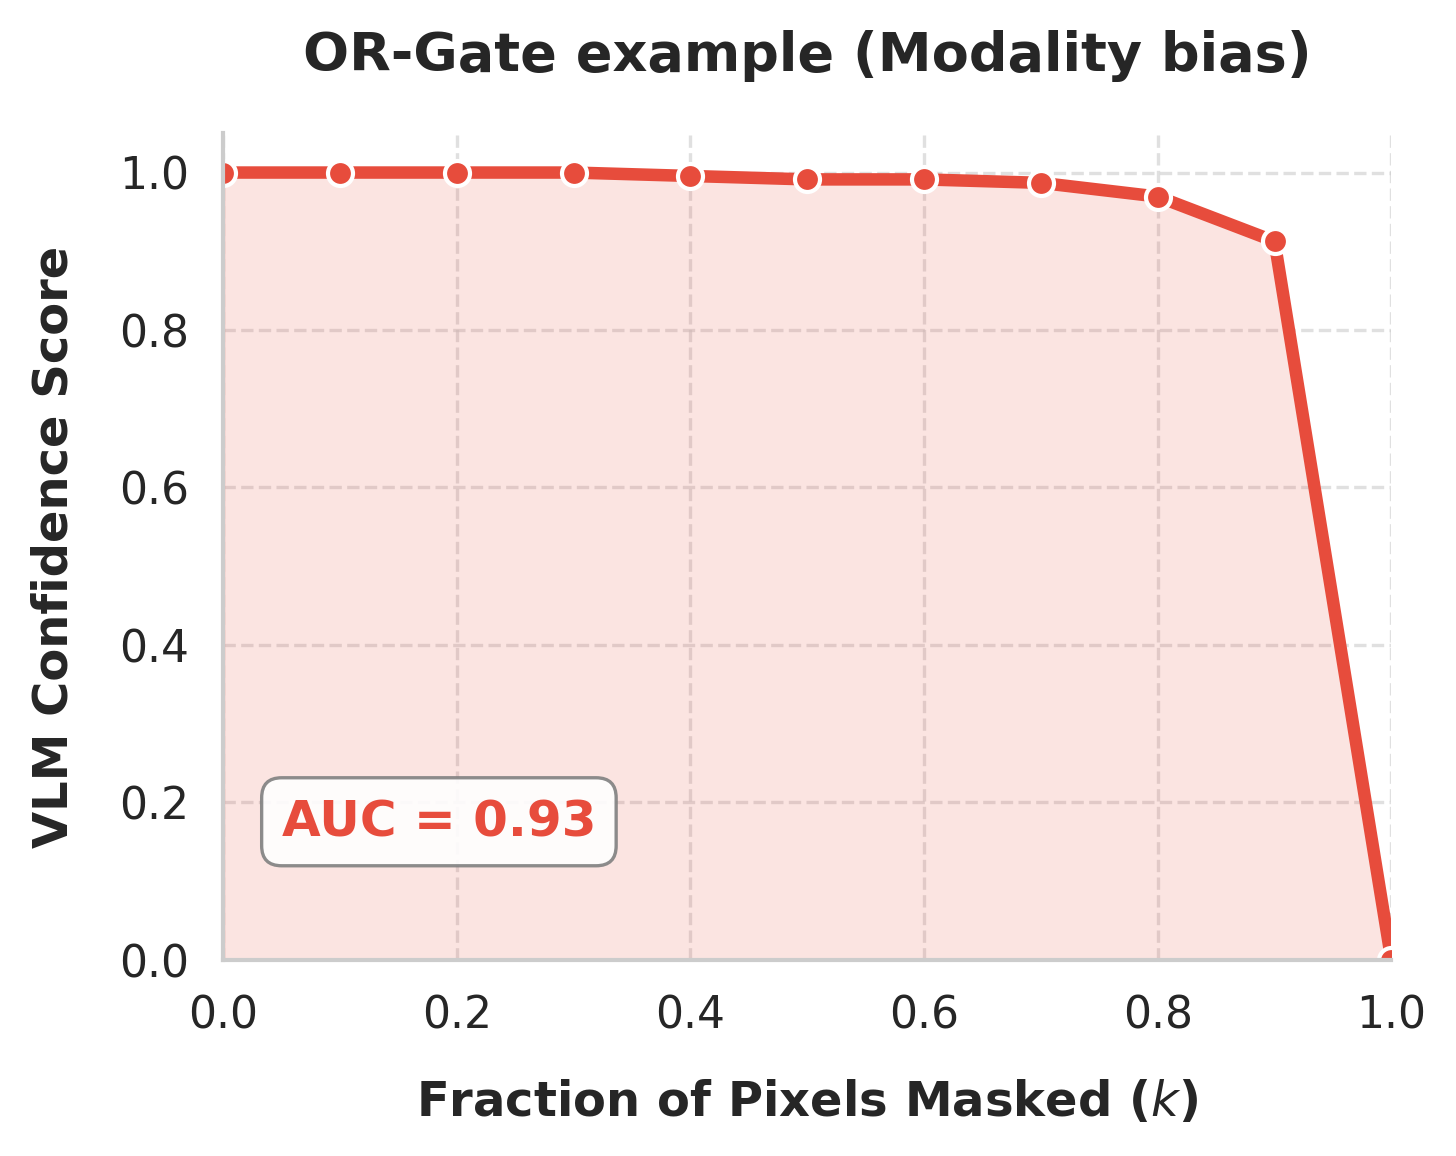

In [116]:
# Mock data for the x-axis (e.g., 10 discrete steps from 0 to 1)
k_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

# Mock OR-Gate (Confidence stays near 1.0)
# sample_idx 57
or_scores = [1.0, 1.0, 1.0, 1.0, 0.9956379532814026, 0.9912759065628052,
             0.9912759065628052, 0.9869138598442078, 0.9694656729698181,
             0.912759006023407, 0.0]
plot_unimodal_deletion_curve(k_steps, or_scores, auc_val=0.934, curve_type='OR-gate',
                             savefig=True, format="pdf")

# # Mock AND-Gate (Confidence crashes immediately)
# and_scores = [1.0, 0.40, 0.10, 0.05, 0.02, 0.01, 0.00, 0.00, 0.00, 0.00, 0.00]
# plot_unimodal_deletion_curve(k_steps, and_scores, auc_val=0.15, curve_type='AND-gate')

[*] Saved figure to ../figs/deletion_curve_and_gate.pdf


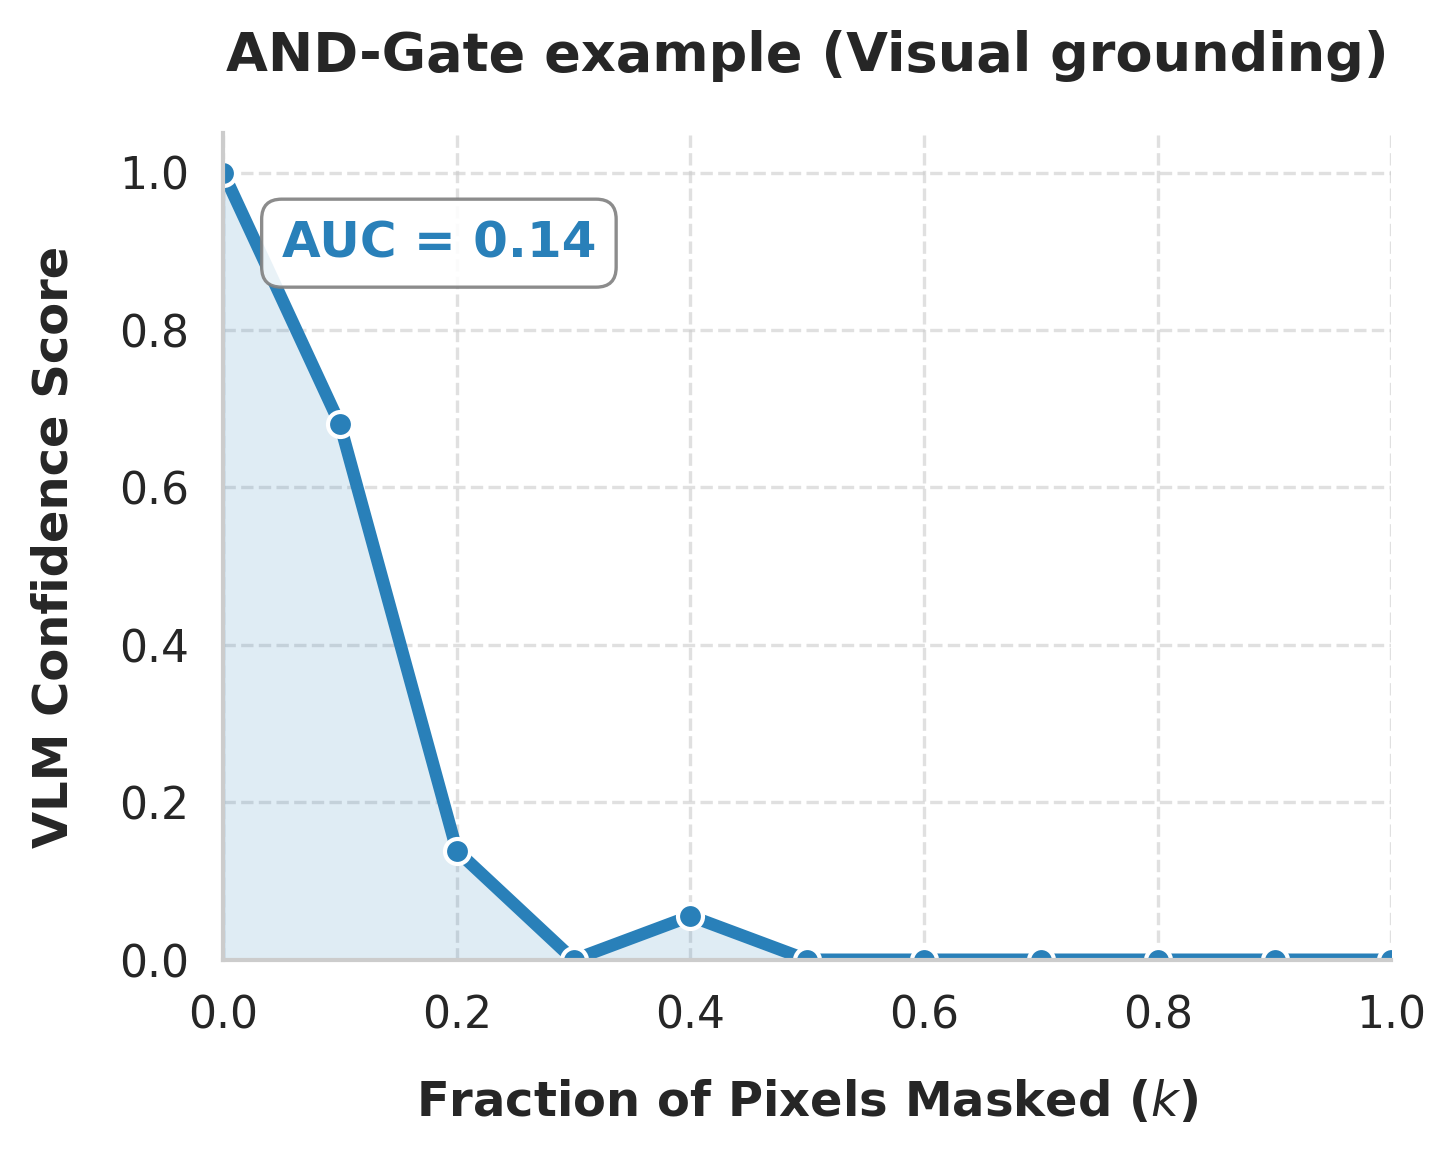

In [117]:
# sample_idx 127
and_scores = [1.0, 0.6800000071525574, 0.13846154510974884, 0.0,
              0.05538461357355118, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
plot_unimodal_deletion_curve(k_steps, and_scores, auc_val=0.14,
                            curve_type='AND-gate', savefig=True, format="pdf")

#### Qualitative plots

In [9]:
salience_traps, \
    contradictions, \
        failures = mine_qualitative_archetypes(df, 
                                            #    f_syn_col="syn_synergy_norm_auc",
                                            #    mui_col="img_srg_norm",
                                            #    mut_col="tok_srg_norm",
                                               )

--- Mining Qualitative Examples for the Appendix ---

[*] Found 20 'Visual Salience Trap' candidates.
Top Candidate:
      sample_idx   Dataset     Model  \
1230         118  cv_bench  internvl   

                                               question  
1230  How many scarfs are in the image? Select from ...  

[*] Found 94 'Unimodal Contradiction' candidates.
Top Candidate:
     sample_idx Dataset     Model  \
111          11  mmstar  internvl   

                                              question  
111  What is the dominant feature in the image?\nOp...  

[*] Found 1612 'Universal Failure' candidates.
Top Candidate:
   sample_idx Dataset     Model  \
2           0  mmstar  internvl   

                                            question  
2  Which option describe the object relationship ...  


In [10]:
salience_traps

,sample_idx,Dataset,Model,question,label,img_srg_norm_AttnLRP,img_srg_norm_GradCAM,img_srg_norm_GradxRollout,img_srg_norm_InputxGradients,img_srg_norm_IntegratedGradients,...,syn_synergy_norm_auc_TAM,tok_srg_norm_AttnLRP,tok_srg_norm_GradCAM,tok_srg_norm_GradxRollout,tok_srg_norm_InputxGradients,tok_srg_norm_IntegratedGradients,tok_srg_norm_LLaVACAM,tok_srg_norm_Random,tok_srg_norm_Rollout,tok_srg_norm_TAM
1230,118,cv_bench,internvl,How many scarfs are in the image? Select from ...,(B),0.260000,0.206667,0.263889,0.480556,0.143333,...,0.089245,0.347134,0.122938,0.204243,0.005382,0.021237,0.000942,-0.010017,0.249571,0.113035
2368,224,mmstar,llava,Which one is the correct caption of this image...,D,0.068308,-0.493910,0.442154,0.047077,-0.023718,...,0.098666,0.265887,-0.175100,0.746273,0.246273,-0.054805,0.041173,-0.262154,0.523135,0.230190
4813,454,repope_all,internvl,Is there a person in the image?,yes,0.067950,-0.634573,0.017684,0.004329,0.075877,...,0.027195,0.374353,0.207727,0.168616,-0.033680,0.205245,0.043108,-0.237732,0.223062,-0.069702
5439,512,mmstar,llava,Hint: Please answer the question and provide t...,D,0.053846,-0.015625,-0.153846,0.184615,0.257812,...,0.066257,0.706417,-0.181184,0.182363,0.172057,0.167772,-0.063350,0.111995,0.460773,0.226766
6172,581,cv_bench,internvl,Considering the relative positions of the buil...,(A),0.384946,0.449462,0.566667,0.216129,0.292473,...,0.096069,0.118710,-0.013767,0.502122,-0.039049,0.189480,-0.139336,0.084020,-0.041536,-0.059874
6329,595,repope_all,internvl,Is there a person in the image?,yes,0.156249,0.175155,0.102772,-0.113171,0.160290,...,0.094143,0.407781,0.088202,0.165307,0.134589,0.280546,0.020118,-0.198838,0.203674,0.007465
6883,647,mmstar,llava,Which solution has a higher concentration of b...,C,-0.129167,-0.462500,-0.635294,-0.058824,-0.306250,...,0.026029,0.790437,-0.125700,0.570843,-0.255602,0.078771,-0.030000,0.012651,0.522831,0.116627
8752,822,mmstar,internvl,Hint: Please answer the question and provide t...,C,-0.034556,0.416026,0.230407,-0.010081,0.011430,...,0.017304,-0.118826,0.000045,0.368123,-0.100354,0.000783,-0.000091,-0.071234,-0.051479,-0.296592
11170,1047,repope_all,internvl,Is there a chair in the image?,yes,0.000870,-0.143028,-0.209346,-0.128389,0.033923,...,0.077144,0.344724,0.164511,0.176787,0.216903,0.284700,0.156984,0.254656,0.205351,0.015182
12414,1164,cv_bench,llava,Considering the relative positions of the benc...,(A),-0.087943,0.266400,0.132800,-0.052000,0.001600,...,0.004170,0.049117,-0.692527,0.303125,-0.295241,-0.051956,-0.726084,-0.555763,0.049858,-0.191470


In [11]:
# contradictions[contradictions["Dataset"] == "repope_all"]
contradictions


,sample_idx,Dataset,Model,question,label,img_srg_norm_AttnLRP,img_srg_norm_GradCAM,img_srg_norm_GradxRollout,img_srg_norm_InputxGradients,img_srg_norm_IntegratedGradients,...,syn_synergy_norm_auc_TAM,tok_srg_norm_AttnLRP,tok_srg_norm_GradCAM,tok_srg_norm_GradxRollout,tok_srg_norm_InputxGradients,tok_srg_norm_IntegratedGradients,tok_srg_norm_LLaVACAM,tok_srg_norm_Random,tok_srg_norm_Rollout,tok_srg_norm_TAM
111,11,mmstar,internvl,What is the dominant feature in the image?\nOp...,D,0.258173,0.099532,0.147716,0.533271,0.067994,...,0.389500,0.492060,0.232559,0.250447,-0.457922,0.168634,0.054817,0.073789,-0.111341,0.179948
121,12,mmstar,internvl,What is the main focus of this image?\nOptions...,A,0.332866,-0.352486,0.082265,0.585822,0.097921,...,0.566306,0.622540,0.122087,0.399072,-0.171546,-0.319034,-0.081159,-0.288736,-0.068084,0.293823
193,19,cv_bench,internvl,How many light switchs are in the image? Selec...,(A),0.468293,0.491463,-0.044737,0.640789,-0.135366,...,0.148067,0.440884,-0.038930,0.345044,-0.198171,0.056437,-0.112950,0.072489,0.280058,0.227214
215,21,mmstar,internvl,What is the overall theme of this image?\nOpti...,B,0.234995,0.073897,0.146554,0.623871,-0.290595,...,0.482210,0.677617,-0.133239,0.160053,-0.312423,-0.123505,0.130816,-0.371025,-0.096160,0.206745
340,33,mmstar,internvl,What kind of environment is depicted in the im...,A,0.703030,-0.576061,0.891781,0.510959,-0.356667,...,0.299767,0.416336,-0.174914,0.590913,-0.315528,0.325486,-0.206827,-0.257919,0.161601,0.393088
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33669,4362,repope_all,internvl,Is there a chair in the image?,no,0.596324,-0.025000,-0.198013,0.507285,0.600000,...,0.000411,-0.573019,0.099660,-0.097372,-0.592385,-0.299230,-0.097949,0.384393,0.100048,0.193550
33784,4385,repope_all,internvl,Is there a chair in the image?,no,0.024390,-0.303659,-0.028788,0.516667,0.064634,...,0.000615,-0.521856,-0.165997,0.097534,-0.501361,-0.200003,-0.113792,0.393348,0.100000,0.295149
33904,4409,repope_all,internvl,Is there a chair in the image?,no,0.129032,-0.158065,0.004878,0.570732,0.103226,...,0.000492,0.262493,-0.386821,-0.096891,-0.492379,-0.319810,-0.483838,0.392832,0.099219,0.204133
34670,4563,repope_all,internvl,Is there a chair in the image?,no,0.500685,0.149315,0.338065,0.562581,0.436301,...,0.002783,0.050433,-0.010984,0.209307,-0.356267,0.354940,-0.002422,-0.306006,0.059237,-0.101119


In [12]:
# failures[failures["Dataset"] == "mmstar"]
failures

,sample_idx,Dataset,Model,question,label,img_srg_norm_AttnLRP,img_srg_norm_GradCAM,img_srg_norm_GradxRollout,img_srg_norm_InputxGradients,img_srg_norm_IntegratedGradients,...,syn_synergy_norm_auc_TAM,tok_srg_norm_AttnLRP,tok_srg_norm_GradCAM,tok_srg_norm_GradxRollout,tok_srg_norm_InputxGradients,tok_srg_norm_IntegratedGradients,tok_srg_norm_LLaVACAM,tok_srg_norm_Random,tok_srg_norm_Rollout,tok_srg_norm_TAM
2,0,mmstar,internvl,Which option describe the object relationship ...,A,-1.121212e-01,-2.727272e-02,0.294737,9.736843e-02,5.454546e-02,...,0.041472,0.597946,0.010538,0.498269,-0.217426,0.091910,-0.132412,-0.106252,-0.250952,0.250644
4,0,mmstar,qwenvl,Which option describe the object relationship ...,A,-1.387779e-17,-1.387779e-17,0.020270,-1.387779e-17,-1.387779e-17,...,0.035374,0.184971,-0.315054,0.519364,0.270089,0.332337,0.163263,-0.057235,-0.082136,-0.011094
22,2,mmstar,llava,What seems to be the theme of the image?\nOpti...,D,2.398205e-02,-8.121816e-01,0.439866,1.640600e-02,1.261267e-01,...,0.003071,0.658016,0.255227,0.469222,-0.080258,0.358094,0.126972,-0.233632,-0.122596,0.056568
42,4,mmstar,llava,What is the center of focus in the image?\nOpt...,A,5.571429e-02,4.310078e-01,-0.050775,-3.643412e-02,-2.519379e-02,...,0.000197,0.470514,-0.087246,0.666929,0.048209,-0.809956,0.010359,-0.100789,0.404180,-0.665331
51,5,mmstar,llava,What is the main subject of the flyer seen in ...,D,4.421052e-02,3.422680e-01,-0.620213,3.361702e-01,-5.051546e-02,...,0.003377,0.358830,-0.390828,0.087004,-0.165843,0.001479,-0.389212,-0.147132,-0.552387,-0.419439
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16007,1496,mmstar,llava,Which label applies to stomach?\nOptions: A: B...,C,1.706897e-01,2.527027e-01,0.089189,1.445946e-01,1.040541e-01,...,0.011518,-0.011325,0.217524,0.135342,-0.024040,0.120216,-0.020279,-0.003701,0.118876,-0.010951
16019,1497,mmstar,qwenvl,Which stage represents the adult alligator?\nO...,C,-1.816902e-02,1.084507e-01,-0.004930,-3.985914e-02,6.154929e-02,...,0.044293,-0.074939,0.186884,0.190533,0.057438,0.257042,0.062667,0.038518,0.249662,-0.018096
16029,1498,mmstar,llava,Think about the magnetic force between the mag...,C,1.562500e-02,9.473682e-02,0.587500,6.875000e-02,-8.421053e-02,...,0.000694,0.491082,0.257915,0.264389,-0.115719,0.115786,0.207842,-0.374504,-0.206689,0.203760
16030,1498,mmstar,qwenvl,Think about the magnetic force between the mag...,C,2.076126e-02,1.287197e-01,-0.013115,1.344262e-02,2.837370e-02,...,0.005521,-0.240652,-0.490162,0.409061,-0.082537,0.084592,-0.621094,-0.435019,-0.195574,0.257691


In [25]:
df.describe()

,sample_idx,syn_synergy_norm_auc,tok_srg_norm,img_srg_norm
count,236133.000000,236133.000000,236133.000000,236133.000000
mean,1815.022983,0.088855,0.076112,0.015273
std,1289.383543,0.119969,0.354140,0.194943
min,0.000000,0.000000,-0.900000,-0.900000
25%,761.000000,0.008655,-0.100572,-0.053731
50%,1515.000000,0.031897,0.095219,0.002239
75%,2609.000000,0.122581,0.298414,0.077443
max,4778.000000,0.794834,0.900000,0.900000


### Synergy metric

#### Correlation computation and speed up

In [118]:
SAVE_DIR = "../figs/"

In [179]:
import json
import glob
import os
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

def load_and_preprocess_data(results_file):
    """Loads JSONL data and computes the necessary AUC columns."""
    data = []
    with open(results_file, 'r') as f:
        for line in f:
            data.append(json.loads(line.strip()))
            
    df = pd.DataFrame(data)

    pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    
    # Compute AUCs if they don't exist
    for col in ['syn_del', 'syn_ins', 'syn_del_norm', 'syn_ins_norm']:
        curve_col = f'{col}_synergy_curve'
        auc_col = f'{col}_auc'
        if auc_col not in df.columns and curve_col in df.columns:
            df[auc_col] = df[curve_col].apply(lambda val: np.trapezoid(val, x=pert_steps))

    # Calculate the unnormalized synergy
    if 'syn_ins_auc' in df.columns and 'syn_del_auc' in df.columns:
        df['synergy_srg_unorm'] = (df["syn_ins_auc"] + df["syn_del_auc"]) / 2.0
        
    return df

def load_all_correlation_data(base_dir="logs/correlation",
                            #dataset_name="repope_all"
                            ):
    """
    Crawls the directory structure to load all JSONL files, 
    automatically extracting the Model and Dataset from folder names.
    """
    all_data = []
    # Adjust this glob pattern based on your actual folder structure!
    # e.g., logs/llava/pope/ig_results.jsonl
    search_pattern = os.path.join(base_dir, "*", "*", "*.jsonl")
    file_list = glob.glob(search_pattern)
    
    print(f"[*] Found {len(file_list)} result files. Aggregating...")
    
    for file_path in file_list:
        # Extract metadata from the path 
        # (e.g., parts[-3] = model, parts[-2] = dataset)
        path_parts = os.path.normpath(file_path).split(os.sep)
        if len(path_parts) >= 3:
            model_name = path_parts[-3]
            dataset_name = path_parts[-2]
        else:
            model_name, dataset_name = "Unknown", "Unknown"
        
        
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    try:
                        row = json.loads(line)
                        # Ensure we don't overwrite if the JSON already has it
                        row['Model'] = row.get('model', model_name)
                        row['Dataset'] = row.get('dataset', dataset_name)
                        # Ensure explainer name is clean
                        row['Explainer'] = row.get('explainer', os.path.basename(file_path).replace('.jsonl', '').split('_')[3])
                        all_data.append(row)
                    except json.JSONDecodeError:
                        continue
                    
    df = pd.DataFrame(all_data)
    df['Explainer'] = df["Explainer"].replace('Lxt', 'AttnLRP')
    pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

    cols_to_drop = ['final_alignment', 'final_true_syn', 'synergy_refined_srg', 
       'final_redundancy', 'standard_srg']
    df = df.drop(cols_to_drop, axis=1)
    
    # Compute AUCs if they don't exist
    for col in ['syn_del', 'syn_ins', 'syn_del_norm', 'syn_ins_norm']:
        curve_col = f'{col}_synergy_curve'
        auc_col = f'{col}_auc'
        if auc_col not in df.columns and curve_col in df.columns:
            df[auc_col] = df[curve_col].apply(lambda val: np.trapezoid(val, x=pert_steps))

    # Calculate the unnormalized synergy
    if 'syn_ins_auc' in df.columns and 'syn_del_auc' in df.columns:
        df['synergy_srg_unorm'] = (df["syn_ins_auc"] + df["syn_del_auc"]) / 2.0

    
    # Optional: Calculate combined AUPC metrics if you saved curves instead of raw AUCs
    # ... (Insert your trapezoid np.trapezoid code here if needed) ...
    
    return df

def analyze_and_plot_correlation(df, x_col, y_col, x_label=None, y_label=None, title=None, save_path=None):
    """
    Cleans data, computes correlation statistics, prints a report, and generates a paper-ready plot.
    """
    # 1. Clean Data: Drop rows where either metric is NaN
    clean_df = df.dropna(subset=[x_col, y_col]).copy()
    
    if len(clean_df) == 0:
        print(f"[!] Cannot analyze {x_col} vs {y_col}: No valid overlapping data points.")
        return

    # 2. Compute Correlations
    pearson_r, p_val_p = stats.pearsonr(clean_df[x_col], clean_df[y_col])
    spearman_rho, p_val_s = stats.spearmanr(clean_df[x_col], clean_df[y_col])

    # 3. Print Report
    print("\n" + "="*50)
    print(f"      XAI METRIC VALIDATION: {x_col} vs {y_col}")
    print("="*50)
    print(f"Total Samples Analyzed : {len(clean_df)}")
    print(f"Metric X ({x_col}) Mean : {clean_df[x_col].mean():.4f} ± {clean_df[x_col].std():.4f}")
    print(f"Metric Y ({y_col}) Mean : {clean_df[y_col].mean():.4f} ± {clean_df[y_col].std():.4f}")
    print("\n--- Correlation ---")
    print(f"Pearson r      : {pearson_r:.4f}  (p-value: {p_val_p:.2e})")
    print(f"Spearman rho   : {spearman_rho:.4f}  (p-value: {p_val_s:.2e})")
    print("="*50)

    # 4. Generate Publication-Ready Plot
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.figure(figsize=(8, 6))
    
    ax = sns.regplot(
        x=x_col, y=y_col, data=clean_df, 
        scatter_kws={'alpha': 0.6, 'color': '#2C3E50'}, 
        line_kws={'color': '#E74C3C', 'linewidth': 2}
    )
    
    # Use provided labels or default to column names
    plt.title(title or f'Validation: {x_col} vs {y_col}', fontsize=14, weight='bold')
    plt.xlabel(x_label or x_col, fontsize=12)
    plt.ylabel(y_label or y_col, fontsize=12)

    # Add Stats Box
    textstr = f"Spearman $\\rho$ = {spearman_rho:.3f}\nPearson $r$ = {pearson_r:.3f}"
    props = dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray')
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12,
            verticalalignment='top', bbox=props)

    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"[*] Plot saved to {save_path}")
    
    plt.show() # Display the plot
    plt.close()


In [180]:
df = load_all_correlation_data(base_dir="../logs/correlation")

[*] Found 12 result files. Aggregating...


In [181]:
df.Model.unique()

array(['qwenvl', 'llava', 'internvl'], dtype=object)

In [182]:
df.columns

Index(['sample_idx', 'image_id', 'question', 'label', 'prediction', 'time_sii',
       'sii_auc', 'sii_curve', 'time_syn', 'syn_del_synergy_curve',
       'syn_ins_synergy_curve', 'syn_ins_norm_synergy_curve',
       'syn_del_norm_synergy_curve', 'synergy_srg', 'Model', 'Dataset',
       'Explainer', 'syn_del_auc', 'syn_ins_auc', 'syn_del_norm_auc',
       'syn_ins_norm_auc', 'synergy_srg_unorm'],
      dtype='object')

In [121]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import numpy as np
import matplotlib.patches as mpatches


def plot_correlation_scatter(df, x_col='sii_auc', y_col='synergy_srg',
                            savefig=False, format='pdf',
                            save_path="correlation_scatter"):

    print(f"--- Generating 2x2 Correlation Subplots (Hued by Model) ---")
    
    # 1. Drop NaNs and extract necessary columns
    plot_df = df[[x_col, y_col, 'Explainer', 'Model']].dropna()
    
    # Specify the 4 explainers you want to plot
    target_explainers = ['Random', 'InputxGradients', 'Rollout', 'TAM']
    plot_df = plot_df[plot_df['Explainer'].isin(target_explainers)]

    # --- NEW: Calculate Global Correlation across ALL included points ---
    global_spearman, _ = stats.spearmanr(plot_df[x_col], plot_df[y_col])
    global_pearson, _ = stats.pearsonr(plot_df[x_col], plot_df[y_col])
    
    # 2. Setup a 2x2 grid sharing both axes
    fig, axes = plt.subplots(2, 2, figsize=(8, 8), dpi=300, sharex=True, sharey=True)
    
    # Define a clean color palette for the models (adjust n_colors if you have more than 3 models)
    model_palette = sns.color_palette('Set1', n_colors=plot_df['Model'].nunique())
    
    for ax, explainer in zip(axes.flat, target_explainers):
        sub_df = plot_df[plot_df['Explainer'] == explainer]
        
        # 3. Scatter Plot with HUE per Model
        sns.scatterplot(
            data=sub_df,
            x=x_col,
            y=y_col,
            hue='Model',
            palette=model_palette,
            alpha=0.8,
            edgecolor='black',
            linewidth=0.5,
            s=20,
            ax=ax,
            legend=False # We will create one global legend later!
        )
        
        # 4. Global Line of Best Fit for this explainer (regardless of model)
        if len(sub_df) > 1:
            m, b = np.polyfit(sub_df[x_col], sub_df[y_col], 1)
            x_range = np.linspace(sub_df[x_col].min(), sub_df[x_col].max(), 100)
            ax.plot(x_range, m*x_range + b, color='black', linestyle='--', linewidth=2, alpha=0.7)
            
            # Calculate Correlations
            spearman_rho, _ = stats.spearmanr(sub_df[x_col], sub_df[y_col])
            pearson_r, _ = stats.pearsonr(sub_df[x_col], sub_df[y_col])
            
            # Add the text box inside the subplot
            stats_text = f"$\\rho$ = {spearman_rho:.2f}\n$r$ = {pearson_r:.2f}"
            props = dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray')
            ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=11,
                    verticalalignment='top', bbox=props, fontweight='bold')
        
        # 5. Subplot Formatting
        ax.set_title(f"Explainer: {explainer}", fontsize=12, fontweight='bold')
        ax.set_xlabel("") # Clear individual labels, we will use global ones
        ax.set_ylabel("")
        ax.grid(True, linestyle=':', alpha=0.6)
        
    # 6. Global Labels and Legend
    fig.supxlabel('Exact Shapley Interaction Index (SII)', fontsize=14, fontweight='bold')
    fig.supylabel(r'Proposed Synergistic Faithfulness ($\mathcal{F}_{syn}$)', fontsize=14, fontweight='bold')

    # --- NEW: Add the Global Title ---
    global_title = f"Global Correlation with Exact Shapley ($\\rho$ = {global_spearman:.2f}; $\\tau$ = {global_pearson:.2f})"
    fig.suptitle(global_title, fontsize=14, fontweight='bold', y=1.06)
    
    # Extract legend handles from a dummy plot to create a single global legend
    handles, labels = ax.get_legend_handles_labels()
    # If the standard handle extraction misses, create a dummy legend:
    legend_elements = [mpatches.Patch(color=color, label=model) 
                       for color, model in zip(model_palette, plot_df['Model'].unique())]
    
    fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.01), 
               ncol=plot_df['Model'].nunique(), title="VLM", 
               title_fontsize='12', fontsize='11', frameon=False)
    
    plt.tight_layout()
    # Adjust layout so the titles and labels don't overlap
    fig.subplots_adjust(bottom=0.08, left=0.08, top=0.90) 

    
    if savefig:
        save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(save_path, format=format, bbox_inches='tight')
        print(f"Saved figure to: {save_path}")
    plt.show()

# Run the plotting function!
# plot_correlation_scatter(df, x_col='sii_auc', y_col='synergy_srg')

--- Generating 2x2 Correlation Subplots (Hued by Model) ---
Saved figure to: ../figs/correlation_scatter.pdf


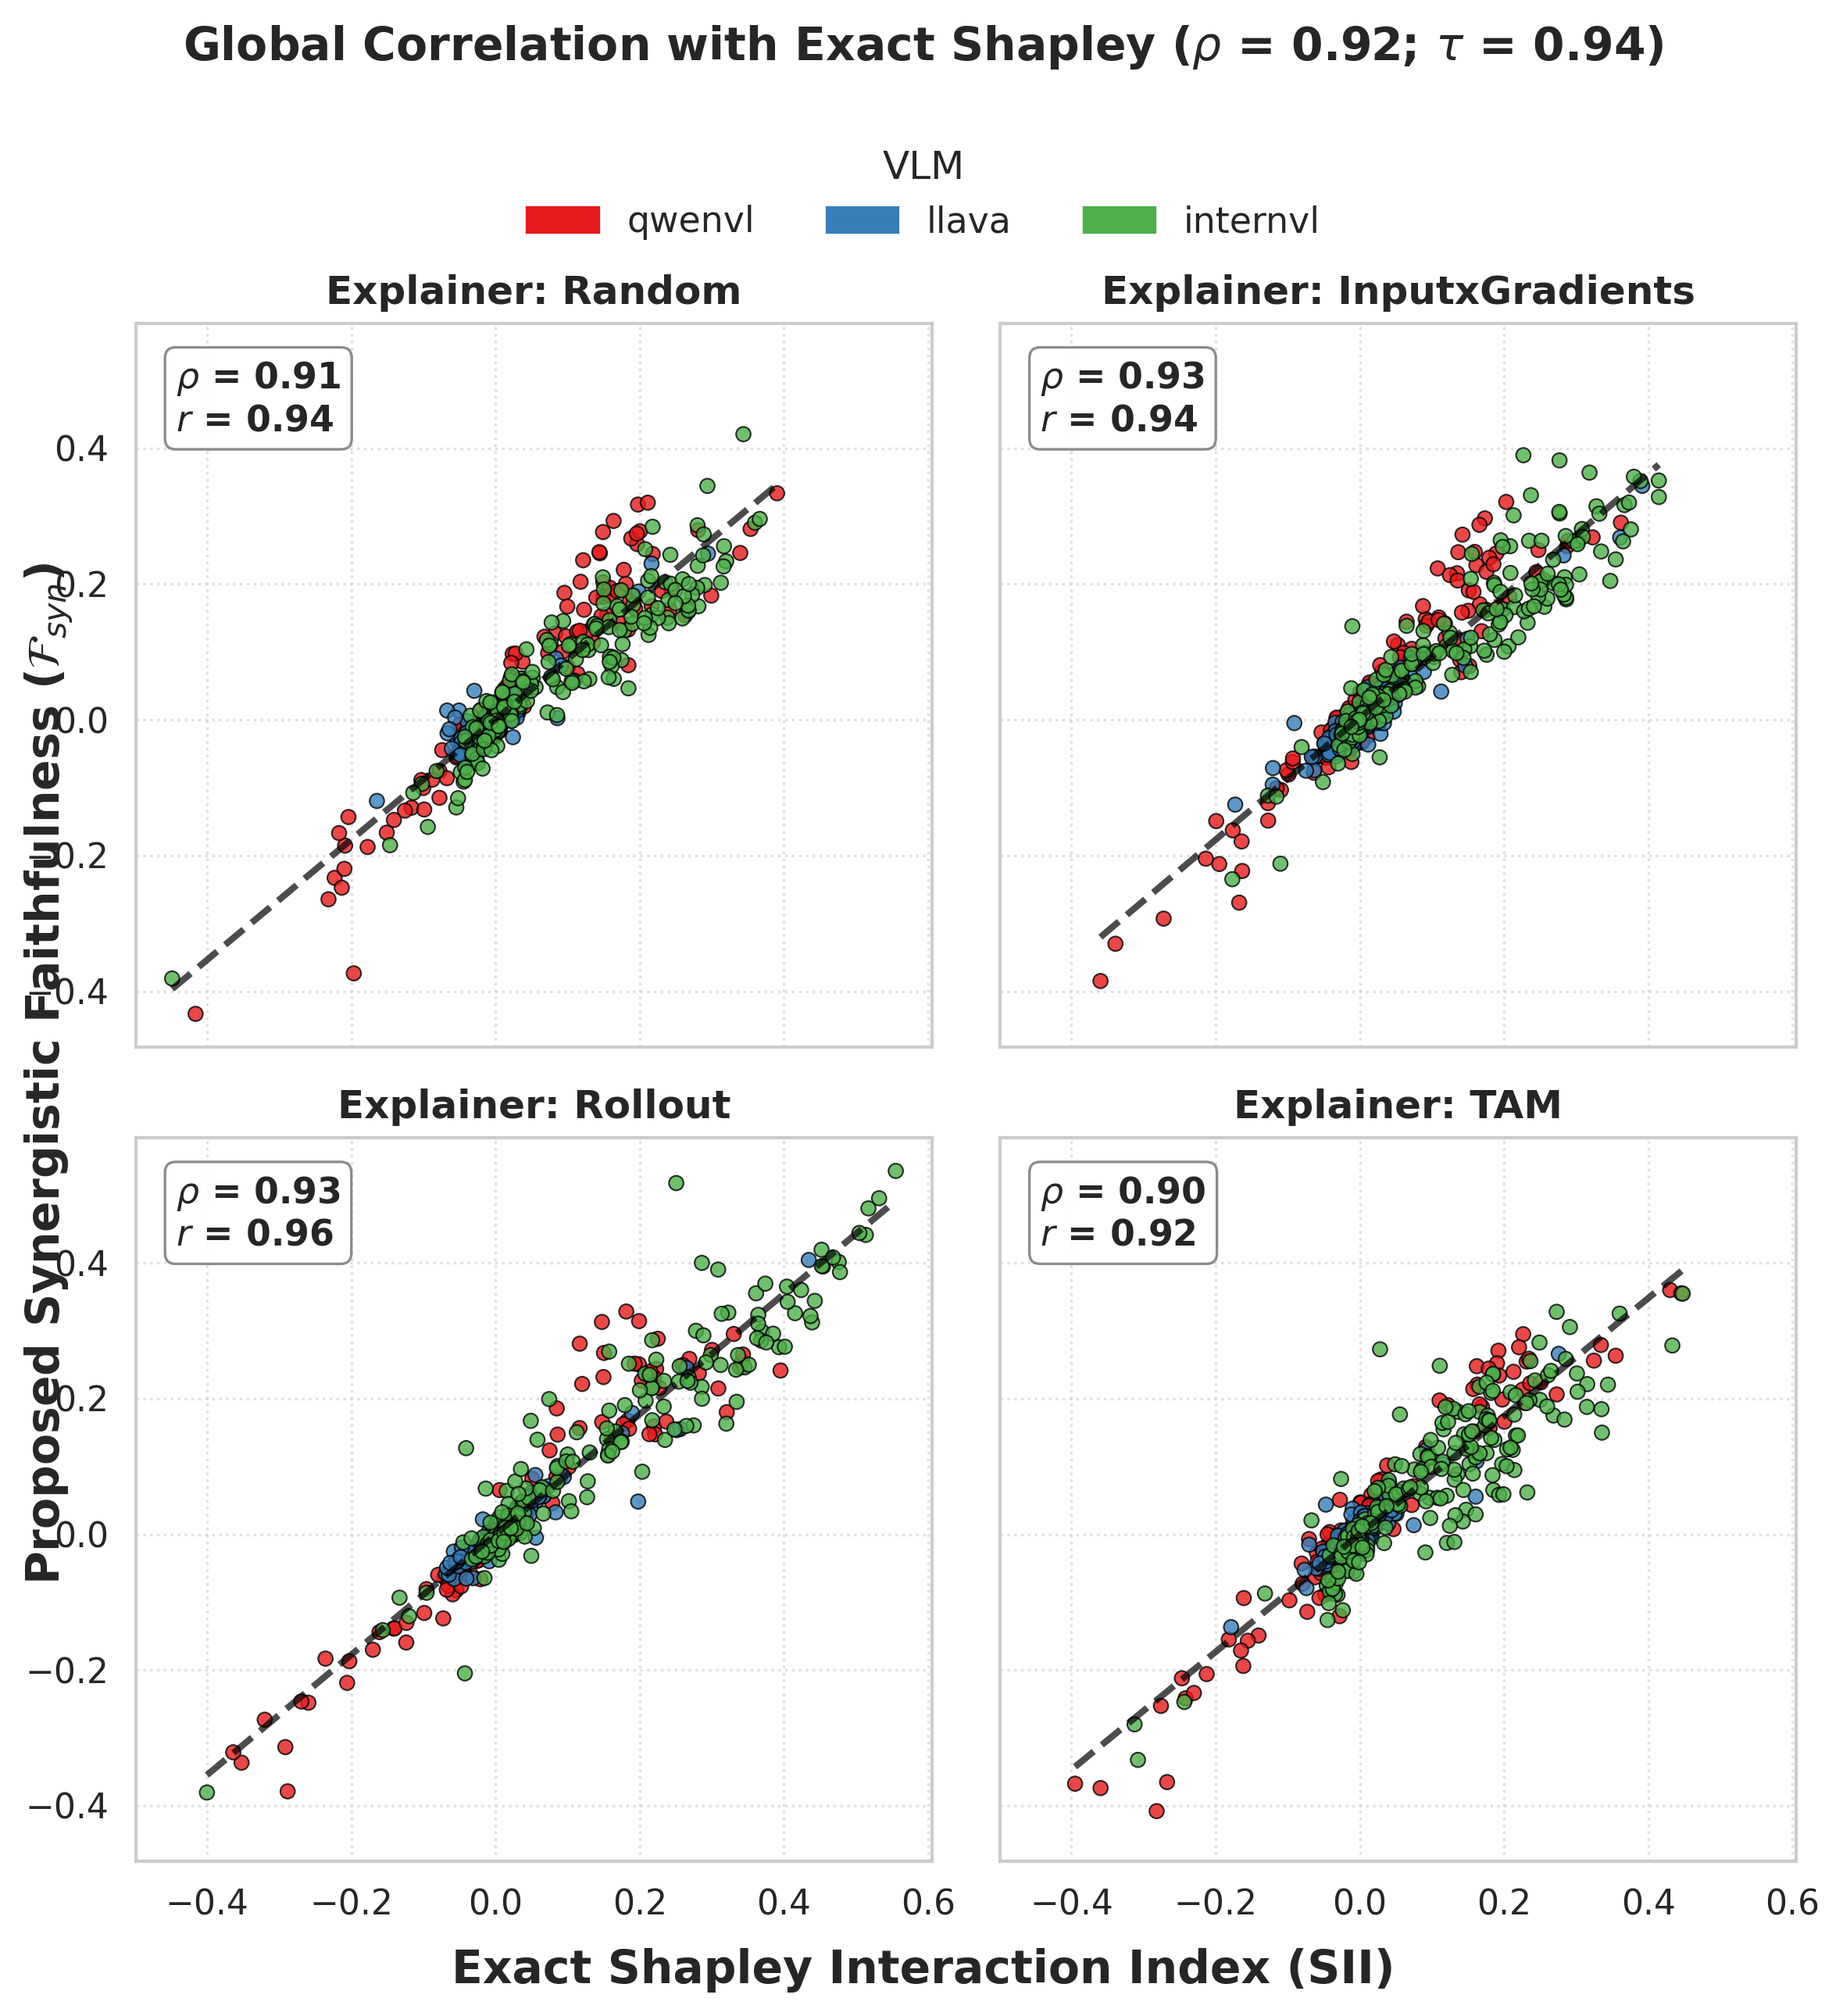

In [183]:
plot_correlation_scatter(df, x_col='sii_auc', y_col='synergy_srg_unorm',
                         savefig=True, format="pdf")

In [123]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_runtime_complexity(df, time_col='time_syn',
                            savefig=False, format='png',
                            save_path="runtime_complexity"):
    print("--- Generating 1x2 Runtime Complexity Figure ---")
    
    # Setup a 1x2 grid
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=300)
    
    # ==========================================
    # LEFT PANEL: Theoretical Forward Passes
    # ==========================================
    ax1 = axes[0]
    
    # Generate theoretical data (Sequence length vs Passes)
    # We stop at N=25 because 2^25 is already 33 million passes!
    tokens = np.arange(2, 25) 
    exact_sii_passes = 2**tokens
    
    # Your metric: 6K + 2. Assuming K=10, that's 62 passes.
    K = 10
    fsyn_passes = np.full_like(tokens, 6 * K + 2)
    
    ax1.plot(tokens, exact_sii_passes, color='#e74c3c', linewidth=2.5, label=r'Exact SII $\mathcal{O}(2^{N})$')
    ax1.plot(tokens, fsyn_passes, color='#2ecc71', linewidth=2.5, label=r'Proposed $\mathcal{F}_{{syn}}$ ($K={K}$)')
    
    # Use a Log Scale for the Y-axis because Exact SII explodes instantly
    ax1.set_yscale('log')
    ax1.set_xlabel('Total Sequence Length ($m + n$ tokens)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Number of Forward Passes (Log Scale)', fontsize=11, fontweight='bold')
    ax1.set_title('A. Theoretical Complexity', fontsize=12, fontweight='bold')
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper left')

    # ==========================================
    # RIGHT PANEL: Empirical Wall-Clock Time
    # ==========================================
    ax2 = axes[1]
    
    # Sort explainers by mean time so the bar chart looks clean
    mean_times = df.groupby('Explainer')[time_col].mean().sort_values()
    order = mean_times.index.tolist()
    
    # Create the barplot. Seaborn automatically calculates the 95% CI or std for error bars!
    sns.barplot(
        data=df, 
        x='Explainer', 
        y=time_col, 
        order=order,
        color='#3498db',
        edgecolor='black',
        err_kws={'linewidth': 1.5, 'color': 'black'},
        capsize=0.1,
        ax=ax2
    )
    
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right')
    ax2.set_xlabel('Explainer Method', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Average Evaluation Time (seconds)', fontsize=11, fontweight='bold')
    ax2.set_title('B. Empirical Wall-Clock Time per Instance', fontsize=12, fontweight='bold')
    ax2.grid(axis='y', linestyle=':', alpha=0.6)

    # Clean up spines
    for ax in axes:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    plt.tight_layout()
    if savefig:
        save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(save_path, format=format, bbox_inches='tight')
        print(f"Saved figure to: {save_path}")
    plt.show()


def plot_time_comparison(df, sii_col='time_sii', syn_col='time_syn',
                        savefig=False, format='png',
                        save_path="runtime_comparison_bars"):
    print("--- Generating Empirical Runtime Comparison Bar Plot ---")
    
    # 1. Filter the dataset
    # We only want to plot the rows where Exact SII was actually computed (the N=200 subset)
    plot_df = df.dropna(subset=[sii_col, syn_col]).copy()
    
    # Optional: If you only evaluated certain explainers for the exact SII, 
    # we can sort them so the chart looks organized.
    target_explainers = ['Random', 'InputxGradients', 'Rollout', 'TAM']
    plot_df = plot_df[plot_df['Explainer'].isin(target_explainers)]
    
    # 2. Reshape the DataFrame using melt()
    # This turns our two time columns into rows so Seaborn can plot them side-by-side
    melted_df = plot_df.melt(
        id_vars=['Explainer'],
        value_vars=[sii_col, syn_col],
        var_name='Method',
        value_name='Time_Seconds'
    )
    
    # Rename the variables so they look beautiful in the legend
    melted_df['Method'] = melted_df['Method'].replace({
        sii_col: 'Exact SII (Downsampled)',
        syn_col: r'$\mathcal{F}_{syn}$'
    })
    
    # 3. Setup the plot
    fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
    
    # Plot side-by-side bars with standard deviation error bars
    sns.barplot(
        data=melted_df,
        x='Explainer',
        y='Time_Seconds',
        hue='Method',
        palette=['#e74c3c', '#2ecc71'], # Red for Exact (bad/slow), Green for Proposed (good/fast)
        edgecolor='black',
        err_kws={'linewidth': 1.5, 'color': 'black'},
        capsize=0.1,
        ax=ax
    )
    
    # 4. Critical Formatting: Logarithmic Scale
    ax.set_yscale('log')
    
    # 5. Labels and Clean up
    ax.set_xlabel('Explainer method', fontsize=10, fontweight='bold')
    ax.set_ylabel('Execution time per instance (seconds) [Log Scale]', fontsize=10, fontweight='bold')
    ax.set_title(r'Empirical time: Exact SII vs. $\mathcal{F}_{syn}$', fontsize=12, fontweight='bold', pad=15)
    
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Move the legend outside or to a clean spot so it doesn't cover the bars
    ax.legend(title='Evaluation Method', title_fontsize='11', fontsize='10', loc='best')
    
    plt.tight_layout()

    if savefig:
        save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(save_path, format=format, bbox_inches='tight')
        print(f"Saved figure to: {save_path}")
    plt.show()

# Run the function!
# plot_time_comparison(df, sii_col='time_sii', syn_col='time_syn')

--- Generating 1x2 Runtime Complexity Figure ---


/tmp/ipykernel_2074886/2693573667.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right')


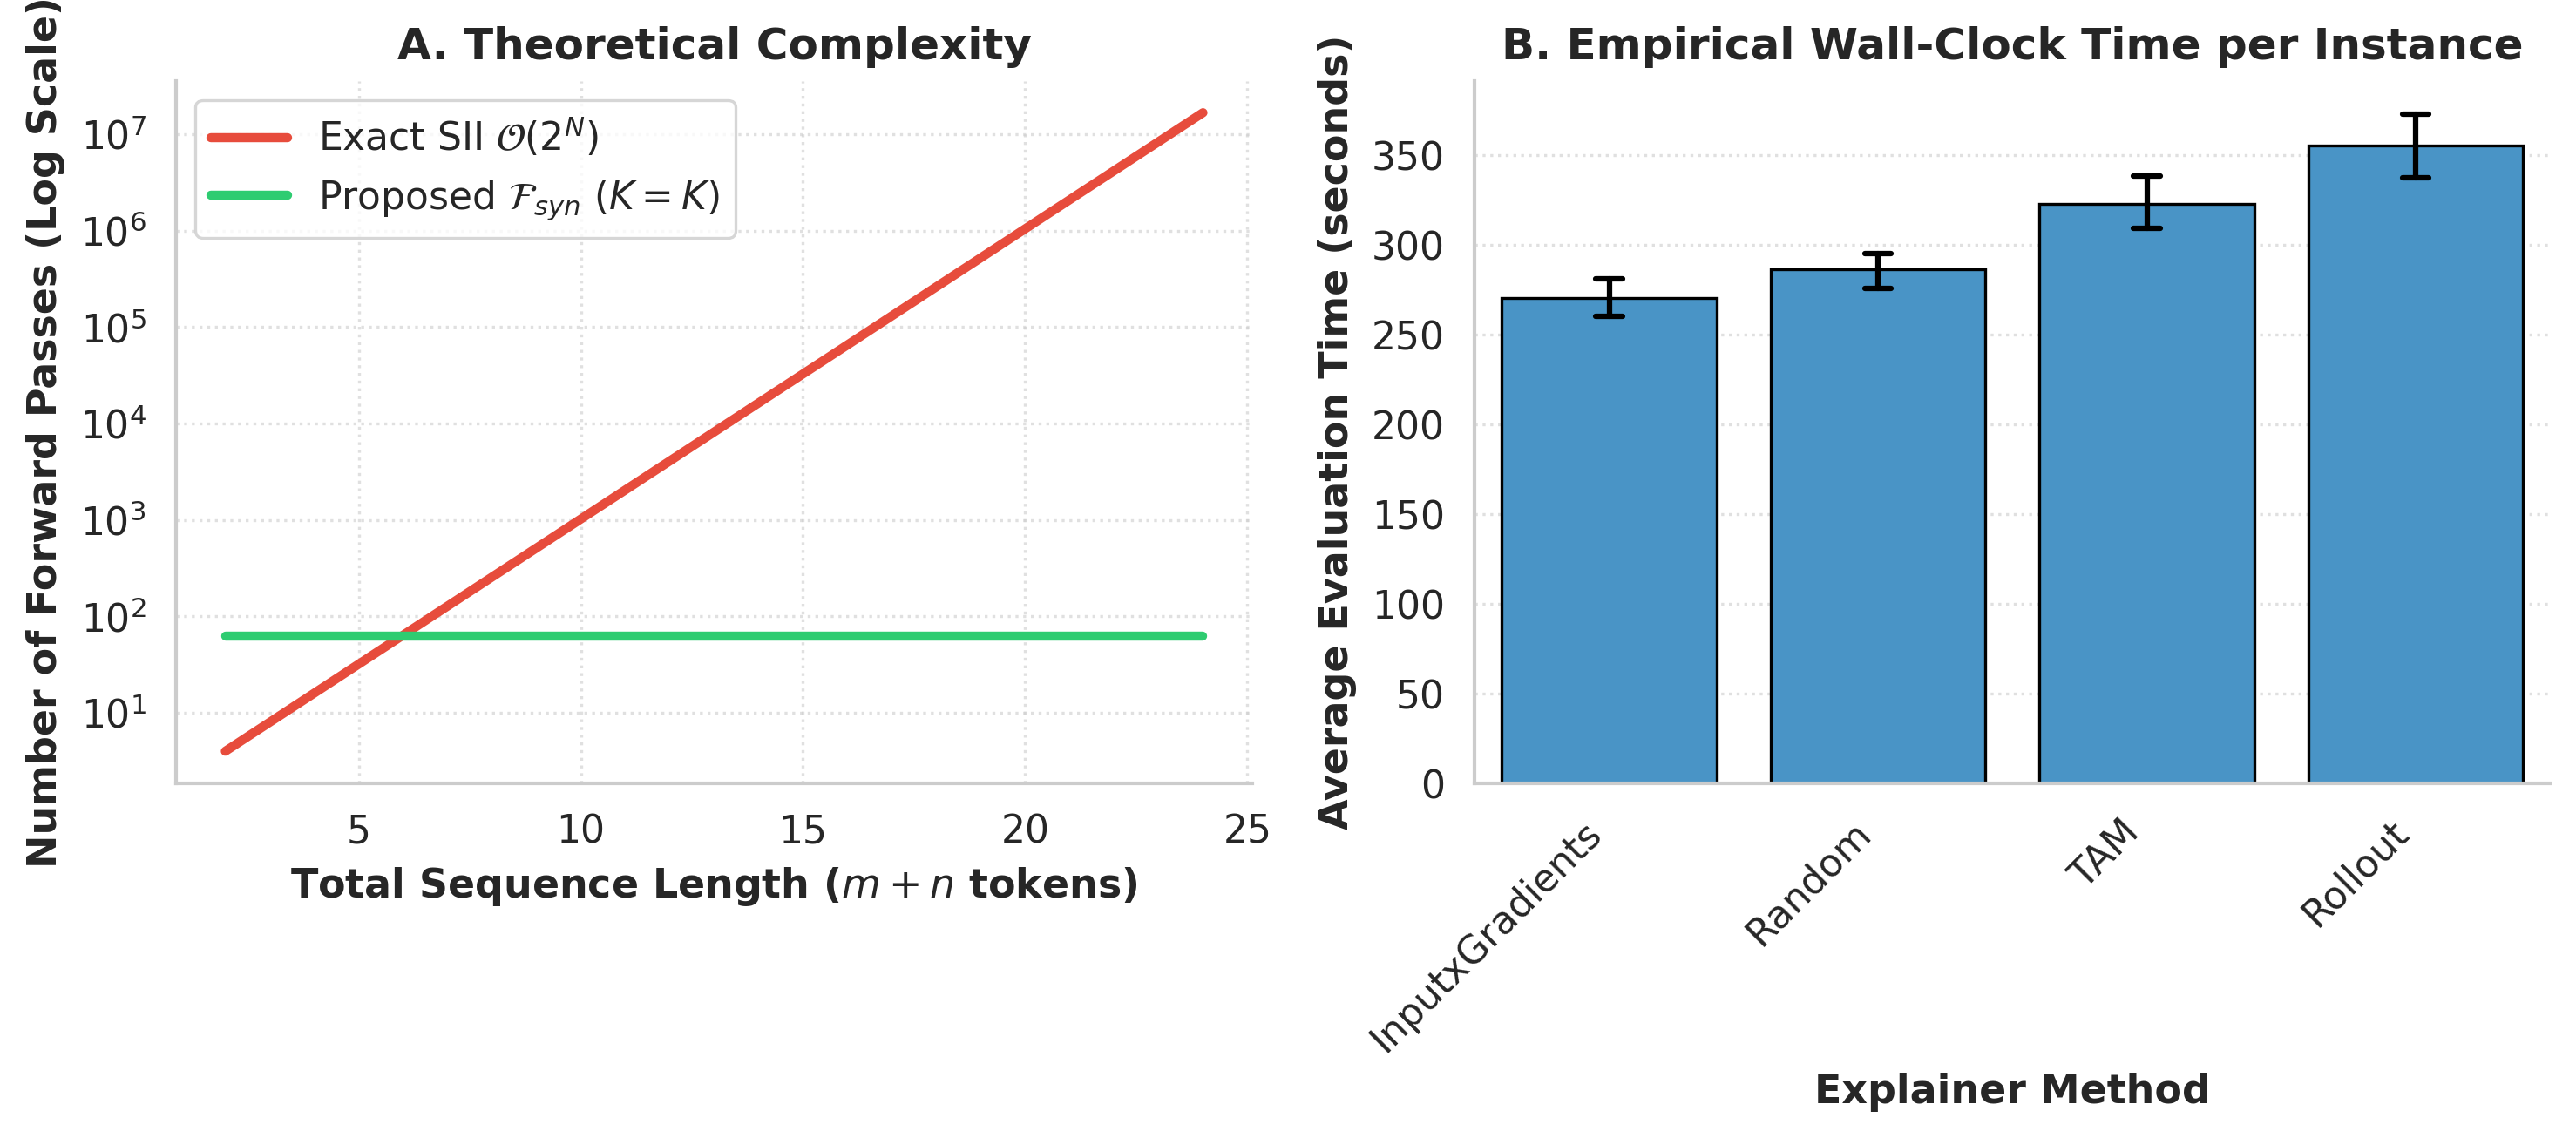

In [124]:
# Run it! (Replace 'time_syn' with your actual execution time column)
plot_runtime_complexity(df, time_col='time_sii')

--- Generating Empirical Runtime Comparison Bar Plot ---
Saved figure to: ../figs/runtime_comparison_bars.pdf


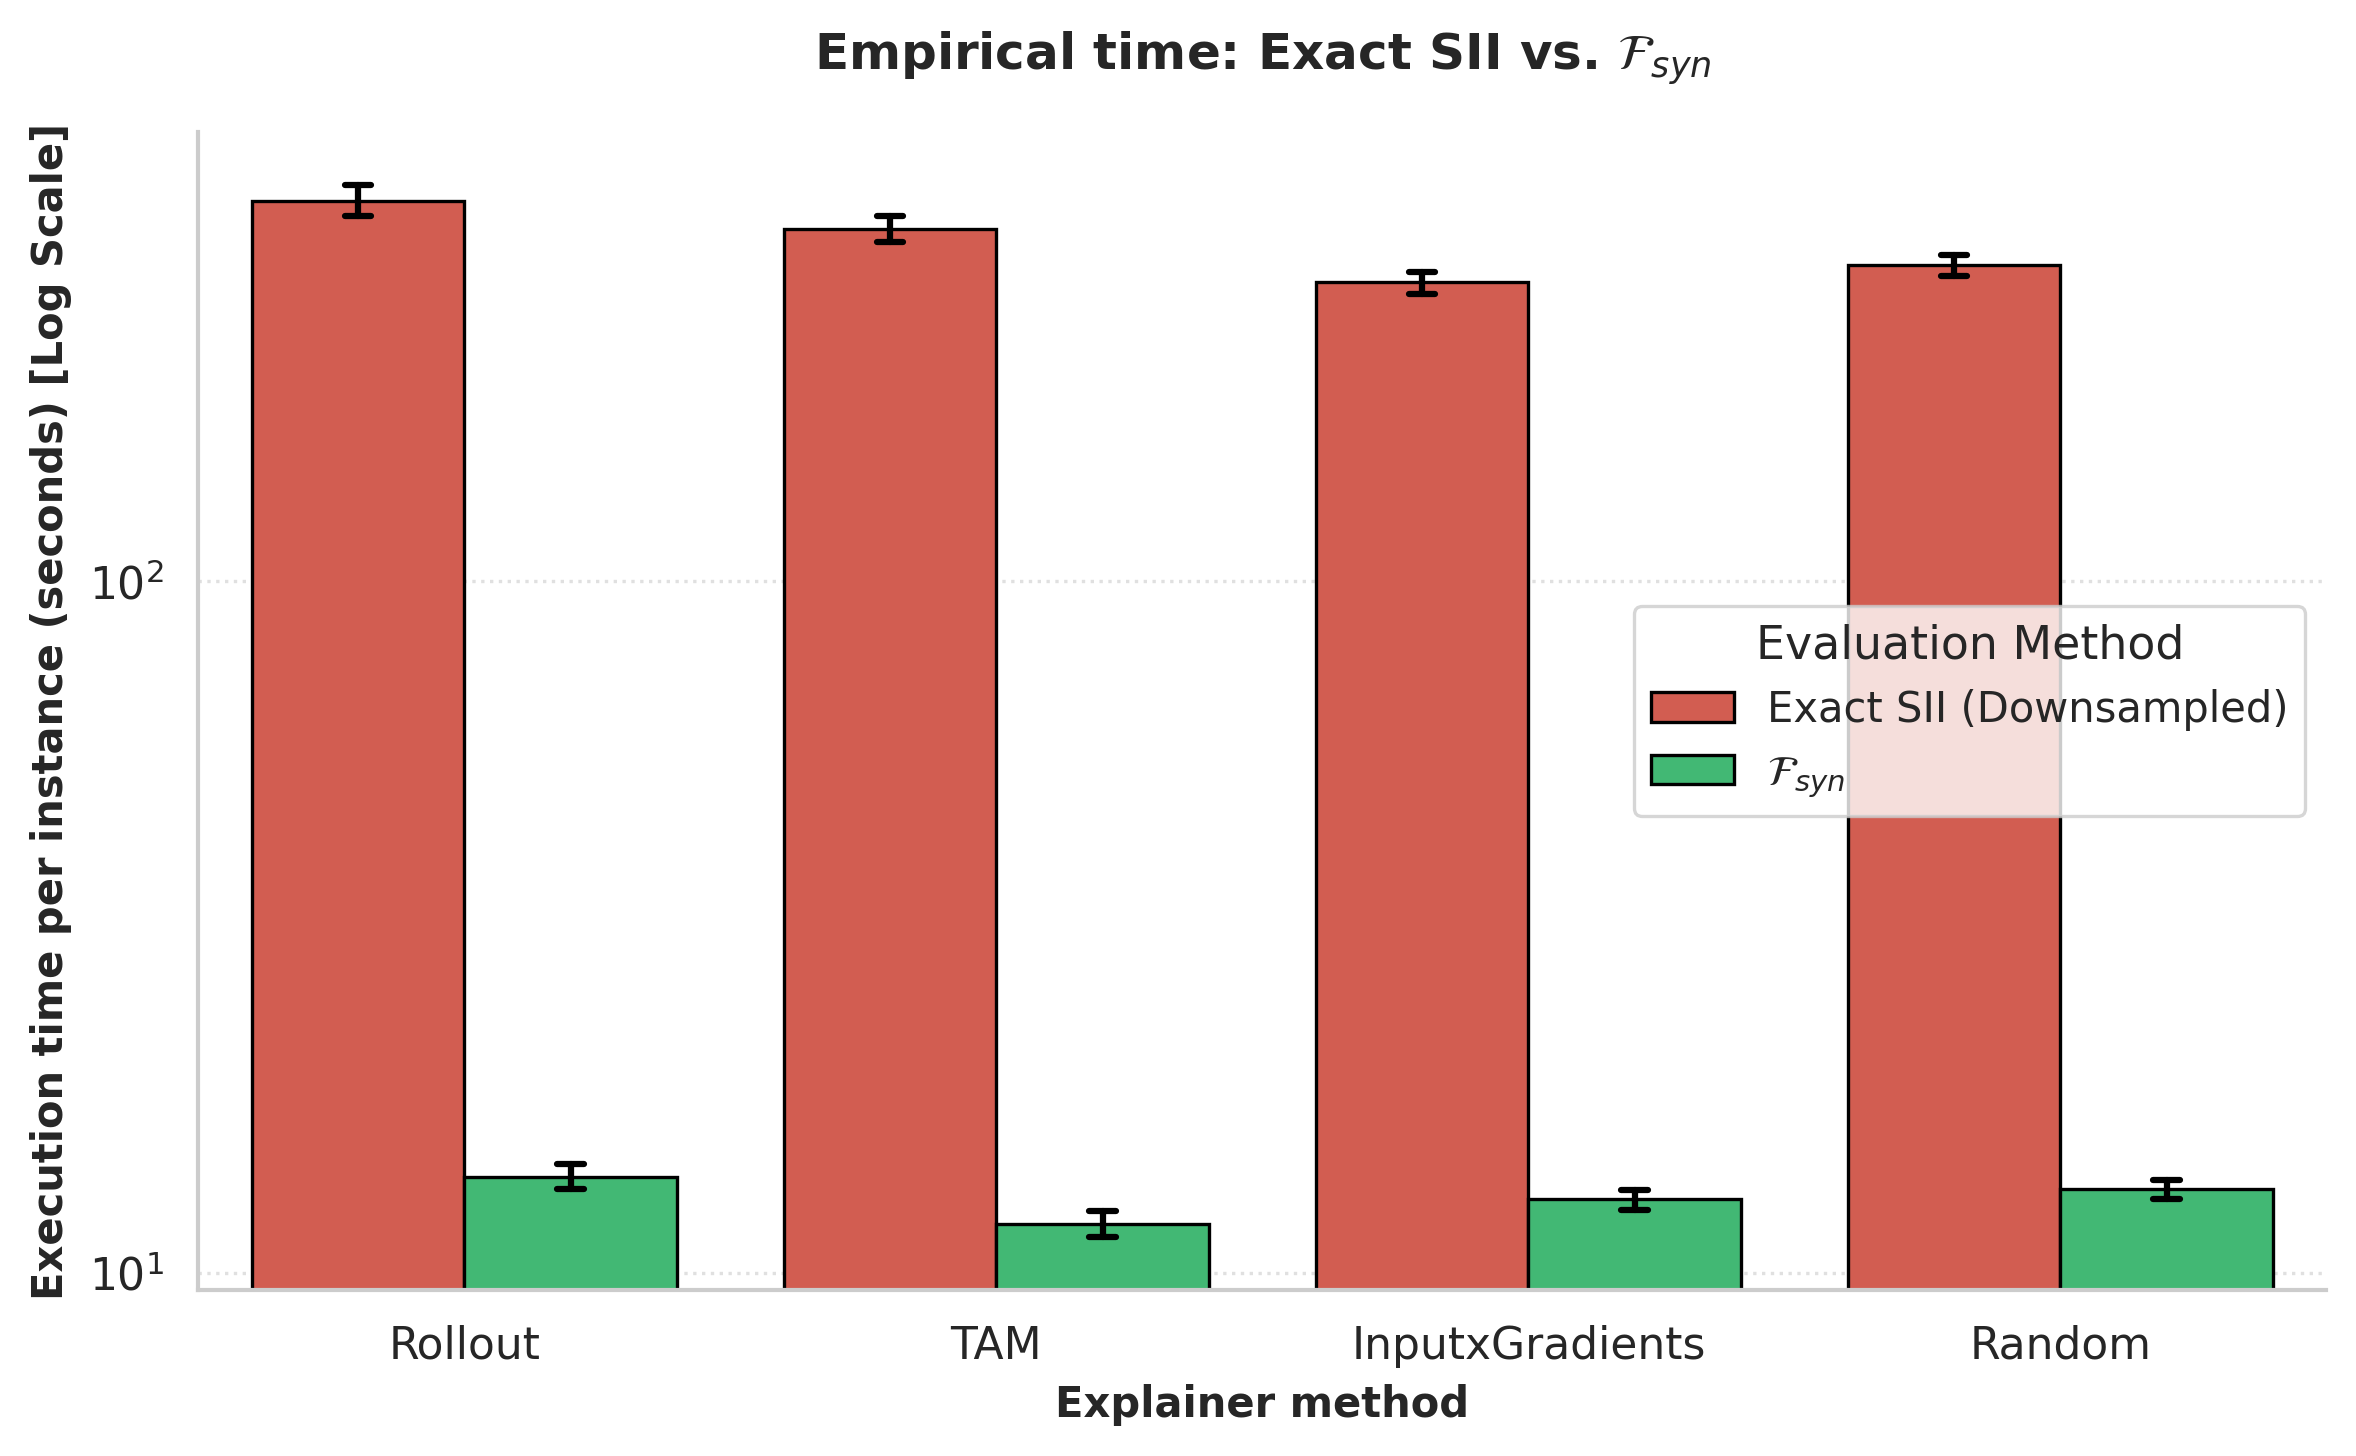

In [125]:
plot_time_comparison(df, sii_col='time_sii', syn_col='time_syn',
                    savefig=True, format="pdf")

In [69]:
df.columns

Index(['sample_idx', 'image_id', 'question', 'label', 'prediction', 'time_sii',
       'sii_auc', 'sii_curve', 'time_syn', 'syn_del_synergy_curve',
       'syn_ins_synergy_curve', 'syn_ins_norm_synergy_curve',
       'syn_del_norm_synergy_curve', 'synergy_srg', 'Model', 'Dataset',
       'Explainer', 'syn_del_auc', 'syn_ins_auc', 'syn_del_norm_auc',
       'syn_ins_norm_auc', 'synergy_srg_unorm'],
      dtype='object')

In [10]:
df = load_all_correlation_data(base_dir="../logs/correlation")

# 2. Print speedup info (Calculated once globally)
if 'time_sii' in df.columns and 'time_syn' in df.columns:
    avg_sii_time = df['time_sii'].mean()
    avg_srg_time = df['time_syn'].mean()
    speedup_factor = avg_sii_time / avg_srg_time if avg_srg_time > 0 else 0
    print("\n--- Computational Efficiency ---")
    print(f"Avg Time per Image (Exact SII) : {avg_sii_time:.2f} seconds")
    print(f"Avg Time per Image (Fast SRG)  : {avg_srg_time:.2f} seconds")
    print(f"Speedup Factor SRG             : {speedup_factor:.1f}x Faster")
    print("==================================================\n")


[*] Found 12 result files. Aggregating...

--- Computational Efficiency ---
Avg Time per Image (Exact SII) : 308.88 seconds
Avg Time per Image (Fast SRG)  : 12.90 seconds
Speedup Factor SRG             : 23.9x Faster



/tmp/ipykernel_2056413/4063181672.py:75: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Explainer'].replace('Lxt', 'AttnLRP', inplace=True)


#### Further analysis

In [6]:
import json
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
# results_file="../repope_eval_res_baseline.json"
#results_file="../logs/repope_eval_res_baseline.json"


print(f"Loading curve data from {results_file}...")

# 1. Define your exact perturbation steps for the X-axis
pert_steps = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
num_steps = len(pert_steps)

sii_curves = []
del_curves = []
ins_curves = []
sum_curves = []
dif_curves = []

# 2. Extract Data
with open(results_file, 'r') as f:
    for line in f:
        data = json.loads(line.strip())
        
        # Make sure the sample has the curves (skip if failed/missing)
        if "sii_curve" in data and "syn_del_synergy_curve" in data:
            sii_curves.append(data["sii_curve"])
            del_curves.append(data["syn_del_synergy_curve"])
            ins_curves.append(data["syn_ins_synergy_curve"])


# Convert to 2D NumPy arrays: Shape (N_images, N_steps)
sii_mat = np.array(sii_curves)
del_mat = np.array(del_curves)
ins_mat = np.array(ins_curves)
sum_mat = (ins_mat + del_mat) / 2
dif_mat = ins_mat - del_mat

N = sii_mat.shape[0]
print(f"Successfully loaded {N} images with full step-wise curves.\n")

Loading curve data from ../logs/correlation/internvl/eval_repope_oracle_tam_results.jsonl...
Successfully loaded 200 images with full step-wise curves.



Saved Analysis A -> 'analysis_A_trajectory.png'


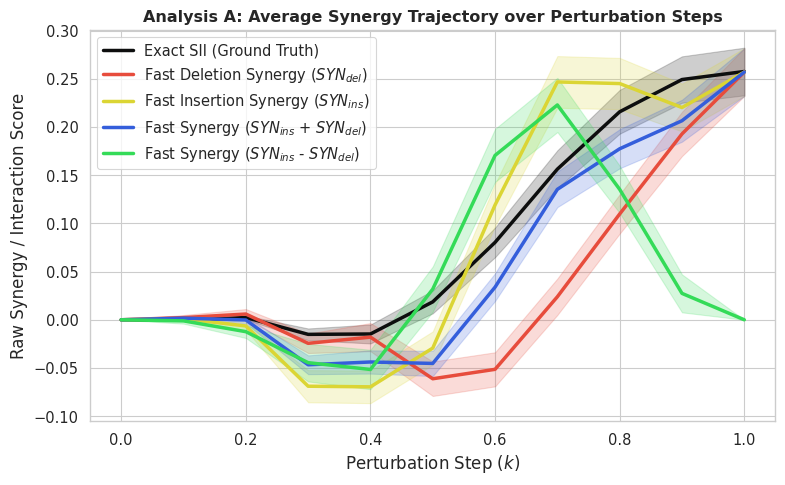

In [14]:
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# =========================================================
# ANALYSIS A: Mean Trajectory Plot (The "Shape" of Synergy)
# =========================================================
plt.figure(figsize=(8, 5))

def plot_mean_with_std(matrix, color, label):
    mean_curve = np.mean(matrix, axis=0)
    # Using Standard Error of the Mean (SEM) for cleaner shaded regions
    sem_curve = np.std(matrix, axis=0) / np.sqrt(N) 
    plt.plot(pert_steps, mean_curve, color=color, label=label, linewidth=2.5)
    plt.fill_between(pert_steps, mean_curve - sem_curve, mean_curve + sem_curve, color=color, alpha=0.2)

plot_mean_with_std(sii_mat, "#0D0E0E", 'Exact SII (Ground Truth)')
plot_mean_with_std(del_mat, '#E74C3C', 'Fast Deletion Synergy ($SYN_{del}$)')
plot_mean_with_std(ins_mat, "#DBD534", 'Fast Insertion Synergy ($SYN_{ins}$)')
plot_mean_with_std(sum_mat, "#345EDB", 'Fast Synergy ($SYN_{ins}$ + $SYN_{del}$)')
plot_mean_with_std(dif_mat, "#34DB58", 'Fast Synergy ($SYN_{ins}$ - $SYN_{del}$)')

plt.title('Analysis A: Average Synergy Trajectory over Perturbation Steps', weight='bold')
plt.xlabel('Perturbation Step ($k$)', fontsize=12)
plt.ylabel('Raw Synergy / Interaction Score', fontsize=12)
plt.legend()
plt.tight_layout()
# plt.savefig('analysis_A_trajectory.png', dpi=300)
# plt.close()
print("Saved Analysis A -> 'analysis_A_trajectory.png'")

Saved Analysis B -> 'analysis_B_stepwise_corr.png'


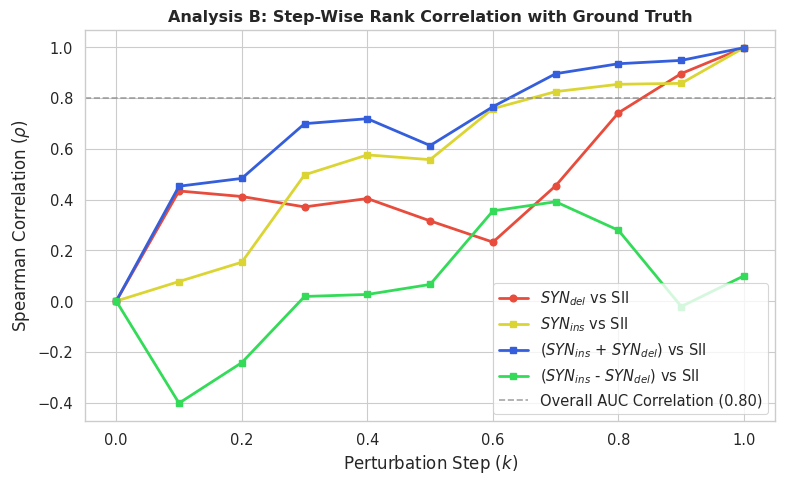

In [20]:
# =========================================================
# ANALYSIS B: Step-Wise Correlation (Tracking OOD Degradation)
# =========================================================
del_corrs = []
ins_corrs = []
sum_corrs = []
dif_corrs = []

for k in range(num_steps):
    # Extract the vector of all images at this specific step k
    sii_k = sii_mat[:, k]
    del_k = del_mat[:, k]
    ins_k = ins_mat[:, k]
    sum_k = sum_mat[:, k]
    dif_k = dif_mat[:, k]
    
    # Calculate Spearman rho at this exact step (ignoring step 0 where everything is 0)
    if k == 0:
        del_corrs.append(0.0)
        ins_corrs.append(0.0)
        sum_corrs.append(0.0)
        dif_corrs.append(0.0)
    else:
        rho_del, _ = stats.spearmanr(del_k, sii_k)
        rho_ins, _ = stats.spearmanr(ins_k, sii_k)
        rho_sum, _ = stats.spearmanr(sum_k, sii_k)
        rho_dif, _ = stats.spearmanr(dif_k, sii_k)
        del_corrs.append(rho_del)
        ins_corrs.append(rho_ins)
        sum_corrs.append(rho_sum)
        dif_corrs.append(rho_dif)

plt.figure(figsize=(8, 5))
plt.plot(pert_steps, del_corrs, marker='o', color='#E74C3C', label='$SYN_{del}$ vs SII', linewidth=2)
plt.plot(pert_steps, ins_corrs, marker='s', color='#DBD534', label='$SYN_{ins}$ vs SII', linewidth=2)
plt.plot(pert_steps, sum_corrs, marker='s', color='#345EDB', label='($SYN_{ins}$ + $SYN_{del}$) vs SII', linewidth=2)
plt.plot(pert_steps, dif_corrs, marker='s', color='#34DB58', label='($SYN_{ins}$ - $SYN_{del}$) vs SII', linewidth=2)

plt.title('Analysis B: Step-Wise Rank Correlation with Ground Truth', weight='bold')
plt.xlabel('Perturbation Step ($k$)', fontsize=12)
plt.ylabel('Spearman Correlation ($\\rho$)', fontsize=12)
plt.axhline(y=0.80, color='gray', linestyle='--', alpha=0.7, label='Overall AUC Correlation (0.80)')
plt.legend()
plt.tight_layout()
# plt.savefig('analysis_B_stepwise_corr.png', dpi=300)
# plt.close()
print("Saved Analysis B -> 'analysis_B_stepwise_corr.png'")


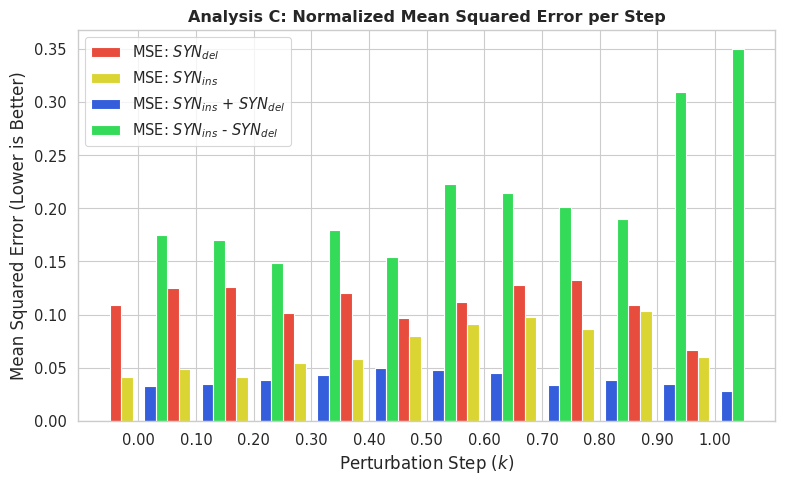

In [21]:
# =========================================================
# ANALYSIS C: Mean Squared Error (Time-to-Synergy Deviation)
# =========================================================
# To compute a fair MSE, we Min-Max scale the curves per-image 
# so they are all on a comparable 0 to 1 scale.
def min_max_normalize_2d(matrix):
    mins = matrix.min(axis=1, keepdims=True)
    maxs = matrix.max(axis=1, keepdims=True)
    # Avoid division by zero
    range_val = np.where((maxs - mins) == 0, 1e-8, (maxs - mins))
    return (matrix - mins) / range_val

sii_norm = min_max_normalize_2d(sii_mat)
del_norm = min_max_normalize_2d(del_mat)
ins_norm = min_max_normalize_2d(ins_mat)
sum_norm = min_max_normalize_2d(sum_mat)
dif_norm = min_max_normalize_2d(dif_mat)

# Calculate step-wise MSE
mse_del = np.mean((sii_norm - del_norm)**2, axis=0)
mse_ins = np.mean((sii_norm - ins_norm)**2, axis=0)
mse_sum = np.mean((sii_norm - sum_norm)**2, axis=0)
mse_dif = np.mean((sii_norm - dif_norm)**2, axis=0)

plt.figure(figsize=(8, 5))
plt.bar(np.arange(num_steps) - 0.4, mse_del, width=0.2, color='#E74C3C', label='MSE: $SYN_{del}$')
plt.bar(np.arange(num_steps) - 0.2, mse_ins, width=0.2, color='#DBD534', label='MSE: $SYN_{ins}$')
plt.bar(np.arange(num_steps) + 0.2, mse_sum, width=0.2, color='#345EDB', label='MSE: $SYN_{ins}$ + $SYN_{del}$')
plt.bar(np.arange(num_steps) + 0.4, mse_dif, width=0.2, color='#34DB58', label='MSE: $SYN_{ins}$ - $SYN_{del}$')
plt.xticks(np.arange(num_steps), [f"{s:.2f}" for s in pert_steps])

plt.title('Analysis C: Normalized Mean Squared Error per Step', weight='bold')
plt.xlabel('Perturbation Step ($k$)', fontsize=12)
plt.ylabel('Mean Squared Error (Lower is Better)', fontsize=12)
plt.legend()
plt.tight_layout()
# plt.savefig('analysis_C_mse.png', dpi=300)
# plt.close()
# print("Saved Analysis C -> 'analysis_C_mse.png'")

In [ ]:
import json
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_stepwise_curves(results_file="repope_evaluation_results.jsonl"):
    print(f"Loading curve data from {results_file}...")
    
    # 1. Define your exact perturbation steps for the X-axis
    pert_steps = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    num_steps = len(pert_steps)
    
    sii_curves = []
    del_curves = []
    ins_curves = []
    
    # 2. Extract Data
    with open(results_file, 'r') as f:
        for line in f:
            data = json.loads(line.strip())
            
            # Make sure the sample has the curves (skip if failed/missing)
            if "sii_curve" in data and "syn_del_synergy_curve" in data:
                sii_curves.append(data["sii_curve"])
                del_curves.append(data["syn_del_synergy_curve"])
                ins_curves.append(data["syn_ins_synergy_curve"])

    # Convert to 2D NumPy arrays: Shape (N_images, N_steps)
    sii_mat = np.array(sii_curves)
    del_mat = np.array(del_curves)
    ins_mat = np.array(ins_curves)
    
    N = sii_mat.shape[0]
    print(f"Successfully loaded {N} images with full step-wise curves.\n")
    
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    
    # =========================================================
    # ANALYSIS A: Mean Trajectory Plot (The "Shape" of Synergy)
    # =========================================================
    plt.figure(figsize=(8, 5))
    
    def plot_mean_with_std(matrix, color, label):
        mean_curve = np.mean(matrix, axis=0)
        # Using Standard Error of the Mean (SEM) for cleaner shaded regions
        sem_curve = np.std(matrix, axis=0) / np.sqrt(N) 
        plt.plot(pert_steps, mean_curve, color=color, label=label, linewidth=2.5)
        plt.fill_between(pert_steps, mean_curve - sem_curve, mean_curve + sem_curve, color=color, alpha=0.2)

    plot_mean_with_std(sii_mat, '#2C3E50', 'Exact SII (Ground Truth)')
    plot_mean_with_std(del_mat, '#E74C3C', 'Fast Deletion Synergy ($SYN_{del}$)')
    plot_mean_with_std(ins_mat, '#3498DB', 'Fast Insertion Synergy ($SYN_{ins}$)')
    
    plt.title('Analysis A: Average Synergy Trajectory over Perturbation Steps', weight='bold')
    plt.xlabel('Perturbation Step ($k$)', fontsize=12)
    plt.ylabel('Raw Synergy / Interaction Score', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.savefig('analysis_A_trajectory.png', dpi=300)
    plt.close()
    print("Saved Analysis A -> 'analysis_A_trajectory.png'")

    # =========================================================
    # ANALYSIS B: Step-Wise Correlation (Tracking OOD Degradation)
    # =========================================================
    del_corrs = []
    ins_corrs = []
    
    for k in range(num_steps):
        # Extract the vector of all images at this specific step k
        sii_k = sii_mat[:, k]
        del_k = del_mat[:, k]
        ins_k = ins_mat[:, k]
        
        # Calculate Spearman rho at this exact step (ignoring step 0 where everything is 0)
        if k == 0:
            del_corrs.append(0.0)
            ins_corrs.append(0.0)
        else:
            rho_del, _ = stats.spearmanr(del_k, sii_k)
            rho_ins, _ = stats.spearmanr(ins_k, sii_k)
            del_corrs.append(rho_del)
            ins_corrs.append(rho_ins)

    plt.figure(figsize=(8, 5))
    plt.plot(pert_steps, del_corrs, marker='o', color='#E74C3C', label='$SYN_{del}$ vs SII', linewidth=2)
    plt.plot(pert_steps, ins_corrs, marker='s', color='#3498DB', label='$SYN_{ins}$ vs SII', linewidth=2)
    
    plt.title('Analysis B: Step-Wise Rank Correlation with Ground Truth', weight='bold')
    plt.xlabel('Perturbation Step ($k$)', fontsize=12)
    plt.ylabel('Spearman Correlation ($\\rho$)', fontsize=12)
    plt.axhline(y=0.80, color='gray', linestyle='--', alpha=0.7, label='Overall AUC Correlation (0.80)')
    plt.legend()
    plt.tight_layout()
    plt.savefig('analysis_B_stepwise_corr.png', dpi=300)
    plt.close()
    print("Saved Analysis B -> 'analysis_B_stepwise_corr.png'")

    # =========================================================
    # ANALYSIS C: Mean Squared Error (Time-to-Synergy Deviation)
    # =========================================================
    # To compute a fair MSE, we Min-Max scale the curves per-image 
    # so they are all on a comparable 0 to 1 scale.
    def min_max_normalize_2d(matrix):
        mins = matrix.min(axis=1, keepdims=True)
        maxs = matrix.max(axis=1, keepdims=True)
        # Avoid division by zero
        range_val = np.where((maxs - mins) == 0, 1e-8, (maxs - mins))
        return (matrix - mins) / range_val

    sii_norm = min_max_normalize_2d(sii_mat)
    del_norm = min_max_normalize_2d(del_mat)
    ins_norm = min_max_normalize_2d(ins_mat)

    # Calculate step-wise MSE
    mse_del = np.mean((sii_norm - del_norm)**2, axis=0)
    mse_ins = np.mean((sii_norm - ins_norm)**2, axis=0)

    plt.figure(figsize=(8, 5))
    plt.bar(np.arange(num_steps) - 0.2, mse_del, width=0.4, color='#E74C3C', label='MSE: $SYN_{del}$')
    plt.bar(np.arange(num_steps) + 0.2, mse_ins, width=0.4, color='#3498DB', label='MSE: $SYN_{ins}$')
    plt.xticks(np.arange(num_steps), [f"{s:.2f}" for s in pert_steps])
    
    plt.title('Analysis C: Normalized Mean Squared Error per Step', weight='bold')
    plt.xlabel('Perturbation Step ($k$)', fontsize=12)
    plt.ylabel('Mean Squared Error (Lower is Better)', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.savefig('analysis_C_mse.png', dpi=300)
    plt.close()
    print("Saved Analysis C -> 'analysis_C_mse.png'")
    
    print("\nAll analyses completed! Check your working directory for the PNGs.")


### Paper plots

#### Configs

In [1]:
SAVE_DIR = "../figs"

In [6]:
import os
import glob
import json
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata, friedmanchisquare, wilcoxon
import itertools

def load_all_benchmark_data(base_dir="logs/results",
                            #dataset_name="repope_all"
                            ):
    """
    Crawls the directory structure to load all JSONL files, 
    automatically extracting the Model and Dataset from folder names.
    """
    all_data = []
    # Adjust this glob pattern based on your actual folder structure!
    # e.g., logs/llava/pope/ig_results.jsonl
    search_pattern = os.path.join(base_dir, "*", "*", "*.jsonl")
    file_list = glob.glob(search_pattern)
    
    print(f"[*] Found {len(file_list)} result files. Aggregating...")
    
    for file_path in file_list:
        # Extract metadata from the path 
        # (e.g., parts[-3] = model, parts[-2] = dataset)
        path_parts = os.path.normpath(file_path).split(os.sep)
        if len(path_parts) >= 3:
            model_name = path_parts[-3]
            dataset_name = path_parts[-2]
        else:
            model_name, dataset_name = "Unknown", "Unknown"
        
        
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    try:
                        row = json.loads(line)
                        # Ensure we don't overwrite if the JSON already has it
                        row['Model'] = row.get('model', model_name)
                        row['Dataset'] = row.get('dataset', dataset_name)
                        # Ensure explainer name is clean
                        row['Explainer'] = row.get('explainer', os.path.basename(file_path).replace('.jsonl', ''))
                        all_data.append(row)
                    except json.JSONDecodeError:
                        continue
                    
    df = pd.DataFrame(all_data)
    #df['Explainer'].replace('LXT', 'AttnLRP', inplace=True)
    df['Explainer'] = df['Explainer'].replace('LXT', 'AttnLRP')

    # df["tok_srg_norm"] = df["tok_norm_auc_ins"] - df["tok_norm_auc_del"]
    # df["tok_srg"] = df["tok_auc_ins"] - df["tok_auc_del"]
    # df["img_srg_norm"] = df["img_norm_auc_ins"] - df["img_norm_auc_del"]
    # df["img_srg"] = df["img_auc_ins"] - df["img_auc_del"]
    
    # Optional: Calculate combined AUPC metrics if you saved curves instead of raw AUCs
    # ... (Insert your trapezoid np.trapezoid code here if needed) ...
    
    return df



# ==========================================
# 2. STATISTICAL TESTING
# ==========================================
def run_statistical_comparison(df, metric='img_ins_auc',
                               baseline_explainer='random', target_explainer='ours'):
    """Runs a Wilcoxon Signed-Rank test between two explainers."""
    print(f"\n--- Statistical Test: {target_explainer} vs {baseline_explainer} ({metric}) ---")
    
    # We need to compare them on the EXACT same images (Paired Test)
    pivot = df.pivot_table(index=['Model', 'Dataset', 'sample_idx'], 
                           columns='Explainer', 
                           values=metric).dropna()
    
    if baseline_explainer not in pivot.columns or target_explainer not in pivot.columns:
        print("[!] Explainers not found in data for paired testing.")
        return
        
    baseline_scores = pivot[baseline_explainer]
    target_scores = pivot[target_explainer]
    
    # Wilcoxon signed-rank test
    stat, p_value = stats.wilcoxon(target_scores, baseline_scores)
    
    mean_diff = target_scores.mean() - baseline_scores.mean()
    print(f"Mean Difference: {mean_diff:+.4f}")
    print(f"p-value        : {p_value:.2e}")
    if p_value < 0.05:
        print("Conclusion     : STATISTICALLY SIGNIFICANT DIFFERENCE (Reject Null)")
    else:
        print("Conclusion     : NO SIGNIFICANT DIFFERENCE")

# ==========================================
# 3. PUBLICATION PLOTS
# ==========================================

# ==========================================
# 1. MACRO BOXPLOT (Variance Distribution)
# ==========================================
def plot_macro_boxplot(df, metric='img_ins_auc', 
                       dataset_filter=None,
                       savefig=False, format="pdf"):
    """Generates a grouped boxplot. Filters by dataset if provided."""
    plot_df = df.copy()
    title_suffix = " (All Datasets)"
    
    if dataset_filter:
        plot_df = plot_df[plot_df['Dataset'] == dataset_filter]
        title_suffix = f" (Dataset: {dataset_filter})"
        
    if plot_df.empty:
        print(f"[!] No data found for dataset: {dataset_filter}")
        return
        
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.figure(figsize=(12, 6))
    
    ranking = plot_df.groupby('Explainer')[metric].median().sort_values(ascending=False).index
    
    ax = sns.boxplot(x='Explainer', y=metric, hue='Model', data=plot_df, 
                     order=ranking, palette='Set2', showfliers=False)
                     
    plt.title(f'Faithfulness score distribution across explainers{title_suffix}', weight='bold')
    plt.xlabel('XAI Method', weight='bold')
    plt.ylabel(metric)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title="Vision-Language Model", loc='best')
    
    filename = f'boxplot_{metric}_{dataset_filter or "global"}.{format}'
    plt.tight_layout()
    if savefig:
        filename = os.path.join(SAVE_DIR, filename)
        plt.savefig(filename, dpi=300, format=format)
        print(f"[*] Saved {filename}")
        #plt.close()
    plt.show()

# ==========================================
# 2. PARETO PLOT (Speed vs. Performance)
# ==========================================
def plot_speed_vs_performance(df, perf_metric='img_ins_auc',
                              time_metric='xai_gen_time',
                              dataset_filter=None,
                              format="pdf",
                              savefig=False
                              ):
    """Scatter plot showing computation time vs accuracy."""
    plot_df = df.copy()
    title_suffix = " (All Datasets)"
    
    if dataset_filter:
        plot_df = plot_df[plot_df['Dataset'] == dataset_filter]
        title_suffix = f"\n(Dataset: {dataset_filter})"

    if plot_df.empty or time_metric not in plot_df.columns:
        print(f"[!] Missing data or time metrics for {dataset_filter or 'global'}")
        return

    agg_df = plot_df.groupby('Explainer').agg({
        perf_metric: 'mean',
        time_metric: 'mean'
    }).reset_index()
    
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.figure(figsize=(8, 6))
    
    ax = sns.scatterplot(x=time_metric, y=perf_metric, data=agg_df, 
                         s=150, color="#ED481B", edgecolor='black')
    
    for line in range(0, agg_df.shape[0]):
         ax.text(agg_df[time_metric][line]*1.05, agg_df[perf_metric][line], 
                 agg_df['Explainer'][line], horizontalalignment='left', 
                 size='small', color='black', weight='semibold')

    plt.xscale('log')
    plt.title(f'Trade-off: Cost vs. Faithfulness{title_suffix}', weight='bold')
    plt.xlabel('Average Time per Image (Seconds, Log Scale)', weight='bold')
    plt.ylabel(r'Mean $\mathcal{F}_{syn}$', weight='bold')
    
    plt.axvline(agg_df[time_metric].median(), color='gray', linestyle='--', alpha=0.5)
    plt.axhline(agg_df[perf_metric].median(), color='gray', linestyle='--', alpha=0.5)
    
    filename = f'pareto_{perf_metric}_{dataset_filter or "global"}.{format}'
    plt.tight_layout()
    
    if savefig:
        filename = os.path.join(SAVE_DIR, filename)
        plt.savefig(filename, dpi=300, format=format)
        print(f"[*] Saved {filename}")
        #plt.close()
    plt.show()
    
# ==========================================
# 3. MEAN RANK & SIGNIFICANCE (Dynamic Winner Anchor)
# ==========================================
def compute_and_plot_ranks(df, metric='img_ins_auc',
                           ascending_metric=False,
                           dataset_filter=None,
                           savefig=False,
                           format="pdf"
                           ):
    """
    Computes the Mean Rank per image and plots a sleek bar chart.
    Statistical significance (symbols only) is cleanly tabulated on the right margin,
    with a legend explaining the symbols.
    """
    print("--- Generating Final Mean Rank Plot (Symbols Only) ---")
    plot_df = df.copy()
    title_suffix = "All Datasets"
    
    if dataset_filter:
        plot_df = plot_df[plot_df['Dataset'] == dataset_filter]
        title_suffix = f"Dataset: {dataset_filter}"

    pivot = plot_df.pivot_table(
        index=['Model', 'Dataset', 'sample_idx'], 
        columns='Explainer', 
        values=metric
    ).dropna()
    
    if pivot.empty:
        print("[!] No valid paired data found. Skipping.")
        return

    # 1. Ranks and Mean Ranks
    ranks_df = pivot.rank(axis=1, ascending=ascending_metric)
    mean_ranks = ranks_df.mean().sort_values()
    k = len(mean_ranks)
    best_explainer = mean_ranks.index[0]

    # 2. Statistical Testing (Wilcoxon vs Winner with Bonferroni correction)
    stats_results = {}
    num_comparisons = k - 1 
    
    for exp in mean_ranks.index:
        if exp == best_explainer:
            stats_results[exp] = {'p_adj': 1.0, 'sig': '-'}
            continue
            
        _, p_raw = wilcoxon(pivot[best_explainer], pivot[exp])
        p_adj = min(1.0, p_raw * num_comparisons)
        
        if p_adj < 0.001: sig_text = '***'
        elif p_adj < 0.01: sig_text = '**'
        elif p_adj < 0.05: sig_text = '*'
        else: sig_text = 'ns'
            
        stats_results[exp] = {'p_adj': p_adj, 'sig': sig_text}

    # 3. Plotting Setup
    sns.set_theme(style="white", context="paper", font_scale=1.2)
    fig, ax = plt.subplots(figsize=(9, 6), dpi=300)
    
    y_pos = np.arange(k)
    uniform_color = "#DC610F" 
    
    # Draw horizontal bars
    bars = ax.barh(y_pos, mean_ranks.values, color=uniform_color, 
                   height=0.6, edgecolor='black', linewidth=1.2, alpha=0.85)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(mean_ranks.index, weight='bold')
    ax.invert_yaxis() # Rank 1 at the top
    
    # 4. Text Annotations and Significance Margin
    max_rank = mean_ranks.max()
    
    # We need less space now, so we shrink the right margin slightly
    ax.set_xlim(0, max_rank * 1.30) 
    
    # Table Header
    ax.text(max_rank * 1.20, -0.8, "Sig.\nvs Top", ha='center', va='center', 
            weight='bold', fontsize=11, color='#2c3e50')
    
    # Subtle separator line
    ax.axvline(max_rank * 1.10, color='gray', linestyle=':', linewidth=1.5, alpha=0.5)

    for i, (exp, val) in enumerate(mean_ranks.items()):
        # Bar value annotation
        ax.text(val + 0.1, i, f"{val:.2f}", va='center', fontsize=10, weight='bold', color='#2c3e50')
        
        # Table row annotation (Symbols only)
        if exp == best_explainer:
            p_text = "Control"
            font_w = 'bold'
        else:
            sig = stats_results[exp]['sig']
            p_text = sig
            font_w = 'bold' if sig in ['ns', '***', '**', '*'] else 'normal'
            
        # Draw the symbol
        ax.text(max_rank * 1.20, i, p_text, ha='center', va='center', 
                fontsize=13 if p_text in ['***', '**', '*'] else 11, 
                weight=font_w, color='#2c3e50')

    # 5. Add Legend for Significance Symbols
    legend_text = "*** $p < 0.001$\n ** $p < 0.01$\n  * $p < 0.05$\n ns  not sig."
    props = dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.95, edgecolor='gray')
    ax.text(0.97, 0.04, legend_text, transform=ax.transAxes, fontsize=10,
            verticalalignment='bottom', horizontalalignment='right', 
            bbox=props, family='monospace')

    # 6. Formatting
    ax.set_xlabel('Average Rank (Lower is Better)', weight='bold', labelpad=10)
    ax.set_title(f'Mean Rank & Ordinal Significance ({title_suffix})', weight='bold', pad=25, fontsize=14)
    
    # Remove borders
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.grid(axis='x', linestyle='--', alpha=0.4)

    plt.tight_layout()
    
    filename = f'ranks_{metric}_{dataset_filter or "global"}.{format}'
    plt.tight_layout()
    if savefig:
        filename = os.path.join(SAVE_DIR, filename)
        plt.savefig(filename, dpi=300, bbox_inches='tight', format=format)
        print(f"[*] Saved {filename}")
        #plt.close()
    plt.show()


def global_ranking_and_friedman_test(df, metric='img_ins_auc',
                                     savefig=False,
                                     format="pdf"):
    """
    Ranks all explainers globally, runs a Friedman test, and generates 
    a Pairwise Significance Heatmap with Bonferroni correction.
    """
    print(f"\n{'='*50}\n[*] GLOBAL RANKING & STATISTICAL ANALYSIS ({metric})\n{'='*50}")

    # 1. Pivot the data so each row is a unique sample, and columns are the explainers
    # We group by Model, Dataset, and Image ID to ensure perfect paired matching.
    pivot = df.pivot_table(
        index=['Model', 'Dataset', 'sample_idx'], 
        columns='Explainer', 
        values=metric
    ).dropna() # Drop rows where ANY explainer failed/crashed
    
    explainers = pivot.columns.tolist()
    k = len(explainers)
    
    print(f"[*] Valid Paired Samples: {len(pivot)} (Evaluated successfully by ALL {k} explainers)")
    
    # 2. Print the Global Mean Ranking
    print("\n--- Mean Scores (Global) ---")
    mean_scores = pivot.mean().sort_values(ascending=False)
    for rank, (exp, score) in enumerate(mean_scores.items(), 1):
        print(f"{rank}. {exp:<20} : {score:.4f}")

    # 3. The Friedman Test
    # Unpack the columns into separate arrays for the test
    args = [pivot[col] for col in explainers]
    stat, p_value = stats.friedmanchisquare(*args)
    
    print("\n--- Step 1: Friedman Test ---")
    print(f"Chi-Square Stat : {stat:.3f}")
    print(f"p-value         : {p_value:.2e}")
    
    if p_value >= 0.05:
        print("[!] No significant difference found among the explainers. Stopping here.")
        return
    else:
        print("[*] Significant difference detected! Proceeding to Post-Hoc Pairwise tests.")

    # 4. Post-Hoc Pairwise Wilcoxon with Bonferroni Correction
    num_comparisons = (k * (k - 1)) / 2
    print(f"\n--- Step 2: Pairwise Tests (Bonferroni Penalty Multiplier: {num_comparisons}) ---")
    
    # Create an empty matrix to store the adjusted p-values
    p_matrix = pd.DataFrame(1.0, index=mean_scores.index, columns=mean_scores.index)
    
    for exp1, exp2 in itertools.combinations(mean_scores.index, 2):
        # Run standard Wilcoxon
        w_stat, p_val_raw = stats.wilcoxon(pivot[exp1], pivot[exp2])
        
        # Apply Bonferroni Correction (multiply p-value by number of comparisons)
        p_val_adj = min(1.0, p_val_raw * num_comparisons) 
        
        # Store symmetrically in the matrix
        p_matrix.loc[exp1, exp2] = p_val_adj
        p_matrix.loc[exp2, exp1] = p_val_adj

    # 5. Plot the Pairwise Significance Heatmap
    plot_significance_heatmap(p_matrix, metric, savefig=savefig, format=format)


def plot_significance_heatmap(p_matrix, metric, savefig=False,
                              format="pdf"):
    """
    Plots a heatmap showing which explainers are significantly different from each other.
    Green = Significantly Different (p < 0.05)
    Red/Gray = Statistically Tied (p >= 0.05)
    """
    sns.set_theme(style="white", context="paper", font_scale=1.1)
    plt.figure(figsize=(10, 8))
    
    # Create a binary mask: True if significant, False if not
    is_significant = p_matrix < 0.05
    
    # Plotting: We use a custom colormap. 
    # Let's show the actual adjusted p-values, but color them by significance.
    cmap = sns.diverging_palette(10, 130, as_cmap=True)
    
    # Generate a mask for the upper triangle so we don't duplicate data visually
    mask = np.triu(np.ones_like(p_matrix, dtype=bool))
    
    ax = sns.heatmap(
        p_matrix, mask=mask, annot=True, fmt=".3f", cmap="coolwarm_r", 
        vmin=0, vmax=0.1, linewidths=.5, cbar_kws={"label": "Adjusted p-value"}
    )
    
    plt.title(f'Pairwise Statistical Significance ({metric})\n(Bonferroni-Adjusted Wilcoxon, p < 0.05)', weight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    if savefig:
        savepath = os.path.join(SAVE_DIR, f'pairwise_significance_{metric}.{format}')
        plt.savefig(savepath, dpi=300, format=format)
    plt.show()


def generate_latex_table(df, metric='img_ins_auc'):
    """
    Automatically generates a Pandas Pivot Table and exports the LaTeX code
    for you to copy-paste directly into Overleaf!
    """
    print(f"\n--- Generating LaTeX Table for {metric} ---")
    pivot = df.pivot_table(index='Explainer', columns=['Model', 'Dataset'], 
                           values=metric, aggfunc='mean')
    
    # Sort explainers by their overall average across all columns
    pivot['Overall_Mean'] = pivot.mean(axis=1)
    pivot = pivot.sort_values(by='Overall_Mean', ascending=False).drop(columns=['Overall_Mean'])
    
    print(pivot.to_latex(float_format="%.3f"))
    return pivot



In [7]:
df = load_all_benchmark_data(base_dir="../logs/sensitivity",
                            #dataset_name="repope_all"
                            )

[*] Found 9 result files. Aggregating...


In [8]:
df.columns

Index(['sample_idx', 'explainer', 'question', 'label', 'category',
       'prediction', 'parse_success', 'decision_token_idx',
       'decision_token_str', 'xai_gen_time', 'k3_time_syn_pert',
       'k3_syn_del_norm_auc', 'k3_syn_ins_norm_auc', 'k3_syn_del_auc',
       'k3_syn_ins_auc', 'k3_syn_synergy_auc', 'k3_syn_synergy_norm_auc',
       'k5_time_syn_pert', 'k5_syn_del_norm_auc', 'k5_syn_ins_norm_auc',
       'k5_syn_del_auc', 'k5_syn_ins_auc', 'k5_syn_synergy_auc',
       'k5_syn_synergy_norm_auc', 'k7_time_syn_pert', 'k7_syn_del_norm_auc',
       'k7_syn_ins_norm_auc', 'k7_syn_del_auc', 'k7_syn_ins_auc',
       'k7_syn_synergy_auc', 'k7_syn_synergy_norm_auc', 'k11_time_syn_pert',
       'k11_syn_del_norm_auc', 'k11_syn_ins_norm_auc', 'k11_syn_del_auc',
       'k11_syn_ins_auc', 'k11_syn_synergy_auc', 'k11_syn_synergy_norm_auc',
       'k15_time_syn_pert', 'k15_syn_del_norm_auc', 'k15_syn_ins_norm_auc',
       'k15_syn_del_auc', 'k15_syn_ins_auc', 'k15_syn_synergy_auc',
       'k1

In [11]:
# plaus_cols = ["time_plausibility", "plaus_obj_iou", "plaus_point_game", "plaus_energy_score",
#               "note", "category", "parse_success", "decision_token_idx", "decision_token_str", "image_id", "text"]

# df = df.drop(labels=plaus_cols, axis=1, errors="ignore")

col_to_keep = ["sample_idx", "question", "Explainer", "xai_gen_time", 'label',
               "syn_synergy_auc", "syn_synergy_norm_auc",
                'syn_del_norm_auc', 'syn_ins_norm_auc', 'syn_del_auc', 'syn_ins_auc',
               "Model", "Dataset", 'tok_srg_norm', 'tok_srg', 'img_srg_norm', 'img_srg',
               'img_norm_auc_del', 'img_norm_auc_ins', 'img_auc_del', 'img_auc_ins',
               'tok_norm_auc_del', 'tok_norm_auc_ins', 'tok_auc_del', 'tok_auc_ins',
               ]
df = df[col_to_keep]


In [12]:
df = df.dropna()

In [13]:
df.shape

(236133, 25)

#### Riemann steps sensitivity

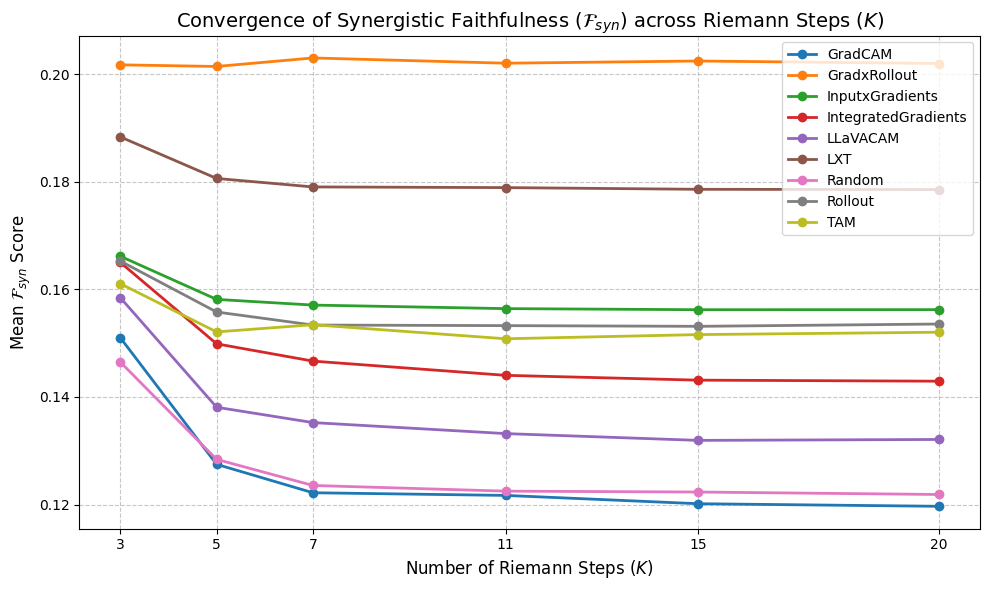

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kendalltau
import json

# Define the K values we tested
k_values = [3, 5, 7, 11, 15, 20]

# ==========================================
# ANALYSIS 1: Mean F_syn Convergence
# ==========================================
# Create a dataframe of just the mean F_syn scores per explainer
score_cols = {f"k{k}_syn_synergy_auc": k for k in k_values}
df_scores = df.groupby('explainer')[list(score_cols.keys())].mean()
df_scores.columns = k_values # Rename columns to just the K integer

plt.figure(figsize=(10, 6))
for explainer in df_scores.index:
    plt.plot(k_values, df_scores.loc[explainer], marker='o', label=explainer, linewidth=2)

plt.title(r'Convergence of Synergistic Faithfulness ($\mathcal{F}_{syn}$) across Riemann Steps ($K$)', fontsize=14)
plt.xlabel('Number of Riemann Steps ($K$)', fontsize=12)
plt.ylabel(r'Mean $\mathcal{F}_{syn}$ Score', fontsize=12)
plt.xticks(k_values)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('f_syn_convergence.pdf') # Save for NeurIPS
plt.show()

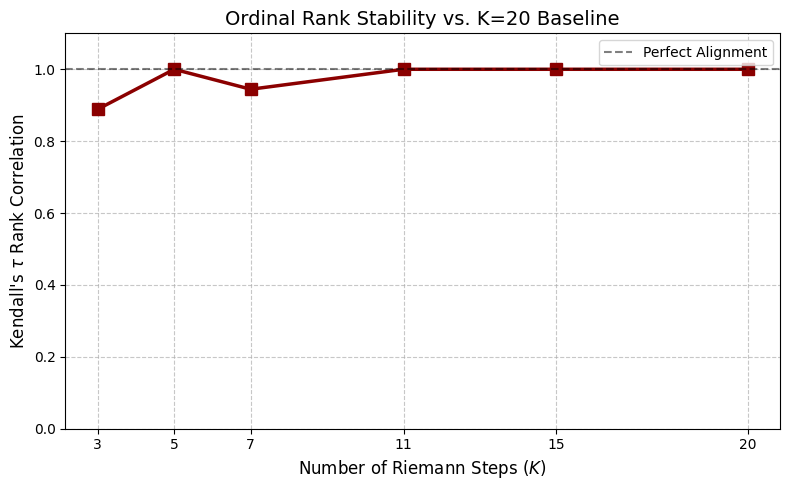

In [12]:
# ==========================================
# ANALYSIS 2: Rank Stability (Kendall's Tau)
# ==========================================
# Rank the explainers for each K (1 is best, 8 is worst)
# We rank descending because higher F_syn is better
df_ranks = df_scores.rank(ascending=False)

# Treat K=20 as the "Ground Truth" ranking
ground_truth_ranks = df_ranks[20]

tau_scores = []
for k in k_values:
    # Calculate Kendall's Tau between current K and K=20
    tau, p_value = kendalltau(df_ranks[k], ground_truth_ranks)
    tau_scores.append(tau)

plt.figure(figsize=(8, 5))
plt.plot(k_values, tau_scores, marker='s', color='darkred', linewidth=2.5, markersize=8)
plt.axhline(y=1.0, color='black', linestyle='--', alpha=0.5, label='Perfect Alignment')

plt.title('Ordinal Rank Stability vs. K=20 Baseline', fontsize=14)
plt.xlabel('Number of Riemann Steps ($K$)', fontsize=12)
plt.ylabel(r"Kendall's $\tau$ Rank Correlation", fontsize=12)
plt.xticks(k_values)
plt.ylim(0, 1.1)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig('rank_stability_tau.pdf')
plt.show()

In [14]:
df_ranks

,3,5,7,11,15,20
explainer,,,,,,
GradCAM,8.0,9.0,9.0,9.0,9.0,9.0
GradxRollout,1.0,1.0,1.0,1.0,1.0,1.0
InputxGradients,3.0,3.0,3.0,3.0,3.0,3.0
IntegratedGradients,5.0,6.0,6.0,6.0,6.0,6.0
LLaVACAM,7.0,7.0,7.0,7.0,7.0,7.0
LXT,2.0,2.0,2.0,2.0,2.0,2.0
Random,9.0,8.0,8.0,8.0,8.0,8.0
Rollout,4.0,4.0,5.0,4.0,4.0,4.0
TAM,6.0,5.0,4.0,5.0,5.0,5.0


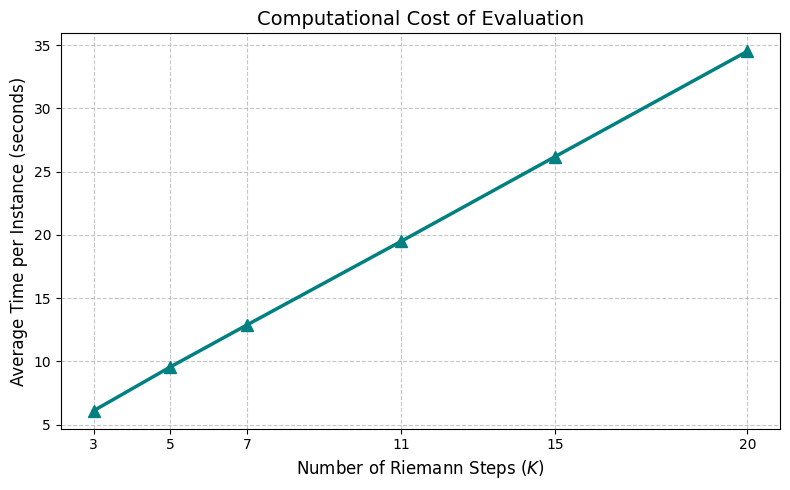

In [13]:
# ==========================================
# ANALYSIS 3: Computational Time Trade-off
# ==========================================
time_cols = {f"k{k}_time_syn_pert": k for k in k_values}
df_time = df[list(time_cols.keys())].mean()
df_time.index = k_values

plt.figure(figsize=(8, 5))
plt.plot(k_values, df_time.values, marker='^', color='teal', linewidth=2.5, markersize=8)

plt.title('Computational Cost of Evaluation', fontsize=14)
plt.xlabel('Number of Riemann Steps ($K$)', fontsize=12)
plt.ylabel('Average Time per Instance (seconds)', fontsize=12)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('compute_time_tradeoff.pdf')
plt.show()

#### Limitations of metrics

In [137]:
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import numpy as np

# --- CONFIGURATION ---
# Replace these with your actual column names for unimodal image and text metrics
IMG_METRIC = 'img_srg_norm'  
TOK_METRIC = 'tok_srg_norm'  

def compute_kendalls_tau(df, img_col, tok_col):
    print("=== Kendall's Tau: Image vs Text Ranking Instability ===")
    
    datasets = df['Dataset'].unique()
    results = []

    for ds in datasets:
        df_ds = df[df['Dataset'] == ds]
        
        # Get the mean score for each explainer on this dataset
        means = df_ds.groupby('Explainer')[[img_col, tok_col]].mean()
        
        # Rank them (higher score = rank 1, etc.)
        # Adjust ascending=False/True depending on if higher is better for your metric
        img_ranks = means[img_col].rank(ascending=False)
        tok_ranks = means[tok_col].rank(ascending=False)
        
        # Compute Kendall's Tau
        tau, p_value = stats.kendalltau(img_ranks, tok_ranks)
        
        results.append({'Dataset': ds, 'Kendalls_Tau': tau, 'p_value': p_value})
        print(f"- {ds}: Tau = {tau:.3f} (p={p_value:.3f})")

    # Overall Global Tau
    global_means = df.groupby('Explainer')[[img_col, tok_col]].mean()
    global_tau, global_p = stats.kendalltau(global_means[img_col].rank(ascending=False), 
                                            global_means[tok_col].rank(ascending=False))
    print(f"- GLOBAL (All Datasets): Tau = {global_tau:.3f} (p={global_p:.3f})")
    print("========================================================\n")
    
    return pd.DataFrame(results)

def plot_rank_shift_bump_chart(df, img_col, tok_col,
                                          savefig=False,
                                          format='pdf',
                                          save_path="rank_shift",
                                          ):
    # 1. Calculate global mean scores and rank them
    means = df.groupby('Explainer')[[img_col, tok_col]].mean()
    
    # rank() assigns lower numbers to lower values by default. 
    # We want the best explainer (highest score) to be Rank 1.
    means['Img_Rank'] = means[img_col].rank(ascending=False)
    means['Tok_Rank'] = means[tok_col].rank(ascending=False)
    
    # Sort by Image Rank for plotting order
    means = means.sort_values('Img_Rank')
    explainers = means.index.tolist()

    # 2. Setup the Plot for NeurIPS (Wide and short to save vertical space)
    fig, ax = plt.subplots(figsize=(10, 3.5), dpi=300)
    
    # Coordinates for the two horizontal axes
    y_img, y_tok = 1, 0

    # 3. Draw the lines and points
    colors = plt.cm.tab10(np.linspace(0, 1, len(explainers)))

    for i, explainer in enumerate(explainers):
        r_img = means.loc[explainer, 'Img_Rank']
        r_tok = means.loc[explainer, 'Tok_Rank']
        
        # Plot the line connecting the two ranks (X=rank, Y=modality)
        ax.plot([r_img, r_tok], [y_img, y_tok], marker='o', markersize=8, 
                linewidth=2.5, color=colors[i], label=explainer)
        
        # Add Explainer text labels above the top line and below the bottom line.
        # We rotate them 40 degrees so the names don't overlap horizontally.
        ax.text(r_img, y_img + 0.1, f"{explainer} ({int(r_img)})", 
                ha='left', va='bottom', rotation=20, fontsize=9, fontweight='bold', color=colors[i])
        
        ax.text(r_tok, y_tok - 0.1, f"({int(r_tok)}) {explainer}", 
                ha='right', va='top', rotation=20, fontsize=9, fontweight='bold', color=colors[i])

    # 4. Formatting the axes to look like a clean Slope Graph
    # Set X limits and invert so Rank 1 is on the far left
    ax.set_xlim(len(explainers) + 0.5, 0.5) 
    
    # Set Y limits to give the rotated text plenty of breathing room
    ax.set_ylim(-0.6, 1.6) 
    
    # Remove all borders/spines
    for spine in ax.spines.values():
        spine.set_visible(False)
        
    ax.set_xticks([]) # Remove default x-ticks
    ax.set_yticks([y_tok, y_img])
    
    # Add the labels to the Y-axis
    ax.set_yticklabels(['Unimodal\nText Metric', 'Unimodal\nImage Metric'], 
                       fontsize=10, fontweight='bold')
    
    # Draw horizontal lines to act as the axes
    ax.axhline(y=y_img, color='black', linewidth=1, alpha=0.5)
    ax.axhline(y=y_tok, color='black', linewidth=1, alpha=0.5)

    plt.title("Ranking Instability: Image vs. Text Perturbation", 
              fontsize=12, fontweight='bold', pad=30)
    
    plt.tight_layout()
    if savefig:
        full_save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(full_save_path, format=format, bbox_inches='tight')
        print(f"[*] Saved figure to {full_save_path}")
    plt.show()

def plot_dataset_wise_bump_charts(df, img_col, tok_col,
                                  format='pdf',
                                  savefig=False):

    datasets = df['Dataset'].unique()
    
    for ds in datasets:
        # 1. Filter for the specific dataset
        df_ds = df[df['Dataset'] == ds]
        
        # 2. Calculate mean scores and rank them for this dataset ONLY
        means = df_ds.groupby('Explainer')[[img_col, tok_col]].mean()
        
        # Rank them (highest score = Rank 1)
        means['Img_Rank'] = means[img_col].rank(ascending=False)
        means['Tok_Rank'] = means[tok_col].rank(ascending=False)
        
        # Sort by Image Rank for a clean top axis
        means = means.sort_values('Img_Rank')
        explainers = means.index.tolist()

        # 3. Setup the Plot for NeurIPS (Wide and short)
        fig, ax = plt.subplots(figsize=(10, 3.5), dpi=300)
        
        # Coordinates for the two horizontal axes
        y_img, y_tok = 1, 0
        colors = plt.cm.tab10(np.linspace(0, 1, len(explainers)))

        # 4. Draw lines and labels
        for i, explainer in enumerate(explainers):
            r_img = means.loc[explainer, 'Img_Rank']
            r_tok = means.loc[explainer, 'Tok_Rank']
            
            # Plot the line connecting the two ranks (X=rank, Y=modality)
            ax.plot([r_img, r_tok], [y_img, y_tok], marker='o', markersize=8, 
                    linewidth=2.5, color=colors[i], label=explainer)
            
            # Add Explainer text labels above the top line and below the bottom line.
            ax.text(r_img, y_img + 0.1, f"{explainer} ({int(r_img)})", 
                    ha='left', va='bottom', rotation=20, fontsize=9, fontweight='bold', color=colors[i])
            
            ax.text(r_tok, y_tok - 0.1, f"({int(r_tok)}) {explainer}", 
                    ha='right', va='top', rotation=20, fontsize=9, fontweight='bold', color=colors[i])

        # 5. Formatting the axes
        # Set X limits and invert so Rank 1 is on the far left
        ax.set_xlim(len(explainers) + 0.5, 0.5) 
        
        # Set Y limits to give the rotated text breathing room
        ax.set_ylim(-0.6, 1.6) 
        
        # Remove all borders/spines
        for spine in ax.spines.values():
            spine.set_visible(False)
            
        ax.set_xticks([]) # Remove default x-ticks
        ax.set_yticks([y_tok, y_img])
        
        ax.set_yticklabels(['Unimodal\nText Metric', 'Unimodal\nImage Metric'], 
                           fontsize=10, fontweight='bold')
        
        # Draw horizontal lines to act as the axes
        ax.axhline(y=y_img, color='black', linewidth=1, alpha=0.5)
        ax.axhline(y=y_tok, color='black', linewidth=1, alpha=0.5)

        # Title includes the dataset name
        plt.title(f"Ranking Instability on {ds}", fontsize=12, fontweight='bold', pad=30)
        
        plt.tight_layout()
        
        # Save dynamically named file
        if savefig:
            filename = f"rank_shift_{ds.lower()}.{format}"
            save_path = os.path.join(SAVE_DIR, filename)
            plt.savefig(save_path, format=format, bbox_inches='tight')
            print(f"[*] Saved: {save_path}")
        plt.show()

# Run it! (Replace with your actual column names)
# plot_dataset_wise_bump_charts(df, 'img_srg_norm', 'tok_srg_norm')

=== Kendall's Tau: Image vs Text Ranking Instability ===
- repope_all: Tau = 0.222 (p=0.477)
- cv_bench: Tau = 0.389 (p=0.180)
- mmstar: Tau = 0.500 (p=0.075)
- GLOBAL (All Datasets): Tau = 0.167 (p=0.612)

[*] Saved figure to ../figs/rank_shift.pdf


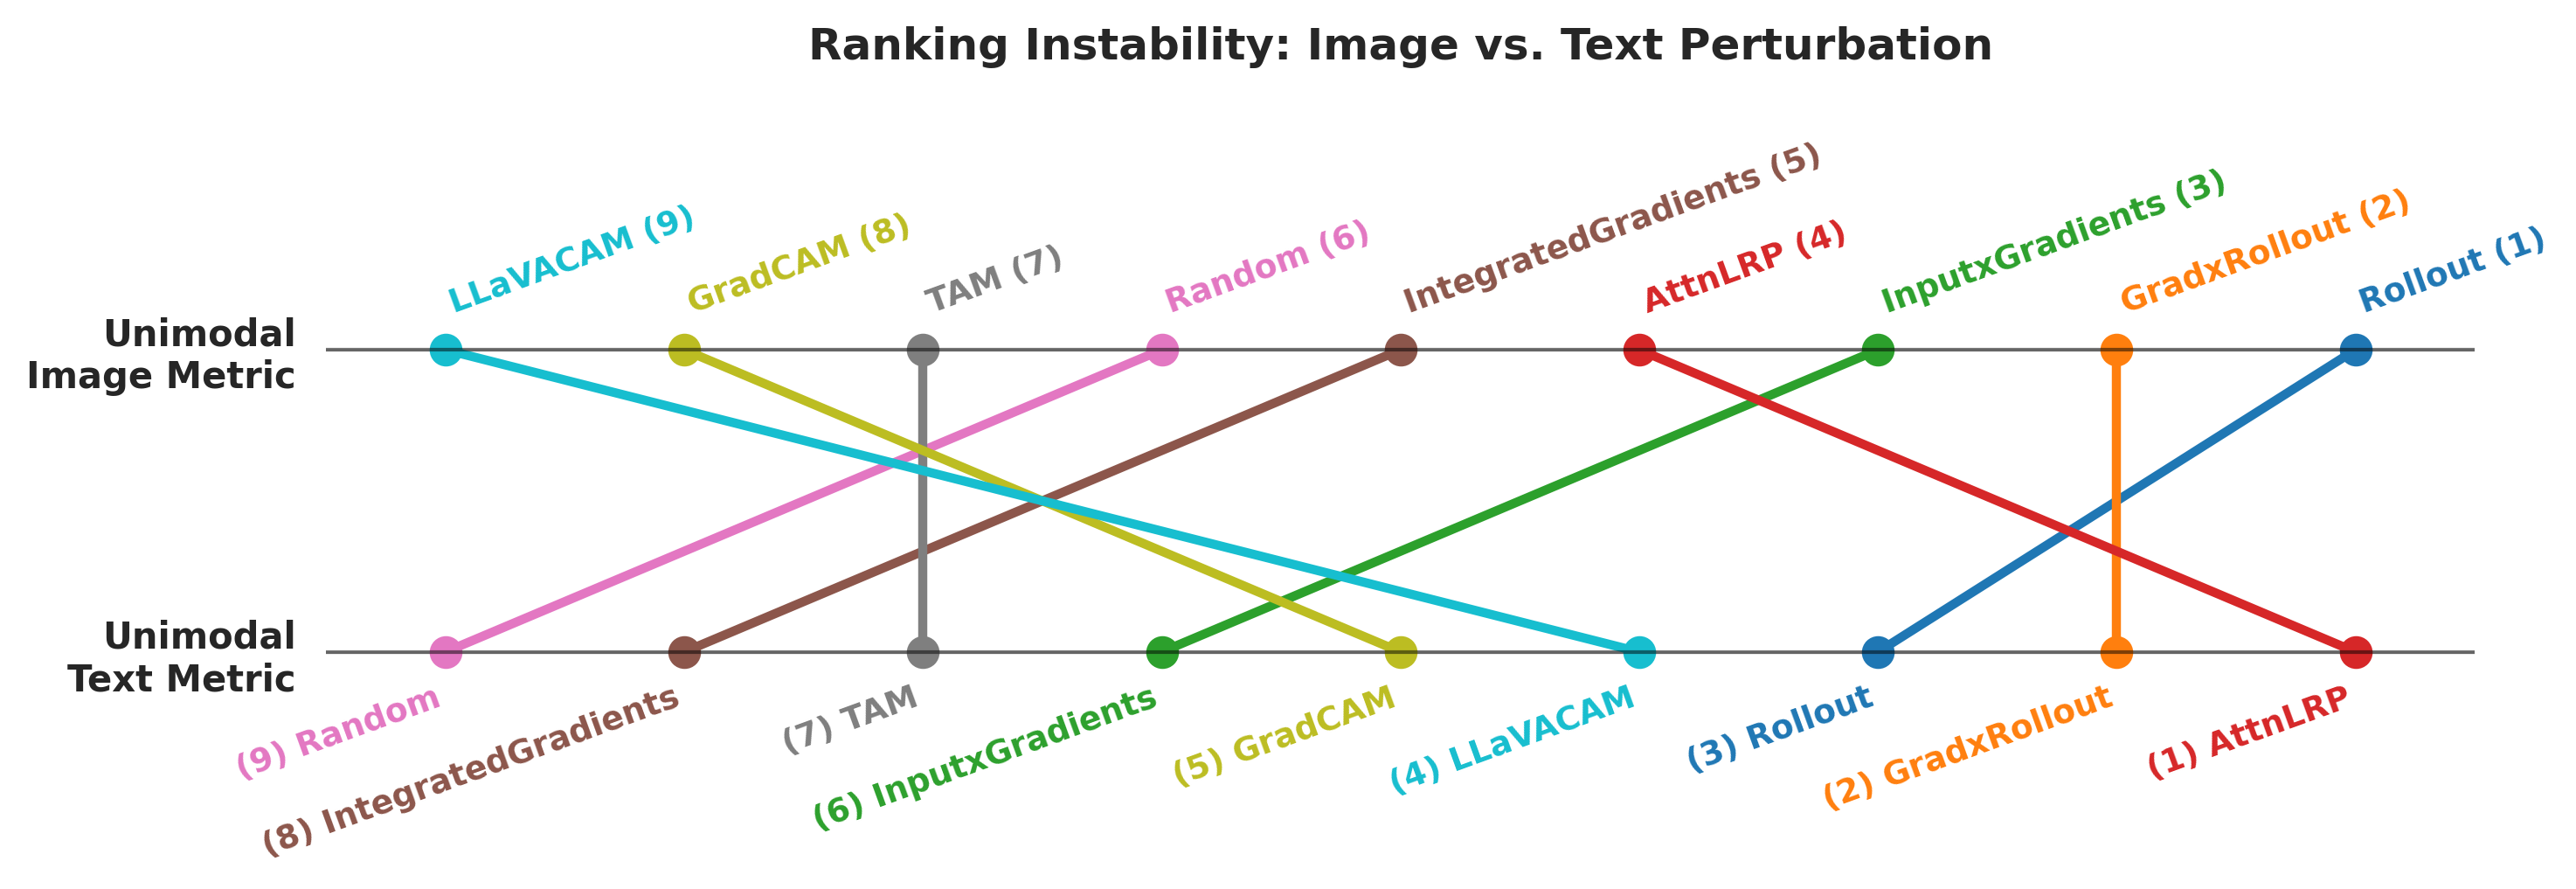

In [138]:
metric = "srg_norm"
IMG_METRIC = f'img_{metric}'
# TOK_METRIC = f''tok_{metric}''
TOK_METRIC = f'tok_{metric}'

# Run the function
tau_df = compute_kendalls_tau(df, IMG_METRIC, TOK_METRIC)
# Run the plotting function
plot_rank_shift_bump_chart(df, IMG_METRIC, TOK_METRIC, savefig=True)



[*] Saved: ../figs/rank_shift_repope_all.pdf


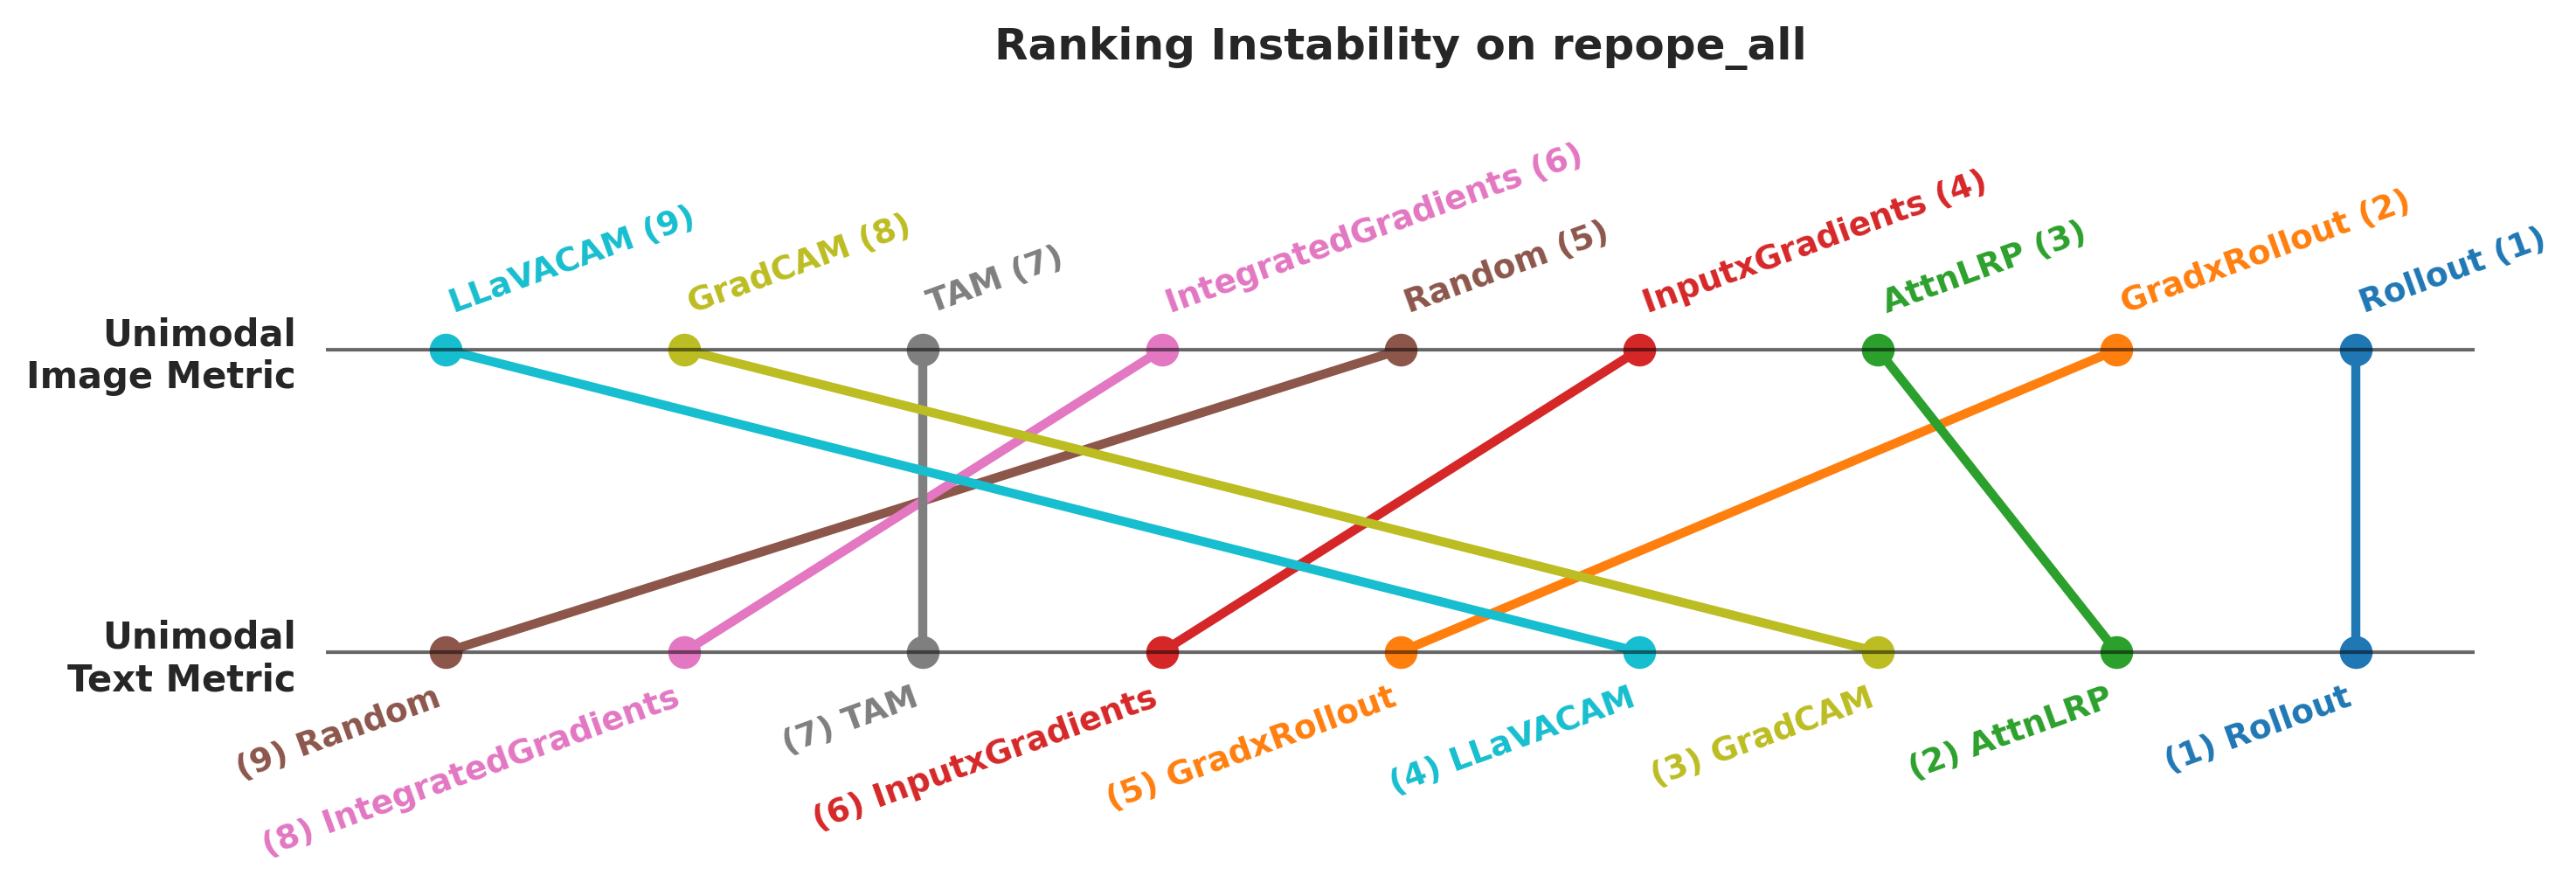

[*] Saved: ../figs/rank_shift_cv_bench.pdf


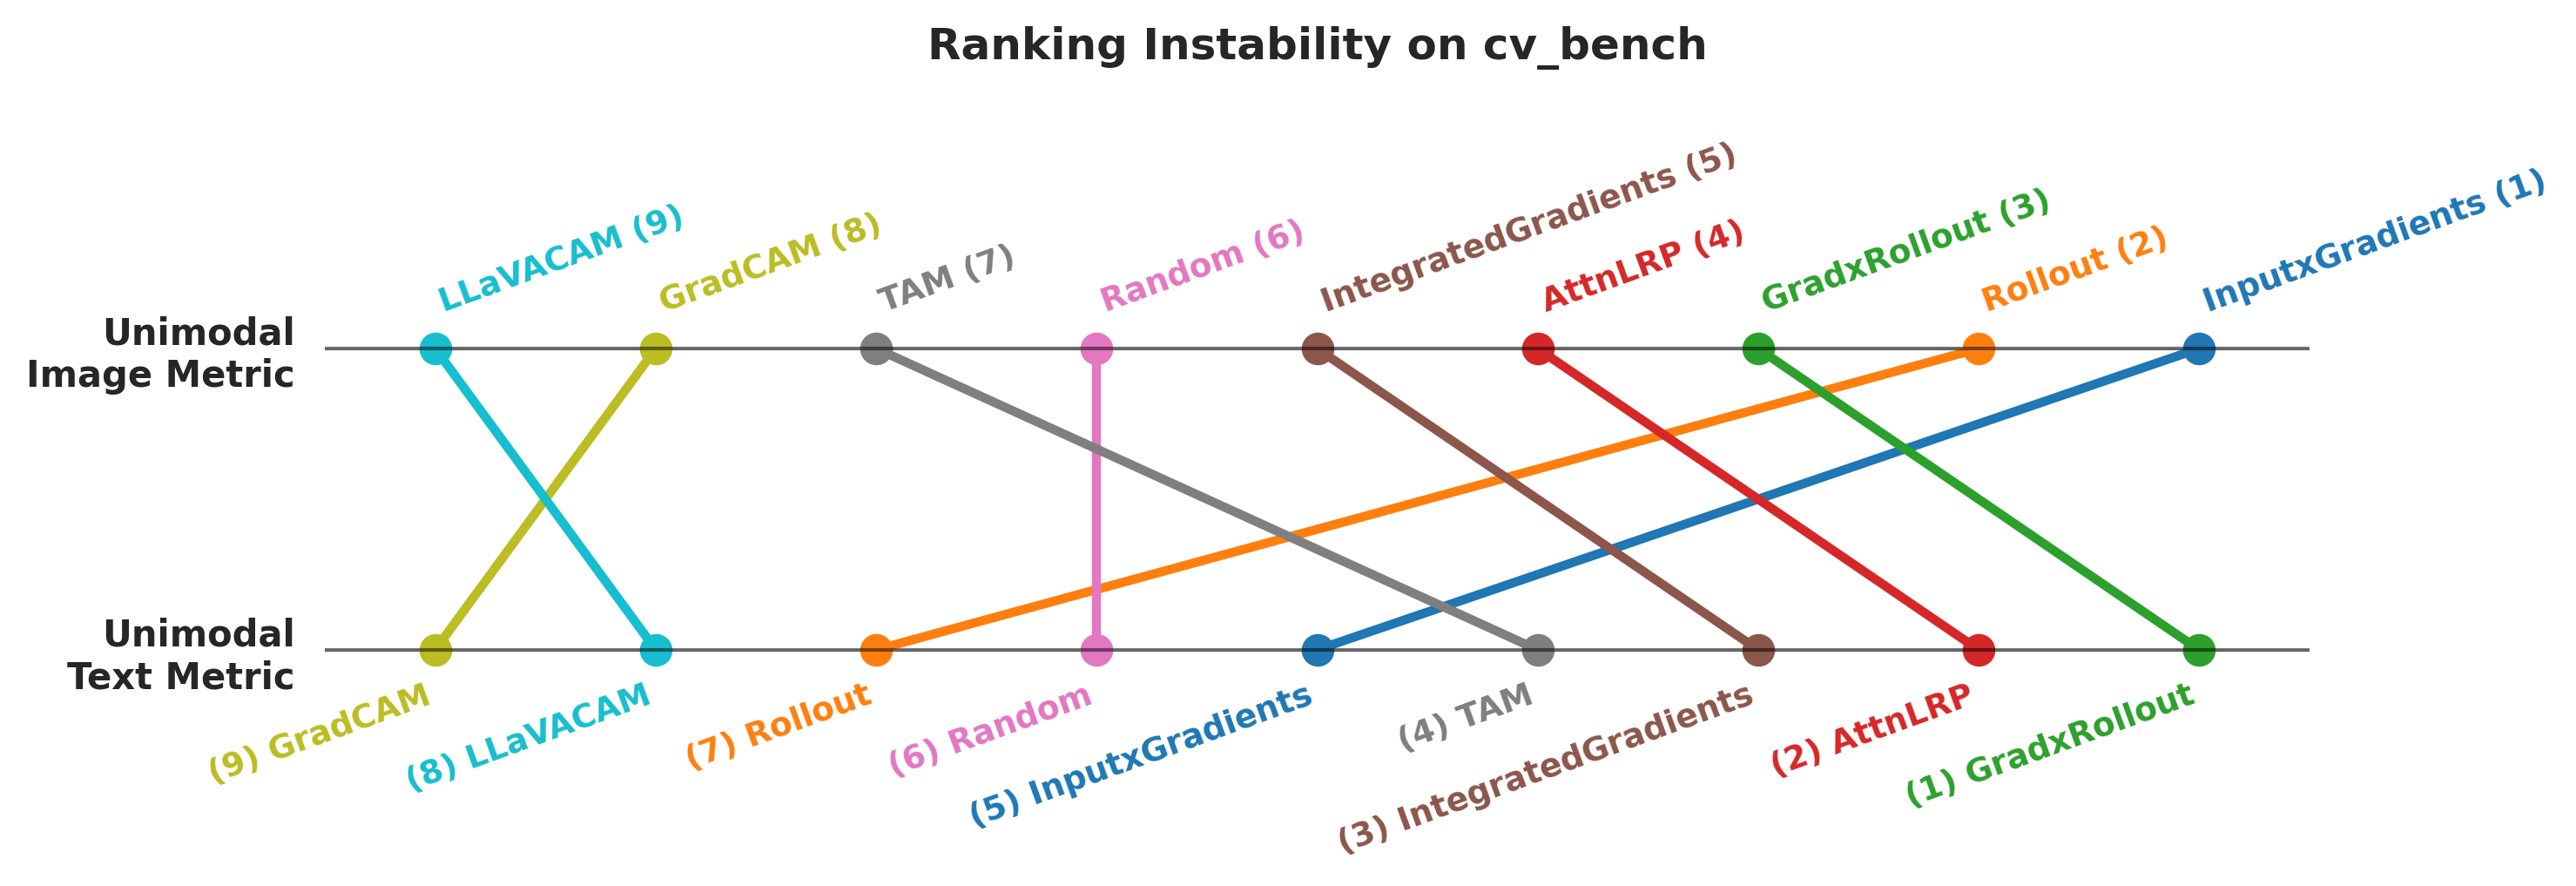

[*] Saved: ../figs/rank_shift_mmstar.pdf


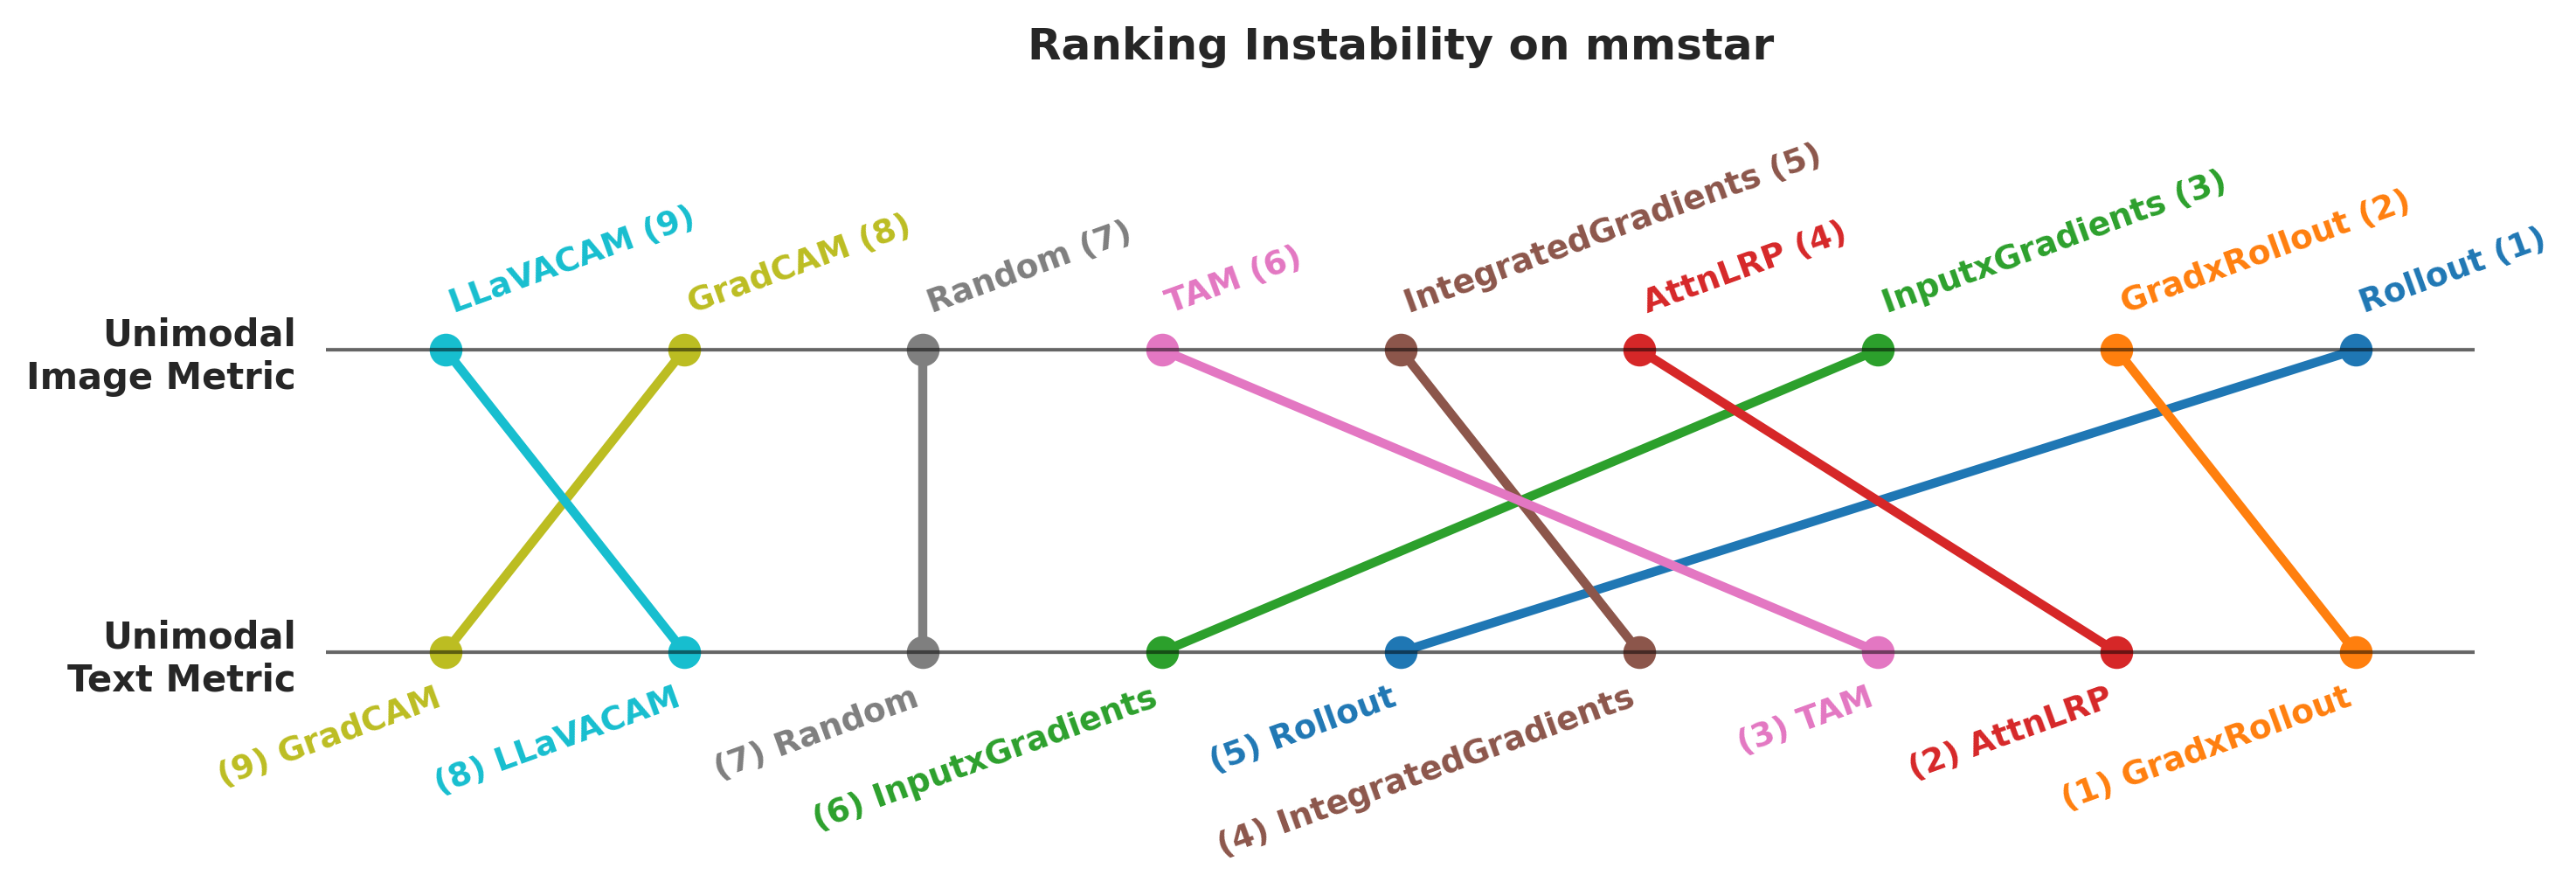

In [139]:
plot_dataset_wise_bump_charts(df, IMG_METRIC, TOK_METRIC, savefig=True)

#### Benchmark results

In [14]:
df.columns

Index(['sample_idx', 'question', 'Explainer', 'xai_gen_time', 'label',
       'syn_synergy_auc', 'syn_synergy_norm_auc', 'syn_del_norm_auc',
       'syn_ins_norm_auc', 'syn_del_auc', 'syn_ins_auc', 'Model', 'Dataset',
       'tok_srg_norm', 'tok_srg', 'img_srg_norm', 'img_srg',
       'img_norm_auc_del', 'img_norm_auc_ins', 'img_auc_del', 'img_auc_ins',
       'tok_norm_auc_del', 'tok_norm_auc_ins', 'tok_auc_del', 'tok_auc_ins'],
      dtype='object')

##### LMM Plots

In [14]:
import pandas as pd
import statsmodels.formula.api as smf
import os

def compute_and_save_lmm(
    df: pd.DataFrame,
    output_path: str,
    target_datasets: list = None,
    baseline_explainer: str = 'Random',
    score_col: str = 'syn_synergy_norm_auc'
):
    """
    Fits a Linear Mixed-Effects Model (LMM) and saves the fixed effects to a CSV.
    
    Args:
        df: The full benchmark dataframe.
        output_path: Where to save the CSV results.
        target_datasets: List of dataset names to filter by (e.g., ['repope']). If None, uses all.
        baseline_explainer: The explainer to treat as the reference (intercept).
        score_col: The target metric column.
    """
    # 1. Filter dataset if requested
    if target_datasets is not None:
        df = df[df['Dataset'].isin(target_datasets)].copy()
        if len(df) == 0:
            raise ValueError(f"Filtered dataframe is empty. Check dataset names: {target_datasets}")
    else:
        df = df.copy()

    # 2. Set the reference category for the Explainer dynamically
    unique_explainers = [e for e in df['Explainer'].unique() if e != baseline_explainer]
    ordered_explainers = [baseline_explainer] + unique_explainers
    
    df['Explainer'] = pd.Categorical(df['Explainer'], categories=ordered_explainers, ordered=True)

    # 3. Setup the Dummy Group for crossed random effects
    df['dummy_group'] = 1

    # 4. Dynamically build the Variance Components (Random Effects)
    # We ALWAYS want Model and sample_idx as random effects
    vcf = {
        "Model": "0 + C(Model)",
        "sample_idx": "0 + C(sample_idx)"
    }

    # ONLY include Dataset as a random effect if we are evaluating multiple datasets.
    if target_datasets is None or len(target_datasets) > 1:
        vcf["Dataset"] = "0 + C(Dataset)"

    # 5. Define and Fit the Model
    formula = f"{score_col} ~ C(Explainer)"
    print(f"\n--- Fitting LMM ---")
    print(f"Datasets: {target_datasets if target_datasets else 'All (Global)'}")
    print(f"Random Effects: {list(vcf.keys())}")
    
    model = smf.mixedlm(
        formula=formula,
        data=df,
        groups=df['dummy_group'],
        vc_formula=vcf
    )

    print("Fitting model (this may take a minute)...")
    result = model.fit()

    # 6. Extract the Fixed Effects (Coefficients, CIs, P-values)
    summary_df = pd.DataFrame({
        'term': result.params.index,
        'coef': result.params,
        'se': result.bse,              # Standard Error (Useful for your table)
        'lower_ci': result.conf_int()[0],
        'upper_ci': result.conf_int()[1],
        'pvalue': result.pvalues
    })

    # Clean up the term names (statsmodels outputs things like "C(Explainer)[T.TAM]")
    # This regex extracts just the explainer name. It leaves the Intercept and random effects alone.
    summary_df['Explainer'] = summary_df['term'].str.extract(r'\[T\.(.*)\]').fillna(summary_df['term'])

    # Filter out the variance component rows (we only want the Explainer fixed effects and intercept)
    # summary_df = summary_df[~summary_df['Explainer'].str.contains('Var')]
    
    # Clean up columns and set intercept to represent the baseline explicitly
    summary_df.loc[summary_df['Explainer'] == 'Intercept', 'Explainer'] = f'Intercept ({baseline_explainer})'
    summary_df = summary_df[['Explainer', 'coef', 'se', 'pvalue', 'lower_ci', 'upper_ci']]

    # 7. Save to CSV
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    summary_df.to_csv(output_path, index=True)
    print(f"Successfully saved LMM results to {output_path}")

    return summary_df



In [29]:
# 2. RePOPE Specific LMM
repope_df = compute_and_save_lmm(
    df=df, 
    output_path="../logs/lmm_repope_fsyn.csv",
    target_datasets=['repope_all']
)



--- Fitting LMM ---
Datasets: ['repope_all']
Random Effects: ['Model', 'sample_idx']
Fitting model (this may take a minute)...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Successfully saved LMM results to ../logs/lmm_repope_fsyn.csv


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


In [26]:
# 3. CVBench Specific LMM
cvbench_df = compute_and_save_lmm(
    df=df, 
    output_path="../logs/lmm_cvbench_fsyn.csv",
    target_datasets=['cv_bench']
)



--- Fitting LMM ---
Datasets: ['cv_bench']
Random Effects: ['Model', 'sample_idx']
Fitting model (this may take a minute)...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Successfully saved LMM results to ../logs/lmm_cvbench_fsyn.csv


In [15]:

# 4. MMStar Specific LMM
mmstar_df = compute_and_save_lmm(
    df=df, 
    output_path="../logs/lmm_mmstar_fsyn.csv",
    target_datasets=['mmstar']
)


--- Fitting LMM ---
Datasets: ['mmstar']
Random Effects: ['Model', 'sample_idx']
Fitting model (this may take a minute)...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Successfully saved LMM results to ../logs/lmm_mmstar_fsyn.csv


In [17]:
def generate_forest_plot(summary_df=None,
                        savefig=False, format='pdf',
                        summary_csv_path="../logs/lmm_whole.csv",
                        save_path="lmm_forest_plot"
                                  ):
    print("--- Generating Upgraded LMM Forest Plot ---")
    
    # 1. Load and clean the dataframe
    if summary_df is None:
        summary_df = pd.read_csv(summary_csv_path, index_col=0)

    explainer_df = summary_df[summary_df.index.str.contains(r"C\(Explainer\)\[T\.")].copy()

    # Clean up the index names
    explainer_df.index = explainer_df.index.str.replace("C(Explainer)[T.", "", regex=False).str.replace("]", "", regex=False)

    # Sort the explainers by coefficient value
    explainer_df = explainer_df.sort_values('coef', ascending=True)

    # 2. Setup the Plot for a clean, modern look
    sns.set_theme(style="white", context="paper", font_scale=1.2)
    fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

    y_ticks = np.arange(len(explainer_df))
    xerr_lower = explainer_df['coef'] - explainer_df['lower_ci']
    xerr_upper = explainer_df['upper_ci'] - explainer_df['coef']

    # 3. Add Zebra Striping for readability
    for idx in range(len(y_ticks)):
        if idx % 2 == 0:
            ax.axhspan(idx - 0.5, idx + 0.5, color='#f8f9fa', zorder=0)

    # 4. Generate a dynamic color palette based on the coefficients
    norm = plt.Normalize(explainer_df['coef'].min(), explainer_df['coef'].max())
    cmap = sns.color_palette("crest", as_cmap=True) # A sleek teal/blue scientific gradient
    colors = cmap(norm(explainer_df['coef']))

    # 5. Plot the points, error bars, and exact value labels
    for i, (idx, row) in enumerate(explainer_df.iterrows()):
        # Draw the error bar
        ax.errorbar(x=row['coef'], y=i,
                    xerr=[[xerr_lower.iloc[i]], [xerr_upper.iloc[i]]],
                    fmt='none', ecolor=colors[i], elinewidth=2.5, capsize=5, capthick=2, 
                    zorder=2, alpha=0.7)
        
        # Draw the main marker point (larger, with a white border for pop)
        ax.plot(row['coef'], i, marker='o', markersize=12, color=colors[i],
                markeredgecolor='white', markeredgewidth=1.5, zorder=3)

        # Annotate the exact Beta value just to the right of the error bar
        ax.text(row['coef'] + xerr_upper.iloc[i] + 0.0015, i,
                f"+{row['coef']:.3f}", va='center', ha='left',
                fontsize=10, fontweight='bold', color=colors[i])

    # 6. Add the Random Baseline (Zero Line)
    ax.axvline(x=0, color='#e74c3c', linestyle='--', linewidth=2, zorder=1)
    
    # Inline annotation for the baseline instead of a legend
    ax.text(0.0005, 0.05, "Random Baseline", color='#e74c3c', rotation=90,
            va='bottom', ha='left', fontsize=11, fontweight='bold', alpha=0.8,
            transform=ax.get_xaxis_transform())

    # 7. Formatting the axes and labels
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(explainer_df.index, fontweight='bold')
    ax.set_xlabel(r'LMM fixed Effect ($\beta$) vs. Random explainer baseline', fontweight='bold', labelpad=10)
    ax.set_title('Explainer faithfulness: LMM fixed effects', fontweight='bold', pad=20, fontsize=14)

    # Clean up spines and add an x-axis grid
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False) # Remove left spine so zebra stripes sit flush with labels
    ax.grid(axis='x', linestyle=':', alpha=0.6, zorder=0)

    # Dynamically stretch the x-axis limit so our new text labels aren't cut off
    max_val = explainer_df['upper_ci'].max()
    ax.set_xlim(-0.002, max_val + 0.006) 

    plt.tight_layout()

    if savefig:
        full_save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(full_save_path, format=format, bbox_inches='tight')
        print(f"[*] Saved stunning figure to {full_save_path}")
        
    plt.show()

--- Generating Upgraded LMM Forest Plot ---
[*] Saved stunning figure to ../figs/lmm_forest_plot.pdf


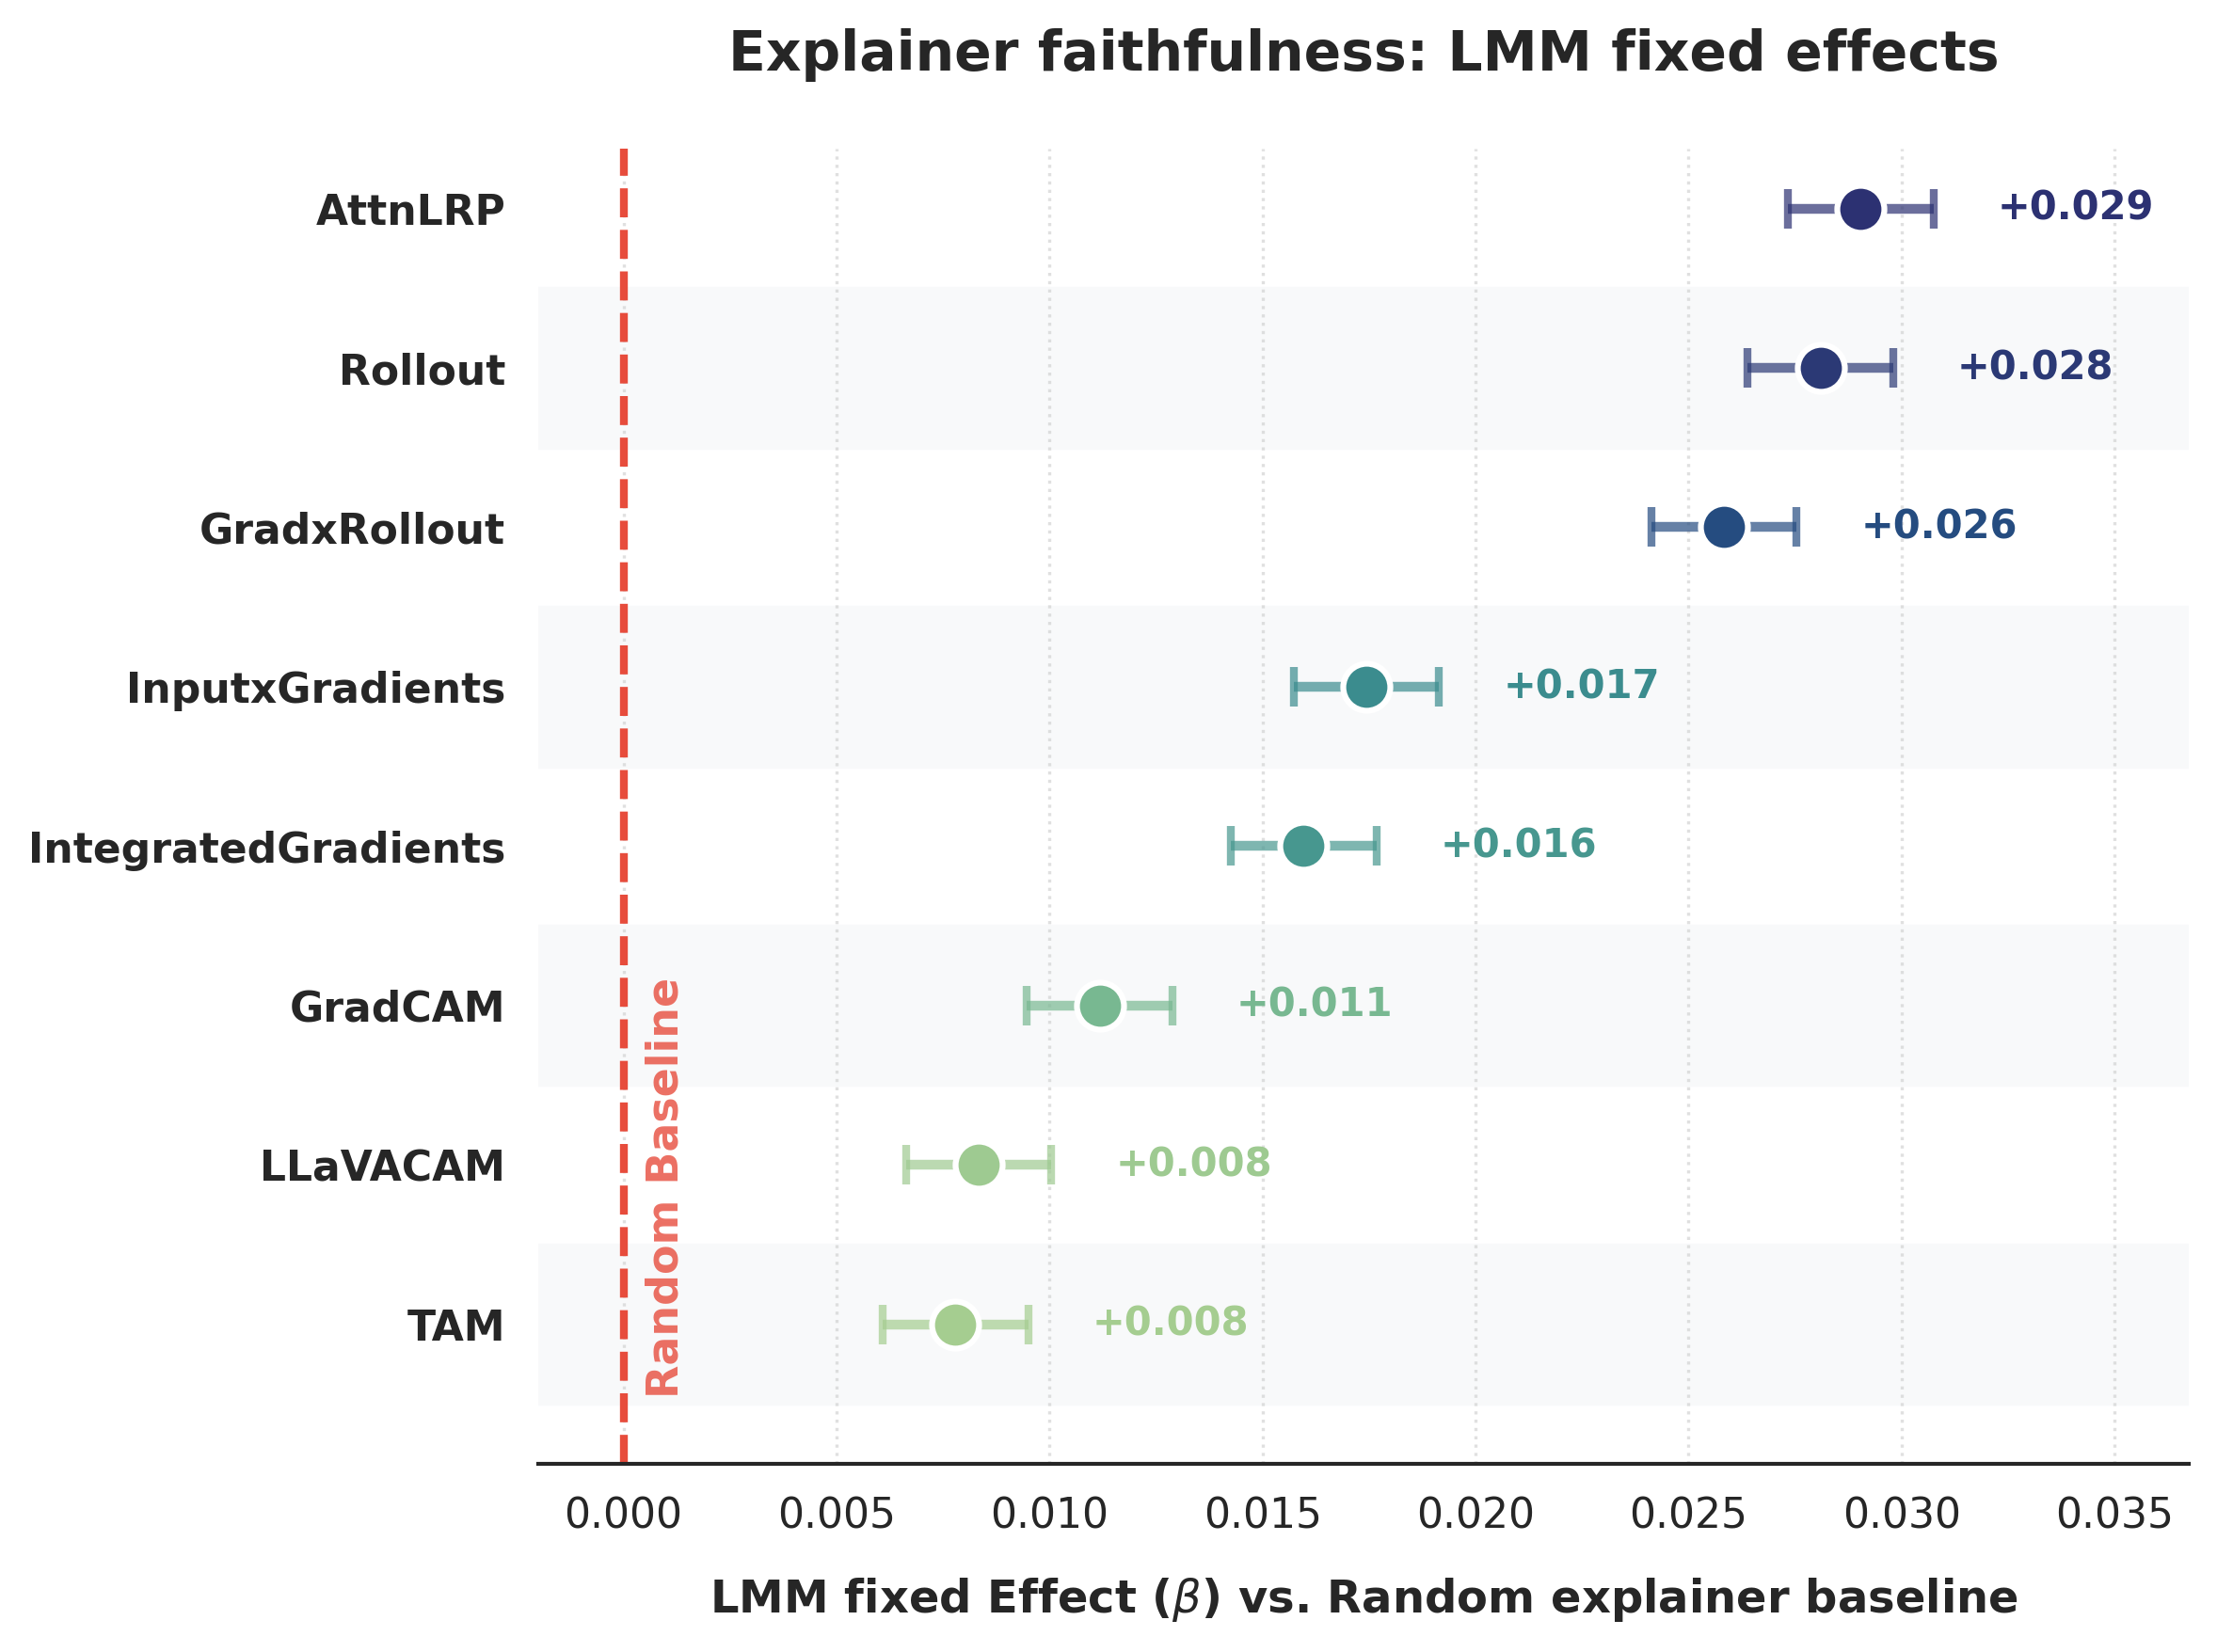

In [32]:
generate_forest_plot(summary_df=None,
                    savefig=True, format='pdf',
                    save_path="lmm_forest_plot")

--- Generating Upgraded LMM Forest Plot ---
[*] Saved stunning figure to ../figs/lmm_mmstar_forest_plot.pdf


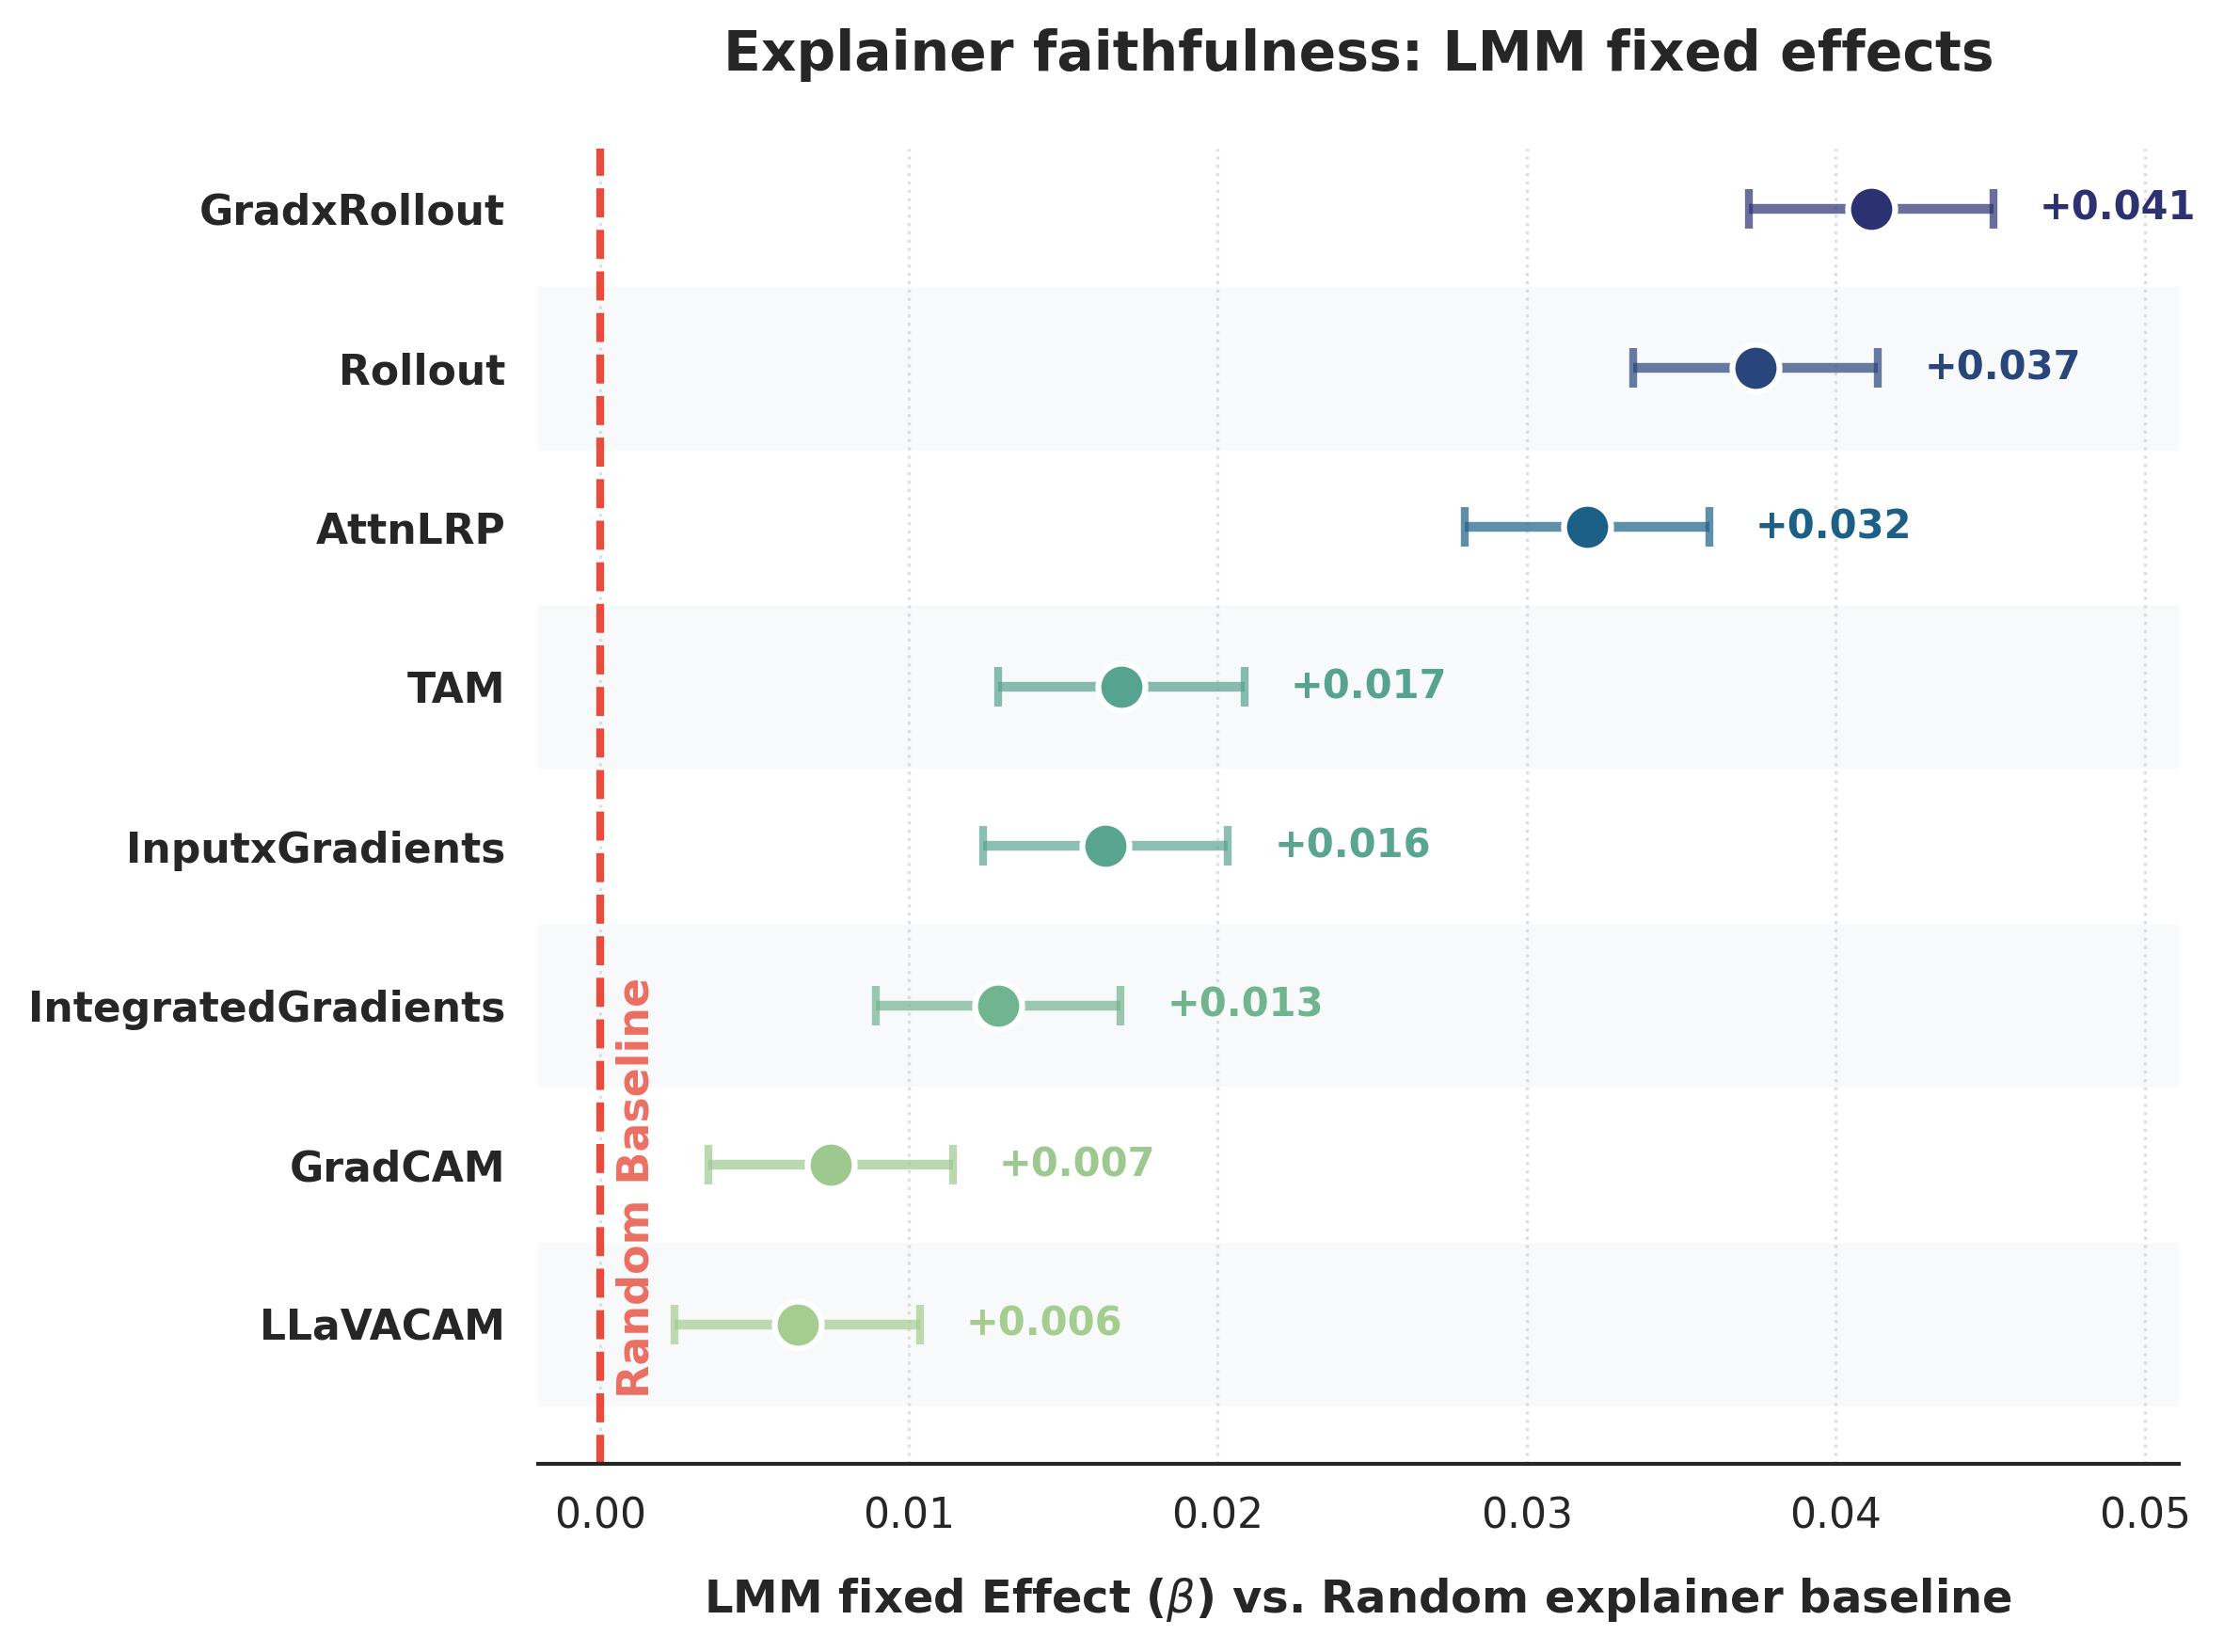

In [33]:
generate_forest_plot(summary_df=mmstar_df,
                    savefig=True, format='pdf',
                    save_path="lmm_mmstar_forest_plot")

--- Generating Upgraded LMM Forest Plot ---
[*] Saved stunning figure to ../figs/lmm_cvbench_forest_plot.pdf


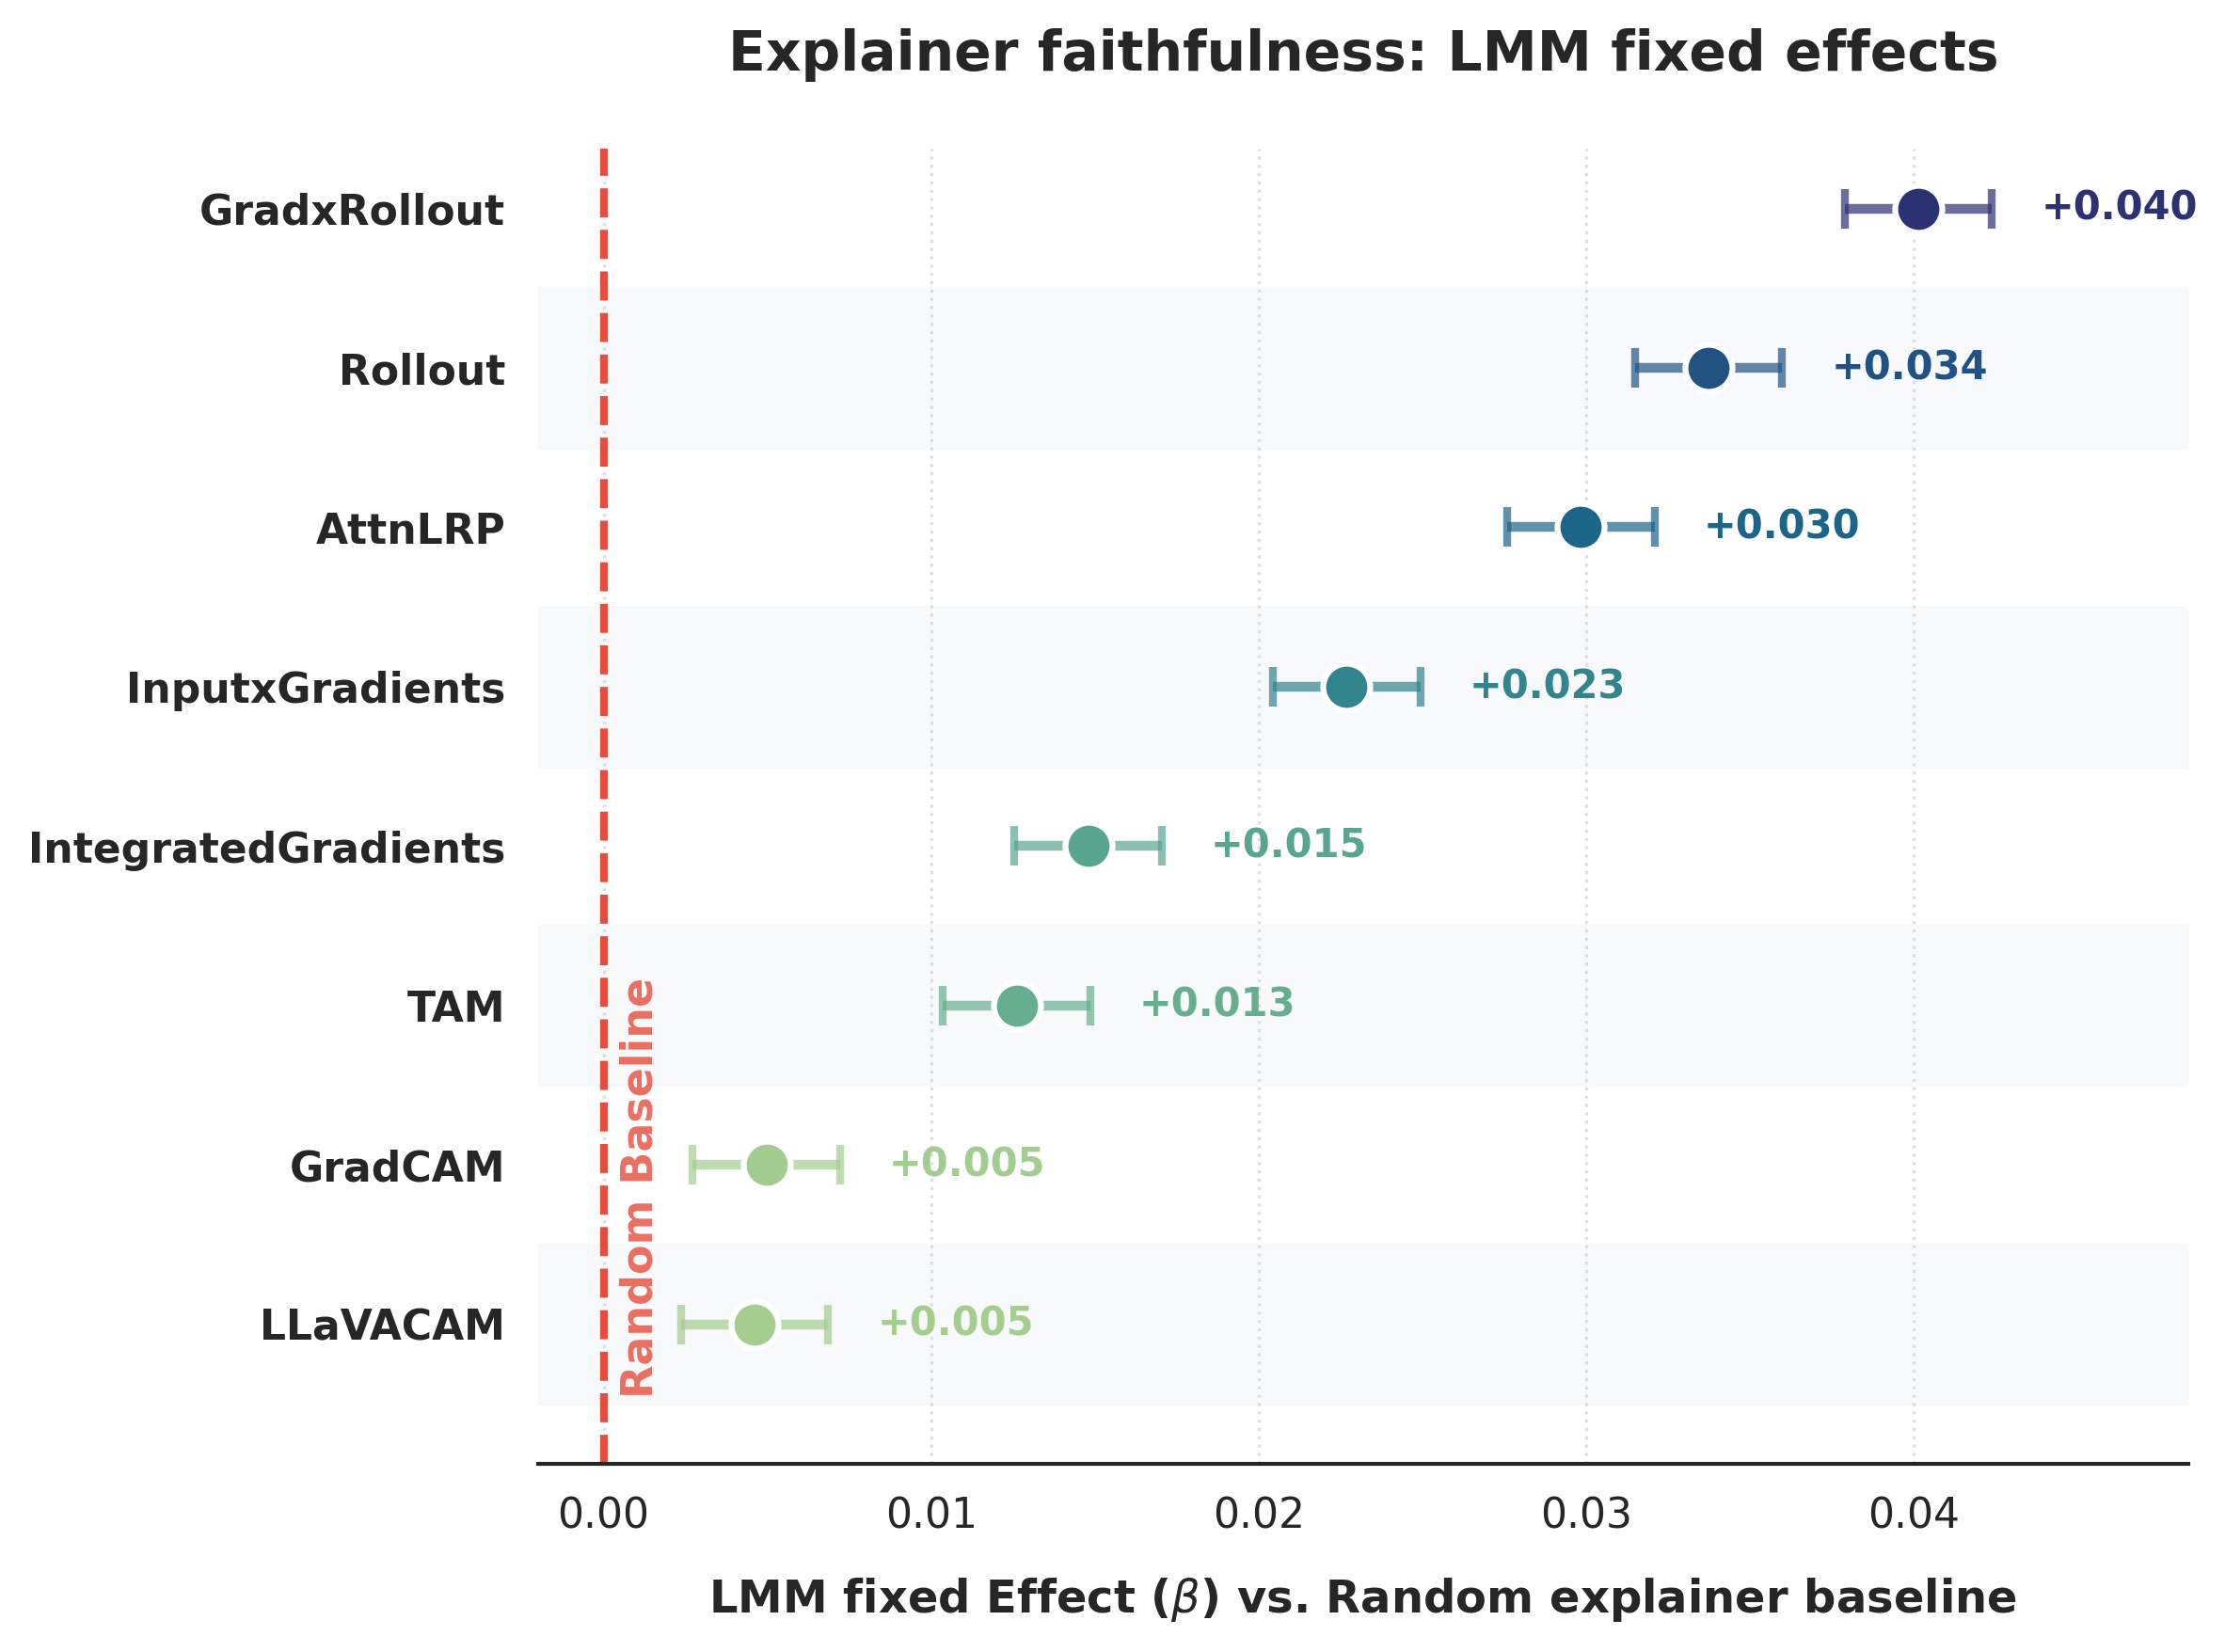

In [34]:
generate_forest_plot(summary_df=cvbench_df,
                    savefig=True, format='pdf',
                    save_path="lmm_cvbench_forest_plot")

--- Generating Upgraded LMM Forest Plot ---
[*] Saved stunning figure to ../figs/lmm_repope_forest_plot.pdf


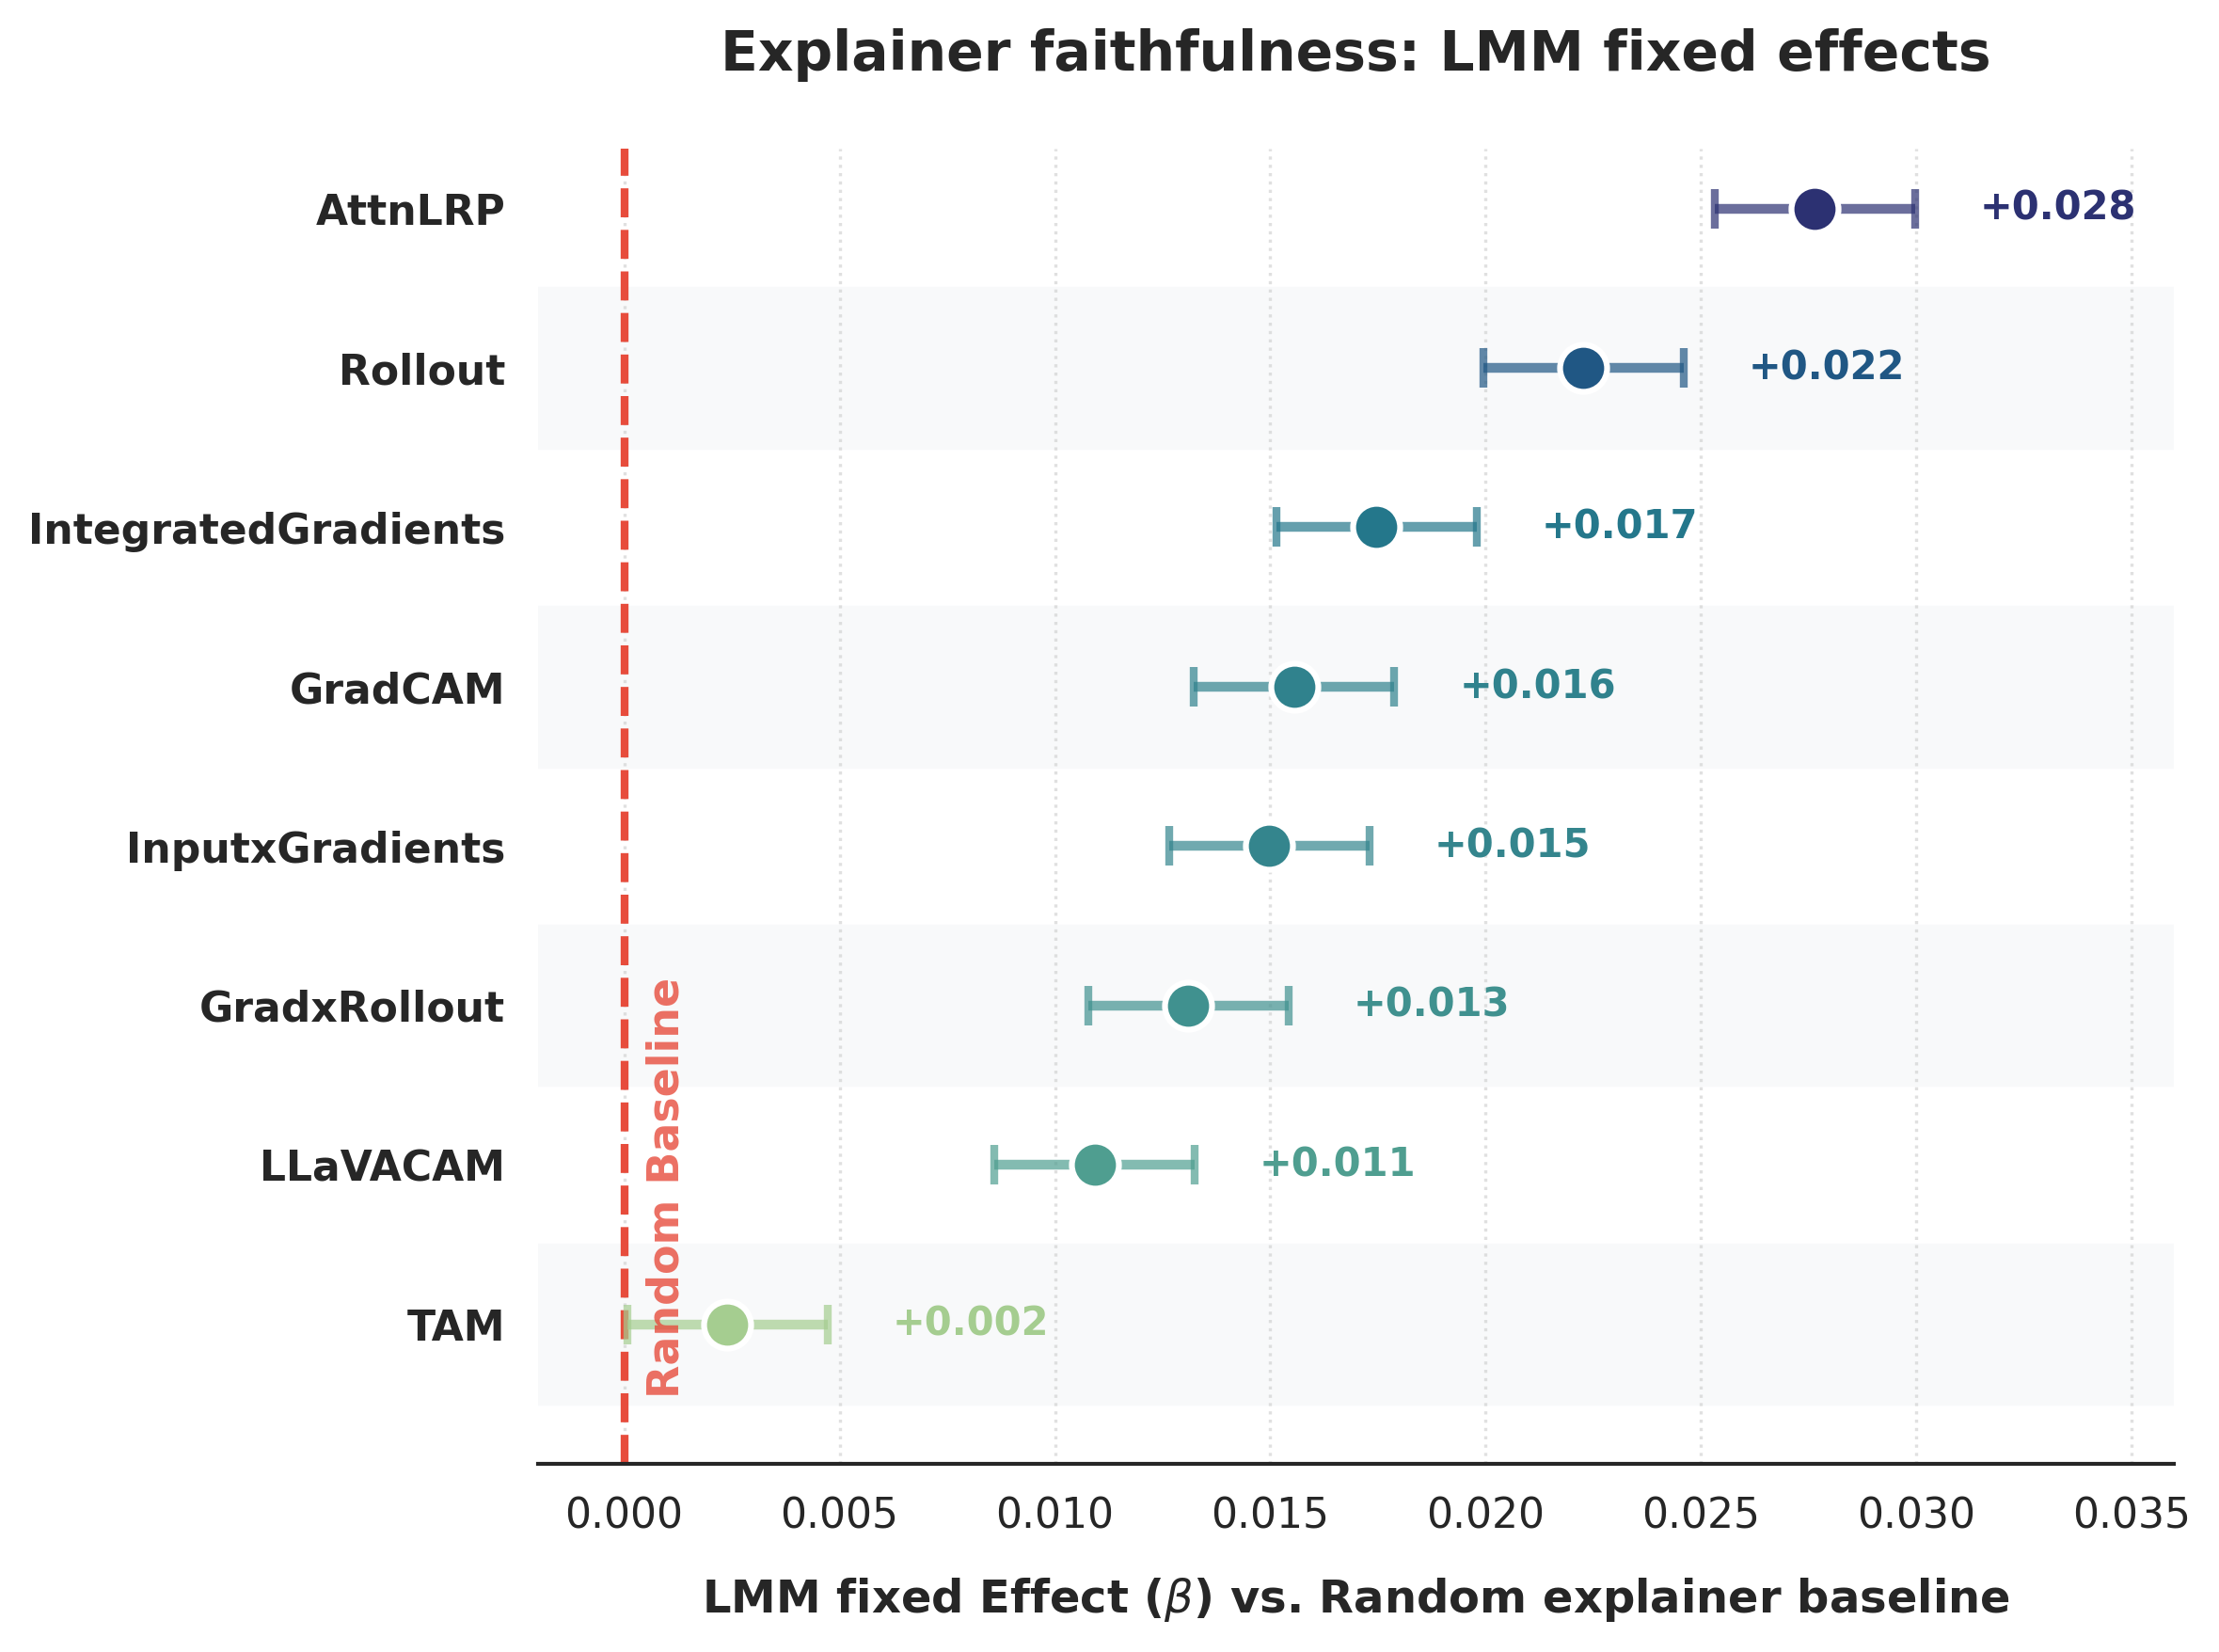

In [35]:
generate_forest_plot(summary_df=repope_df,
                    savefig=True, format='pdf',
                    save_path="lmm_repope_forest_plot")

In [56]:
import pandas as pd
import numpy as np

def format_pvalue(p):
    """Formats the p-value with LaTeX significance stars."""
    if pd.isna(p):
        return "---"
    if p < 0.001:
        return r"$<0.001^{***}$"
    elif p < 0.01:
        return f"${p:.3f}^{{**}}$"
    elif p < 0.05:
        return f"${p:.3f}^{{*}}$"
    else:
        return f"${p:.3f}$"

def generate_latex_lmm_table(repope_path, cvbench_path, mmstar_path):
    """Reads the LMM CSVs and generates the complete LaTeX table."""
    
    # 1. Load the dataframes and set the Explainer column as index
    df_repope = pd.read_csv(repope_path).set_index('Explainer')
    df_cvbench = pd.read_csv(cvbench_path).set_index('Explainer')
    df_mmstar = pd.read_csv(mmstar_path).set_index('Explainer')

    # print(df_cvbench)
    # print(df_repope)
    # print(df_mmstar)

    # Add suffixes to differentiate the columns during concatenation
    df_repope.columns = [f"{c}_rep" for c in df_repope.columns]
    df_cvbench.columns = [f"{c}_cvb" for c in df_cvbench.columns]
    df_mmstar.columns = [f"{c}_mms" for c in df_mmstar.columns]

    # Combine them into one master dataframe
    df_merged = pd.concat([df_repope, df_cvbench, df_mmstar], axis=1)

    # 2. Define the exact grouping and LaTeX-formatted names
    # Dictionary mapping: { "Name in CSV" : "Beautiful LaTeX Name" }
    explainer_groups = [
        # Group 1: Attention-based
        {
            'AttnLRP': 'AttnLRP',
            'GradxRollout': r'Grad$\times$Rollout',
            'Rollout': 'Rollout'
        },
        # Group 2: VLM-native
        {
            'TAM': 'TAM',
            'LLaVACAM': 'LLaVA-CAM'
        },
        # Group 3: Classical
        {
            'GradCAM': 'GradCAM',
            'InputxGradients': r'Input$\times$Grad',
            'IntegratedGradients': 'Integ. Gradients'
        }
    ]

    # 3. Build the LaTeX String
    latex_str = r"""\begin{table}[h]
\centering
\caption{Dataset-Specific LMM Statistics for $\mathcal{F}_{syn}$. All values are calculated relative to the Random Attribution baseline. Significance thresholds: $^* p < 0.05$, $^{**} p < 0.01$, $^{***} p < 0.001$.}
\label{tab:lmm_pvalues}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l | r r r | r r r | r r r}
\toprule
\textbf{} & \multicolumn{3}{c|}{\textbf{RePOPE}} & \multicolumn{3}{c|}{\textbf{CVBench}} & \multicolumn{3}{c}{\textbf{MMStar}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10}
\textbf{Explainer} & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value \\
\midrule
"""

    # 4. Iterate through groups and build rows
    for i, group in enumerate(explainer_groups):
        for raw_name, latex_name in group.items():
            # If the explainer isn't in the dataframe, skip it gracefully
            if raw_name not in df_merged.index:
                continue
            
            row = df_merged.loc[raw_name]
            
            # Format RePOPE
            rep_coef = f"{row['coef_rep']:.3f}"
            rep_se   = f"{row['se_rep']:.3f}"
            rep_p    = format_pvalue(row['pvalue_rep'])
            
            # Format CVBench
            cvb_coef = f"{row['coef_cvb']:.3f}"
            cvb_se   = f"{row['se_cvb']:.3f}"
            cvb_p    = format_pvalue(row['pvalue_cvb'])
            
            # Format MMStar
            mms_coef = f"{row['coef_mms']:.3f}"
            mms_se   = f"{row['se_mms']:.3f}"
            mms_p    = format_pvalue(row['pvalue_mms'])
            
            # Add the row to the table
            latex_str += f"{latex_name} & {rep_coef} & {rep_se} & {rep_p} & {cvb_coef} & {cvb_se} & {cvb_p} & {mms_coef} & {mms_se} & {mms_p} \\\\\n"
        
        # Add a midrule after each group (except the last one)
        if i < len(explainer_groups) - 1:
            latex_str += "\\midrule\n"

    # 5. Finish the table
    latex_str += r"""\bottomrule
\end{tabular}%
}
\end{table}"""

    return latex_str



In [57]:
# ==========================================
# HOW TO RUN IT:
# ==========================================
# Point these paths to the CSVs generated by your compute_and_save_lmm() function
repope_csv = "../logs/lmm_repope_fsyn.csv"
cvbench_csv = "../logs/lmm_cvbench_fsyn.csv"
mmstar_csv = "../logs/lmm_mmstar_fsyn.csv"

# Generate and print the LaTeX code!
final_latex = generate_latex_lmm_table(repope_csv, cvbench_csv, mmstar_csv)
print(final_latex)


\begin{table}[h]
\centering
\caption{Dataset-Specific LMM Statistics for $\mathcal{F}_{syn}$. All values are calculated relative to the Random Attribution baseline. Significance thresholds: $^* p < 0.05$, $^{**} p < 0.01$, $^{***} p < 0.001$.}
\label{tab:lmm_pvalues}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l | r r r | r r r | r r r}
\toprule
\textbf{} & \multicolumn{3}{c|}{\textbf{RePOPE}} & \multicolumn{3}{c|}{\textbf{CVBench}} & \multicolumn{3}{c}{\textbf{MMStar}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10}
\textbf{Explainer} & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value \\
\midrule
AttnLRP & 0.028 & 0.001 & $<0.001^{***}$ & 0.030 & 0.001 & $<0.001^{***}$ & 0.032 & 0.002 & $<0.001^{***}$ \\
Grad$\times$Rollout & 0.013 & 0.001 & $<0.001^{***}$ & 0.040 & 0.001 & $<0.001^{***}$ & 0.041 & 0.002 & $<0.001^{***}$ \\
Rollout & 0.022 & 0.001 & $<0.001^{***}$ & 0.034 & 0.001 & $<0.001^{***}$ & 0.037 & 0.002 & $<0.001^{***}

In [42]:
print("df1 has duplicate index:", cvbench_df.index.duplicated().any())
print("df2 has duplicate index:", mmstar_df.index.duplicated().any())
print("df2 has duplicate index:", repope_df.index.duplicated().any())

df1 has duplicate index: False
df2 has duplicate index: False
df2 has duplicate index: False


##### Generate table 

In [127]:
import pandas as pd
import numpy as np

def generate_latex_table_with_overall(df, metric='syn_synergy_norm_auc', columns='Model'):
    """
    Generates a Pandas Pivot Table with Mean ± Std, a true Overall column, 
    and exports the LaTeX code.
    """
    print(f"\n--- Generating LaTeX Table for {metric} (Mean ± Std) with OVERALL ---")
    
    # 1. Calculate Mean and Std for the individual columns (e.g., per Model)
    mean_df = df.pivot_table(index='Explainer', columns=columns, values=metric, aggfunc='mean')
    std_df = df.pivot_table(index='Explainer', columns=columns, values=metric, aggfunc='std')
    
    # 2. Calculate the TRUE Overall Mean and Std directly from the raw dataframe
    # This prevents the "averaging averages" math error.
    overall_mean = df.groupby('Explainer')[metric].mean()
    overall_std = df.groupby('Explainer')[metric].std()
    
    # Sort explainers from best to worst based on the true overall mean
    overall_mean = overall_mean.sort_values(ascending=False)
    
    # Align all dataframes to the newly sorted index
    mean_df = mean_df.reindex(overall_mean.index)
    std_df = std_df.reindex(overall_mean.index)
    overall_std = overall_std.reindex(overall_mean.index)
    
    # 3. Combine them into formatted strings: "Mean $\pm$ Std"
    combined_df = mean_df.copy()
    for col in mean_df.columns:
        combined_df[col] = mean_df[col].apply(lambda x: f"{x:.3f}") + r"$_{(\pm" + std_df[col].apply(lambda x: f"{x:.2f}") + ")}$"
    
    # 4. Add the formatted Overall column
    combined_df['Overall'] = overall_mean.apply(lambda x: f"{x:.3f}") + r"$_{(\pm" + overall_std.apply(lambda x: f"{x:.2f}") + ")}$"
    
    # 5. Export to LaTeX
    # escape=False prevents Pandas from breaking our LaTeX math formatting
    latex_code = combined_df.to_latex(escape=False)
    
    print(latex_code)
    return combined_df

# Run it!
# table_df = generate_latex_table_with_overall(df, metric='syn_synergy_norm_auc', columns='Model')

In [128]:
pivot = generate_latex_table_with_overall(df, metric='syn_synergy_norm_auc')


--- Generating LaTeX Table for syn_synergy_norm_auc (Mean ± Std) with OVERALL ---
\begin{tabular}{lllll}
\toprule
Model & internvl & llava & qwenvl & Overall \\
Explainer &  &  &  &  \\
\midrule
AttnLRP & 0.186$_{(\pm0.15)}$ & 0.049$_{(\pm0.08)}$ & 0.069$_{(\pm0.11)}$ & 0.102$_{(\pm0.13)}$ \\
Rollout & 0.192$_{(\pm0.17)}$ & 0.054$_{(\pm0.08)}$ & 0.056$_{(\pm0.10)}$ & 0.101$_{(\pm0.14)}$ \\
GradxRollout & 0.186$_{(\pm0.16)}$ & 0.053$_{(\pm0.08)}$ & 0.056$_{(\pm0.10)}$ & 0.099$_{(\pm0.13)}$ \\
InputxGradients & 0.171$_{(\pm0.14)}$ & 0.044$_{(\pm0.06)}$ & 0.055$_{(\pm0.09)}$ & 0.090$_{(\pm0.12)}$ \\
IntegratedGradients & 0.163$_{(\pm0.14)}$ & 0.039$_{(\pm0.06)}$ & 0.062$_{(\pm0.10)}$ & 0.089$_{(\pm0.12)}$ \\
GradCAM & 0.144$_{(\pm0.13)}$ & 0.042$_{(\pm0.06)}$ & 0.065$_{(\pm0.10)}$ & 0.084$_{(\pm0.11)}$ \\
LLaVACAM & 0.143$_{(\pm0.13)}$ & 0.041$_{(\pm0.06)}$ & 0.058$_{(\pm0.09)}$ & 0.081$_{(\pm0.11)}$ \\
TAM & 0.142$_{(\pm0.13)}$ & 0.041$_{(\pm0.06)}$ & 0.057$_{(\pm0.10)}$ & 0.081$_{(\pm0

In [47]:
df.Dataset.unique()

array(['repope_all', 'cv_bench', 'mmstar'], dtype=object)

##### Other plots

In [15]:
df.head()

,sample_idx,question,Explainer,xai_gen_time,label,syn_synergy_auc,syn_synergy_norm_auc,syn_del_norm_auc,syn_ins_norm_auc,syn_del_auc,...,img_srg_norm,img_srg,img_norm_auc_del,img_norm_auc_ins,img_auc_del,img_auc_ins,tok_norm_auc_del,tok_norm_auc_ins,tok_auc_del,tok_auc_ins
0,0,Is there a snowboard in the image?,LLaVACAM,5.528804,yes,-0.203427,0.003922,0.007797,0.000047,-0.159337,...,0.089499,0.070239,0.470024,0.559524,0.510962,0.581201,0.311362,0.482354,0.293529,0.459483
1,1,Is there a car in the image?,LLaVACAM,6.026171,no,0.002150,0.014125,0.001659,0.026591,-0.021948,...,-0.037500,-0.002734,0.883333,0.845833,0.973438,0.970703,0.466356,0.354049,0.190558,0.138512
2,2,Is there a person in the image?,LLaVACAM,5.402166,yes,0.253993,0.279142,0.311483,0.246800,0.285203,...,-0.255605,-0.233533,0.686057,0.430453,0.691138,0.457605,0.307264,0.492782,0.298079,0.481618
3,3,Is there a sandwich in the image?,LLaVACAM,7.141232,no,0.024912,0.031120,0.000801,0.061440,-0.008612,...,-0.043704,-0.021680,0.801852,0.758148,0.749316,0.727637,0.050019,0.825798,0.048862,0.814259
4,4,Is there a skis in the image?,LLaVACAM,5.534935,no,-0.313967,0.021965,0.024832,0.019098,-0.185852,...,0.003049,-0.007715,0.591057,0.594106,0.460229,0.452515,0.319678,0.495919,0.207713,0.365638


In [16]:
mu_I_col="img_srg_norm"
mu_T_col="tok_srg_norm"
syn_col="syn_synergy_norm_auc"
dataset_name="repope_all"

df_sub = df[df['Dataset'] == dataset_name]

grouped = df_sub.groupby(['Model', 'Explainer'])[[mu_I_col, mu_T_col, syn_col]].agg(['mean', 'std'])

In [17]:
grouped

img_srg_norm           tok_srg_norm            \
                                     mean       std         mean       std   
Model    Explainer                                                           
internvl AttnLRP                 0.033054  0.131023     0.238989  0.287857   
         GradCAM                -0.043980  0.246525     0.043193  0.184188   
         GradxRollout            0.017633  0.236173     0.085442  0.157034   
         InputxGradients         0.020503  0.155334     0.030082  0.243998   
         IntegratedGradients    -0.013435  0.127040     0.216205  0.287792   
         LLaVACAM               -0.061689  0.255911     0.021141  0.192610   
         Random                 -0.003562  0.074713     0.039384  0.282764   
         Rollout                 0.211147  0.228183     0.123620  0.122907   
         TAM                    -0.032740  0.263739     0.025504  0.208875   
llava    AttnLRP                 0.013259  0.074705     0.320586  0.243075   
         GradCAM                -0.108324  0.336958     0.288125  0.344932   
         GradxRollout            0.110039  0.263971     0.128583  0.184328   
         InputxGradients         0.012673  0.087303    -0.060342  0.673651   
         IntegratedGradients     0.001360  0.077894    -0.641449  0.298755   
         LLaVACAM               -0.132696  0.364500     0.278511  0.370067   
         Random                  0.002731  0.060061    -0.633332  0.308100   
         Rollout                 0.141391  0.269803     0.531165  0.231564   
         TAM                    -0.075718  0.268917    -0.453946  0.321212   
qwenvl   AttnLRP                -0.000743  0.074923     0.263356  0.387702   
         GradCAM                 0.001938  0.086170     0.217698  0.297992   
         GradxRollout           -0.003399  0.086140     0.050393  0.206649   
         InputxGradients         0.001304  0.073796    -0.028211  0.261762   
         IntegratedGradients    -0.000132  0.075641     0.106536  0.380656   
         LLaVACAM                0.007128  0.094041     0.189277  0.305736   
         Random                 -0.001921  0.073383     0.024060  0.209147   
         Rollout                 0.002321  0.094296     0.236073  0.102360   
         TAM                     0.002473  0.088374     0.192220  0.284919   

                             syn_synergy_norm_auc            
                                             mean       std  
Model    Explainer                                           
internvl AttnLRP                         0.178113  0.163382  
         GradCAM                         0.141772  0.141114  
         GradxRollout                    0.147411  0.145696  
         InputxGradients                 0.158470  0.155866  
         IntegratedGradients             0.162031  0.157159  
         LLaVACAM                        0.139683  0.138446  
         Random                          0.126233  0.124492  
         Rollout                         0.176908  0.177209  
         TAM                             0.122307  0.132601  
llava    AttnLRP                         0.031866  0.050198  
         GradCAM                         0.029220  0.043097  
         GradxRollout                    0.032293  0.048721  
         InputxGradients                 0.028285  0.041377  
         IntegratedGradients             0.023152  0.036482  
         LLaVACAM                        0.028669  0.042911  
         Random                          0.022279  0.035878  
         Rollout                         0.036172  0.050010  
         TAM                             0.024958  0.038474  
qwenvl   AttnLRP                         0.076975  0.130907  
         GradCAM                         0.079462  0.121108  
         GradxRollout                    0.063478  0.117124  
         InputxGradients                 0.062136  0.104055  
         IntegratedGradients             0.071217  0.119742  
         LLaVACAM                        0.068215  0.108282  
         Rando

In [20]:
import pandas as pd
import numpy as np

def format_cell(mean_val, std_val):
    """Formats the mean and std into a compact LaTeX subscript string."""
    if pd.isna(mean_val) or pd.isna(std_val):
        return "---"
    # Format: $0.123_{\pm 0.012}$
    return f"${mean_val:.3f}_{{ \\pm {std_val:.3f} }}$"

def generate_exhaustive_latex_table(df, dataset_name, dataset_label="RePOPE",
                                    mu_I_col="img_srg_norm",
                                    mu_T_col="tok_srg_norm",
                                    syn_col="syn_synergy_norm_auc",
                                    ):
    """
    Generates the exhaustive metric table for a specific dataset.
    
    Assumed dataframe columns:
    - 'Dataset': Name of the dataset
    - 'Model': Architecture name (e.g., 'Qwen', 'LLaVA', 'InternVL')
    - 'Explainer': Name of the XAI method
    - 'mu_I': Unimodal visual score
    - 'mu_T': Unimodal textual score
    - 'F_syn': Synergistic Faithfulness score
    """
    # 1. Filter the dataset
    df_sub = df[df['Dataset'] == dataset_name]
    
    # 2. Group by Model and Explainer to calculate Mean and Std
    # This creates a MultiIndex dataframe
    grouped = df_sub.groupby(['Model', 'Explainer'])[[mu_I_col, mu_T_col, syn_col]].agg(['mean', 'std'])
    
    # 3. Define the exact Explainer grouping and formatting
    explainer_groups = [
        # Group 1: Attention-based
        {'AttnLRP': 'AttnLRP', 'GradxRollout': r'Grad$\times$Rollout', 'Rollout': 'Rollout'},
        # Group 2: VLM-native
        {'TAM': 'TAM', 'LLaVACAM': 'LLaVA-CAM'},
        # Group 3: Classical
        {'GradCAM': 'GradCAM', 'InputxGradients': r'Input$\times$Grad', 'IntegratedGradients': 'Integ. Gradients'},
        # Group 4: Baseline
        {'Random': 'Random (Baseline)'}
    ]
    
    # 4. Define your Models as they appear in your DataFrame
    models = ['qwenvl', 'llava', 'internvl'] # Update these strings to match your data exactly!

    # 5. Build the LaTeX Header
    latex_str = f"""\\begin{{table}}[h]
\\centering
\\caption{{Comprehensive Benchmark Results on the \\textbf{{{dataset_label}}} Dataset. Values represent the unadjusted mean scores $\\pm$ standard deviation across all dataset instances.}}
\\label{{tab:full_{dataset_name.lower()}}}
\\resizebox{{\\textwidth}}{{!}}{{%\n\\begin{{tabular}}{{l | ccc | ccc | ccc}}
\\toprule
& \\multicolumn{{3}}{{c|}}{{\\textbf{{Qwen2.5-VL}}}} & \\multicolumn{{3}}{{c|}}{{\\textbf{{LLaVA-1.5}}}} & \\multicolumn{{3}}{{c}}{{\\textbf{{InternVL-3.5 }}}} \\\\
\\cmidrule(lr){{2-4}} \\cmidrule(lr){{5-7}} \\cmidrule(lr){{8-10}}
\\textbf{{Explainer}} & $\\mu_I^{{srg}}$ & $\\mu_T^{{srg}}$ & $\\mathcal{{F}}_{{syn}}$ & $\\mu_I^{{srg}}$ & $\\mu_T^{{srg}}$ & $\\mathcal{{F}}_{{syn}}$ & $\\mu_I^{{srg}}$ & $\\mu_T^{{srg}}$ & $\\mathcal{{F}}_{{syn}}$ \\\\
\\midrule\n"""

    # 6. Build the Rows
    for i, group in enumerate(explainer_groups):
        for raw_name, latex_name in group.items():
            row_str = f"{latex_name} "
            
            for mod in models:
                try:
                    # Extract the stats for this Model + Explainer combo
                    stats = grouped.loc[(mod, raw_name)]
                    
                    cell_I = format_cell(stats[(mu_I_col, 'mean')], stats[(mu_I_col, 'std')])
                    cell_T = format_cell(stats[(mu_T_col, 'mean')], stats[(mu_T_col, 'std')])
                    cell_F = format_cell(stats[(syn_col, 'mean')], stats[(syn_col, 'std')])
                    
                except KeyError:
                    # If this model/explainer combo wasn't run or is missing
                    cell_I, cell_T, cell_F = "---", "---", "---"
                
                row_str += f"& {cell_I} & {cell_T} & {cell_F} "
            
            row_str += "\\\\\n"
            latex_str += row_str
            
        # Add a midrule after each group (except the last one)
        if i < len(explainer_groups) - 1:
            latex_str += "\\midrule\n"

    # 7. Close the table
    latex_str += r"""\bottomrule
\end{tabular}%
}
\end{table}"""

    return latex_str



In [23]:


# Generate tables for each dataset
table_repope = generate_exhaustive_latex_table(df, dataset_name="repope_all", dataset_label="RePOPE")
print(table_repope)


\begin{table}[h]
\centering
\caption{Comprehensive Benchmark Results on the \textbf{RePOPE} Dataset. Values represent the unadjusted mean scores $\pm$ standard deviation across all dataset instances.}
\label{tab:full_repope_all}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l | ccc | ccc | ccc}
\toprule
& \multicolumn{3}{c|}{\textbf{Qwen2.5-VL}} & \multicolumn{3}{c|}{\textbf{LLaVA-1.5}} & \multicolumn{3}{c}{\textbf{InternVL-3.5 }} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10}
\textbf{Explainer} & $\mu_I^{srg}$ & $\mu_T^{srg}$ & $\mathcal{F}_{syn}$ & $\mu_I^{srg}$ & $\mu_T^{srg}$ & $\mathcal{F}_{syn}$ & $\mu_I^{srg}$ & $\mu_T^{srg}$ & $\mathcal{F}_{syn}$ \\
\midrule
AttnLRP & $-0.001_{ \pm 0.075 }$ & $0.263_{ \pm 0.388 }$ & $0.077_{ \pm 0.131 }$ & $0.013_{ \pm 0.075 }$ & $0.321_{ \pm 0.243 }$ & $0.032_{ \pm 0.050 }$ & $0.033_{ \pm 0.131 }$ & $0.239_{ \pm 0.288 }$ & $0.178_{ \pm 0.163 }$ \\
Grad$\times$Rollout & $-0.003_{ \pm 0.086 }$ & $0.050_{ \pm 0.207 }$ & $0.063_{ \pm 0

[*] Saved boxplot_syn_synergy_auc_global.pdf


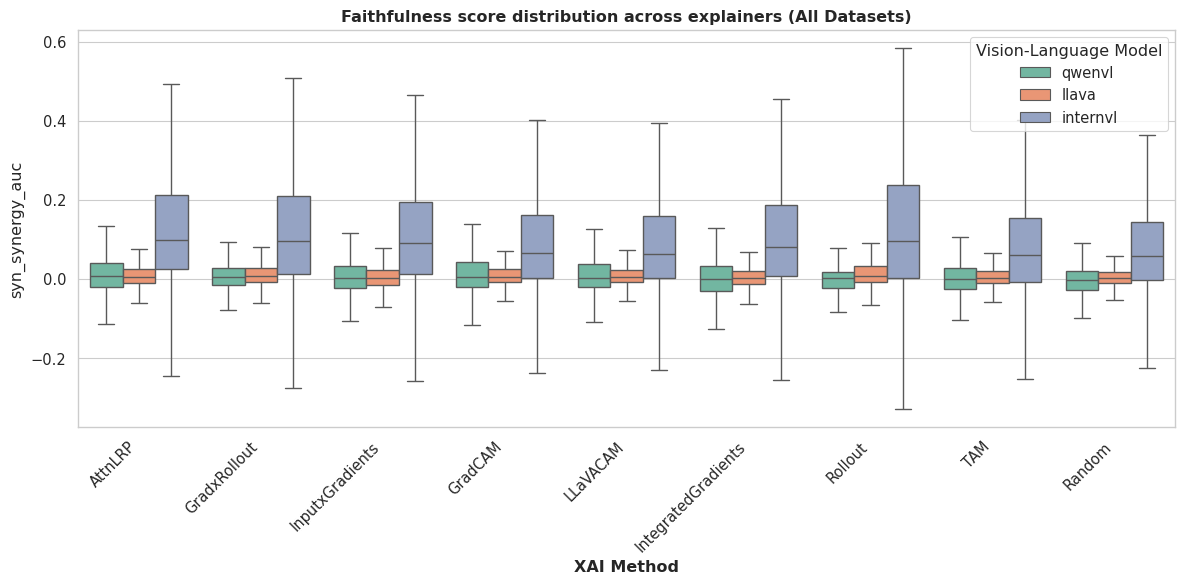

In [177]:
plot_macro_boxplot(df, metric='syn_synergy_auc', dataset_filter=None, savefig=True)

[*] Saved pareto_syn_synergy_norm_auc_global.pdf


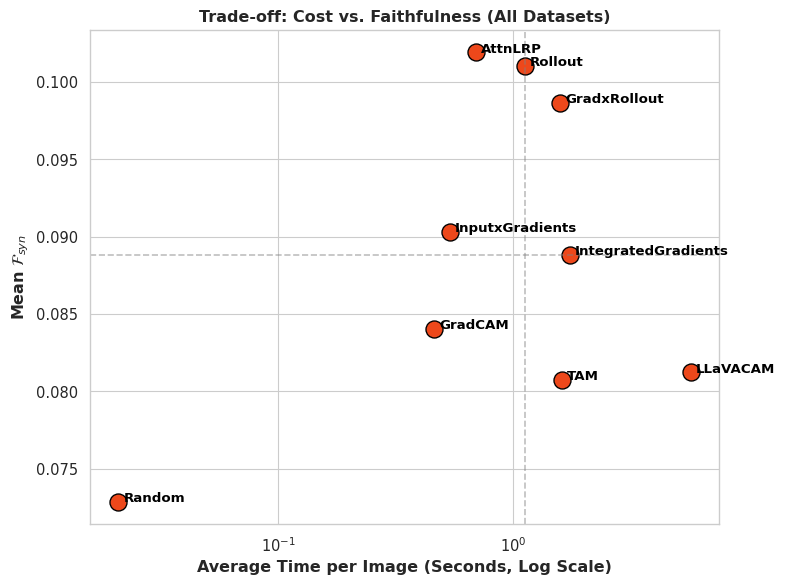

In [163]:
if 'xai_gen_time' in df.columns:
    plot_speed_vs_performance(df, perf_metric='syn_synergy_norm_auc', time_metric='xai_gen_time',
                              dataset_filter=None, savefig=True)


--- Generating Final Mean Rank Plot (Symbols Only) ---
[*] Saved ranks_syn_synergy_auc_global.pdf


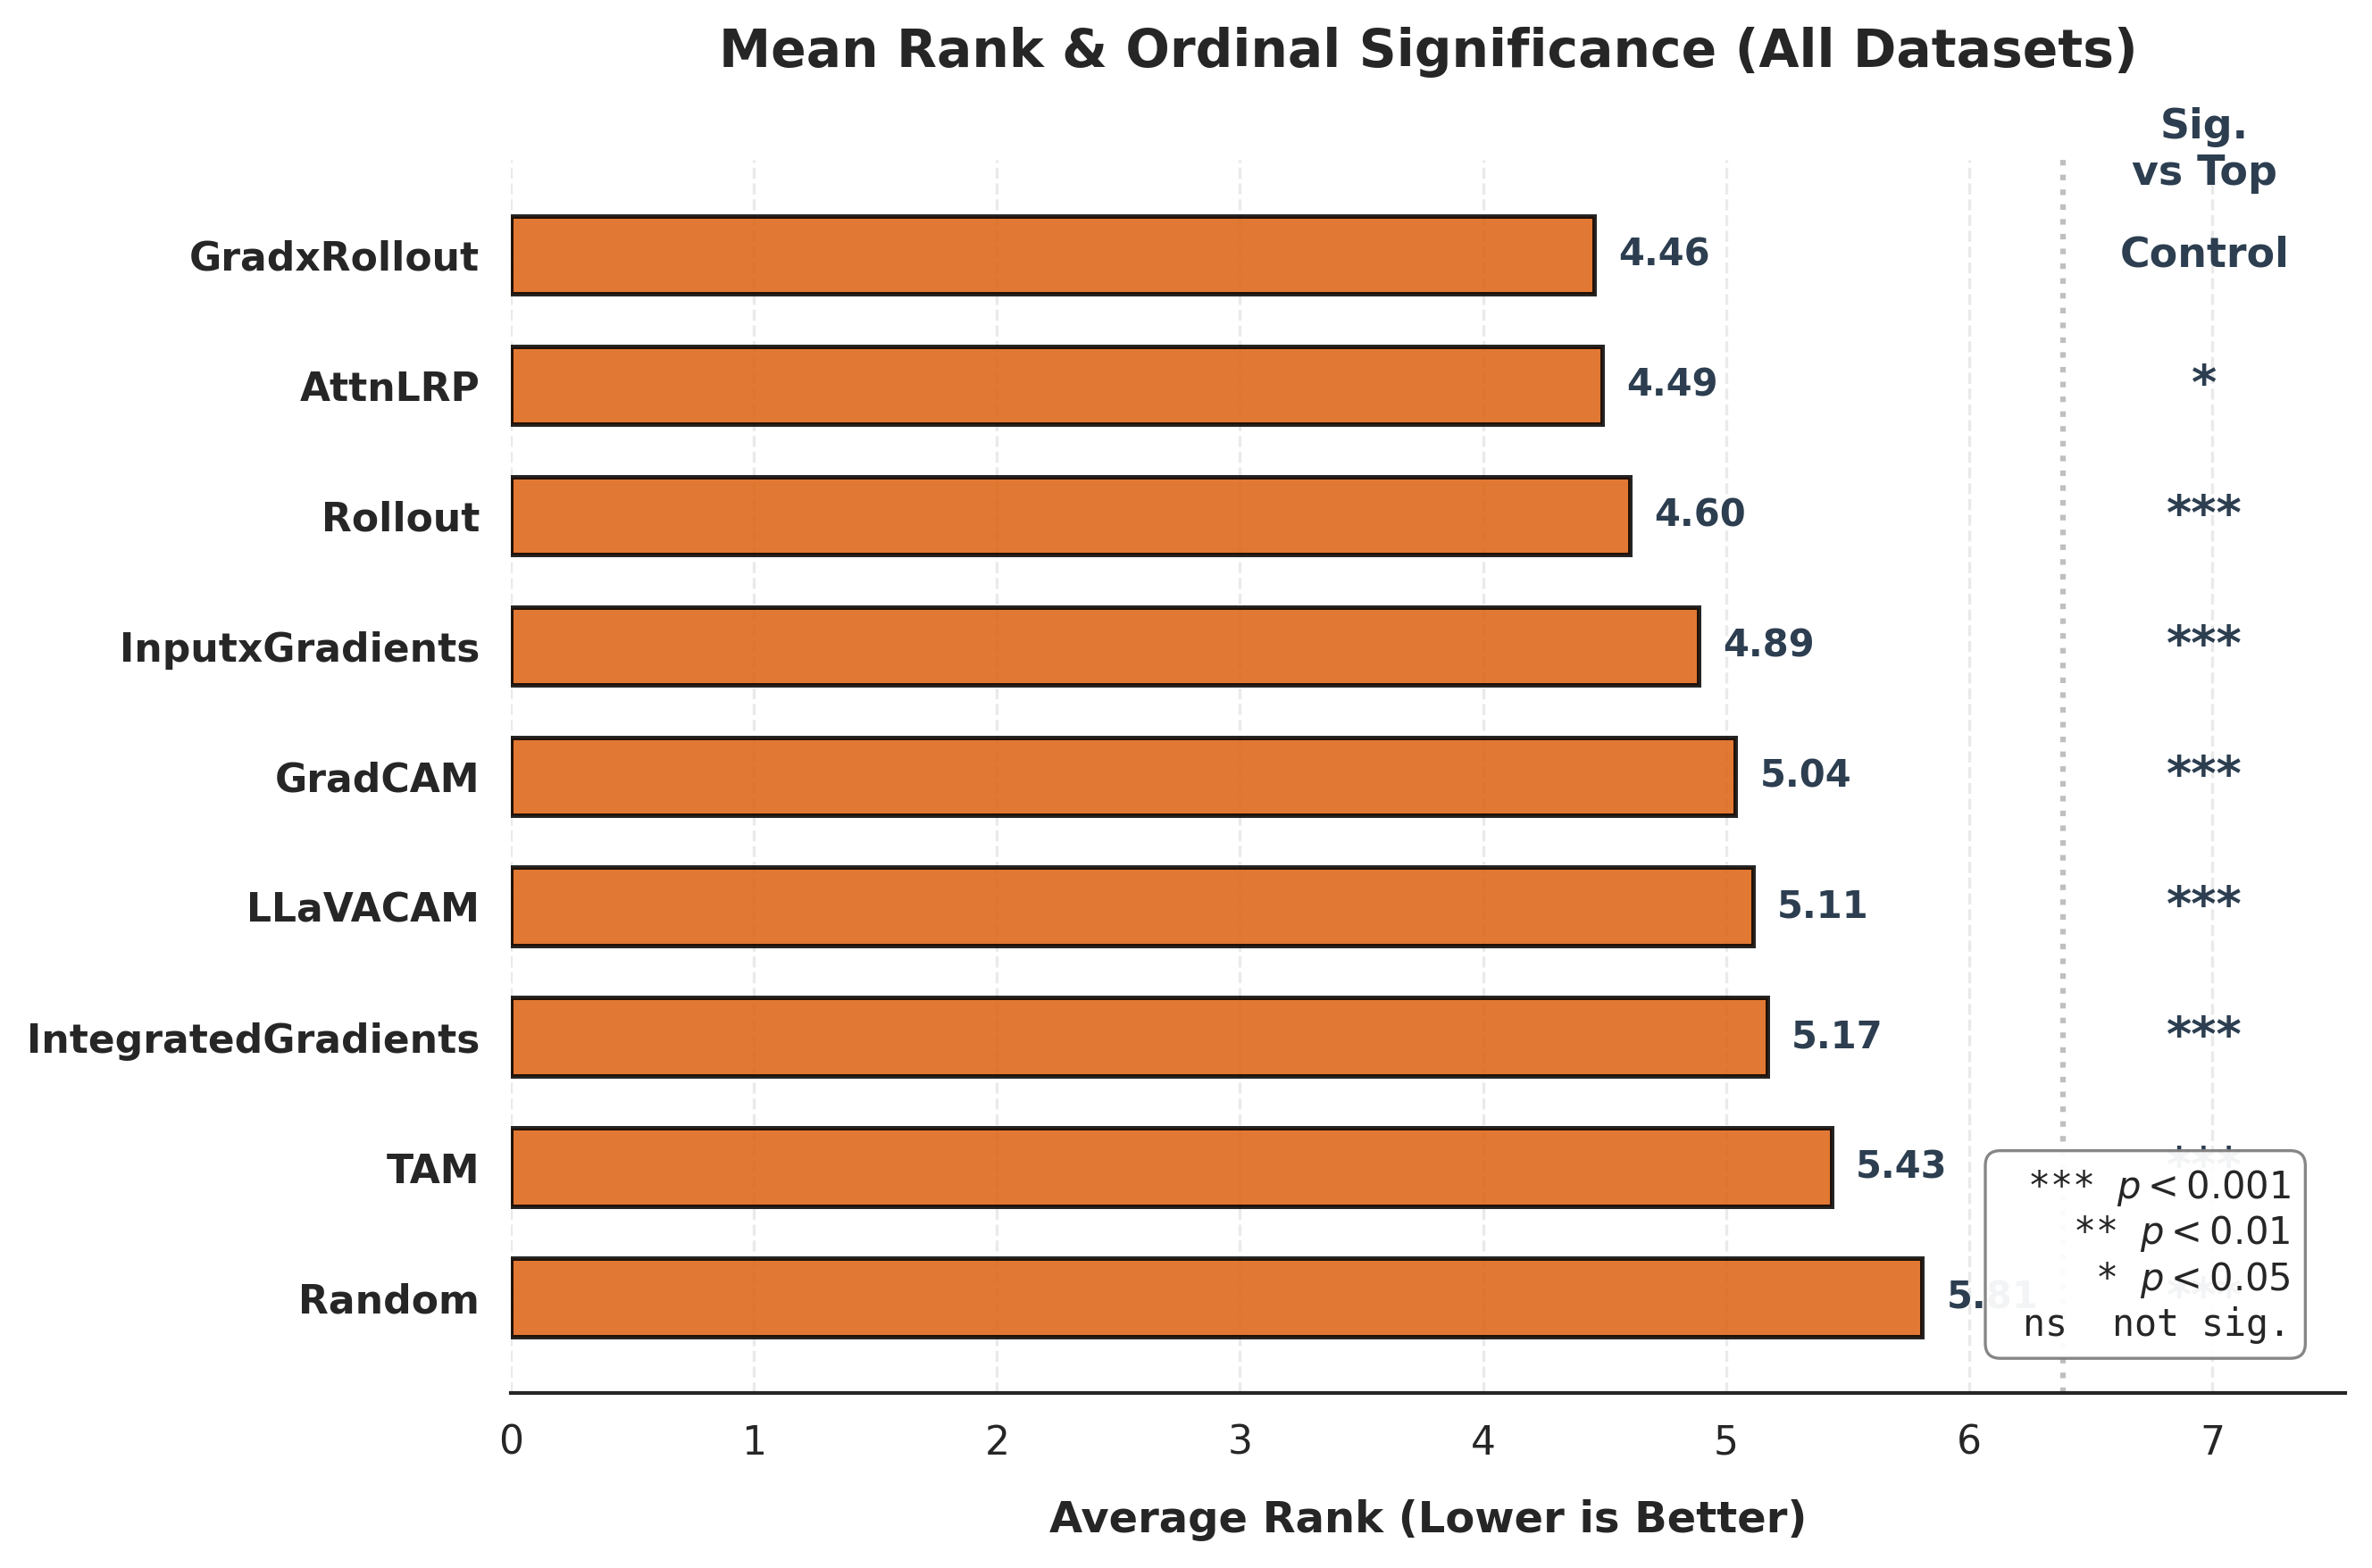

In [172]:
compute_and_plot_ranks(df, metric='syn_synergy_auc',
                        ascending_metric=False, dataset_filter=None,
                        savefig=True)


### Hallucination correlation

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr, mannwhitneyu
from sklearn.metrics import roc_auc_score
import json
import glob
from scipy import stats


def load_jsonl_data(pattern="*.jsonl"):
    """Loads all jsonl files matching the pattern into a single DataFrame."""
    all_data = []
    for file in glob.glob(pattern):
        with open(file, 'r') as f:
            for line in f:
                all_data.append(json.loads(line))
    return pd.DataFrame(all_data)



def analyze_long_format_explainers(df: pd.DataFrame, 
                                   explainer_col: str,
                                   syn_col: str, 
                                   pred_col: str, 
                                   true_col: str):
    """
    Takes a DataFrame with (n_samples * n_explainers) rows and compares them.
    """
    df = df.copy()

    # 1. SMART TEXT MATCHING: Define Hallucination
    # We check if the ground truth string (e.g., "no") is hidden inside the prediction string.
    def is_hallucinated(row):
        true_text = str(row[true_col]).strip().lower()
        pred_text = str(row[pred_col]).strip().lower()
        
        # If the true answer (e.g., 'no') is NOT in the model's sentence, it hallucinated/failed.
        if true_text not in pred_text:
            return 1 # Hallucination
        return 0     # Grounded/Correct

    df['is_hallucination'] = df.apply(is_hallucinated, axis=1)
    df['status'] = df['is_hallucination'].map({1: 'Hallucination', 0: 'Grounded'})
    
    results = []
    explainers = df[explainer_col].unique()
    
    # 2. Iterate through each explainer (e.g., 'IntegratedGradients')
    for exp in explainers:
        exp_df = df[df[explainer_col] == exp].copy()
        
        grounded = exp_df[exp_df['is_hallucination'] == 0][syn_col].dropna()
        hallucinated = exp_df[exp_df['is_hallucination'] == 1][syn_col].dropna()

        total_exp_samples = len(grounded) + len(hallucinated)
        if total_exp_samples == 0:
            continue
            
        hallucination_rate = (len(hallucinated) / total_exp_samples) * 100
        
        if len(grounded) < 2 or len(hallucinated) < 2:
            print(f"Skipping {exp}: Not enough data in both classes.")
            continue
            
        # Stats
        corr, p_corr = pointbiserialr(exp_df['is_hallucination'], exp_df[syn_col])
        stat, p_mw = mannwhitneyu(grounded, hallucinated, alternative='greater')
        
        # ROC-AUC (Inverted: we expect lower synergy for hallucinations)
        try:
            auc = roc_auc_score(exp_df['is_hallucination'], -exp_df[syn_col])
        except Exception:
            auc = np.nan
            
        results.append({
            'Explainer': exp,
            'ROC-AUC': auc,
            'Correlation': corr,
            'p-value (MW)': p_corr,
            'Hallucination Rate (%)': hallucination_rate,
            'Total Samples': total_exp_samples,
            'Grounded Mean': grounded.mean(),
            'Hallucinated Mean': hallucinated.mean()
        })
        
    summary_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
    
    # --- Print Summary ---
    print("="*80)
    print("🏆 EXPLAINER LEADERBOARD: HALLUCINATION DETECTION 🏆")
    print("="*80)
    print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
    print("="*80)

    # --- Plotting ---
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Boxplot automatically splits the long format by your explainer column!
    sns.boxplot(data=df, x=explainer_col, y=syn_col, hue='status', 
                ax=axes[0], palette=['#4C72B0', '#C44E52'])
    axes[0].set_title('Synergy Score Distributions per Explainer', fontsize=14)
    axes[0].set_ylabel('Synergy Score')
    axes[0].set_xlabel('Explainer Method')
    axes[0].tick_params(axis='x', rotation=45)

    # Bar chart for AUCs
    sns.barplot(data=summary_df, x='Explainer', y='ROC-AUC', 
                ax=axes[1], palette='viridis')
    axes[1].axhline(0.5, color='red', linestyle='--', label='Random Guessing (0.5)')
    axes[1].set_title('ROC-AUC: Ability to Detect Hallucinations', fontsize=14)
    axes[1].set_ylabel('AUC Score')
    axes[1].set_xlabel('Explainer Method')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    return summary_df




In [ ]:
def load_process(json_file_path):
    df = load_jsonl_data(json_file_path)

    df["img_norm_srg"] = df["img_norm_auc_ins"] - df["img_norm_auc_del"]
    df["tok_norm_srg"] = df["tok_norm_auc_ins"] - df["tok_norm_auc_del"]
    df["syn_srg"] = (df["syn_ins_norm_auc"] + df["syn_del_norm_auc"]) / 2

    df["img_srg"] = df["img_auc_ins"] - df["img_auc_del"]
    df["tok_srg"] = df["tok_auc_ins"] - df["tok_auc_del"]
    df["syn_srg_unorm"] = (df["syn_ins_auc"] + df["syn_del_auc"]) / 2

    df = df[df["label"] == "no"]
    df = df.dropna()
    return df



In [ ]:
# 1. Load Data
internvl_path = "../logs/results/internvl/repope/internvl*results.jsonl"
llava_path = "../logs/results/llava/repope/llava*results.jsonl"
qwenvl_path = "../logs/results/qwenvl/repope/qwenvl*results.jsonl"
df_internvl = load_process(internvl_path)
df_llava = load_process(llava_path)
df_qwenvl = load_process(qwenvl_path)

In [ ]:
df_llava["label"]

In [ ]:
leaderboard = analyze_long_format_explainers(df_internvl,
                                             explainer_col='explainer',
                                             syn_col='syn_srg_unorm',
                                             true_col="label",
                                             pred_col="prediction")

In [ ]:
leaderboard = analyze_long_format_explainers(df_llava,
                                             explainer_col='explainer',
                                             syn_col='syn_srg',
                                             true_col="label",
                                             pred_col="prediction")

In [ ]:
leaderboard = analyze_long_format_explainers(df_qwenvl,
                                             explainer_col='explainer',
                                             syn_col='syn_srg',
                                             true_col="label",
                                             pred_col="prediction")

### Captum

In [ ]:
from src.explainers import CaptumExplainer, RandomExplainer

# captum_xai = CaptumExplainer(model_wrapper,
#                              xai_name="inputxgradient")

random_xai = RandomExplainer(model_wrapper=model_wrapper)

In [ ]:
from src.datasets import COCOGroundingDataset
from torch.utils.data import DataLoader

data_path = "../datasets/coco"
dataset = COCOGroundingDataset(data_path=data_path)

def collate_fn_custom(batch):
    # Standard collate fails on Dictionaries (category_masks) and Lists (all_captions)
    # So we write a simple one that just returns the list of items
    return batch[0] # Assumes batch_size=1

dl = DataLoader(dataset, collate_fn=collate_fn_custom)


In [ ]:
import time
from src.utils.plausibility_utils import OntologyMapper, ids_to_word_groups, pool_heatmaps
from src.metrics.plausibility import point_game, energy_point_game

category = dataset.id2name
mapper = OntologyMapper(coco_categories=category, threshold=0.5)

for sample in dl:
    img = sample["image"]
    q = "Write a one sentence caption"
    captions = sample["captions"]
    masks = sample["category_masks"]

    inputs = model_wrapper.get_inputs(img, q)
    _, h, w = inputs["image_grid_thw"][0].cpu().numpy().tolist()

    pred_results = model_wrapper.predict(inputs,
                                     return_logits=False)
    


    tokens = pred_results["new_ids"].cpu().unsqueeze(0).numpy().tolist()
    words, tokens_id = ids_to_word_groups(tokens,
                                          model_wrapper.processor)
    

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    start_time = time.time()
    text_attrs, img_attrs = explainer.attribute(img,
                                            text=q,
                                            target_indices=[],
                                            pred_results=pred_results)
    torch.cuda.synchronize()
    exec_time = time.time() - start_time
    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 2) # Convert to MB

    print(f" Time: {exec_time:.2f} s, GPU usage: {peak_vram:.2f}MB")
        

    pg_scores = []
    energy_pg_scores = []
    for i, word in enumerate(words):
        cat_id = mapper.map_word(word)
        if cat_id is None:
            continue

        cat_name = category[cat_id]

        if cat_name not in masks:
            print(f"Word: '{word:10}' | Mapped: '{cat_name:10}' | Result: Hallucinated (Not in image)")
            continue

        # Resize heatmap to match ground truth mask dimensions
        gt_mask = masks[cat_name].numpy()
        h_gt, w_gt = gt_mask.shape

        # Pool the image attributions for this specific word
        img_attr = pool_heatmaps(img_attrs, tokens_id[i], method='max')
        
        heatmap_raw = img_attr.unsqueeze(0).unsqueeze(0) # (1, 1, H, W)
        heatmap_resized = torch.nn.functional.interpolate(
            heatmap_raw, size=(h_gt, w_gt), mode='bilinear', align_corners=False
        ).squeeze().cpu().numpy()
        pg_score = point_game(gt_mask, heatmap_resized)
        energy_score = energy_point_game(gt_mask, heatmap_resized)

        pg_scores.append(pg_score)
        energy_pg_scores.append(energy_score)

        print(f"Word: '{word:10}' | Mapped: '{cat_name:10}'")

        
    break


In [ ]:
img_pad_id = model_wrapper.processor.tokenizer.convert_tokens_to_ids("<|image_pad|>")
img_start_id = model_wrapper.processor.tokenizer.convert_tokens_to_ids("<|vision_start|>")
img_end_id = model_wrapper.processor.tokenizer.convert_tokens_to_ids("<|vision_end|>")
# Also maybe the start of text token if you want to preserve it
im_start_id = model_wrapper.processor.tokenizer.convert_tokens_to_ids("<|im_start|>")
im_end_id = model_wrapper.processor.tokenizer.convert_tokens_to_ids("<|im_end|>")

special_token_ids = [img_start_id, img_pad_id, img_end_id, im_start_id, im_end_id]